# Company A | Retain contribution, not just customers
## Original consulting proof of concept
**Omnicampus account:** philopateer  
**Data:** supplied Client.csv and Record.csv only.  
**Execution:** local Windows / Python 3.11 / CPU, six worker threads; no cloud runtime.

### Executive question
Can Company A use customer behavior to allocate a limited service-recovery budget more profitably than a generic highest-churn-risk campaign?

The business lever is **low-cost, customer-consented service recovery**, prioritized by recurring contribution at risk. A model selects whom to investigate; it does not prove that an offer prevents churn. Blanket discounts and automatic handset subsidies are not recommended. Cross-sell, credit decisions, and guaranteed uplift are deliberately outside the evidence this dataset can support.

### Read this distinction first
1. **Observed:** data quality, descriptive segments, held-out predictive scores, and retrospective value capture in this supplied sample.
2. **Assumed:** deployment churn prevalence, currency, contribution margin, retained months, intervention cost, and treatment effectiveness.
3. **To be measured:** causal retention lift, real cost, realized incremental contribution, complaint/opt-out rates, and current-population calibration.

The churn label concerns **days 31–60 after observation**, not a documented cumulative 60-day churn rate. The nearly balanced sample is not an estimate of Company A's actual churn rate. Geography suggests a US scenario, but the company, currency, sample selection, and observation dates are unverified. Historical handset and voice-service variables limit transfer to modern networks.

### Reproduce locally
Place this notebook in the folder containing `telecom/Client.csv` and `telecom/Record.csv`. Use the shared Python 3.11 environment. Package versions are printed below and recorded in `analysis_outputs/environment.json`; exact dependencies are supplied separately. Run all cells in order. All analysis code is embedded here; `analysis_pipeline.py` is a convenience copy, not a notebook dependency. Charts, numerical tables, model artifacts, and test predictions are written under `analysis_outputs/`. Joblib models must only be loaded from trusted sources.

### Contents
1. Environment and integrity; 2. Original EDA; 3. Operational features; 4. Model comparison and calibration; 5. Locked test; 6. Interpretation and robustness; 7. Conditional financial scenarios; 8. Randomized pilot.


## 1. Local environment
The seed and thread budget are fixed. The models run on the CPU; no GPU, remote notebook, telemetry integration, or external dataset is required. Library versions and raw-input fingerprints make this run auditable.

In [1]:
from pathlib import Path
from hashlib import sha256
import importlib.metadata
import json
import os
import platform
import time
import warnings

os.environ['OMP_NUM_THREADS'] = '6'
os.environ['MKL_NUM_THREADS'] = '6'

import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image as DisplayImage
from scipy.special import expit, logit
from scipy.stats import norm
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 20261028
THREADS = 6
ROOT = Path.cwd()
OUT = ROOT / 'analysis_outputs'
for folder in ['charts', 'tables', 'models']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
START = time.perf_counter()
COLORS = {'ink': '#132D3A', 'teal': '#007F82', 'amber': '#C87E26', 'muted': '#73838B', 'light': '#EDF3F3'}
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.labelcolor': COLORS['ink'],
                     'text.color': COLORS['ink'], 'text.parse_math': False, 'axes.titleweight': 'bold'})


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


def save_json(name, value):
    (OUT / name).write_text(json.dumps(json_safe(value), indent=2, allow_nan=False), encoding='utf-8')


def table(name, frame):
    frame.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
    display(frame)


def figure(name):
    plt.tight_layout()
    path = OUT / 'charts' / f'{name}.png'
    plt.savefig(path, bbox_inches='tight', facecolor='white')
    display(DisplayImage(filename=str(path)))
    plt.close()


versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn',
            'lightgbm', 'xgboost', 'catboost', 'matplotlib', 'seaborn', 'joblib']}
save_json('environment.json', {'python': platform.python_version(), 'platform': platform.platform(),
          'packages': versions, 'seed': SEED, 'threads': THREADS})
print('Local CPU execution:', platform.python_version(), '| threads:', THREADS)
print('Input directory:', ROOT)
display(pd.Series(versions, name='version').to_frame())

Local CPU execution: 3.11.9 | threads: 6
Input directory: D:\progs\IDE\MainProjs\AI\GCI2026\finalA


,version
numpy,2.3.3
pandas,3.0.6
scipy,1.17.1
scikit-learn,1.9.1
lightgbm,4.7.0
xgboost,3.2.0
catboost,1.2.10
matplotlib,3.10.9
seaborn,0.13.2
joblib,1.6.0


## 2. Integrity and evaluation design
A validated one-to-one join prevents accidental customer multiplication. IDs, full duplicate predictor rows, label completeness, and matched customers are checked before analysis.

The fixed split is **60,000 training / 15,000 model-selection validation / 10,000 probability-calibration and policy-development / 15,000 final test** customers. Target-stratified random splits preserve the supplied sample balance. Model fitting and selection never use the test partition. After validation-only selection, the chosen model is refitted on training plus validation (75,000); its probabilities are calibrated on the separate 10,000. All transformations that learn distributions use training data only. Initial whole-dataset integrity summaries are not temporal validation.

No actual observation timestamps or household IDs are supplied, so future-period validation and household-disjoint splits cannot be claimed. ID-order and subgroup checks below are sensitivity diagnostics, not substitutes.

In [2]:
client_path = ROOT / 'telecom' / 'Client.csv'
record_path = ROOT / 'telecom' / 'Record.csv'
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)
assert client.Customer_ID.is_unique and record.Customer_ID.is_unique
assert not client.Customer_ID.isna().any() and not record.Customer_ID.isna().any()
assert set(client.Customer_ID) == set(record.Customer_ID)
data = record.merge(client, on='Customer_ID', how='inner', validate='one_to_one')
assert data.shape == (100000, 100)
assert set(data.churn.unique()) == {0, 1} and data.churn.notna().all()
assert not data.drop(columns=['Customer_ID', 'churn']).duplicated().any()
source_hashes = {str(p.relative_to(ROOT)): sha256(p.read_bytes()).hexdigest() for p in [client_path, record_path]}
y = data.churn.astype('int8')
indices = np.arange(len(data))
train_idx, remainder = train_test_split(indices, train_size=60000, stratify=y, random_state=SEED)
valid_idx, remainder = train_test_split(remainder, train_size=15000, stratify=y.iloc[remainder], random_state=SEED + 1)
cal_idx, test_idx = train_test_split(remainder, train_size=10000, stratify=y.iloc[remainder], random_state=SEED + 2)
partitions = {'train': train_idx, 'validation': valid_idx, 'calibration_policy': cal_idx, 'test': test_idx}
assert len(set.union(*(set(v) for v in partitions.values()))) == len(data)
assert sum(len(v) for v in partitions.values()) == len(data)
split_table = pd.DataFrame([{'partition': k, 'customers': len(v), 'sample_churn_rate': float(y.iloc[v].mean())}
                           for k, v in partitions.items()])
table('data_partitions', split_table)
partition_labels = pd.Series(index=data.index, dtype='str')
for name, idx in partitions.items():
    partition_labels.loc[idx] = name
pd.DataFrame({'Customer_ID': data.Customer_ID, 'partition': partition_labels}).to_csv(OUT / 'tables' / 'split_manifest.csv', index=False)
audit = {'rows': len(data), 'columns': len(data.columns), 'sample_churn_rate': float(y.mean()),
         'merged_memory_mib': float(data.memory_usage(deep=True).sum() / 1024**2),
         'id_join': 'one-to-one; no unmatched customers', 'duplicate_predictor_rows': 0,
         'negative_equipment_age': int((data.eqpdays < 0).sum()),
         'negative_recurring_charge': int((data.totmrc_Mean < 0).sum()),
         'missing_recurring_charge': int(data.totmrc_Mean.isna().sum()),
         'source_sha256': source_hashes}
save_json('audit.json', audit)
print(json.dumps(audit, indent=2))

,partition,customers,sample_churn_rate
0,train,60000,0.495617
1,validation,15000,0.495600
2,calibration_policy,10000,0.495600
3,test,15000,0.495667


{
  "rows": 100000,
  "columns": 100,
  "sample_churn_rate": 0.49562,
  "merged_memory_mib": 80.14993095397949,
  "id_join": "one-to-one; no unmatched customers",
  "duplicate_predictor_rows": 0,
  "negative_equipment_age": 133,
  "negative_recurring_charge": 23,
  "missing_recurring_charge": 357,
  "source_sha256": {
    "telecom\\Client.csv": "264a58512dc857fff29e11ef43fd53bc4407be23aac9dcc2c0df23536c800778",
    "telecom\\Record.csv": "5bd563bb77b357920832510b78d6842060d928cb5de8c0aaf79aa2a647e2271a"
  }
}


## 3. Original EDA: find a business decision, not just a correlation
Business segments are calculated on the 60,000-customer training partition. Missingness and ID-order audits describe all supplied rows.

The central hypothesis is a **risk–value trade-off**: an older handset can coincide with greater churn risk but lower recurring charges. A risk-only list may consequently spend scarce contact capacity on less recurring value. Check the data below rather than assuming that replacing devices causes retention.

Usage decline and overage exposure are diagnostic signals, not proven causes. Customer-care contacts are especially easy to misinterpret: contact can indicate both dissatisfaction and successful service. The dataset dictionary describes change fields as percentages, but their scales and units are ambiguous; this analysis does not describe their raw values as percentage-point changes. Negative billing values may be adjustments, whereas negative handset age is treated as an invalid age.

,feature,missing_fraction
0,numbcars,0.49366
1,dwllsize,0.38308
2,HHstatin,0.37923
3,ownrent,0.33706
4,dwlltype,0.31909
5,lor,0.30190
6,income,0.25436
7,adults,0.23019
8,infobase,0.22079
9,hnd_webcap,0.10189


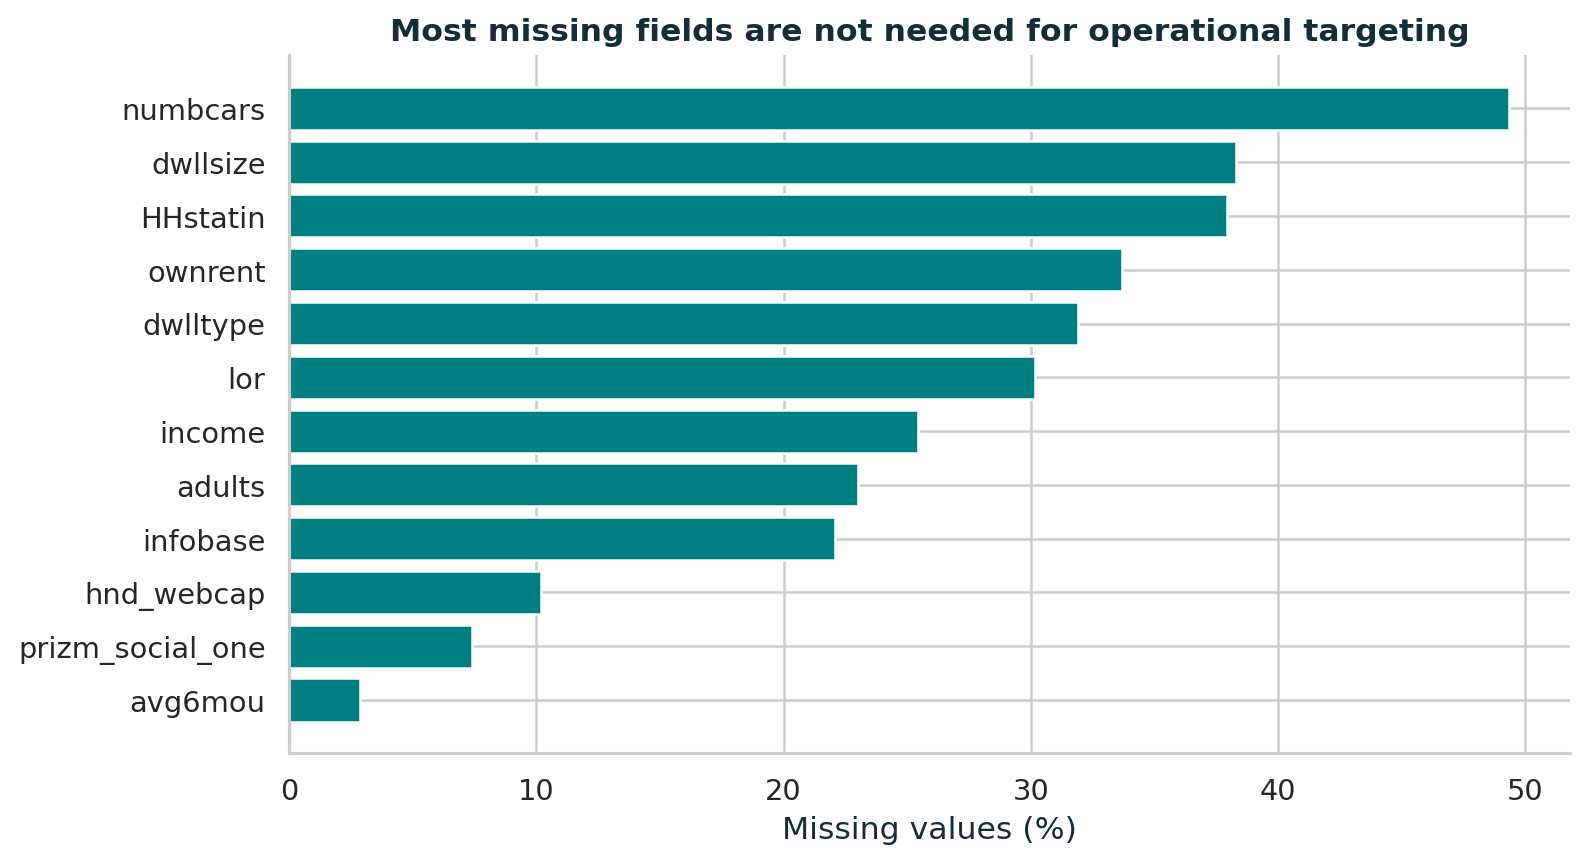

,handset_age,customers,churn_rate,monthly_recurring,monthly_revenue,churn_ci95
0,0–180 days,10958,0.418963,54.494951,79.076415,0.009238
1,181–365 days,21765,0.472318,48.540495,59.411496,0.006633
2,366–730 days,20710,0.537228,42.398365,52.158637,0.006791
3,>730 days,6486,0.572464,35.571309,42.967112,0.012040


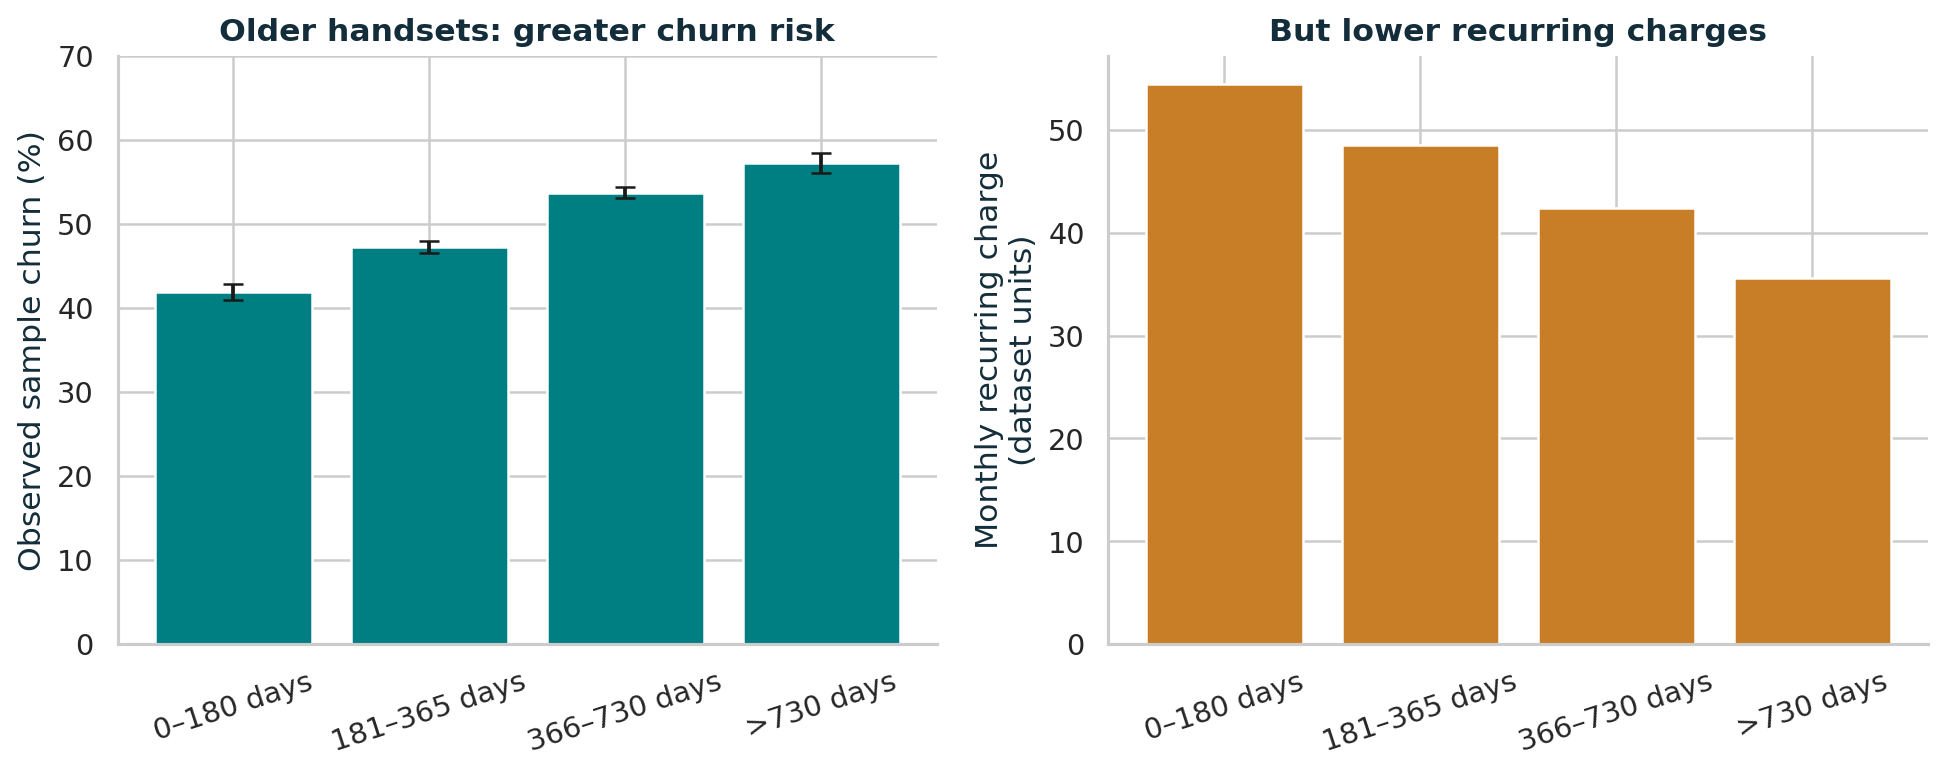

,dimension,segment,customers,churn_rate,monthly_recurring
0,usage_change,Below −100,13535,0.536683,53.195084
1,usage_change,−100 to 0,19699,0.507538,40.172649
2,usage_change,0 to 100,14737,0.453552,42.127614
3,usage_change,Above 100,11492,0.468152,53.742530
4,overage_revenue,None,25474,0.488223,44.111414
5,overage_revenue,0–5,11148,0.475780,43.538398
6,overage_revenue,5–20,11147,0.502916,45.739913
7,overage_revenue,20–100,10756,0.516642,52.210389
8,overage_revenue,>100,1262,0.547544,61.559284
9,customer_care_calls,None,33381,0.517480,41.636236


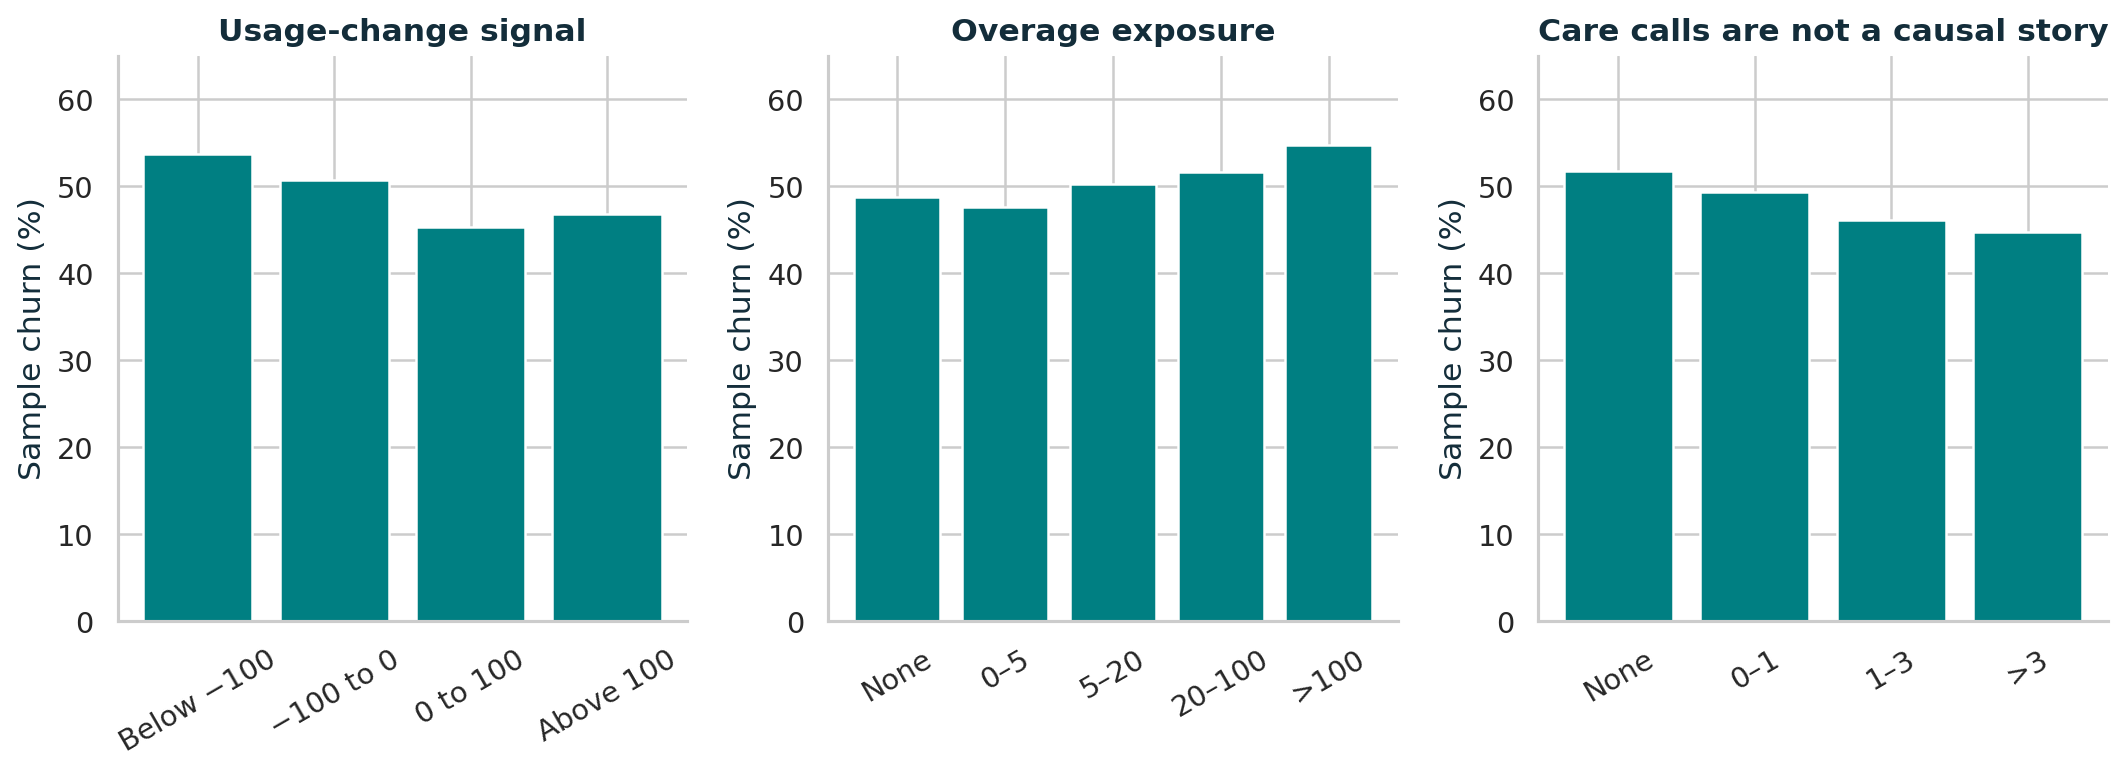

,Customer_ID,customers,churn_rate,mean_tenure
0,"(1000000.999, 1010000.9]",10000,0.4925,37.7679
1,"(1010000.9, 1020000.8]",10000,0.5170,27.6740
2,"(1020000.8, 1030000.7]",10000,0.4911,23.0599
3,"(1030000.7, 1040000.6]",10000,0.5030,20.5084
4,"(1040000.6, 1050000.5]",10000,0.5248,17.1115
5,"(1050000.5, 1060000.4]",10000,0.5511,14.1918
6,"(1060000.4, 1070000.3]",10000,0.5367,12.4367
7,"(1070000.3, 1080000.2]",10000,0.5078,10.7762
8,"(1080000.2, 1090000.1]",10000,0.4560,9.8483
9,"(1090000.1, 1100000.0]",10000,0.3762,14.9652


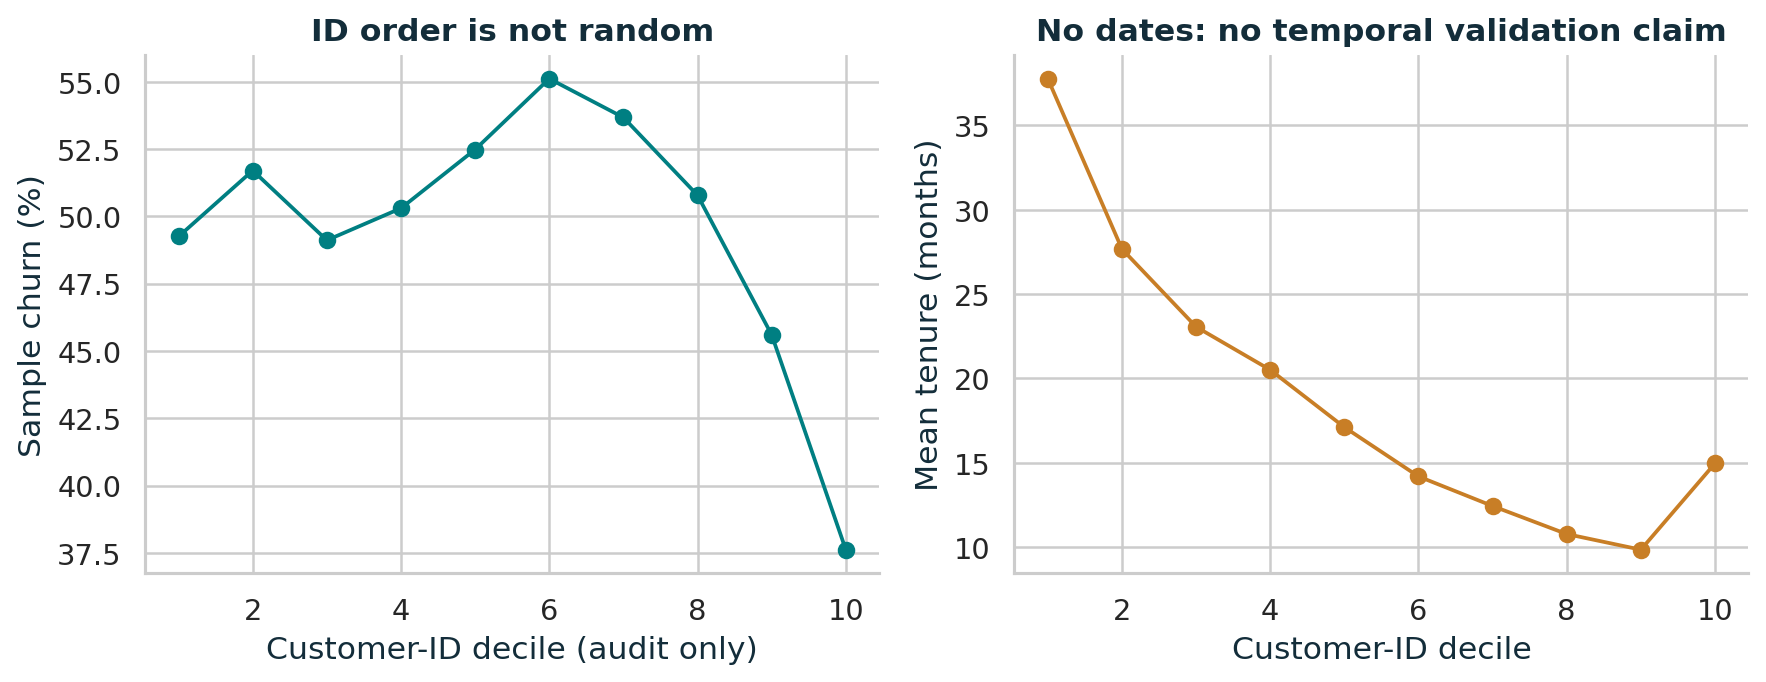

In [3]:
eda = data.loc[train_idx].copy()
missing = data.isna().mean().sort_values(ascending=False).rename('missing_fraction').rename_axis('feature').reset_index()
table('missingness', missing.head(15))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(missing.feature.head(12)[::-1], missing.missing_fraction.head(12)[::-1] * 100, color=COLORS['teal'])
ax.set(xlabel='Missing values (%)', title='Most missing fields are not needed for operational targeting')
figure('missingness')

age_bins = pd.cut(eda.eqpdays.where(eda.eqpdays >= 0), [-0.1, 180, 365, 730, np.inf],
                  labels=['0–180 days', '181–365 days', '366–730 days', '>730 days'])
age = eda.groupby(age_bins, observed=True).agg(customers=('churn', 'size'), churn_rate=('churn', 'mean'),
                                               monthly_recurring=('totmrc_Mean', 'mean'), monthly_revenue=('rev_Mean', 'mean')).reset_index(names='handset_age')
age['churn_ci95'] = 1.96 * np.sqrt(age.churn_rate * (1 - age.churn_rate) / age.customers)
table('equipment_age_segments', age)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(age.handset_age, age.churn_rate * 100, yerr=age.churn_ci95 * 100, capsize=4, color=COLORS['teal'])
axes[0].set(ylabel='Observed sample churn (%)', ylim=(0, 70), title='Older handsets: greater churn risk')
axes[1].bar(age.handset_age, age.monthly_recurring, color=COLORS['amber'])
axes[1].set(ylabel='Monthly recurring charge\n(dataset units)', title='But lower recurring charges')
for ax in axes:
    ax.tick_params(axis='x', rotation=18)
figure('risk_value_tradeoff')

segment_specs = {
    'usage_change': pd.cut(eda.change_mou, [-np.inf, -100, 0, 100, np.inf], labels=['Below −100', '−100 to 0', '0 to 100', 'Above 100']),
    'overage_revenue': pd.cut(eda.ovrrev_Mean, [-1, 0, 5, 20, 100, np.inf], labels=['None', '0–5', '5–20', '20–100', '>100']),
    'customer_care_calls': pd.cut(eda.custcare_Mean, [-1, 0, 1, 3, np.inf], labels=['None', '0–1', '1–3', '>3']),
    'tenure': pd.cut(eda.months, [0, 12, 24, 36, 100], labels=['6–12 months', '13–24 months', '25–36 months', '>36 months'])}
segment_frames = []
for name, groups in segment_specs.items():
    frame = eda.groupby(groups, observed=True).agg(customers=('churn', 'size'), churn_rate=('churn', 'mean'),
              monthly_recurring=('totmrc_Mean', 'mean')).reset_index(names='segment')
    frame.insert(0, 'dimension', name)
    segment_frames.append(frame)
segments = pd.concat(segment_frames, ignore_index=True)
table('operational_segments', segments)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, name, title in zip(axes, ['usage_change', 'overage_revenue', 'customer_care_calls'],
                         ['Usage-change signal', 'Overage exposure', 'Care calls are not a causal story']):
    f = segments.loc[segments.dimension == name]
    ax.bar(f.segment.astype(str), f.churn_rate * 100, color=COLORS['teal'])
    ax.set(title=title, ylabel='Sample churn (%)', ylim=(0, 65))
    ax.tick_params(axis='x', rotation=30)
figure('operational_signals')

id_segments = data.groupby(pd.qcut(data.Customer_ID, 10), observed=True).agg(customers=('churn', 'size'),
              churn_rate=('churn', 'mean'), mean_tenure=('months', 'mean')).reset_index()
id_segments.Customer_ID = id_segments.Customer_ID.astype(str)
table('id_order_audit', id_segments)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(np.arange(1, 11), id_segments.churn_rate * 100, marker='o', color=COLORS['teal'])
axes[0].set(xlabel='Customer-ID decile (audit only)', ylabel='Sample churn (%)', title='ID order is not random')
axes[1].plot(np.arange(1, 11), id_segments.mean_tenure, marker='o', color=COLORS['amber'])
axes[1].set(xlabel='Customer-ID decile', ylabel='Mean tenure (months)', title='No dates: no temporal validation claim')
figure('sampling_audit')

## 4. Use actionable operational information; minimize sensitive data
The model excludes customer ID, geography, demographic attributes, inferred wealth, credit classifications, and third-party household descriptors. These fields are not necessary to make a service-recovery decision, and many are sparsely populated. Exclusion reduces direct reliance on sensitive proxies; it does **not** establish fairness because operational features can still correlate with protected attributes.

Derived features summarize recent-versus-historical usage and charges, overage exposure, service-quality indices, and equipment age relative to tenure. Ratios are diagnostic features, not causal effects. Categorical vocabularies, imputation, scaling, and the monetary cap are learned on training data, not the test set. CatBoost uses an explicit missing sentinel for numeric input; other tree models handle numeric missingness natively.

**Conservative value proxy:** current recurring charge, floored at zero, missing values replaced by the training median, and extreme values capped at the training 99th percentile. We do not reward punitive overage windfalls, model unobserved cross-sell, or call this customer lifetime value. Currency is unspecified in the source; dollar projections later are explicit USD-equivalent scenarios.

In [4]:
excluded = ['Customer_ID', 'churn', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'truck', 'rv',
            'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin',
            'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']
X = data.drop(columns=excluded).copy()
X['equipment_age_invalid'] = (X.eqpdays < 0).astype('int8')
X['eqpdays'] = X.eqpdays.where(X.eqpdays >= 0)
X['usage_recent_to_lifetime'] = X.avg3mou / X.avgmou.clip(lower=1)
X['usage_three_to_six_months'] = X.avg3mou / X.avg6mou.clip(lower=1)
X['revenue_recent_to_lifetime'] = X.avg3rev / X.avgrev.clip(lower=1)
X['revenue_three_to_six_months'] = X.avg3rev / X.avg6rev.clip(lower=1)
X['overage_charge_share'] = X.ovrrev_Mean / X.rev_Mean.clip(lower=1)
X['recurring_charge_share'] = X.totmrc_Mean / X.rev_Mean.clip(lower=1)
X['failed_call_index'] = X.drop_blk_Mean / X.attempt_Mean.clip(lower=1)
X['care_calls_per_100_attempts'] = 100 * X.custcare_Mean / X.attempt_Mean.clip(lower=1)
X['equipment_age_to_tenure'] = X.eqpdays / (30.4375 * X.months.clip(lower=1))
X['inactive_household_lines'] = (X.uniqsubs - X.actvsubs).clip(lower=0)
X['usage_change_scaled'] = X.change_mou / X.avg3mou.clip(lower=1)
X['revenue_change_scaled'] = X.change_rev / X.avg3rev.clip(lower=1)
cat_cols = X.select_dtypes(include=['object', 'str', 'string', 'category']).columns.tolist()
num_cols = [c for c in X if c not in cat_cols]
for c in cat_cols:
    X[c] = X[c].fillna('__MISSING__').astype(str)
X[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan).astype('float32')
assert not set(excluded).intersection(X.columns)
X_native = X.copy()
for c in cat_cols:
    categories = sorted(X.loc[train_idx, c].unique())
    X_native[c] = pd.Categorical(X[c], categories=categories)
X_cat = X.copy()
X_cat[num_cols] = X_cat[num_cols].fillna(-999.0)
recurring_median = float(data.loc[train_idx, 'totmrc_Mean'].clip(lower=0).median())
recurring_cap = float(data.loc[train_idx, 'totmrc_Mean'].clip(lower=0).quantile(0.99))
monthly_value = data.totmrc_Mean.clip(lower=0).fillna(recurring_median).clip(upper=recurring_cap).to_numpy()
assert np.isfinite(monthly_value).all() and (monthly_value >= 0).all()
save_json('feature_manifest.json', {'features': X.columns.tolist(), 'categorical_features': cat_cols,
          'excluded_features': excluded, 'monthly_value_training_median': recurring_median,
          'monthly_value_training_p99_cap': recurring_cap, 'feature_count': len(X.columns)})
print(f'{len(X.columns)} operational features; {len(cat_cols)} categorical. Demographics, credit codes, area and ID excluded.')
print(f'Value proxy: nonnegative recurring charge; train median imputation {recurring_median:.2f}; train p99 cap {recurring_cap:.2f}.')

87 operational features; 4 categorical. Demographics, credit codes, area and ID excluded.
Value proxy: nonnegative recurring charge; train median imputation 44.99; train p99 cap 115.52.


## 5. Compare alternatives, then calibrate
- **Logistic regression:** interpretable linear baseline with training-fitted preprocessing.
- **LightGBM, two predeclared capacities:** efficient nonlinear tabular models.
- **XGBoost:** independent boosted-tree implementation with categorical support.
- **CatBoost:** nonlinear model designed for mixed categorical/numeric inputs.

All comparisons use the same development split. Tree early stopping uses validation only. Highest validation ROC-AUC selects the classifier because the task first needs reliable risk ordering; no test metric or scenario profit is used for model selection. Commercial ranking is assessed separately. A sigmoid calibrator fitted to model log-odds uses the 10,000-customer calibration/policy partition. Neither calibration nor a high AUC converts risk into treatment benefit. Method references: [M1] scikit-learn; [M2] LightGBM; [M3] XGBoost; [M4] CatBoost; commercial decision rationale [S5–S6].

In [5]:
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
preprocess = ColumnTransformer([('numeric', numeric_pipeline, num_cols),
               ('category', OneHotEncoder(handle_unknown='ignore', min_frequency=25, sparse_output=False), cat_cols)])
logistic = Pipeline([('preprocess', preprocess), ('model', LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))])
model_specs = [
    ('Logistic regression', logistic, X),
    ('LightGBM small leaves', LGBMClassifier(n_estimators=1600, learning_rate=0.035, num_leaves=15,
         min_child_samples=150, reg_lambda=8, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),
    ('LightGBM wider leaves', LGBMClassifier(n_estimators=1600, learning_rate=0.03, num_leaves=31,
         min_child_samples=100, reg_lambda=12, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),
    ('XGBoost', XGBClassifier(n_estimators=1400, learning_rate=0.04, max_depth=5, min_child_weight=20,
         reg_lambda=12, subsample=0.85, colsample_bytree=0.85, tree_method='hist', enable_categorical=True,
         eval_metric='auc', early_stopping_rounds=75, n_jobs=THREADS, random_state=SEED), X_native),
    ('CatBoost', CatBoostClassifier(iterations=1400, learning_rate=0.04, depth=6, l2_leaf_reg=8,
         loss_function='Logloss', eval_metric='AUC', random_seed=SEED, thread_count=THREADS,
         allow_writing_files=False, verbose=False, cat_features=cat_cols), X_cat)]
models = {}
model_inputs = {}
validation_records = []
for name, model, frame in model_specs:
    tick = time.perf_counter()
    print('Training locally:', name, flush=True)
    if name.startswith('LightGBM'):
        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])],
                  eval_metric='auc', callbacks=[early_stopping(75, first_metric_only=True, verbose=False), log_evaluation(0)])
    elif name == 'XGBoost':
        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])], verbose=False)
    elif name == 'CatBoost':
        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=(frame.loc[valid_idx], y.loc[valid_idx]), early_stopping_rounds=100)
    else:
        model.fit(frame.loc[train_idx], y.loc[train_idx])
    p = model.predict_proba(frame.loc[valid_idx])[:, 1]
    validation_records.append({'model': name, 'roc_auc': roc_auc_score(y.loc[valid_idx], p),
          'average_precision': average_precision_score(y.loc[valid_idx], p), 'log_loss': log_loss(y.loc[valid_idx], p),
          'accuracy_at_05': accuracy_score(y.loc[valid_idx], p >= 0.5), 'fit_seconds': time.perf_counter() - tick})
    models[name] = model
    model_inputs[name] = frame
    print(validation_records[-1], flush=True)
validation = pd.DataFrame(validation_records).sort_values('roc_auc', ascending=False).reset_index(drop=True)
table('validation_models', validation)
best_name = validation.iloc[0]['model']
best_model = models[best_name]
best_frame = model_inputs[best_name]
refit_idx = np.concatenate([train_idx, valid_idx])
if best_name.startswith('LightGBM'):
    iterations = int(best_model.best_iteration_)
    final_model = clone(best_model).set_params(n_estimators=iterations)
elif best_name == 'XGBoost':
    iterations = int(best_model.best_iteration) + 1
    final_model = clone(best_model).set_params(n_estimators=iterations, early_stopping_rounds=None)
elif best_name == 'CatBoost':
    iterations = int(best_model.tree_count_)
    final_model = clone(best_model).set_params(iterations=iterations)
else:
    iterations = None
    final_model = clone(best_model)
print('Selected on validation only:', best_name, '| refitting on', len(refit_idx), 'customers; iterations:', iterations)
final_model.fit(best_frame.loc[refit_idx], y.loc[refit_idx])
raw_cal = final_model.predict_proba(best_frame.loc[cal_idx])[:, 1]
calibrator = LogisticRegression(C=1000, solver='lbfgs', random_state=SEED)
calibrator.fit(logit(np.clip(raw_cal, 1e-6, 1-1e-6)).reshape(-1, 1), y.loc[cal_idx])


def calibrate(raw):
    return calibrator.predict_proba(logit(np.clip(raw, 1e-6, 1-1e-6)).reshape(-1, 1))[:, 1]


p_cal = calibrate(raw_cal)
joblib.dump({'model': final_model, 'calibrator': calibrator, 'model_name': best_name,
             'feature_names': X.columns.tolist(), 'categorical_features': cat_cols,
             'training_categories': {c: list(X_native[c].cat.categories) for c in cat_cols},
             'recurring_median': recurring_median, 'recurring_cap': recurring_cap,
             'seed': SEED, 'sample_prior': float(y.loc[cal_idx].mean())}, OUT / 'models' / 'selected_model.joblib')
save_json('model_selection.json', {'selected_model': best_name, 'iterations': iterations,
          'selection_metric': 'validation ROC-AUC', 'refit_customers': len(refit_idx),
          'calibration_customers': len(cal_idx), 'calibration': 'sigmoid on model log odds',
          'calibration_slope': float(calibrator.coef_[0, 0]), 'calibration_intercept': float(calibrator.intercept_[0])})

Training locally: Logistic regression


{'model': 'Logistic regression', 'roc_auc': 0.6281638983456213, 'average_precision': 0.6054160457966923, 'log_loss': 0.6698568933291053, 'accuracy_at_05': 0.5963333333333334, 'fit_seconds': 1.7982168000016827}


Training locally: LightGBM small leaves


C:\Users\FGstore\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


{'model': 'LightGBM small leaves', 'roc_auc': 0.6989890452672209, 'average_precision': 0.6896122760744497, 'log_loss': 0.628029907743317, 'accuracy_at_05': 0.6398, 'fit_seconds': 4.6812049000000115}


Training locally: LightGBM wider leaves


... (4 outputs left out)

Training locally: CatBoost


{'model': 'CatBoost', 'roc_auc': 0.6984945536404561, 'average_precision': 0.6888543768225357, 'log_loss': 0.6289618548506725, 'accuracy_at_05': 0.6399333333333334, 'fit_seconds': 66.92223649999505}


,model,roc_auc,average_precision,log_loss,accuracy_at_05,fit_seconds
0,LightGBM wider leaves,0.699931,0.690688,0.627475,0.643733,5.275605
1,LightGBM small leaves,0.698989,0.689612,0.628030,0.639800,4.681205
2,XGBoost,0.698798,0.689640,0.628080,0.640267,10.875060
3,CatBoost,0.698495,0.688854,0.628962,0.639933,66.922236
4,Logistic regression,0.628164,0.605416,0.669857,0.596333,1.798217


Selected on validation only: LightGBM wider leaves | refitting on 75000 customers; iterations: 385


## 6. Final held-out evaluation and the equal-budget business comparison
ROC-AUC measures discrimination without a fixed threshold; average precision, log loss, Brier score, and threshold-0.5 accuracy/precision/recall show complementary behavior. Calibration is valid only for the supplied sample distribution. The constant-prior and logistic baselines are reported explicitly.

At equal historical contact budgets (5%, 10%, 20%), compare risk-only, recurring-value-only, risk-times-value, and an old-handset rule. **Recurring-value recall** is the share of observed churned recurring charges captured by the selected list. It is neither money saved nor measured uplift. The 10% budget is a declared comparison point, not a test-optimized winner.

A paired row bootstrap (300 replicates) quantifies uncertainty in test AUC and the risk-times-value improvement over risk-only ranking. Intervals are conditional on this fitted model and sample; they omit model-retraining, policy-effect, and deployment-shift uncertainty.

,model,roc_auc,average_precision,accuracy,precision_at_05,recall_at_05,log_loss,brier
0,Constant prior baseline,0.500000,0.495667,0.504333,0.000000,0.000000,0.693110,0.249981
1,Logistic regression (60k train),0.619329,0.598331,0.586000,0.586842,0.556691,0.672362,0.239517
2,LightGBM wider leaves raw (75k refit),0.697811,0.688257,0.639933,0.636694,0.637122,0.628056,0.219504
3,LightGBM wider leaves calibrated (75k refit),0.697811,0.688257,0.640200,0.635758,0.641829,0.627897,0.219463


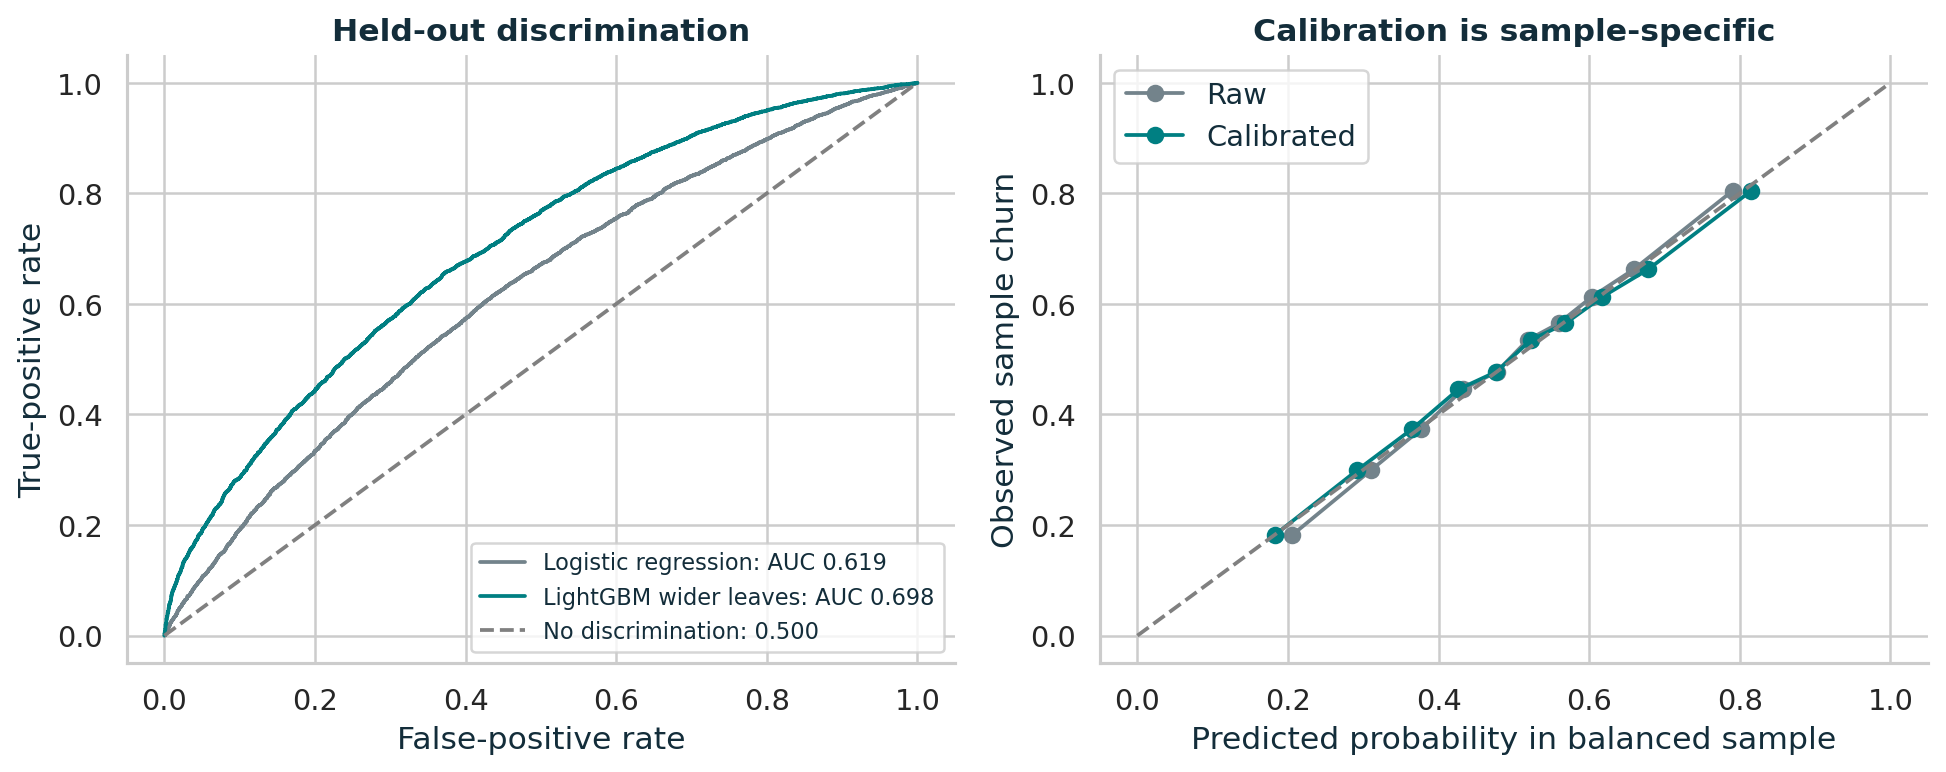

,policy,contact_fraction,customers_contacted,precision,churn_recall,recurring_value_recall,monthly_charge_per_contact,at_risk_recurring_per_contact
0,Risk only,0.05,750,0.868000,0.087559,0.077000,38.982547,33.644955
1,Risk only,0.10,1500,0.804667,0.162340,0.146237,39.584845,31.949021
2,Risk only,0.20,3000,0.733667,0.296032,0.263866,39.596963,28.823998
3,Recurring value only,0.05,750,0.400000,0.040350,0.091322,100.533240,39.903063
4,Recurring value only,0.10,1500,0.429333,0.086617,0.175695,90.661788,38.384897
5,Recurring value only,0.20,3000,0.439333,0.177270,0.313271,78.825047,34.220810
6,Risk × recurring value,0.05,750,0.632000,0.063753,0.114978,83.337420,50.239396
7,Risk × recurring value,0.10,1500,0.631333,0.127371,0.208296,75.958037,45.507319
8,Risk × recurring value,0.20,3000,0.619333,0.249899,0.371264,68.787087,40.555767
9,Old handset rule,0.05,750,0.625333,0.063080,0.048557,33.534806,21.216696


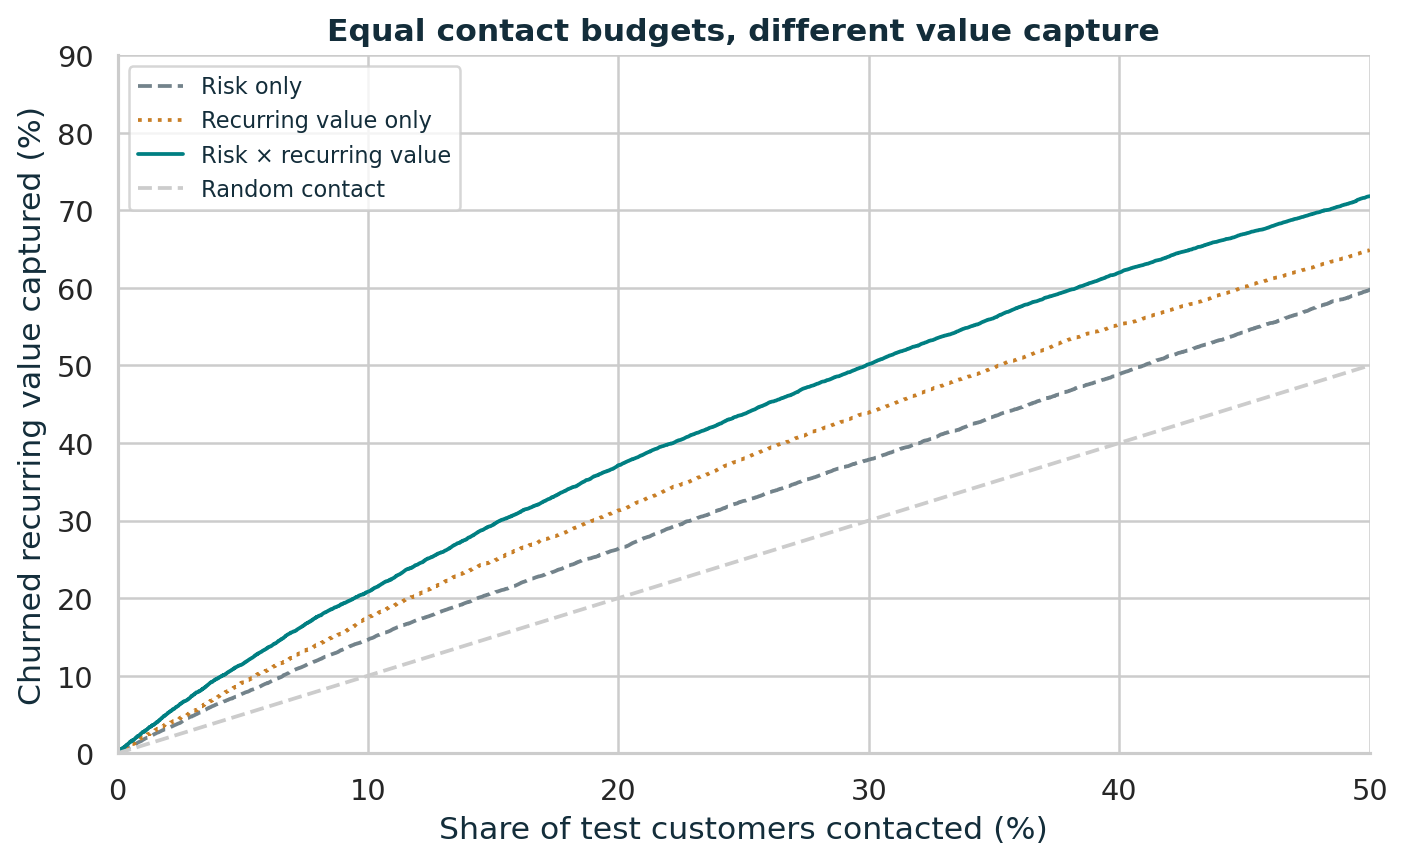

Paired test-row bootstrap; 300 replicates; conditional on fitted model and supplied sample:


,lower,upper
auc,0.689903,0.705495
value_capture_difference_pp,5.418038,7.083591
value_capture_relative_gain,0.363554,0.489940


In [6]:
raw_test = final_model.predict_proba(best_frame.loc[test_idx])[:, 1]
p_test = calibrate(raw_test)
y_test = y.loc[test_idx].to_numpy()
y_cal = y.loc[cal_idx].to_numpy()
v_test = monthly_value[test_idx]
v_cal = monthly_value[cal_idx]


def metric_row(name, truth, probabilities):
    pred = probabilities >= 0.5
    return {'model': name, 'roc_auc': roc_auc_score(truth, probabilities),
            'average_precision': average_precision_score(truth, probabilities),
            'accuracy': accuracy_score(truth, pred), 'precision_at_05': precision_score(truth, pred, zero_division=0),
            'recall_at_05': recall_score(truth, pred, zero_division=0),
            'log_loss': log_loss(truth, probabilities), 'brier': brier_score_loss(truth, probabilities)}


test_records = [metric_row('Constant prior baseline', y_test, np.full(len(y_test), y.loc[train_idx].mean())),
                metric_row('Logistic regression (60k train)', y_test, logistic.predict_proba(X.loc[test_idx])[:, 1]),
                metric_row(best_name + ' raw (75k refit)', y_test, raw_test),
                metric_row(best_name + ' calibrated (75k refit)', y_test, p_test)]
test_metrics = pd.DataFrame(test_records)
table('test_metrics', test_metrics)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for label, probabilities, color in [('Logistic regression', logistic.predict_proba(X.loc[test_idx])[:, 1], COLORS['muted']),
                                    (best_name, p_test, COLORS['teal'])]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    axes[0].plot(fpr, tpr, color=color, label=f'{label}: AUC {roc_auc_score(y_test, probabilities):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='No discrimination: 0.500')
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate', title='Held-out discrimination')
axes[0].legend(fontsize=9, loc='lower right')
for label, probabilities, color in [('Raw', raw_test, COLORS['muted']), ('Calibrated', p_test, COLORS['teal'])]:
    fraction, means = calibration_curve(y_test, probabilities, n_bins=10, strategy='quantile')
    axes[1].plot(means, fraction, marker='o', color=color, label=label)
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(xlabel='Predicted probability in balanced sample', ylabel='Observed sample churn', title='Calibration is sample-specific')
axes[1].legend()
figure('model_validation')


def ranking_metrics(truth, score, values, share=0.1):
    k = max(1, int(round(len(truth) * share)))
    chosen = np.argsort(-score, kind='stable')[:k]
    captured = float(np.sum(truth[chosen] * values[chosen]))
    return {'contact_fraction': share, 'customers_contacted': k,
            'precision': float(truth[chosen].mean()), 'churn_recall': float(truth[chosen].sum() / truth.sum()),
            'recurring_value_recall': float(captured / np.sum(truth * values)),
            'monthly_charge_per_contact': float(values[chosen].mean()),
            'at_risk_recurring_per_contact': float(captured / k)}


sample_policies = {'Risk only': p_test, 'Recurring value only': v_test,
                   'Risk × recurring value': p_test * v_test,
                   'Old handset rule': data.loc[test_idx, 'eqpdays'].fillna(-1).to_numpy()}
rank_records = []
for name, scores in sample_policies.items():
    for share in [0.05, 0.1, 0.2]:
        rank_records.append({'policy': name, **ranking_metrics(y_test, scores, v_test, share)})
ranking = pd.DataFrame(rank_records)
table('sample_ranking_policies', ranking)
fig, ax = plt.subplots(figsize=(8, 5))
for name, color, style in [('Risk only', COLORS['muted'], '--'), ('Recurring value only', COLORS['amber'], ':'),
                          ('Risk × recurring value', COLORS['teal'], '-')]:
    order = np.argsort(-sample_policies[name], kind='stable')
    gain = np.cumsum(y_test[order] * v_test[order]) / np.sum(y_test * v_test)
    ax.plot(np.arange(1, len(order) + 1) / len(order) * 100, gain * 100, style, color=color, label=name)
ax.plot([0, 100], [0, 100], '--', color='#CCCCCC', label='Random contact')
ax.set(xlim=(0, 50), ylim=(0, 90), xlabel='Share of test customers contacted (%)',
       ylabel='Churned recurring value captured (%)', title='Equal contact budgets, different value capture')
ax.legend(fontsize=9)
figure('value_capture_curve')

rng = np.random.default_rng(SEED)
bootstrap_records = []
for _ in range(300):
    ix = rng.integers(0, len(y_test), len(y_test))
    risk = ranking_metrics(y_test[ix], p_test[ix], v_test[ix])
    value = ranking_metrics(y_test[ix], p_test[ix] * v_test[ix], v_test[ix])
    bootstrap_records.append({'auc': roc_auc_score(y_test[ix], p_test[ix]),
         'value_capture_difference_pp': 100 * (value['recurring_value_recall'] - risk['recurring_value_recall']),
         'value_capture_relative_gain': value['recurring_value_recall'] / risk['recurring_value_recall'] - 1})
boot = pd.DataFrame(bootstrap_records)
intervals = {c: {'lower': float(boot[c].quantile(.025)), 'upper': float(boot[c].quantile(.975))} for c in boot}
save_json('bootstrap_intervals.json', intervals)
print('Paired test-row bootstrap; 300 replicates; conditional on fitted model and supplied sample:')
display(pd.DataFrame(intervals).T)

## 7. Explain the model and check where it weakens
Permutation importance shuffles each feature on 4,000 held-out customers and measures the loss of ROC-AUC. Correlated features can share or hide importance, and importance is **not causality**. These diagnostics are descriptive after the model and policy specification are fixed; they are not used to retune the evaluated model.

Region, tenure, and ID-order subgroup scores flag transport and quality risks. A stable average does not guarantee a stable subgroup. Before any production rollout, validate on recent dates and linked households/accounts, monitor selection and service outcomes, and reassess features whose collection timing is uncertain.

,feature,auc_decrease,repeat_sd
48,months,0.042217,0.003792
85,usage_change_scaled,0.026940,0.006770
73,eqpdays,0.022679,0.003679
69,hnd_price,0.007808,0.001627
83,equipment_age_to_tenure,0.007633,0.000584
80,recurring_charge_share,0.006772,0.001025
86,revenue_change_scaled,0.006682,0.002338
75,usage_recent_to_lifetime,0.006266,0.002506
2,totmrc_Mean,0.004445,0.000556
11,drop_vce_Mean,0.003171,0.000793


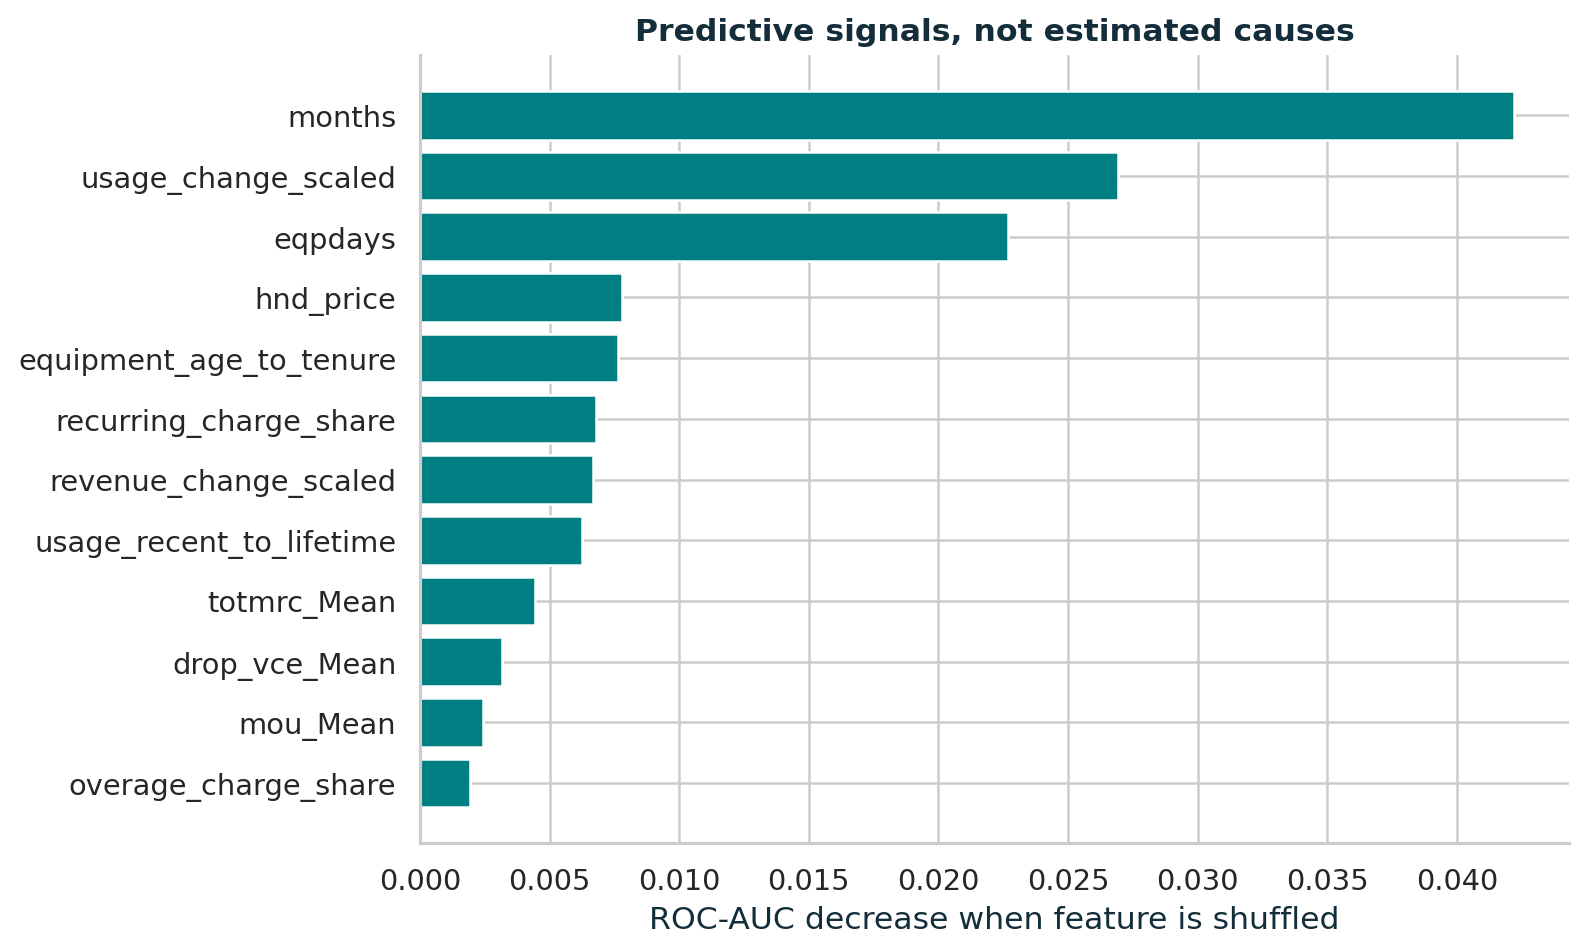

,dimension,group,customers,sample_churn_rate,roc_auc,brier
0,region,ATLANTIC SOUTH AREA,924,0.510823,0.670565,0.228763
1,region,CALIFORNIA NORTH AREA,882,0.502268,0.692750,0.221191
2,region,CENTRAL/SOUTH TEXAS AREA,644,0.490683,0.713598,0.214881
3,region,CHICAGO AREA,767,0.505867,0.719310,0.213655
4,region,DALLAS AREA,809,0.509271,0.669775,0.227491
5,region,DC/MARYLAND/VIRGINIA AREA,977,0.446264,0.711980,0.215478
6,region,GREAT LAKES AREA,703,0.453770,0.692684,0.219469
7,region,HOUSTON AREA,651,0.473118,0.639251,0.236808
8,region,LOS ANGELES AREA,1011,0.504451,0.706587,0.216071
9,region,MIDWEST AREA,948,0.476793,0.709588,0.215646


In [7]:
perm_index = rng.choice(test_idx, size=4000, replace=False)
importance = permutation_importance(final_model, best_frame.loc[perm_index], y.loc[perm_index],
                  scoring='roc_auc', n_repeats=2, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'feature': X.columns, 'auc_decrease': importance.importances_mean,
                   'repeat_sd': importance.importances_std}).sort_values('auc_decrease', ascending=False)
table('permutation_importance', imp.head(20))
fig, ax = plt.subplots(figsize=(9, 5.5))
top = imp.head(12).iloc[::-1]
ax.barh(top.feature, top.auc_decrease, color=COLORS['teal'])
ax.set(xlabel='ROC-AUC decrease when feature is shuffled', title='Predictive signals, not estimated causes')
figure('feature_importance')

robust_records = []
for dimension, series in [('region', data.loc[test_idx, 'area'].fillna('Unknown')),
                          ('tenure', pd.cut(data.loc[test_idx, 'months'], [0, 12, 24, 36, 100]).astype(str)),
                          ('ID quintile', pd.qcut(data.Customer_ID, 5).loc[test_idx].astype(str))]:
    for group in sorted(series.unique()):
        mask = (series == group).to_numpy()
        if mask.sum() >= 200 and len(np.unique(y_test[mask])) == 2:
            robust_records.append({'dimension': dimension, 'group': group, 'customers': int(mask.sum()),
                  'sample_churn_rate': float(y_test[mask].mean()), 'roc_auc': roc_auc_score(y_test[mask], p_test[mask]),
                  'brier': brier_score_loss(y_test[mask], p_test[mask])})
robustness = pd.DataFrame(robust_records)
table('subgroup_robustness', robustness)

## 8. Translate ranking into conditional economics—without pretending 50% churn is normal
This is a **scenario simulator**, not an estimate of Company A's current business results. There are no offer assignments, acceptance labels, treatment outcomes, true margins, campaign costs, actual currency, population sampling weights, or current churn baseline.

### Declared base scenario
- Hypothetical portfolio: 100,000 eligible deployment customers; one campaign cohort, not an annual claim.
- Churn in the modeled future-month window: 2%; stress tests use 1% and 5%.
- Prevention: 20% of contacted customers who would otherwise churn; stress tests use 10% and 30%.
- Six incremental retained months; 60% incremental contribution margin.
- $1 fully loaded variable cost per contacted customer and $5,000 fixed implementation cost; stress tests use $2 and $5 contacts. No handset subsidy or blanket discount is included.
- Capacity: target approximately 10% of the assumed deployment portfolio. Thresholds are learned on the calibration/policy partition, then applied unchanged to the test partition; achieved test coverage can differ.

**Formula:** net contribution = weighted would-be-churned recurring charges contacted × prevention fraction × retained months × margin − contacts × contact cost − fixed cost.

A prior-odds adjustment converts sample-calibrated risk to an assumed prevalence. Outcome-stratified evaluation weights also reweight the evaluation population, rather than applying a real-world churn prior while leaving the 50/50 test composition unchanged. This requires class-conditional representativeness / pure prior shift—an **unverified assumption**, not a correction guaranteed by these data. Test labels are used only for retrospective weighted evaluation, never as live policy inputs.

Risk-only, value-only, value-aware, and random policies share the same scenario assumptions. The optional positive-contribution gate additionally avoids contacts whose modeled variable benefit is below contact cost; fixed costs still have to be recovered. Success may differ by customer and action, so uniform prevention is only an auditable starting assumption. Savings must not be claimed until a randomized test measures incremental effects.

,policy,deployment_churn_assumption,success_assumption,contact_cost_assumption,retained_months_assumption,margin_assumption,population,contacts,contact_fraction,forecast_churners_contacted,churn_precision,prevented_churn_scenario,retained_revenue_scenario,gross_contribution_scenario,variable_cost,fixed_cost_assumption,net_contribution_scenario,variable_break_even_cost_per_contact,break_even_success_rate,calibration_policy_threshold
0,Random contact,0.02,0.2,1.0,6,0.6,100000,10000.000000,0.100000,200.000000,0.020000,40.000000,10578.441507,6347.064904,10000.000000,5000.0,-8652.935096,0.634706,0.472659,NaN
1,Risk only,0.02,0.2,1.0,6,0.6,100000,10431.260481,0.104313,572.965703,0.054928,114.593141,27059.712882,16235.827729,10431.260481,5000.0,804.567248,1.556459,0.190089,0.036833
2,Recurring value only,0.02,0.2,1.0,6,0.6,100000,10014.625099,0.100146,143.375925,0.014317,28.675185,15894.765848,9536.859509,10014.625099,5000.0,-5477.765590,0.952293,0.314876,76.682500
3,Value-aware,0.02,0.2,1.0,6,0.6,100000,9984.921534,0.099849,476.395427,0.047711,95.279085,31220.006650,18732.003990,9984.921534,5000.0,3747.082456,1.876029,0.159993,1.711494
4,Positive-contribution gate,0.02,0.2,1.0,6,0.6,100000,9984.921534,0.099849,476.395427,0.047711,95.279085,31220.006650,18732.003990,9984.921534,5000.0,3747.082456,1.876029,0.159993,1.711494


,policy,deployment_churn_assumption,success_assumption,contact_cost_assumption,retained_months_assumption,margin_assumption,population,contacts,contact_fraction,forecast_churners_contacted,churn_precision,prevented_churn_scenario,retained_revenue_scenario,gross_contribution_scenario,variable_cost,fixed_cost_assumption,net_contribution_scenario,variable_break_even_cost_per_contact,break_even_success_rate,calibration_policy_threshold
0,Value-aware,0.01,0.1,1.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,24.357767,7938.537170,4763.122302,10084.688050,5000.0,-10321.565748,0.472312,0.316697,0.854434
1,Value-aware,0.01,0.1,2.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,24.357767,7938.537170,4763.122302,20169.376100,5000.0,-20406.253798,0.472312,0.528422,0.854434
2,Value-aware,0.01,0.1,5.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,24.357767,7938.537170,4763.122302,50423.440250,5000.0,-50660.317947,0.472312,1.163595,0.854434
3,Value-aware,0.01,0.2,1.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,48.715535,15877.074340,9526.244604,10084.688050,5000.0,-5558.443446,0.944625,0.316697,0.854434
4,Value-aware,0.01,0.2,2.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,48.715535,15877.074340,9526.244604,20169.376100,5000.0,-15643.131496,0.944625,0.528422,0.854434
5,Value-aware,0.01,0.2,5.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,48.715535,15877.074340,9526.244604,50423.440250,5000.0,-45897.195645,0.944625,1.163595,0.854434
6,Value-aware,0.01,0.3,1.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,73.073302,23815.611510,14289.366906,10084.688050,5000.0,-795.321144,1.416937,0.316697,0.854434
7,Value-aware,0.01,0.3,2.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,73.073302,23815.611510,14289.366906,20169.376100,5000.0,-10880.009194,1.416937,0.528422,0.854434
8,Value-aware,0.01,0.3,5.0,6,0.6,100000,10084.688050,0.100847,243.577673,0.024153,73.073302,23815.611510,14289.366906,50423.440250,5000.0,-41134.073343,1.416937,1.163595,0.854434
9,Value-aware,0.02,0.1,1.0,6,0.6,100000,9984.921534,0.099849,476.395427,0.047711,47.639543,15610.003325,9366.001995,9984.921534,5000.0,-5618.919539,0.938015,0.159993,1.711494


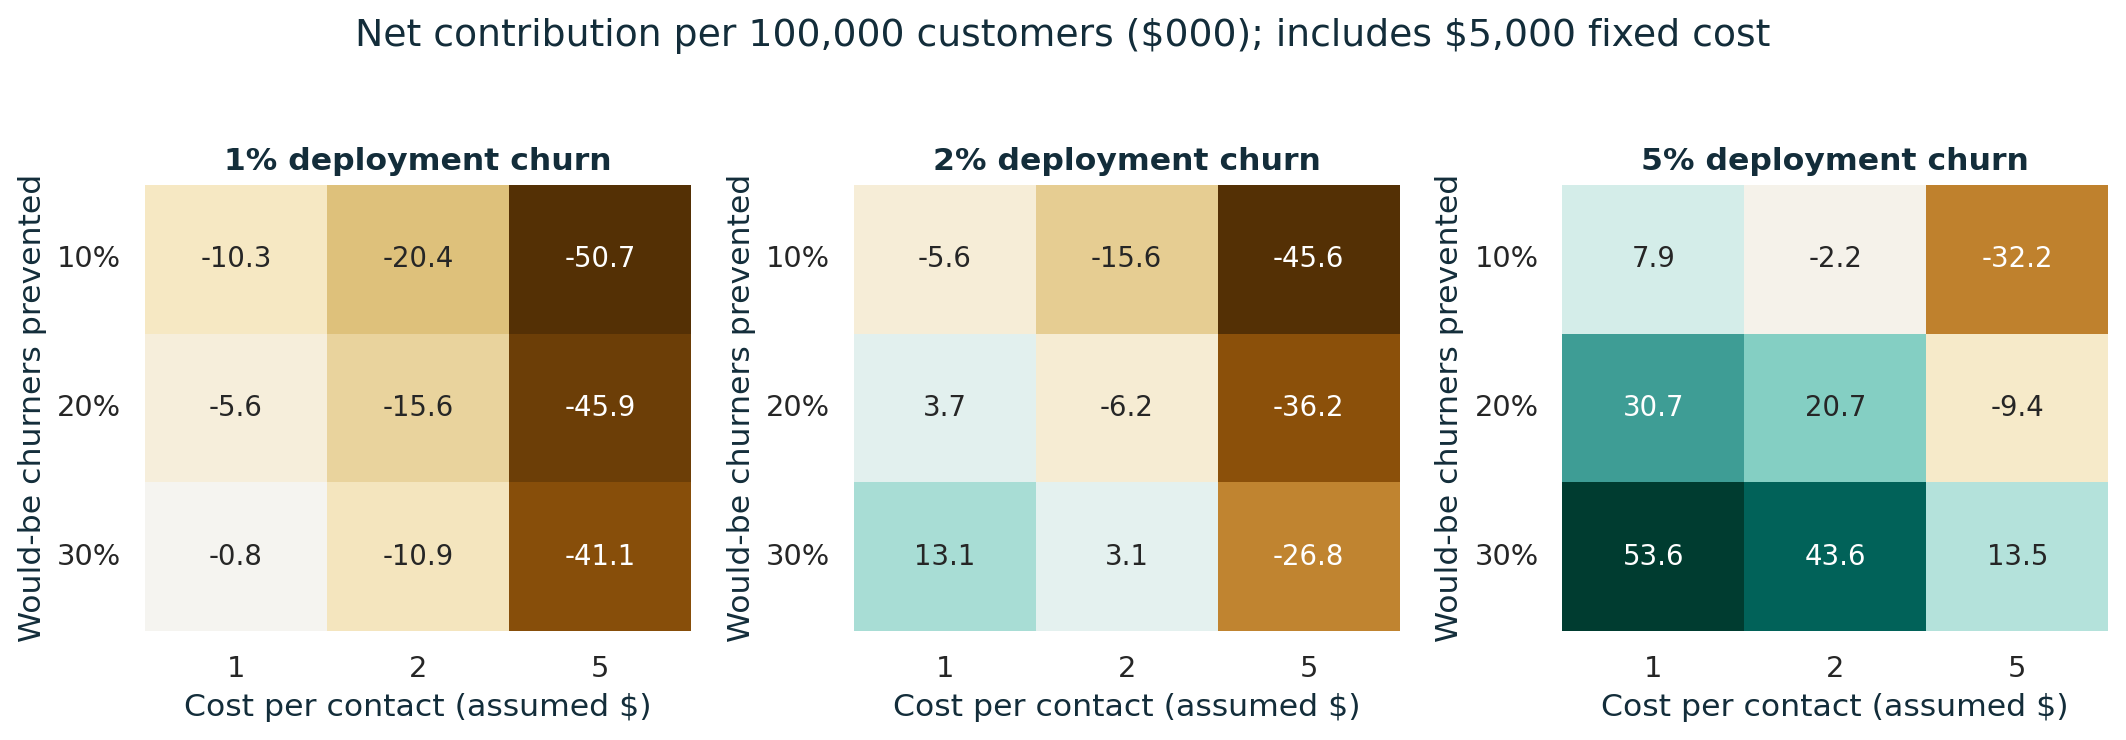

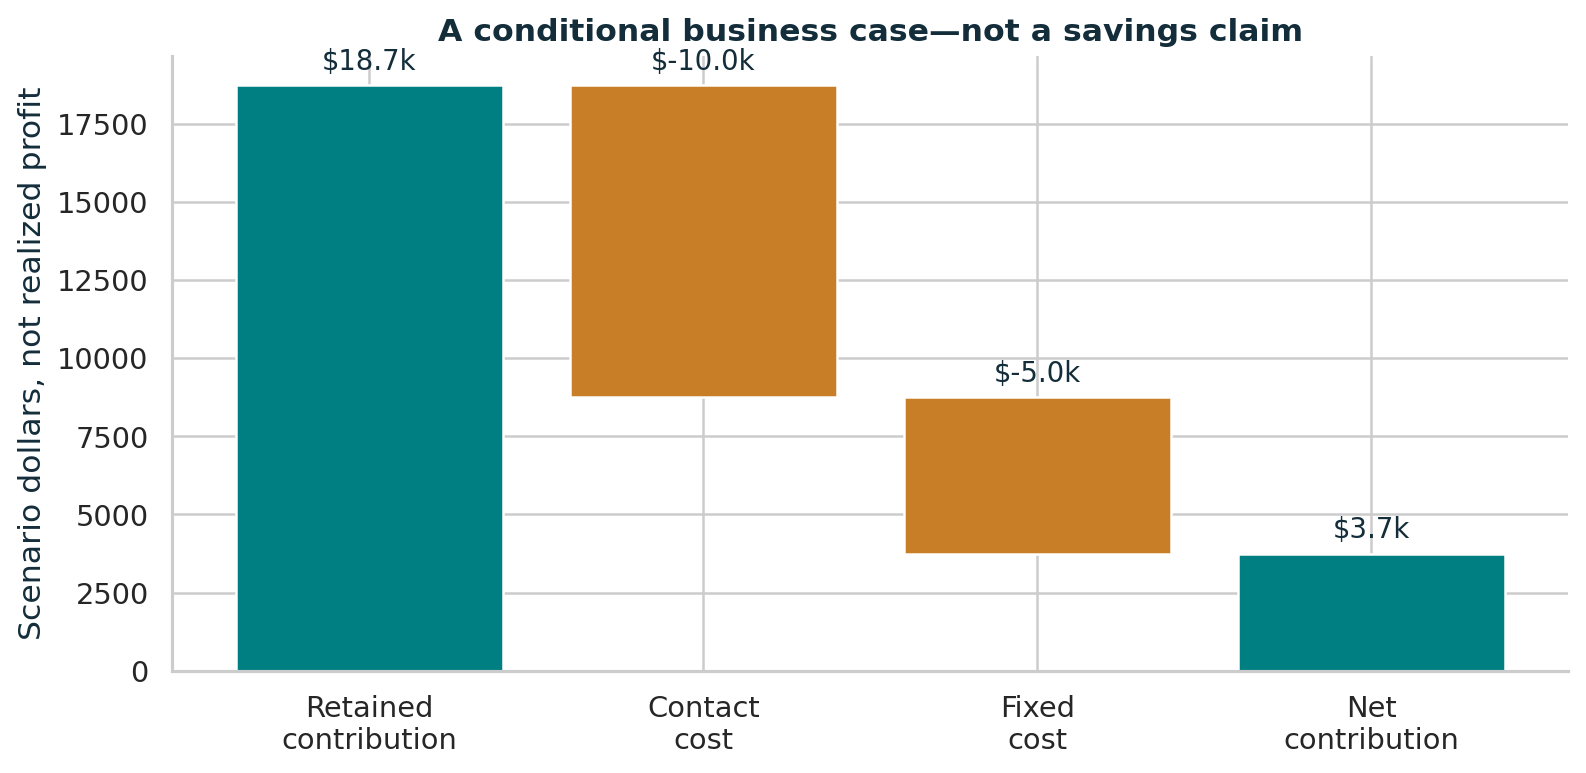

In [8]:
SAMPLE_PRIOR = float(y.loc[cal_idx].mean())
BASE_PREVALENCE = 0.02
BASE_SUCCESS = 0.20
BASE_MONTHS = 6
BASE_MARGIN = 0.60
BASE_CONTACT_COST = 1.00
FIXED_COST = 5000.0
POPULATION = 100000
CONTACT_CAP = 0.10


def prior_adjust(probability, new_prior):
    return expit(logit(np.clip(probability, 1e-6, 1-1e-6)) + logit(new_prior) - logit(SAMPLE_PRIOR))


def population_weights(truth, new_prior):
    observed = float(np.mean(truth))
    return np.where(truth == 1, new_prior / observed, (1 - new_prior) / (1 - observed))


def budget_threshold(score, weights, share=CONTACT_CAP):
    order = np.argsort(-score, kind='stable')
    cumulative = np.cumsum(weights[order])
    boundary = min(np.searchsorted(cumulative, weights.sum() * share, side='left'), len(order) - 1)
    return float(score[order[boundary]])


def evaluate_scenario(policy, prevalence=BASE_PREVALENCE, success=BASE_SUCCESS,
                      cost=BASE_CONTACT_COST, months=BASE_MONTHS, margin=BASE_MARGIN, cap=CONTACT_CAP):
    pc, pt = prior_adjust(p_cal, prevalence), prior_adjust(p_test, prevalence)
    wc, wt = population_weights(y_cal, prevalence), population_weights(y_test, prevalence)
    if policy == 'Risk only':
        sc, st = pc, pt
    elif policy == 'Recurring value only':
        sc, st = v_cal, v_test
    elif policy in ['Value-aware', 'Positive-contribution gate']:
        sc, st = pc * v_cal, pt * v_test
    elif policy == 'Random contact':
        sc = st = None
    else:
        raise ValueError(policy)
    threshold = None if sc is None else budget_threshold(sc, wc, cap)
    if policy == 'Positive-contribution gate':
        threshold = max(threshold, cost / (success * months * margin))
    selected = np.full(len(y_test), cap) if st is None else (st >= threshold).astype(float)
    weighted_contacts = float(np.sum(wt * selected))
    scale = POPULATION / wt.sum()
    contacts = weighted_contacts * scale
    eligible_churners = float(np.sum(wt * selected * y_test) * scale)
    churned_recurring = float(np.sum(wt * selected * y_test * v_test) * scale)
    prevented = eligible_churners * success
    retained_revenue = churned_recurring * success * months
    gross_contribution = retained_revenue * margin
    variable_cost = contacts * cost
    net = gross_contribution - variable_cost - FIXED_COST
    return {'policy': policy, 'deployment_churn_assumption': prevalence, 'success_assumption': success,
            'contact_cost_assumption': cost, 'retained_months_assumption': months, 'margin_assumption': margin,
            'population': POPULATION, 'contacts': contacts, 'contact_fraction': contacts / POPULATION,
            'forecast_churners_contacted': eligible_churners, 'churn_precision': eligible_churners / contacts if contacts else 0,
            'prevented_churn_scenario': prevented, 'retained_revenue_scenario': retained_revenue,
            'gross_contribution_scenario': gross_contribution, 'variable_cost': variable_cost,
            'fixed_cost_assumption': FIXED_COST, 'net_contribution_scenario': net,
            'variable_break_even_cost_per_contact': gross_contribution / contacts if contacts else 0,
            'break_even_success_rate': (variable_cost + FIXED_COST) / (churned_recurring * months * margin) if churned_recurring else None,
            'calibration_policy_threshold': threshold}


scenario_records = [evaluate_scenario(p) for p in ['Random contact', 'Risk only', 'Recurring value only', 'Value-aware', 'Positive-contribution gate']]
scenario = pd.DataFrame(scenario_records)
table('base_business_scenario', scenario)
sensitivity = pd.DataFrame([evaluate_scenario('Value-aware', prevalence=prevalence, success=success, cost=cost)
                           for prevalence in [0.01, 0.02, 0.05] for success in [0.10, 0.20, 0.30]
                           for cost in [1.0, 2.0, 5.0]])
table('business_sensitivity', sensitivity)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, prevalence in zip(axes, [0.01, 0.02, 0.05]):
    matrix = sensitivity.loc[sensitivity.deployment_churn_assumption == prevalence].pivot(index='success_assumption', columns='contact_cost_assumption', values='net_contribution_scenario') / 1000
    sns.heatmap(matrix, annot=True, fmt='.1f', cmap='BrBG', center=0, cbar=False, ax=ax,
                annot_kws={'fontsize': 11})
    ax.set(title=f'{prevalence:.0%} deployment churn', xlabel='Cost per contact (assumed $)', ylabel='Would-be churners prevented')
    ax.set_yticklabels(['10%', '20%', '30%'], rotation=0)
    ax.set_xticklabels(['1', '2', '5'])
fig.suptitle('Net contribution per 100,000 customers ($000); includes $5,000 fixed cost', y=1.03)
figure('profit_sensitivity')

base = scenario.set_index('policy').loc['Value-aware']
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ['Retained\ncontribution', 'Contact\ncost', 'Fixed\ncost', 'Net\ncontribution']
values = [base.gross_contribution_scenario, -base.variable_cost, -FIXED_COST, base.net_contribution_scenario]
starts = [0, values[0], values[0] + values[1], 0]
for i, (v, b) in enumerate(zip(values, starts)):
    bottom = b if v >= 0 else b + v
    ax.bar(i, abs(v), bottom=bottom, color=COLORS['teal'] if v >= 0 else COLORS['amber'])
    ax.text(i, max(bottom + abs(v), 0) + 500, f'${v/1000:,.1f}k', ha='center', fontsize=11)
ax.set(xticks=np.arange(4), xticklabels=labels, ylabel='Scenario dollars, not realized profit', title='A conditional business case—not a savings claim')
ax.axhline(0, color=COLORS['ink'], linewidth=.8)
figure('scenario_waterfall')

## 9. Buy evidence before scaling
Offer a consent-based digital service check; route verified billing or network issues to resolution and aged devices to diagnostics. Do not automatically cut prices, subsidize devices, infer willingness to pay from sensitive fields, or train a cross-sell model on nonexistent product labels.

Randomize eligible linked households/accounts into **service recovery vs business-as-usual**, stratified by risk–value band. Household linkage must be acquired before launch. Keep a holdout, track costs and opt-outs, measure churn in the specified days-31–60 window (plus early adverse churn), and track actual contribution for at least six months. Pre-register the primary incremental-contribution decision and guardrails. Stop or revise on adverse customer outcomes; scale only after positive incremental contribution is credibly demonstrated.

The power calculation below is illustrative: two-sided 5% alpha, 80% power, normal-approximation two-proportion test, based on the assumed target-group baseline and 20% relative churn reduction. It must be updated using a prospective baseline and inflated for account clustering and multiple treatment arms. Power for profit needs its own variance estimate; churn power alone is not enough.

The final assertions verify source immutability, prediction counts, finite probabilities, and feature consistency. All headline results below come from this local run.

In [9]:
control_rate = float(base.churn_precision)
treatment_rate = control_rate * (1 - BASE_SUCCESS)
pooled = (control_rate + treatment_rate) / 2
n_per_arm = int(np.ceil(((norm.ppf(.975) * np.sqrt(2 * pooled * (1 - pooled)) +
                         norm.ppf(.80) * np.sqrt(control_rate * (1-control_rate) + treatment_rate * (1-treatment_rate))) /
                        (control_rate - treatment_rate))**2))
pilot = {'illustrative_control_churn': control_rate, 'assumed_relative_reduction': BASE_SUCCESS,
         'illustrative_treatment_churn': treatment_rate, 'absolute_effect_pp': 100 * (control_rate-treatment_rate),
         'alpha_two_sided': .05, 'power': .80, 'minimum_per_arm_normal_approximation': n_per_arm,
         'per_arm_with_10pct_allowance': int(np.ceil(n_per_arm / .9)),
         'randomization_unit': 'household/account where linkage is available; not provided in this dataset',
         'primary_decision_metric': 'incremental contribution net of all intervention, incentive and implementation costs',
         'outcome_window': 'observed churn in days 31–60; also monitor days 0–30 and at least six months of realized contribution',
         'warning': 'Power calculation is illustrative; re-estimate from actual baseline and inflate for household clustering.'}
save_json('pilot_design.json', pilot)
print(json.dumps(pilot, indent=2))

predictions = pd.DataFrame({'Customer_ID': data.loc[test_idx, 'Customer_ID'].to_numpy(), 'actual_churn': y_test,
      'sample_calibrated_churn_probability': p_test, 'recurring_value_proxy': v_test,
      'sample_value_ranking_score': p_test * v_test,
      'scenario_probability_at_2pct_prior': prior_adjust(p_test, .02)})
predictions.to_csv(OUT / 'tables' / 'heldout_predictions.csv', index=False)
rank10 = ranking.loc[ranking.contact_fraction == .1].set_index('policy')
summary = {'audit': audit, 'model': best_name, 'feature_count': len(X.columns),
           'test_customers': len(test_idx), 'selected_test_metrics': test_records[-1],
           'bootstrap_intervals': intervals, 'ranking_top10': rank10.to_dict(orient='index'),
           'value_capture_relative_gain_over_risk': float(rank10.loc['Risk × recurring value', 'recurring_value_recall'] /
                                                       rank10.loc['Risk only', 'recurring_value_recall'] - 1),
           'age_segments': age.to_dict(orient='records'), 'base_business_scenario': scenario_records,
           'pilot': pilot, 'assumptions': {'money': 'USD-equivalent scenario only; supplied currency is unspecified',
           'population': '100,000 hypothetical eligible deployment customers, not an assertion of Company A size',
           'prior_shift': 'Class-conditional representativeness and prior-probability shift are unverified',
           'success': 'No treatment labels; 20% prevention is an assumption, not estimated uplift',
           'margin_and_horizon': '60% incremental contribution margin and six retained months are assumptions',
           'cost': '$1 per contact and $5,000 fixed implementation cost are assumptions, no blanket subsidy included'},
           'elapsed_seconds': time.perf_counter() - START}
save_json('summary.json', summary)
for relative, digest in source_hashes.items():
    assert sha256((ROOT / relative).read_bytes()).hexdigest() == digest
assert all(np.isfinite(p_test)) and p_test.min() >= 0 and p_test.max() <= 1
assert len(predictions) == len(test_idx)
assert final_model.n_features_in_ == X.shape[1]
print('All data-integrity and output checks passed. Elapsed minutes:', round(summary['elapsed_seconds']/60, 2))
display(Markdown(f'**Selected model:** {best_name}. **Held-out ROC-AUC:** {test_records[-1]["roc_auc"]:.4f}. '
                f'**Value-capture improvement versus risk-only targeting at the top 10%:** '
                f'{summary["value_capture_relative_gain_over_risk"]:.1%} on the supplied sample. '
                '**Recommendation:** stage-gated randomized pilot; no unconditional rollout or claimed causal savings.'))

{
  "illustrative_control_churn": 0.04771148430230854,
  "assumed_relative_reduction": 0.2,
  "illustrative_treatment_churn": 0.03816918744184683,
  "absolute_effect_pp": 0.9542296860461708,
  "alpha_two_sided": 0.05,
  "power": 0.8,
  "minimum_per_arm_normal_approximation": 7084,
  "per_arm_with_10pct_allowance": 7872,
  "randomization_unit": "household/account where linkage is available; not provided in this dataset",
  "primary_decision_metric": "incremental contribution net of all intervention, incentive and implementation costs",
  "outcome_window": "observed churn in days 31\u201360; also monitor days 0\u201330 and at least six months of realized contribution",
  "warning": "Power calculation is illustrative; re-estimate from actual baseline and inflate for household clustering."
}


All data-integrity and output checks passed. Elapsed minutes: 1.94


**Selected model:** LightGBM wider leaves. **Held-out ROC-AUC:** 0.6978. **Value-capture improvement versus risk-only targeting at the top 10%:** 42.4% on the supplied sample. **Recommendation:** stage-gated randomized pilot; no unconditional rollout or claimed causal savings.

## 10. Frozen enhancement protocol and self-contained reproduction
The nine original analysis code cells are preserved unchanged. They replay the already-evaluated v1 reference, not a new selection search on its test split. The following cells embed every enhancement module. Existing completed outputs are accepted only after source/output fingerprint verification; an absent analysis is reproduced locally in the prescribed A → B → C → D order.

**Four boundaries:** risk is not value; risk is not responsiveness; retrospective capture is not saved revenue; the approximately 49.56% supplied sample is not a 2% deployment population. The original test was evaluated for v1. Enhancement decisions use non-test rows, are frozen before one descriptive final batch, and are not confirmatory external validation.

The supplied dictionary does not specify the `_Mean` window and the CSVs have no `_Range` fields. Three-/six-month features use only verified `avg3`/`avg6` definitions. The unavailable volatility group is reported rather than reconstructed. No failed challenger proves an information ceiling.

In [10]:
import importlib
import sys
from pathlib import Path
from hashlib import sha256
import shutil
import json

V2_ROOT = Path.cwd().resolve()
V2_WORK = V2_ROOT / 'v2_work'
V2_WORK.mkdir(exist_ok=True)
if str(V2_WORK) not in sys.path:
    sys.path.insert(0, str(V2_WORK))

def _v2_materialize(name, source):
    path = V2_WORK / (name + '.py')
    if path.exists():
        assert path.read_text(encoding='utf-8') == source, f'Embedded module differs from local file: {name}'
    else:
        path.write_text(source, encoding='utf-8', newline='')
    return path

### Embedded module: common
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [11]:
_v2_materialize('common', ''.join([
    'from pathlib import Path\n',
    'import os\n',
    "os.environ['OMP_NUM_THREADS'] = '6'\n",
    "os.environ['MKL_NUM_THREADS'] = '6'\n",
    "os.environ['OPENBLAS_NUM_THREADS'] = '6'\n",
    'import json\n',
    'import re\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from scipy.special import expit, logit\n',
    'from sklearn.linear_model import LogisticRegression\n',
    'from sklearn.isotonic import IsotonicRegression\n',
    'import joblib\n',
    '\n',
    'ROOT = Path(__file__).resolve().parents[1]\n',
    "WORK = ROOT / 'v2_work'\n",
    'SEED = 20261028\n',
    'THREADS = 6\n',
    'PRIOR = .4956\n',
    "COLORS = {'ink': '#132D3A', 'teal': '#007F82', 'amber': '#C87E26', 'muted': '#73838B', 'light': '#EDF3F3'}\n",
    '\n',
    '\n',
    'def dump(name, value):\n',
    '    def convert(obj):\n',
    '        if isinstance(obj, dict):\n',
    '            return {str(k): convert(v) for k, v in obj.items()}\n',
    '        if isinstance(obj, (list, tuple)):\n',
    '            return [convert(v) for v in obj]\n',
    '        if isinstance(obj, np.ndarray):\n',
    '            return convert(obj.tolist())\n',
    '        if isinstance(obj, np.generic):\n',
    '            return convert(obj.item())\n',
    '        if isinstance(obj, float) and not np.isfinite(obj):\n',
    '            return None\n',
    '        return obj\n',
    "    (WORK / name).write_text(json.dumps(convert(value), indent=2, allow_nan=False), encoding='utf-8')\n",
    '\n',
    '\n',
    'def load_data():\n',
    "    data = pd.read_csv(ROOT / 'telecom/Record.csv').merge(pd.read_csv(ROOT / 'telecom/Client.csv'), on='Customer_ID', validate='one_to_one')\n",
    "    split = pd.read_csv(ROOT / 'v1_frozen/analysis_outputs/tables/split_manifest.csv')\n",
    "    labels = data.Customer_ID.map(split.set_index('Customer_ID').partition)\n",
    "    partitions = {name: np.flatnonzero(labels.eq(name)) for name in ['train', 'validation', 'calibration_policy', 'test']}\n",
    '    assert [len(partitions[k]) for k in partitions] == [60000, 15000, 10000, 15000]\n',
    '    return data, partitions\n',
    '\n',
    '\n',
    'def operational_features(data, train_idx):\n',
    "    source = (ROOT / 'v1_frozen/analysis_pipeline.py').read_text(encoding='utf-8')\n",
    "    section = re.split(r'^# %% Operational features\\n', source, flags=re.MULTILINE)[1].split('# %% Model selection')[0]\n",
    '    section = section.split("save_json(\'feature_manifest.json\'")[0]\n',
    "    env = {'data': data, 'train_idx': train_idx, 'np': np, 'pd': pd}\n",
    "    exec(compile(section, 'frozen-operational-features', 'exec'), env)\n",
    "    return env['X_native'], env['cat_cols']\n",
    '\n',
    '\n',
    "def values(data, train_idx, column='totmrc_Mean'):\n",
    '    train = data.iloc[train_idx][column].clip(lower=0)\n',
    '    median, cap = float(train.median()), float(train.quantile(.99))\n',
    "    return data[column].clip(lower=0).fillna(median).clip(upper=cap).to_numpy(), {'median': median, 'p99': cap}\n",
    '\n',
    '\n',
    'def shift(probability, prior=.02, sample_prior=PRIOR):\n',
    '    return expit(logit(np.clip(probability, 1e-6, 1-1e-6)) + logit(prior) - logit(sample_prior))\n',
    '\n',
    '\n',
    'def weights(y, prior=.02, population=100000):\n',
    '    y = np.asarray(y)\n',
    '    return np.where(y == 1, population * prior / y.sum(), population * (1-prior) / (len(y)-y.sum()))\n',
    '\n',
    '\n',
    'def cutoff(score, weight, share):\n',
    "    order = np.argsort(-np.asarray(score), kind='stable')\n",
    '    cumulative = np.cumsum(np.asarray(weight)[order])\n',
    '    return float(np.asarray(score)[order[min(np.searchsorted(cumulative, np.sum(weight)*share), len(order)-1)]])\n',
    '\n',
    '\n',
    'class Calibrator:\n',
    "    def __init__(self, method='sigmoid'):\n",
    '        self.method = method\n',
    '\n',
    '    def transform(self, p):\n',
    '        p = np.clip(p, 1e-6, 1-1e-6)\n',
    "        return np.c_[np.log(p), -np.log1p(-p)] if self.method == 'beta' else logit(p).reshape(-1, 1)\n",
    '\n',
    '    def fit(self, p, y):\n',
    "        if self.method == 'isotonic':\n",
    "            self.model = IsotonicRegression(out_of_bounds='clip', y_min=1e-6, y_max=1-1e-6).fit(p, y)\n",
    '        else:\n',
    "            self.model = LogisticRegression(C=1000, solver='lbfgs', random_state=SEED, max_iter=1000).fit(self.transform(p), y)\n",
    '        return self\n',
    '\n',
    '    def predict(self, p):\n',
    "        result = self.model.predict(p) if self.method == 'isotonic' else self.model.predict_proba(self.transform(p))[:, 1]\n",
    '        return np.clip(result, 1e-6, 1-1e-6)\n',
    '\n',
    '\n',
    "def frozen_predictions(partition='calibration_policy'):\n",
    '    data, splits = load_data()\n',
    '    idx = splits[partition]\n',
    "    X, cats = operational_features(data, splits['train'])\n",
    "    bundle = joblib.load(ROOT / 'v1_frozen/analysis_outputs/models/selected_model.joblib')\n",
    "    raw = bundle['model'].predict_proba(X.iloc[idx])[:, 1]\n",
    "    ps = bundle['calibrator'].predict_proba(logit(np.clip(raw, 1e-6, 1-1e-6)).reshape(-1, 1))[:, 1]\n",
    "    v, limits = values(data, splits['train'])\n",
    "    frame = pd.DataFrame({'Customer_ID': data.iloc[idx].Customer_ID.to_numpy(), 'y': data.iloc[idx].churn.to_numpy(), 'p_raw': raw, 'p_s': ps, 'p_d': shift(ps), 'value': v[idx], 'weight': weights(data.iloc[idx].churn.to_numpy()), 'partition': partition})\n",
    '    return data, splits, frame\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/common.py')

### Embedded module: workstream_a
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [12]:
_v2_materialize('workstream_a', ''.join([
    'from pathlib import Path\n',
    'import argparse\n',
    'import json\n',
    'import joblib\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss\n',
    'from sklearn.model_selection import StratifiedKFold\n',
    'from common import ROOT, WORK, SEED, Calibrator, frozen_predictions, shift, weights, cutoff, values, dump\n',
    '\n',
    "POLICIES = ['risk', 'value', 'sample_rv', 'bayes', 'profit_gate']\n",
    'PRIORS = [.01, .02, .05]\n',
    'COSTS = [.25, 1., 2., 5.]\n',
    'FRACTIONS = np.arange(1, 31) / 100\n',
    '\n',
    '\n',
    'def scores(frame, prior=.02, proxy=None):\n',
    '    p = frame.p_s.to_numpy()\n',
    '    value = frame.value.to_numpy() if proxy is None else np.asarray(proxy)\n',
    '    pd_ = shift(p, prior)\n',
    "    return {'risk': pd_, 'value': value, 'sample_rv': p * value, 'bayes': pd_ * value, 'profit_gate': pd_ * value}\n",
    '\n',
    '\n',
    'def measure(frame, selected, prior=.02, cost=1., success=.2, proxy=None):\n',
    '    y = frame.y.to_numpy()\n',
    '    v = frame.value.to_numpy() if proxy is None else np.asarray(proxy)\n',
    '    w = weights(y, prior)\n',
    '    pd_ = shift(frame.p_s.to_numpy(), prior)\n',
    '    selected = np.asarray(selected, dtype=float)\n',
    '    contacts = float(np.sum(w * selected))\n',
    '    actual_churners = float(np.sum(w * selected * y))\n',
    '    actual_value = float(np.sum(w * selected * y * v))\n',
    '    expected_churners = float(np.sum(w * selected * pd_))\n',
    '    expected_value = float(np.sum(w * selected * pd_ * v))\n',
    '    gross = actual_value * success * 6 * .6\n',
    "    return {'raw_count': int(np.count_nonzero(selected)), 'contacts': contacts, 'achieved_contact_fraction': contacts/100000, 'mean_value': float(np.sum(w*selected*v)/contacts) if contacts else 0., 'sample_precision': float(np.sum(selected*y)/np.sum(selected)) if np.sum(selected) else 0., 'deployment_precision': actual_churners/contacts if contacts else 0., 'actual_churners': actual_churners, 'actual_value': actual_value, 'value_recall': actual_value/float(np.sum(w*y*v)), 'model_expected_churners': expected_churners, 'model_expected_value': expected_value, 'model_expected_net': expected_value*success*6*.6-contacts*cost-5000, 'actual_gross': gross, 'net': gross-contacts*cost-5000, 'break_even_contact_cost': (gross-5000)/contacts if contacts else None, 'break_even_success': (contacts*cost+5000)/(actual_value*6*.6) if actual_value else None, 'observed_expected_churn_ratio': actual_churners/expected_churners if expected_churners else None}\n",
    '\n',
    '\n',
    'def fit_thresholds(frame, prior=.02, fraction=.1, cost=1., proxy=None):\n',
    '    w = weights(frame.y.to_numpy(), prior)\n',
    '    thresholds = {name: cutoff(score, w, fraction) for name, score in scores(frame, prior, proxy).items()}\n',
    "    thresholds['profit_gate'] = max(thresholds['profit_gate'], cost/(.2*6*.6))\n",
    '    return thresholds\n',
    '\n',
    '\n',
    'def sample_measure(frame, score, fraction=.1):\n',
    "    selected = np.argsort(-score, kind='stable')[:int(round(len(frame)*fraction))]\n",
    '    y, v = frame.y.to_numpy(), frame.value.to_numpy()\n',
    "    return {'raw_count': len(selected), 'value_recall': float(np.sum(y[selected]*v[selected])/np.sum(y*v)), 'precision': float(y[selected].mean())}\n",
    '\n',
    '\n',
    'def prepare():\n',
    '    data, splits, cal = frozen_predictions()\n',
    "    methods = ['sigmoid', 'beta', 'isotonic']\n",
    '    oof = {method: np.zeros(len(cal)) for method in methods}\n',
    '    fold_rows = []\n',
    '    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)\n',
    '    for fold, (train, validation) in enumerate(cv.split(cal, cal.y)):\n',
    '        for method in methods:\n',
    '            model = Calibrator(method).fit(cal.p_raw.to_numpy()[train], cal.y.to_numpy()[train])\n',
    '            prediction = model.predict(cal.p_raw.to_numpy()[validation])\n',
    '            oof[method][validation] = prediction\n',
    '            for fraction in [.1, .25]:\n',
    '                value = cal.value.to_numpy()[validation]\n',
    "                order = np.argsort(-shift(prediction)*value, kind='stable')\n",
    '                w = weights(cal.y.to_numpy()[validation])\n',
    '                boundary = cutoff(shift(prediction)*value, w, fraction)\n',
    '                mask = shift(prediction)*value >= boundary\n',
    "                fold_rows.append({'fold': fold, 'method': method, 'tail_fraction': fraction, 'auc': roc_auc_score(cal.y.to_numpy()[validation], prediction), 'log_loss': log_loss(cal.y.to_numpy()[validation], prediction), 'brier': brier_score_loss(cal.y.to_numpy()[validation], prediction), 'tail_log_loss': log_loss(cal.y.to_numpy()[validation][mask], prediction[mask]), 'tail_brier': brier_score_loss(cal.y.to_numpy()[validation][mask], prediction[mask]), 'deployment_tail_ratio': float(np.sum(w[mask]*cal.y.to_numpy()[validation][mask])/np.sum(w[mask]*shift(prediction)[mask]))})\n",
    "    pd.DataFrame(fold_rows).to_csv(WORK / 'a_calibration_cv.csv', index=False)\n",
    "    baseline_loss = -(cal.y*np.log(oof['sigmoid'])+(1-cal.y)*np.log1p(-oof['sigmoid']))\n",
    '    rng = np.random.default_rng(SEED+10)\n',
    '    calibration_tests = []\n',
    '    for method in methods:\n',
    '        loss = -(cal.y*np.log(oof[method])+(1-cal.y)*np.log1p(-oof[method]))\n',
    '        paired = np.asarray(baseline_loss-loss)\n',
    '        boot = [float(paired[rng.integers(0,len(cal),len(cal))].mean()) for _ in range(300)]\n',
    "        tails = pd.DataFrame(fold_rows).query('tail_fraction == .1')\n",
    '        baseline_tail = float(tails.query(\'method == "sigmoid"\').tail_brier.mean())\n',
    "        candidate_tail = float(tails.loc[tails.method.eq(method), 'tail_brier'].mean())\n",
    "        calibration_tests.append({'method': method, 'oof_log_loss': log_loss(cal.y, oof[method]), 'paired_logloss_improvement': float(paired.mean()), 'ci_lower': float(np.quantile(boot,.025)), 'ci_upper': float(np.quantile(boot,.975)), 'tail_brier': candidate_tail, 'passes': method!='sigmoid' and np.quantile(boot,.025)>0 and candidate_tail<=baseline_tail})\n",
    "    eligible = [r for r in calibration_tests if r['passes']]\n",
    "    selected = min(eligible,key=lambda r:r['oof_log_loss'])['method'] if eligible else 'sigmoid'\n",
    '    final_calibrator = Calibrator(selected).fit(cal.p_raw.to_numpy(),cal.y.to_numpy())\n',
    "    joblib.dump(final_calibrator, WORK/'a_calibrator.joblib')\n",
    "    cal['p_s_oof'] = oof[selected]\n",
    "    cal['p_s'] = final_calibrator.predict(cal.p_raw.to_numpy())\n",
    "    cal['p_d'] = shift(cal.p_s.to_numpy())\n",
    '    decision = cal.copy()\n',
    "    decision['p_s'] = cal.p_s_oof\n",
    "    decision['p_d'] = shift(decision.p_s.to_numpy())\n",
    '    choices = []\n',
    '    for cost in COSTS:\n',
    '        candidate = []\n',
    '        for fraction in FRACTIONS:\n',
    '            t = fit_thresholds(decision,fraction=fraction,cost=cost)\n',
    "            selected_mask = scores(decision)['bayes']>=t['bayes']\n",
    "            candidate.append({'cost': cost, 'fraction': float(fraction), **measure(decision,selected_mask,cost=cost)})\n",
    "        winner = max(candidate,key=lambda r:r['net'])\n",
    "        choices.append({'cost':cost,'fraction':winner['fraction'],'calibration_oof_net':winner['net'],'frozen_threshold':fit_thresholds(cal,fraction=winner['fraction'],cost=cost)['bayes'], 'no_contact_net':0., 'launch_allowed_by_assumed_calibration_net':winner['net']>0})\n",
    "    pd.DataFrame(choices).to_csv(WORK/'a_budget_choices.csv',index=False)\n",
    "    spec = {'calibrator':selected,'calibration_candidates':calibration_tests,'base_fraction':.1,'optimal_budgets_calibration_only':choices,'test_used_for_selection':False,'value_proxy':'totmrc_Mean','gate_a':'Prior-regime reconciliation qualifies: v1 already used Bayes deployment score in financial scenario. New calibrator and budgets require non-test evidence; test empirical maxima remain diagnostic only.', 'thresholds':{str(prior):fit_thresholds(cal,prior=prior) for prior in PRIORS}}\n",
    "    dump('a_spec.json',spec)\n",
    "    cal['selected_risk'] = scores(cal)['risk']>=spec['thresholds']['0.02']['risk']\n",
    "    cal['selected_bayes'] = scores(cal)['bayes']>=spec['thresholds']['0.02']['bayes']\n",
    "    cal.to_csv(WORK/'a_selected_calibration.csv',index=False)\n",
    "    print('A calibration selection:',selected,'; fixed base budget10%; optimal fractions chosen on calibration OOF only',flush=True)\n",
    "    analyze(cal,cal,data,splits,'calibration')\n",
    '\n',
    '\n',
    'def analyze(cal,frame,data,splits,label):\n',
    "    spec = json.loads((WORK/'a_spec.json').read_text())\n",
    '    policy_rows, curve_rows, overlap_rows, dual_rows = [], [], [], []\n',
    '    for prior in PRIORS:\n',
    "        threshold = spec['thresholds'][str(prior)]\n",
    '        score = scores(frame,prior)\n',
    '        for name in POLICIES:\n',
    '            selected = score[name]>=threshold[name]\n',
    "            policy_rows.append({'partition':label,'prior':prior,'policy':name,'intended_fraction':.1,'threshold':threshold[name], **measure(frame,selected,prior)})\n",
    '        if prior==.02:\n',
    "            risk = score['risk']>=threshold['risk']\n",
    "            bayes = score['bayes']>=threshold['bayes']\n",
    "            regions = {'both':risk & bayes,'rv_only':bayes & ~risk,'risk_only':risk & ~bayes}\n",
    '            for name,mask in regions.items():\n',
    '                result = measure(frame,mask)\n',
    "                result['variable_net_without_allocated_fixed'] = result['net']+5000\n",
    "                result['net_with_proportional_fixed_allocation'] = result['net']+5000 - 5000*result['contacts']/measure(frame,risk|bayes)['contacts']\n",
    "                overlap_rows.append({'region':name,**result})\n",
    '            for cost in COSTS:\n',
    '                for fraction in FRACTIONS:\n',
    "                    threshold_f = fit_thresholds(cal,fraction=float(fraction),cost=cost)['bayes']\n",
    "                    mask = score['bayes']>=threshold_f\n",
    "                    curve_rows.append({'prior':prior,'cost':cost,'intended_fraction':float(fraction),'threshold':threshold_f,**measure(frame,mask,cost=cost)})\n",
    '            previous = np.zeros(len(frame),dtype=bool)\n',
    '            for fraction in np.arange(1,26)/100:\n',
    "                t = fit_thresholds(cal,fraction=float(fraction))['bayes']\n",
    "                selected = score['bayes']>=t\n",
    '                increment = selected & ~previous\n',
    '                r = measure(frame,increment)\n',
    "                r['realized_marginal_net_per_contact'] = (r['actual_gross']-r['contacts'])/r['contacts'] if r['contacts'] else None\n",
    "                r['predicted_marginal_net_per_contact'] = (r['model_expected_value']*.2*6*.6-r['contacts'])/r['contacts'] if r['contacts'] else None\n",
    "                dual_rows.append({'intended_fraction':float(fraction), **r})\n",
    '                previous = selected\n',
    "    pd.DataFrame(policy_rows).to_csv(WORK/f'a_policies_{label}.csv',index=False)\n",
    "    pd.DataFrame(curve_rows).to_csv(WORK/f'a_profit_curves_{label}.csv',index=False)\n",
    "    pd.DataFrame(overlap_rows).to_csv(WORK/f'a_overlap_{label}.csv',index=False)\n",
    "    pd.DataFrame(dual_rows).to_csv(WORK/f'a_dual_valuation_{label}.csv',index=False)\n",
    '    proxy_rows = []\n',
    "    ids = data.set_index('Customer_ID')\n",
    "    for proxy in ['totmrc_Mean','avg3rev','avg6rev','rev_Mean']:\n",
    "        v,limits = values(data,splits['train'],proxy)\n",
    '        by_id = pd.Series(v,index=data.Customer_ID)\n',
    '        vc,vf = by_id.loc[cal.Customer_ID].to_numpy(),by_id.loc[frame.Customer_ID].to_numpy()\n',
    '        threshold = fit_thresholds(cal,proxy=vc)\n',
    '        score = scores(frame,proxy=vf)\n',
    '        for name in POLICIES:\n',
    "            proxy_rows.append({'proxy':proxy,'policy':name,**limits,**measure(frame,score[name]>=threshold[name],proxy=vf)})\n",
    "    pd.DataFrame(proxy_rows).to_csv(WORK/f'a_value_proxy_sensitivity_{label}.csv',index=False)\n",
    '    rng = np.random.default_rng(SEED+100)\n',
    '    bootstrap_rows = []\n',
    '    for rep in range(300):\n',
    '        ix = rng.integers(0,len(frame),len(frame))\n',
    '        evaluation = frame.iloc[ix].reset_index(drop=True)\n',
    '        for prior in PRIORS:\n',
    "            threshold = spec['thresholds'][str(prior)]\n",
    '            score = scores(evaluation,prior)\n',
    '            results = {name:measure(evaluation,score[name]>=threshold[name],prior) for name in POLICIES}\n',
    '            for name in POLICIES:\n',
    "                bootstrap_rows.append({'replicate':rep,'regime':'deployment','prior':prior,'policy':name,'value_recall':results[name]['value_recall'],'net':results[name]['net'],'value_difference_vs_risk':results[name]['value_recall']-results['risk']['value_recall'],'relative_value_gain_vs_risk':results[name]['value_recall']/results['risk']['value_recall']-1,'net_difference_vs_risk':results[name]['net']-results['risk']['net']})\n",
    '        result = {name:sample_measure(evaluation,score) for name,score in scores(evaluation,prior=.4956).items()}\n',
    '        for name in POLICIES:\n',
    "            bootstrap_rows.append({'replicate':rep,'regime':'sample','prior':.4956,'policy':name,'value_recall':result[name]['value_recall'],'net':None,'value_difference_vs_risk':result[name]['value_recall']-result['risk']['value_recall'],'relative_value_gain_vs_risk':result[name]['value_recall']/result['risk']['value_recall']-1,'net_difference_vs_risk':None})\n",
    '    bootstrap = pd.DataFrame(bootstrap_rows)\n',
    "    bootstrap.to_csv(WORK/f'a_bootstrap_{label}.csv',index=False)\n",
    '    intervals = []\n',
    "    for keys,group in bootstrap.groupby(['regime','prior','policy']):\n",
    "        for metric in ['value_recall','net','value_difference_vs_risk','relative_value_gain_vs_risk','net_difference_vs_risk']:\n",
    '            vals = group[metric].dropna()\n',
    '            if len(vals):\n',
    "                intervals.append({'regime':keys[0],'prior':keys[1],'policy':keys[2],'metric':metric,'lower':float(vals.quantile(.025)),'upper':float(vals.quantile(.975))})\n",
    "    pd.DataFrame(intervals).to_csv(WORK/f'a_intervals_{label}.csv',index=False)\n",
    '    uncertainty = []\n',
    '    for rep in range(300):\n',
    '        ci = rng.integers(0,len(cal),len(cal))\n',
    '        ei = rng.integers(0,len(frame),len(frame))\n',
    '        calibration = cal.iloc[ci].copy().reset_index(drop=True)\n',
    '        evaluation = frame.iloc[ei].copy().reset_index(drop=True)\n',
    "        model = Calibrator(spec['calibrator']).fit(calibration.p_raw.to_numpy(),calibration.y.to_numpy())\n",
    "        calibration['p_s'] = model.predict(calibration.p_raw.to_numpy())\n",
    "        evaluation['p_s'] = model.predict(evaluation.p_raw.to_numpy())\n",
    '        t = fit_thresholds(calibration)\n',
    '        sc = scores(evaluation)\n',
    "        a = measure(evaluation,sc['bayes']>=t['bayes'])\n",
    "        b = measure(evaluation,sc['risk']>=t['risk'])\n",
    "        uncertainty.append({'replicate':rep,'net':a['net'],'net_difference_vs_risk':a['net']-b['net'],'value_recall':a['value_recall'],'relative_value_gain_vs_risk':a['value_recall']/b['value_recall']-1})\n",
    "    pd.DataFrame(uncertainty).to_csv(WORK/f'a_calibration_uncertainty_{label}.csv',index=False)\n",
    '    curves = pd.DataFrame(curve_rows)\n',
    '    optimal = []\n',
    "    for choice in spec['optimal_budgets_calibration_only']:\n",
    "        match = curves.loc[(curves.cost==choice['cost']) & np.isclose(curves.intended_fraction,choice['fraction'])].iloc[0].to_dict()\n",
    "        oracle = curves.loc[curves.cost==choice['cost']].sort_values('net').iloc[-1]\n",
    "        optimal.append({**choice,'evaluation_at_frozen_fraction':match,'posthoc_empirical_max_fraction_diagnostic_only':float(oracle.intended_fraction),'posthoc_empirical_max_net_diagnostic_only':float(oracle.net)})\n",
    "    summary = {'partition':label,'spec':spec,'policies':policy_rows,'overlap':overlap_rows,'optimal_budget_results':optimal,'paired_intervals':intervals,'calibration_uncertainty_intervals':{c:{'lower':float(pd.DataFrame(uncertainty)[c].quantile(.025)),'upper':float(pd.DataFrame(uncertainty)[c].quantile(.975))} for c in ['net','net_difference_vs_risk','value_recall','relative_value_gain_vs_risk']},'warning':'All deployment dollars use unverified prior shift, uniform20% prevention,6 months60% margin,$1 contact,$5k fixed. Test achieved budget differs from calibration target: report actual contact mass; posthoc quota curves/optima are diagnostics, never test-selected policy. Calibration-CV uncertainty excludes refitting base classifier and real treatment effects.'}\n",
    "    dump(f'a_summary_{label}.json',summary)\n",
    "    dump('a_summary.json',summary)\n",
    "    print(label,'A policy comparison:',[(r['policy'],round(r['value_recall']*100,2),round(r['net'],2)) for r in policy_rows if r['prior']==.02],flush=True)\n",
    '\n',
    '\n',
    'def evaluate_test():\n',
    '    from common import load_data, operational_features\n',
    '    from scipy.special import logit\n',
    '    from final_protocol import begin_test\n',
    '    begin_test(promoted=False)\n',
    '    data,splits = load_data()\n',
    "    cal = pd.read_csv(WORK/'a_selected_calibration.csv')\n",
    "    frozen = pd.read_csv(ROOT/'v1_frozen/analysis_outputs/tables/heldout_predictions.csv')\n",
    '    order = pd.Series(np.arange(len(data)),index=data.Customer_ID).loc[frozen.Customer_ID].to_numpy()\n',
    "    bundle = joblib.load(ROOT/'v1_frozen/analysis_outputs/models/selected_model.joblib')\n",
    "    raw = 1/(1+np.exp(-(logit(np.clip(frozen.sample_calibrated_churn_probability.to_numpy(),1e-6,1-1e-6))-bundle['calibrator'].intercept_[0])/bundle['calibrator'].coef_[0,0]))\n",
    "    calibrator = joblib.load(WORK/'a_calibrator.joblib')\n",
    '    p = calibrator.predict(raw)\n',
    "    frame = pd.DataFrame({'Customer_ID':frozen.Customer_ID,'y':frozen.actual_churn,'p_raw':raw,'p_s':p,'p_d':shift(p),'value':frozen.recurring_value_proxy,'weight':weights(frozen.actual_churn.to_numpy()),'partition':'test'})\n",
    "    spec = json.loads((WORK/'a_spec.json').read_text())\n",
    '    sc = scores(frame)\n',
    "    frame['selected_risk'] = sc['risk']>=spec['thresholds']['0.02']['risk']\n",
    "    frame['selected_bayes'] = sc['bayes']>=spec['thresholds']['0.02']['bayes']\n",
    "    frame.to_csv(WORK/'a_selected_test.csv',index=False)\n",
    "    analyze(cal,frame,data,splits,'test')\n",
    '\n',
    '\n',
    "if __name__=='__main__':\n",
    '    parser=argparse.ArgumentParser()\n',
    "    parser.add_argument('--prepare',action='store_true')\n",
    "    parser.add_argument('--test',action='store_true')\n",
    '    args=parser.parse_args()\n',
    '    if args.prepare:\n',
    '        prepare()\n',
    '    elif args.test:\n',
    '        evaluate_test()\n',
    '    else:\n',
    "        parser.error('choose --prepare or --test')\n"
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/workstream_a.py')

### Embedded module: workstream_b
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [13]:
_v2_materialize('workstream_b', ''.join([
    'from pathlib import Path\n',
    'from hashlib import sha256\n',
    'import argparse\n',
    'import json\n',
    'import math\n',
    '\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from scipy.stats import norm\n',
    'from threadpoolctl import threadpool_limits\n',
    '\n',
    'from common import ROOT, WORK, SEED, THREADS, load_data, dump\n',
    '\n',
    'REPLICATES = 400\n',
    'GRID = (1000, 2500, 5000, 7872, 10000, 20000, 40000, 80000, 160000)\n',
    "COVARIATES = ('totmrc_Mean', 'avg3rev', 'p_d')\n",
    '\n',
    '\n',
    'def routing_inputs(data):\n',
    "    return pd.DataFrame({'billing_gap': ((data.avg3rev - data.avg6rev).abs() / data.avg6rev.clip(lower=1)).to_numpy(),\n",
    "                         'absolute_change_rev': data.change_rev.abs().to_numpy(),\n",
    "                         'failed_call_ratio': (data.drop_blk_Mean / data.attempt_Mean.clip(lower=1)).to_numpy(),\n",
    "                         'mou': data.mou_Mean.to_numpy()}, index=data.Customer_ID)\n",
    '\n',
    '\n',
    'def routing_spec(data, train):\n',
    '    inputs = routing_inputs(data)\n',
    "    return {'billing_gap_p90': float(inputs.billing_gap.iloc[train].quantile(.9)),\n",
    "            'absolute_change_rev_p90': float(inputs.absolute_change_rev.iloc[train].quantile(.9)),\n",
    "            'failed_call_ratio_p90': float(inputs.failed_call_ratio.iloc[train].quantile(.9)),\n",
    "            'low_usage_p25': float(data.mou_Mean.iloc[train].quantile(.25)),\n",
    "            'handset_days': 365, 'training_rows': len(train),\n",
    "            'precedence': ['billing_check', 'network_check', 'handset_check', 'digital_only_residual'],\n",
    "            'window_caveat': 'No Range columns. Billing uses verified 3/6-month comparisons and separately an ambiguously scaled change_rev flag, never an inferred Mean window or causal promo expiry.',\n",
    "            'residual_caveat': 'The fourth queue is a low-usage DIGITAL CHECK plus all remaining cases; not every residual is demonstrably low usage. Missing diagnostics do not prove a defect.'}\n",
    '\n',
    '\n',
    'def covariates(frame, data, train, limits=None):\n',
    "    source = data.set_index('Customer_ID')\n",
    '    if limits is None:\n',
    '        limits = {}\n',
    '        for column in COVARIATES[:-1]:\n',
    '            training = data.iloc[train][column].clip(lower=0)\n',
    "            limits[column] = {'median': float(training.median()), 'p99': float(training.quantile(.99))}\n",
    '    columns = []\n',
    '    for column in COVARIATES[:-1]:\n',
    '        limits_c = limits[column]\n',
    "        columns.append(source.loc[frame.Customer_ID, column].clip(lower=0).fillna(limits_c['median']).clip(upper=limits_c['p99']).to_numpy())\n",
    '    columns.append(frame.p_d.to_numpy())\n',
    '    return np.column_stack(columns), limits\n',
    '\n',
    '\n',
    'def fit_adjustment(frame, X):\n',
    '    core = frame.selected_bayes.to_numpy(dtype=bool)\n',
    '    w = frame.weight.to_numpy()[core]\n',
    '    Z = np.c_[np.ones(core.sum()), X[core]]\n',
    '    outcome = 3.6 * frame.value.to_numpy()[core] * (1 - frame.y.to_numpy()[core])\n',
    '    beta = np.linalg.lstsq(Z * np.sqrt(w[:, None]), outcome * np.sqrt(w), rcond=None)[0]\n',
    '    return beta.tolist()\n',
    '\n',
    '\n',
    'def cells(frame):\n',
    '    risk = frame.selected_risk.to_numpy(dtype=bool)\n',
    '    bayes = frame.selected_bayes.to_numpy(dtype=bool)\n',
    '    labels = np.select([risk & bayes, bayes & ~risk, risk & ~bayes],\n',
    "                       ['both', 'rv_only', 'risk_only'], default='exploration')\n",
    '    assert len(labels) == len(frame)\n',
    '    return labels\n',
    '\n',
    '\n',
    'def cell_summary(frame):\n',
    '    labels = cells(frame)\n',
    '    w, y, v = frame.weight.to_numpy(), frame.y.to_numpy(), frame.value.to_numpy()\n',
    '    records = []\n',
    "    for label in ('both', 'rv_only', 'risk_only', 'exploration'):\n",
    '        mask = labels == label\n',
    '        mass = float(w[mask].sum())\n',
    "        records.append({'cell': label, 'raw_count': int(mask.sum()), 'deployment_mass': mass,\n",
    "                        'population_share': mass / float(w.sum()),\n",
    "                        'mean_bill': float(np.average(v[mask], weights=w[mask])) if mass else None,\n",
    "                        'deployment_churn_proxy': float(np.dot(w[mask], y[mask]) / mass) if mass else None,\n",
    "                        'at_risk_value': float(np.dot(w[mask], y[mask] * v[mask]))})\n",
    "    assert sum(r['raw_count'] for r in records) == len(frame)\n",
    "    assert np.isclose(sum(r['deployment_mass'] for r in records), w.sum())\n",
    '    return records\n',
    '\n',
    '\n',
    'def design(frame, data, train):\n',
    "    v1 = json.loads((ROOT / 'v1_frozen/analysis_outputs/summary.json').read_text(encoding='utf-8'))\n",
    "    pilot = v1['pilot']\n",
    "    p0, p1 = pilot['illustrative_control_churn'], pilot['illustrative_treatment_churn']\n",
    '    average = (p0 + p1) / 2\n',
    '    n_normal = math.ceil((norm.ppf(.975) * math.sqrt(2 * average * (1 - average)) + norm.ppf(.8) * math.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p0 - p1) ** 2)\n',
    '    n_core = math.ceil(n_normal / .9)\n',
    '    assert n_normal == 7084 and n_core == 7872\n',
    "    allocation = {'core_per_arm': n_core, 'risk_only_per_arm_stage2': 2000, 'exploration_per_arm_stage2': 1000}\n",
    "    cost = {'treated_contact': 1., 'control_incremental_contact': 0., 'startup_stage1': 5000., 'incremental_stage2_fixed': 0.}\n",
    "    stage1 = cost['startup_stage1'] + n_core * cost['treated_contact']\n",
    "    stage2 = 3000 * cost['treated_contact'] + cost['incremental_stage2_fixed']\n",
    '    counts = cell_summary(frame)\n',
    "    share = {row['cell']: row['population_share'] for row in counts}\n",
    "    required = max(2 * n_core / (share['both'] + share['rv_only']), 4000 / share['risk_only'], 2000 / share['exploration'])\n",
    '    planning_portfolio = int(math.ceil(required / 1000) * 1000)\n',
    '    X, limits = covariates(frame, data, train)\n',
    "    enroll = {'both': min(1., 2 * n_core / (planning_portfolio * (share['both'] + share['rv_only']))),\n",
    "              'rv_only': min(1., 2 * n_core / (planning_portfolio * (share['both'] + share['rv_only']))),\n",
    "              'risk_only': min(1., 4000 / (planning_portfolio * share['risk_only'])),\n",
    "              'exploration': min(1., 2000 / (planning_portfolio * share['exploration']))}\n",
    '    assert all(0 < rate <= 1 for rate in enroll.values())\n',
    "    return {'protocol': 'B1-B5 frozen calibration planning, not observed treatment evidence',\n",
    "            'seed': SEED, 'threads': THREADS, 'selection_partition': 'calibration_policy', 'test_selected': False,\n",
    "            'maturity_ladder': ['risk-only triage (benchmark)', 'value-aware service triage (PoC)', 'causal incremental-profit targeting (requires pilot labels)'],\n",
    "            'normal_binary_reference': {'p0': p0, 'p1': p1, 'relative_prevention_assumption': .2,\n",
    "                                        'alpha_two_sided': .05, 'power': .8, 'followup_loss_allowance': .1,\n",
    "                                        'minimum_complete_per_arm': n_normal, 'enrolled_per_arm': n_core,\n",
    "                                        'provenance': 'Previously published v1 planning reference, retained rather than retuned on v2 test.'},\n",
    "            'allocation': allocation, 'cost_assumptions': cost,\n",
    "            'stage1_cost': stage1, 'stage2_incremental_cost': stage2, 'total_staged_cost': stage1 + stage2,\n",
    "            'stage1_total_enrolled': 2 * n_core, 'stage2_incremental_enrolled': 6000,\n",
    "            'stage2_power_claim': '2000/arm risk-only and 1000/arm exploration are assumed learning allocations, NOT powered evidence of positive contribution.',\n",
    "            'stage_cost_caveat': 'Illustrative contact/startup envelope only; shared measurement is assumed existing. Actual linkage, consent, engineering, clustering, follow-up and legal costs must be quoted before launch. No subsidy/discount.',\n",
    "            'planning_portfolio_calibration_proxy': planning_portfolio,\n",
    "            'capacity_caveat': 'Stage 1 needs 15744 core accounts, exceeding a single approximately10000-account top list in a100000-account scenario. Enroll across a larger eligible portfolio or successive cohorts; do not equate the pilot with one financial-scenario cohort.',\n",
    "            'enrollment_probability_planning_proxy': enroll, 'treatment_probability_given_enrollment': .5,\n",
    "            'randomization_unit': 'Linked household/account, linkage required before launch; Customer_ID is not claimed to be household-disjoint.',\n",
    "            'stratification': 'Cell and pre-treatment risk-value band; account clusters stay in one arm.',\n",
    "            'cell_disjointness': 'both+rv_only are stage1 core; rv_only is never enrolled twice. Stage2 adds risk_only and below-union exploration, each disjoint from stage1.',\n",
    "            'logging': ['eligibility/consent', 'household linkage', 'cell/risk-value stratum', 'enrollment probability', 'treatment probability', 'assignment/contact', 'pre-period covariates', 'churn/contribution/costs', 'opt-out/complaint/harm'],\n",
    "            'ipw_rule': 'Within eligible consented linked accounts use joint e_T=s*.5, e_C=s*.5; HT/IPW contrast T*Y/e_T-C*Y/e_C, including outcome-specific contact costs. Only the agreed region (both) cancels in the Bayes-minus-risk policy contrast: deployment-mass-weighted incremental contribution in rv_only minus that in risk_only; stage1 core includes rv_only and must not be cancelled as a whole. Exploration gives positive support below both cutoffs. Consent/nonresponse and household clustering require separate treatment; no unbiased claim for unconsented/unobserved accounts.',\n",
    "            'routing': routing_spec(data, train), 'covariate_limits_train_only': limits,\n",
    "            'calibration_only_adjustment_beta': fit_adjustment(frame, X),\n",
    "            'simulation': {'replicates': REPLICATES, 'enrolled_n_grid': list(GRID), 'prevention': .2,\n",
    "                           'retained_months': 6, 'margin': .6, 'variable_cost': 1., 'startup': 5000.,\n",
    "                           'outcome': 'Simulated six-month contribution=3.6*V*(1-future_churn)-treatment_contact_cost; treatment prevents20% of otherwise churners. Assumes six-month contribution is lost when the specified future-month churn event occurs.',\n",
    "                           'effective_n': 'floor(.9*enrolled), random missing follow-up proxy; full enrolled treatment cost and startup still charged.',\n",
    "                           'adjustment': 'Fixed weighted OLS control-outcome coefficients fit on calibration rows only, covariate preprocessing on original60k; test never fits adjustment.',\n",
    "                           'required_n_rule': 'Smallest preregistered grid point with simulated power>=.8; Monte Carlo Wilson95% interval reported. Beyond-grid requirements recorded unavailable. Final test required_n is descriptive, never a new enrollment decision.',\n",
    "                           'honesty': 'No longitudinal pre/post contribution pairs or treatment/control labels. This cross-sectional independent-account proxy is NOT measured CUPED, causal lift or household-clustered profit power; re-estimate from live pre-period billing and clustering.'},\n",
    "            'decision_gates': {'scale': 'Final cluster-robust95% LCB of incremental contribution after all contact/incentive/implementation costs >0 AND no guardrail breach; report policy value with logged enrollment/assignment propensities.',\n",
    "                               'extend': 'Contribution CI overlaps0 with positive upper bound, no harm, and a prospectively approved maximum-sample/budget extension; no unplanned optional peeking.',\n",
    "                               'stop': 'Contribution upper bound<=0, infeasible fully loaded costs, or customer-harm guardrail.',\n",
    "                               'harm_stratum': 'mou_Mean<=original60k p25 AND ovrrev_Mean=0 AND custcare_Mean=0; missing diagnostic is not zero.',\n",
    "                               'harm_looks': [0.5, 1.], 'one_sided_alpha_per_harm_look': .005,\n",
    "                               'harm_stop': 'Positive treatment-minus-control churn and one-sided Fisher exact p<=.005 at either planned look; familywise alpha<=.01 for this stratum. Serious complaints/consent violations trigger immediate safety escalation independent of statistical significance.',\n",
    "                               'source_scope': 'Ascarza2016 tested plan recommendations, not this exact stratum/action. The low-usage guardrail is a preregistered safety hypothesis, not an established backfire segment.'}}\n",
    '\n',
    '\n',
    'def wilson(successes, total):\n',
    '    p = successes / total\n',
    '    z = norm.ppf(.975)\n',
    '    denominator = 1 + z * z / total\n',
    '    centre = (p + z * z / (2 * total)) / denominator\n',
    '    half = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator\n',
    '    return centre - half, centre + half\n',
    '\n',
    '\n',
    'def power(frame, X, spec, partition):\n',
    '    core = frame.selected_bayes.to_numpy(dtype=bool)\n',
    '    w = frame.weight.to_numpy()[core]\n',
    '    p = w / w.sum()\n',
    '    y = frame.y.to_numpy()[core]\n',
    '    v = frame.value.to_numpy()[core]\n',
    '    gross = 3.6 * v\n',
    '    baseline = gross * (1 - y)\n',
    "    beta = np.asarray(spec['calibration_only_adjustment_beta'])\n",
    '    prediction = np.c_[np.ones(core.sum()), X[core]] @ beta\n',
    '    residual = baseline - prediction\n',
    '    p0 = float(np.dot(p, y))\n',
    '    rng = np.random.default_rng(SEED + 2100)\n',
    '    records = []\n',
    '    for enrolled in GRID:\n',
    '        n = int(math.floor(enrolled * .9))\n',
    '        control_events = rng.binomial(n, p0, REPLICATES)\n',
    '        treatment_events = rng.binomial(n, p0 * .8, REPLICATES)\n',
    '        pool = (control_events + treatment_events) / (2 * n)\n',
    '        se_binary = np.sqrt(2 * pool * (1 - pool) / n)\n',
    '        binary_success = ((control_events - treatment_events) / n > norm.ppf(.975) * se_binary).sum()\n',
    "        success = {'binary_churn': int(binary_success), 'unadjusted_contribution': 0, 'adjusted_contribution': 0}\n",
    '        variance_ratios = []\n',
    '        for first in range(0, REPLICATES, 20):\n',
    '            batch = min(20, REPLICATES - first)\n',
    '            ic = rng.choice(len(y), size=(batch, n), p=p)\n',
    '            it = rng.choice(len(y), size=(batch, n), p=p)\n',
    '            prevented = (rng.random((batch, n)) < .2) & y[it].astype(bool)\n',
    '            yc = baseline[ic]\n',
    '            yt = baseline[it] + gross[it] * prevented - 1.\n',
    '            rc = residual[ic]\n',
    '            rt = residual[it] + gross[it] * prevented - 1.\n',
    "            for method, control, treatment in (('unadjusted_contribution', yc, yt), ('adjusted_contribution', rc, rt)):\n",
    '                delta = treatment.mean(axis=1) - control.mean(axis=1) - 5000 / enrolled\n',
    '                se = np.sqrt(control.var(axis=1, ddof=1) / n + treatment.var(axis=1, ddof=1) / n)\n',
    '                success[method] += int((delta > norm.ppf(.975) * se).sum())\n',
    '            variance_ratios.extend(((rc.var(axis=1) + rt.var(axis=1)) / (yc.var(axis=1) + yt.var(axis=1))).tolist())\n',
    '        for method, count in success.items():\n',
    '            lower, upper = wilson(count, REPLICATES)\n',
    "            records.append({'partition': partition, 'method': method, 'enrolled_per_arm': enrolled,\n",
    "                            'effective_per_arm': n, 'simulated_power': count / REPLICATES,\n",
    "                            'mc_lower': lower, 'mc_upper': upper, 'replicates': REPLICATES,\n",
    "                            'core_churn_proxy': p0, 'expected_variable_incremental_contribution': float(np.dot(p, y * gross) * .2 - 1),\n",
    "                            'startup_per_treated_enrollee': 5000 / enrolled,\n",
    "                            'mean_adjusted_to_unadjusted_variance_ratio': float(np.mean(variance_ratios)),\n",
    "                            'test_selected_design': False, 'claim_type': 'cross-sectional simulated planning proxy'})\n",
    "        print(f'B {partition} MC n={enrolled:,}/arm: ' + ', '.join(f'{method}={count/REPLICATES:.1%}' for method, count in success.items()), flush=True)\n",
    '    return records\n',
    '\n',
    '\n',
    'def route(frame, data, spec):\n',
    "    indexed = data.set_index('Customer_ID').loc[frame.Customer_ID]\n",
    "    r = spec['routing']\n",
    '    inputs = routing_inputs(data).loc[frame.Customer_ID]\n',
    "    billing = (inputs.billing_gap >= r['billing_gap_p90']) | (inputs.absolute_change_rev >= r['absolute_change_rev_p90'])\n",
    "    network = (inputs.failed_call_ratio >= r['failed_call_ratio_p90']) & (inputs.failed_call_ratio > 0)\n",
    "    handset = indexed.eqpdays > r['handset_days']\n",
    '    labels = np.select([billing, network, handset], [1, 2, 3], default=4)\n',
    '    selected = frame.selected_bayes.to_numpy(dtype=bool)\n',
    "    low_usage = indexed.mou_Mean.le(r['low_usage_p25']).to_numpy()\n",
    '    harm = low_usage & indexed.ovrrev_Mean.eq(0).to_numpy() & indexed.custcare_Mean.eq(0).to_numpy()\n',
    '    w, y, v = frame.weight.to_numpy(), frame.y.to_numpy(), frame.value.to_numpy()\n',
    '    total = float(np.dot(w[selected], y[selected] * v[selected]))\n',
    '    rows = []\n',
    "    for number, name in enumerate(r['precedence'], 1):\n",
    '        mask = selected & (labels == number)\n',
    '        mass = float(w[mask].sum())\n',
    '        at_risk = float(np.dot(w[mask], y[mask] * v[mask]))\n',
    "        rows.append({'queue': number, 'name': name, 'raw_count': int(mask.sum()), 'weighted_contacts': mass,\n",
    "                     'mean_bill': float(np.average(v[mask], weights=w[mask])) if mass else None,\n",
    "                     'at_risk_value': at_risk, 'share_at_risk_value': at_risk / total,\n",
    "                     'raw_low_usage': int((mask & low_usage).sum()), 'raw_harm_stratum': int((mask & harm).sum()),\n",
    "                     'operational_hypothesis_not_cause': True})\n",
    "    assert sum(row['raw_count'] for row in rows) == int(selected.sum())\n",
    "    assert np.isclose(sum(row['share_at_risk_value'] for row in rows), 1)\n",
    "    assignments = pd.DataFrame({'Customer_ID': frame.Customer_ID, 'selected_bayes': selected,\n",
    "                                'queue': labels, 'cell': cells(frame), 'harm_monitor_stratum': harm,\n",
    "                                'low_usage': low_usage})\n",
    '    return rows, assignments\n',
    '\n',
    '\n',
    'def main(argv=None):\n',
    '    parser = argparse.ArgumentParser()\n',
    "    parser.add_argument('--partition', choices=('calibration', 'test'), default='calibration')\n",
    '    args = parser.parse_args(argv)\n',
    '    threadpool_limits(limits=THREADS)\n',
    '    data, splits = load_data()\n',
    "    frame = pd.read_csv(WORK / f'a_selected_{args.partition}.csv')\n",
    "    expected = splits['calibration_policy' if args.partition == 'calibration' else 'test']\n",
    '    assert set(frame.Customer_ID) == set(data.Customer_ID.iloc[expected])\n',
    "    target = WORK / 'b_design.json'\n",
    "    if args.partition == 'calibration':\n",
    "        assert not (WORK / 'final_frozen_protocol.json').exists(), 'Do not alter a frozen pilot design.'\n",
    "        spec = design(frame, data, splits['train'])\n",
    "        dump('b_design.json', spec)\n",
    '    else:\n',
    '        from final_protocol import verify\n',
    '        verify()\n',
    "        spec = json.loads(target.read_text(encoding='utf-8'))\n",
    "        assert not (WORK / 'b_summary_test.json').exists(), 'Do not rerun final test pilot diagnostics.'\n",
    "    X, _ = covariates(frame, data, splits['train'], spec['covariate_limits_train_only'])\n",
    '    simulation = power(frame, X, spec, args.partition)\n',
    '    queues, assignments = route(frame, data, spec)\n',
    '    cell_rows = cell_summary(frame)\n',
    '    required = {}\n',
    "    for method in ('binary_churn', 'unadjusted_contribution', 'adjusted_contribution'):\n",
    "        passing = [row['enrolled_per_arm'] for row in simulation if row['method'] == method and row['simulated_power'] >= .8]\n",
    '        required[method] = min(passing) if passing else None\n',
    "    pd.DataFrame(simulation).to_csv(WORK / f'b_power_{args.partition}.csv', index=False)\n",
    "    pd.DataFrame(queues).to_csv(WORK / f'b_queues_{args.partition}.csv', index=False)\n",
    "    pd.DataFrame(cell_rows).to_csv(WORK / f'b_cells_{args.partition}.csv', index=False)\n",
    "    assignments.to_csv(WORK / f'b_assignments_{args.partition}.csv', index=False)\n",
    "    result = {'partition': args.partition, 'spec': spec, 'queues': queues, 'cells': cell_rows,\n",
    "              'simulated_required_enrolled_per_arm_grid': required,\n",
    "              'power_rows': simulation, 'design_selected_on_test': False,\n",
    "              'a_selected_sha256': sha256((WORK / f'a_selected_{args.partition}.csv').read_bytes()).hexdigest(),\n",
    "              'disjoint_cells_and_exclusive_queues_verified': True,\n",
    "              'service_fix_floor': 'Verified billing/network defects must be remediated regardless of bill or proactive-list selection.',\n",
    "              'simulation_scope': spec['simulation']['honesty']}\n",
    "    dump(f'b_summary_{args.partition}.json', result)\n",
    "    dump('b_summary.json', result)\n",
    '    report = f"# B1–B5 — {args.partition} planning evidence\\n\\n" + \'\\n\'.join([\n',
    "        'Risk-only benchmark → value-aware service triage → causal incremental-profit targeting after pilot labels.',\n",
    '        f"Stage 1: {spec[\'stage1_total_enrolled\']:,} linked accounts, {spec[\'stage1_cost\']:,.0f} assumed dollars. Stage 2 adds {spec[\'stage2_incremental_enrolled\']:,} accounts and {spec[\'stage2_incremental_cost\']:,.0f} dollars; total {spec[\'total_staged_cost\']:,.0f}. These are contact/startup envelopes, not quoted fully loaded launch budgets.",\n',
    "        spec['capacity_caveat'], spec['cell_disjointness'], spec['ipw_rule'],\n",
    "        'Simulated minimum grid n/arm: ' + json.dumps(required) + '. Null means no80% power established through160000/arm.',\n",
    "        spec['simulation']['honesty'], spec['routing']['window_caveat'], spec['routing']['residual_caveat'],\n",
    "        spec['decision_gates']['scale'], spec['decision_gates']['harm_stop'], spec['decision_gates']['source_scope'],\n",
    "        'Service-Fix Floor is mandatory. No household-disjoint analysis, actual treatment effect, unbiased live uplift/Qini, or production churn baseline is claimed.'])\n",
    "    (WORK / f'b_report_{args.partition}.md').write_text(report + '\\n', encoding='utf-8')\n",
    "    print('B completed:', args.partition, required, flush=True)\n",
    '    return result\n',
    '\n',
    '\n',
    "if __name__ == '__main__':\n",
    '    main()\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/workstream_b.py')

### Embedded module: workstream_c
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [14]:
_v2_materialize('workstream_c', ''.join([
    '"""C1-C4 preparation: frozen-policy audits and opt-in, non-test proxy CV.\n',
    '\n',
    'Execution is explicit; importing this module never fits a model. C4 sensitive\n',
    'ceiling fits belong to workstream D. All generated artifacts stay in v2_work.\n',
    '"""\n',
    'from __future__ import annotations\n',
    '\n',
    'import argparse\n',
    'import hashlib\n',
    'import json\n',
    'import os\n',
    'from pathlib import Path\n',
    'import shutil\n',
    'import sys\n',
    '\n',
    'for _variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",\n',
    '                  "NUMEXPR_NUM_THREADS"):\n',
    '    os.environ[_variable] = "6"\n',
    '\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from sklearn.metrics import balanced_accuracy_score, roc_auc_score\n',
    'from sklearn.model_selection import KFold, StratifiedKFold\n',
    '\n',
    'try:\n',
    '    from . import common\n',
    'except ImportError:\n',
    '    import common\n',
    '\n',
    'ROOT, WORK = common.ROOT, common.WORK\n',
    'SEED, THREADS = common.SEED, common.THREADS\n',
    'PYTHON = Path("C:/Users/FGstore/AppData/Local/Programs/Python/Python311/python.exe")\n',
    'BOOTSTRAPS = 300\n',
    'DEPLOYMENT_PRIOR = 0.02\n',
    'SAMPLE_THRESHOLD = 0.5\n',
    'MIN_N, MIN_CLASS = 200, 30\n',
    'MISSING = "__MISSING__"\n',
    'ATTRIBUTES = ("income", "ownrent", "marital", "creditcd", "prizm_social_one")\n',
    'BINARY_CODINGS = {"creditcd": {"N": 0, "Y": 1}, "ownrent": {"R": 0, "O": 1}}\n',
    'MISSING_TARGET_TOKENS = {"", "NAN", "NONE", "NULL", "<NA>", MISSING}\n',
    'REQUIRED_SELECTED = ("Customer_ID", "y", "p_s", "p_d", "value", "weight",\n',
    '                     "selected_risk", "selected_bayes")\n',
    'PROTOCOL = "C-20261028-fold-local-income-v1"\n',
    'PROXY_PARAMS = {\n',
    '    "objective": "binary", "n_estimators": 160, "learning_rate": 0.04,\n',
    '    "max_depth": 4, "num_leaves": 15, "min_child_samples": 200,\n',
    '    "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8,\n',
    '    "reg_alpha": 1.0, "reg_lambda": 10.0, "class_weight": "balanced",\n',
    '    "n_jobs": THREADS, "random_state": SEED, "verbosity": -1,\n',
    '    "deterministic": True, "force_col_wise": True,\n',
    '}\n',
    '\n',
    '\n',
    'def require(condition, message):\n',
    '    if not condition:\n',
    '        raise ValueError(message)\n',
    '\n',
    '\n',
    'def json_safe(value):\n',
    '    if isinstance(value, dict):\n',
    '        return {str(k): json_safe(v) for k, v in value.items()}\n',
    '    if isinstance(value, (list, tuple, np.ndarray)):\n',
    '        return [json_safe(v) for v in value]\n',
    '    if isinstance(value, np.generic):\n',
    '        return json_safe(value.item())\n',
    '    if isinstance(value, Path):\n',
    '        return str(value.resolve())\n',
    '    if value is pd.NA:\n',
    '        return None\n',
    '    if isinstance(value, float) and not np.isfinite(value):\n',
    '        return None\n',
    '    return value\n',
    '\n',
    '\n',
    'def write_json(path, value):\n',
    '    path.write_text(json.dumps(json_safe(value), indent=2, allow_nan=False),\n',
    '                    encoding="utf-8")\n',
    '\n',
    '\n',
    'def stable_seed(*parts):\n',
    '    digest = hashlib.sha256("|".join(map(str, parts)).encode()).digest()\n',
    '    return (SEED + int.from_bytes(digest[:4], "little")) % (2**32)\n',
    '\n',
    '\n',
    'def sha256_file(path):\n',
    '    digest = hashlib.sha256()\n',
    '    with path.open("rb") as handle:\n',
    '        for block in iter(lambda: handle.read(1024 * 1024), b""):\n',
    '            digest.update(block)\n',
    '    return digest.hexdigest()\n',
    '\n',
    '\n',
    'def inside_work(path):\n',
    '    path = path.resolve()\n',
    '    require(path.is_relative_to(WORK.resolve()), "Artifact paths must stay inside v2_work.")\n',
    '    return path\n',
    '\n',
    '\n',
    'def normalize_category(series):\n',
    '    result = series.astype("string").str.strip().str.upper()\n',
    '    return result.mask(result.isin(MISSING_TARGET_TOKENS)).fillna(MISSING)\n',
    '\n',
    '\n',
    'def verified_income(series):\n',
    '    normalized = normalize_category(series)\n',
    '    numeric = pd.to_numeric(normalized.mask(normalized.eq(MISSING)), errors="raise")\n',
    '    known = numeric.dropna().to_numpy(dtype=float)\n',
    '    require(np.isfinite(known).all(), "Income contains nonfinite nonmissing codes.")\n',
    '    require(((known >= 1) & (known <= 9) & (known == np.floor(known))).all(),\n',
    '            "Verify the income schema: expected ordinal codes 1-9, not currency.")\n',
    '    return numeric.astype(float)\n',
    '\n',
    '\n',
    'def group_columns(data):\n',
    '    result = pd.DataFrame(index=data.index)\n',
    '    income = verified_income(data["income"])\n',
    '    result["income"] = income.map(lambda x: MISSING if pd.isna(x) else str(int(x)))\n',
    '    for attribute in ATTRIBUTES[1:]:\n',
    '        result[attribute] = normalize_category(data[attribute])\n',
    '    return result\n',
    '\n',
    '\n',
    'def reference_groups(data, splits):\n',
    '    # The group vocabulary is fixed from the original 75k, never from test.\n',
    '    indices = np.concatenate([splits["train"], splits["validation"]])\n',
    '    groups = group_columns(data.iloc[indices])\n',
    '    return {attribute: sorted(set(groups[attribute]) | {MISSING})\n',
    '            for attribute in ATTRIBUTES}\n',
    '\n',
    '\n',
    'def parse_selection(series, name):\n',
    '    if pd.api.types.is_bool_dtype(series):\n',
    '        require(not series.isna().any(), f"{name} contains missing selections.")\n',
    '        return series.astype(bool)\n',
    '    text = series.astype("string").str.strip().str.lower()\n',
    '    coding = {"true": True, "false": False, "1": True, "0": False,\n',
    '              "1.0": True, "0.0": False}\n',
    '    require(text.isin(coding).all(), f"{name} must contain explicit booleans or 0/1.")\n',
    '    return text.map(coding).astype(bool)\n',
    '\n',
    '\n',
    'def load_selected(data, splits, partition):\n',
    '    path = WORK / f"a_selected_{partition}.csv"\n',
    '    require(path.exists(), f"Workstream A must first produce {path}.")\n',
    '    frame = pd.read_csv(path)\n',
    '    require(set(REQUIRED_SELECTED).issubset(frame),\n',
    '            f"{path} must contain {\', \'.join(REQUIRED_SELECTED)}.")\n',
    '    require(not frame["Customer_ID"].isna().any() and frame["Customer_ID"].is_unique,\n',
    '            "Selected-policy Customer_ID must be complete and unique.")\n',
    '    split_name = "calibration_policy" if partition == "calibration" else "test"\n',
    '    expected = data.iloc[splits[split_name]].set_index("Customer_ID")\n',
    '    require(set(frame["Customer_ID"]) == set(expected.index),\n',
    '            f"{path} must cover exactly the original {split_name} partition.")\n',
    '    frame = frame.set_index("Customer_ID").loc[expected.index].reset_index()\n',
    '    for column in ("y", "p_s", "p_d", "value", "weight"):\n',
    '        frame[column] = pd.to_numeric(frame[column], errors="raise")\n',
    '        require(np.isfinite(frame[column]).all(), f"{column} must be finite.")\n',
    '    require(frame["y"].isin([0, 1]).all(), "y must be explicitly coded 0/1.")\n',
    '    require(np.array_equal(frame["y"].to_numpy(), expected["churn"].to_numpy()),\n',
    '            "A\'s outcomes do not match the immutable source partition.")\n',
    '    for probability in ("p_s", "p_d"):\n',
    '        require(frame[probability].between(0, 1).all(), f"Invalid {probability}.")\n',
    '    require(frame["value"].ge(0).all() and frame["weight"].gt(0).all(),\n',
    '            "Policy value must be nonnegative and deployment weights positive.")\n',
    '    for policy in ("risk", "bayes"):\n',
    '        frame[f"selected_{policy}"] = parse_selection(frame[f"selected_{policy}"], policy)\n',
    '    if "partition" in frame:\n',
    '        require(frame["partition"].isin([partition, split_name]).all(),\n',
    '                "A\'s partition declaration does not match this CLI partition.")\n',
    '    w, y = frame["weight"].to_numpy(), frame["y"].to_numpy()\n',
    '    require(np.isclose(np.dot(w, y) / w.sum(), DEPLOYMENT_PRIOR, atol=1e-7),\n',
    '            "Expected the declared 2% deployment scenario in A\'s weights.")\n',
    '    for label in (0, 1):\n',
    '        class_weights = w[y == label]\n',
    '        require(len(class_weights) > 0 and np.allclose(class_weights, class_weights[0]),\n',
    '                "Expected outcome-stratified, constant-within-class deployment weights.")\n',
    '    for attribute in ATTRIBUTES:\n',
    '        frame[attribute] = expected[attribute].to_numpy()\n',
    '    frame["raw_totmrc_Mean"] = expected["totmrc_Mean"].to_numpy()\n',
    '    return frame, path\n',
    '\n',
    '\n',
    'def ratio(numerator, denominator):\n',
    '    return float(numerator / denominator) if denominator > 0 else np.nan\n',
    '\n',
    '\n',
    'def performance(y, ps, pd_, value, weights, risk, bayes, model_selected):\n',
    '    result = {}\n',
    '    for regime, w, probability in (("sample", np.ones(len(y)), ps),\n',
    '                                    ("deployment", weights, pd_)):\n',
    '        positive, negative = w * y, w * (1 - y)\n',
    '        total, pos, neg = w.sum(), positive.sum(), negative.sum()\n',
    '        result[(regime, "model", "calibration_observed_expected")] = ratio(\n',
    '            pos, np.dot(w, probability))\n',
    '        policies = {"model": model_selected, "risk": risk, "bayes": bayes}\n',
    '        for policy, selected in policies.items():\n',
    '            result[(regime, policy, "tpr")] = ratio(np.dot(positive, selected), pos)\n',
    '            result[(regime, policy, "fpr")] = ratio(np.dot(negative, selected), neg)\n',
    '            result[(regime, policy, "selection_rate")] = ratio(np.dot(w, selected), total)\n',
    '            if policy != "model":\n',
    '                result[(regime, policy, "precision")] = ratio(\n',
    '                    np.dot(positive, selected), np.dot(w, selected))\n',
    '                result[(regime, policy, "churn_value_capture")] = ratio(\n',
    '                    np.dot(positive * value, selected), np.dot(positive, value))\n',
    '        for metric in ("tpr", "fpr", "selection_rate", "precision", "churn_value_capture"):\n',
    '            result[(regime, "bayes_minus_risk", metric)] = (\n',
    '                result[(regime, "bayes", metric)] - result[(regime, "risk", metric)])\n',
    '    return result\n',
    '\n',
    '\n',
    'def suppression_reason(metric, policy, counts):\n',
    '    reasons = []\n',
    '    if counts["n"] < MIN_N:\n',
    '        reasons.append("n<200")\n',
    '    if metric in ("tpr", "calibration_observed_expected", "churn_value_capture"):\n',
    '        if counts["n_positive"] < MIN_CLASS:\n',
    '            reasons.append("positive_class<30")\n',
    '    if metric == "fpr" and counts["n_negative"] < MIN_CLASS:\n',
    '        reasons.append("negative_class<30")\n',
    '    if metric == "precision":\n',
    '        policies = ("risk", "bayes") if policy == "bayes_minus_risk" else (policy,)\n',
    '        for selected_policy in policies:\n',
    '            if counts[f"n_selected_{selected_policy}"] < MIN_N:\n',
    '                reasons.append(f"{selected_policy}_selected_n<200")\n',
    '            if counts[f"n_selected_positive_{selected_policy}"] < MIN_CLASS:\n',
    '                reasons.append(f"{selected_policy}_selected_positive<30")\n',
    '            if counts[f"n_selected_negative_{selected_policy}"] < MIN_CLASS:\n',
    '                reasons.append(f"{selected_policy}_selected_negative<30")\n',
    '    return ";".join(reasons)\n',
    '\n',
    '\n',
    'def percentile_ci(values):\n',
    '    finite = np.asarray(values)[np.isfinite(values)]\n',
    '    if len(finite) < int(0.9 * BOOTSTRAPS):\n',
    '        return np.nan, np.nan, len(finite)\n',
    '    lower, upper = np.quantile(finite, [0.025, 0.975])\n',
    '    return float(lower), float(upper), len(finite)\n',
    '\n',
    '\n',
    'def subgroup_audit(frame, universe, partition):\n',
    '    groups = group_columns(frame)\n',
    '    records = []\n',
    '    for attribute in ATTRIBUTES:\n',
    '        observed = set(groups[attribute])\n',
    '        # New categories are reported, not merged away or used for decisions.\n',
    '        for group in sorted(set(universe[attribute]) | observed):\n',
    '            subset = frame.loc[groups[attribute].eq(group)]\n',
    '            y = subset["y"].to_numpy(dtype=int)\n',
    '            ps, pd_ = subset["p_s"].to_numpy(), subset["p_d"].to_numpy()\n',
    '            value, w = subset["value"].to_numpy(), subset["weight"].to_numpy()\n',
    '            risk = subset["selected_risk"].to_numpy(dtype=bool)\n',
    '            bayes = subset["selected_bayes"].to_numpy(dtype=bool)\n',
    '            model = ps >= SAMPLE_THRESHOLD\n',
    '            counts = {"n": len(y), "n_positive": int(y.sum()),\n',
    '                      "n_negative": int((1 - y).sum()),\n',
    '                      "deployment_mass": float(w.sum()),\n',
    '                      "deployment_positive_mass": float(np.dot(w, y)),\n',
    '                      "deployment_negative_mass": float(np.dot(w, 1 - y)),\n',
    '                      "sample_expected_churn_mass": float(ps.sum()),\n',
    '                      "deployment_expected_churn_mass": float(np.dot(w, pd_))}\n',
    '            for policy, selected in (("risk", risk), ("bayes", bayes), ("model", model)):\n',
    '                counts.update({\n',
    '                    f"n_selected_{policy}": int(selected.sum()),\n',
    '                    f"n_selected_positive_{policy}": int(np.dot(y, selected)),\n',
    '                    f"n_selected_negative_{policy}": int(np.dot(1 - y, selected)),\n',
    '                    f"deployment_selected_mass_{policy}": float(np.dot(w, selected)),\n',
    '                    f"deployment_selected_positive_mass_{policy}": float(np.dot(w * y, selected)),\n',
    '                    f"deployment_selected_negative_mass_{policy}": float(np.dot(w * (1 - y), selected)),\n',
    '                })\n',
    '            estimates = performance(y, ps, pd_, value, w, risk, bayes, model)\n',
    '            keys = list(estimates)\n',
    '            draws = np.full((BOOTSTRAPS if len(y) else 0, len(keys)), np.nan)\n',
    '            if len(y):\n',
    '                rng = np.random.default_rng(stable_seed(partition, attribute, group))\n',
    '                for replicate in range(BOOTSTRAPS):\n',
    '                    sample = rng.integers(0, len(y), len(y))\n',
    '                    metrics = performance(y[sample], ps[sample], pd_[sample], value[sample],\n',
    '                                          w[sample], risk[sample], bayes[sample], model[sample])\n',
    '                    draws[replicate] = [metrics[key] for key in keys]\n',
    '            for column, (regime, policy, metric) in enumerate(keys):\n',
    '                reason = suppression_reason(metric, policy, counts)\n',
    '                lower, upper, valid = percentile_ci(draws[:, column])\n',
    '                if not reason and (not np.isfinite(estimates[(regime, policy, metric)])\n',
    '                                   or not np.isfinite(lower)):\n',
    '                    reason = "zero_denominator_or_insufficient_finite_bootstraps"\n',
    '                suppressed = bool(reason)\n',
    '                records.append({\n',
    '                    "partition": partition, "attribute": attribute, "group": group,\n',
    '                    "is_missing_group": group == MISSING,\n',
    '                    "absent_group": not len(y), "unseen_in_train_validation": group not in universe[attribute],\n',
    '                    "regime": regime, "policy": policy, "metric": metric,\n',
    '                    "estimate": np.nan if suppressed else estimates[(regime, policy, metric)],\n',
    '                    "ci_low": np.nan if suppressed else lower,\n',
    '                    "ci_high": np.nan if suppressed else upper,\n',
    '                    "suppressed": suppressed, "suppression_reason": reason,\n',
    '                    "small_n": counts["n"] < MIN_N,\n',
    '                    "small_positive_class": counts["n_positive"] < MIN_CLASS,\n',
    '                    "small_negative_class": counts["n_negative"] < MIN_CLASS,\n',
    '                    "bootstrap_replicates": len(draws), "finite_bootstrap_replicates": valid,\n',
    '                    "sample_model_threshold": SAMPLE_THRESHOLD,\n',
    '                    "deployment_model_threshold_equivalent": float(common.shift(\n',
    '                        SAMPLE_THRESHOLD, prior=DEPLOYMENT_PRIOR)),\n',
    '                    **counts,\n',
    '                })\n',
    '    return pd.DataFrame(records)\n',
    '\n',
    '\n',
    'def weighted_quantile(values, weights, quantile):\n',
    '    # Inverse empirical CDF for both unit and deployment weights; no interpolation.\n',
    '    if not len(values) or weights.sum() <= 0:\n',
    '        return np.nan\n',
    '    order = np.argsort(values, kind="stable")\n',
    '    cumulative = np.cumsum(weights[order])\n',
    '    position = min(np.searchsorted(cumulative, quantile * cumulative[-1], side="left"),\n',
    '                   len(order) - 1)\n',
    '    return float(values[order[position]])\n',
    '\n',
    '\n',
    'def distribution(values, w, selected, income=False):\n',
    '    finite = np.isfinite(values)\n',
    '    valid = selected & finite\n',
    '    v, mass = values[valid], w[valid]\n',
    '    result = {"selected_mass": float(w[selected].sum()),\n',
    '              "observed_mass": float(mass.sum()),\n',
    '              "missing_mass": float(w[selected & ~finite].sum()),\n',
    '              "mean_ordinal_code" if income else "mean": ratio(np.dot(mass, v), mass.sum()),\n',
    '              "minimum": float(v.min()) if len(v) else np.nan,\n',
    '              "maximum": float(v.max()) if len(v) else np.nan}\n',
    '    if not income:\n',
    '        result["negative_mass"] = float(w[selected & finite & (values < 0)].sum())\n',
    '    for q in (0.1, 0.25, 0.5, 0.75, 0.9, 0.99):\n',
    '        result[f"p{int(q * 100)}"] = weighted_quantile(v, mass, q)\n',
    '    return result\n',
    '\n',
    '\n',
    'def equity_audit(frame, universe, partition):\n',
    '    groups = group_columns(frame)\n',
    '    records = []\n',
    '    all_rows = np.ones(len(frame), dtype=bool)\n',
    '    policies = {"population": all_rows,\n',
    '                "risk": frame["selected_risk"].to_numpy(dtype=bool),\n',
    '                "bayes": frame["selected_bayes"].to_numpy(dtype=bool)}\n',
    '    for regime, w in (("sample", np.ones(len(frame))),\n',
    '                      ("deployment", frame["weight"].to_numpy())):\n',
    '        for attribute in ATTRIBUTES:\n',
    '            for group in sorted(set(universe[attribute]) | set(groups[attribute])):\n',
    '                member = groups[attribute].eq(group).to_numpy()\n',
    '                group_mass = w[member].sum()\n',
    '                measures = {name: {\n',
    '                    "count": float(w[member & selected].sum()),\n',
    '                    "share_of_selected": ratio(w[member & selected].sum(), w[selected].sum()),\n',
    '                    "within_group_selection_rate": ratio(w[member & selected].sum(), group_mass),\n',
    '                } for name, selected in policies.items()}\n',
    '                for metric in ("count", "share_of_selected", "within_group_selection_rate"):\n',
    '                    row = {name: measures[name][metric] for name in policies}\n',
    '                    records.append({\n',
    '                        "partition": partition, "section": "category_mix",\n',
    '                        "attribute": attribute, "group": group, "regime": regime,\n',
    '                        "metric": metric, **row,\n',
    '                        "bayes_minus_risk": row["bayes"] - row["risk"],\n',
    '                        "n_population": int(member.sum()),\n',
    '                        "n_risk": int((member & policies["risk"]).sum()),\n',
    '                        "n_bayes": int((member & policies["bayes"]).sum()),\n',
    '                        "population_mass": float(group_mass),\n',
    '                        "risk_total_mass": float(w[policies["risk"]].sum()),\n',
    '                        "bayes_total_mass": float(w[policies["bayes"]].sum()),\n',
    '                        "small_n": int(member.sum()) < MIN_N,\n',
    '                        "is_missing_group": group == MISSING,\n',
    '                        "absent_group": not member.any(),\n',
    '                        "unseen_in_train_validation": group not in universe[attribute],\n',
    '                        "interpretation": "exact descriptive mix, not an inferential quality estimate",\n',
    '                    })\n',
    '        for column in ("income", "value", "raw_totmrc_Mean"):\n',
    '            values = (verified_income(frame[column]).to_numpy() if column == "income"\n',
    '                      else pd.to_numeric(frame[column], errors="raise").to_numpy(dtype=float))\n',
    '            measures = {name: distribution(values, w, selected, income=column == "income")\n',
    '                        for name, selected in policies.items()}\n',
    '            for metric in measures["population"]:\n',
    '                row = {name: measures[name][metric] for name in policies}\n',
    '                records.append({\n',
    '                    "partition": partition, "section": "income_distribution" if column == "income" else "bill_distribution",\n',
    '                    "attribute": column, "group": "__ALL__", "regime": regime,\n',
    '                    "metric": metric, **row, "bayes_minus_risk": row["bayes"] - row["risk"],\n',
    '                    "n_population": len(frame), "n_risk": int(policies["risk"].sum()),\n',
    '                    "n_bayes": int(policies["bayes"].sum()),\n',
    '                    "population_mass": float(w.sum()),\n',
    '                    "risk_total_mass": float(w[policies["risk"]].sum()),\n',
    '                    "bayes_total_mass": float(w[policies["bayes"]].sum()),\n',
    '                    "interpretation": ("income is an ordinal 1-9 code, not currency; code means are descriptive"\n',
    '                                       if column == "income" else\n',
    '                                       "A\'s value is training-capped/imputed; raw_totmrc_Mean is unimputed source billing"),\n',
    '                })\n',
    '    return pd.DataFrame(records)\n',
    '\n',
    '\n',
    'def operational_matrix(non_test):\n',
    '    """Reproduce the frozen row-local 87 features without fitting a vocabulary."""\n',
    '    manifest_path = ROOT / "v1_frozen/analysis_outputs/feature_manifest.json"\n',
    '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n',
    '    names, cats = manifest["features"], manifest["categorical_features"]\n',
    '    require(len(names) == len(set(names)) == 87, "Expected exactly 87 frozen operational features.")\n',
    '    forbidden = set(manifest["excluded_features"]) | set(ATTRIBUTES) | {"asl_flag", "area"}\n',
    '    require(not forbidden.intersection(names), "Sensitive targets are prohibited proxy inputs.")\n',
    '    X = non_test[[name for name in names if name in non_test]].copy()\n',
    '    X["equipment_age_invalid"] = (X["eqpdays"] < 0).astype("int8")\n',
    '    X["eqpdays"] = X["eqpdays"].where(X["eqpdays"] >= 0)\n',
    '    for name, numerator, denominator in (\n',
    '        ("usage_recent_to_lifetime", "avg3mou", "avgmou"),\n',
    '        ("usage_three_to_six_months", "avg3mou", "avg6mou"),\n',
    '        ("revenue_recent_to_lifetime", "avg3rev", "avgrev"),\n',
    '        ("revenue_three_to_six_months", "avg3rev", "avg6rev"),\n',
    '        ("overage_charge_share", "ovrrev_Mean", "rev_Mean"),\n',
    '        ("recurring_charge_share", "totmrc_Mean", "rev_Mean"),\n',
    '        ("failed_call_index", "drop_blk_Mean", "attempt_Mean"),\n',
    '        ("usage_change_scaled", "change_mou", "avg3mou"),\n',
    '        ("revenue_change_scaled", "change_rev", "avg3rev"),\n',
    '    ):\n',
    '        X[name] = X[numerator] / X[denominator].clip(lower=1)\n',
    '    X["care_calls_per_100_attempts"] = 100 * X["custcare_Mean"] / X["attempt_Mean"].clip(lower=1)\n',
    '    X["equipment_age_to_tenure"] = X["eqpdays"] / (30.4375 * X["months"].clip(lower=1))\n',
    '    X["inactive_household_lines"] = (X["uniqsubs"] - X["actvsubs"]).clip(lower=0)\n',
    '    require(set(X) == set(names), "Frozen operational feature contract has changed.")\n',
    '    X = X[names]\n',
    '    require(set(cats).issubset(X), "Invalid frozen categorical feature manifest.")\n',
    '    for column in cats:\n',
    '        X[column] = X[column].fillna(MISSING).astype(str)\n',
    '    numeric = [column for column in names if column not in cats]\n',
    '    X[numeric] = X[numeric].replace([np.inf, -np.inf], np.nan).astype("float32")\n',
    '    return X, cats, manifest\n',
    '\n',
    '\n',
    'def proxy_inputs(data, splits):\n',
    '    indices = np.concatenate([splits["train"], splits["validation"]])\n',
    '    require(len(indices) == 75000 and not np.intersect1d(indices, splits["test"]).size,\n',
    '            "Proxy CV must use only the original 60k train + 15k validation.")\n',
    '    non_test = data.iloc[indices].reset_index(drop=True)\n',
    '    X, cats, manifest = operational_matrix(non_test)\n',
    '    targets, descriptions = {}, {}\n',
    '    for target, coding in BINARY_CODINGS.items():\n',
    '        normalized = normalize_category(non_test[target])\n',
    '        counts = normalized.value_counts(dropna=False).to_dict()\n',
    '        observed = set(normalized) - {MISSING}\n',
    '        require(observed == set(coding),\n',
    '                f"Verify {target} before fitting: observed {sorted(observed)}, expected {sorted(coding)}.")\n',
    '        labels = normalized.map(coding).astype(float)\n',
    '        require(labels.notna().sum() >= 5 * MIN_N, f"Too few observed {target} targets for five-fold CV.")\n',
    '        targets[target] = labels\n',
    '        descriptions[target] = {"observed_values": counts, "coding": coding,\n',
    '                                "label_definition": "credit-card present (Y=1)" if target == "creditcd" else "home owner (O=1)",\n',
    '                                "missing_targets_dropped": int(labels.isna().sum())}\n',
    '    income = verified_income(non_test["income"])\n',
    '    train_income = verified_income(data.iloc[splits["train"]]["income"])\n',
    '    require(train_income.notna().any(), "Original 60k train has no observed income.")\n',
    '    reference = float(train_income.dropna().median())\n',
    '    require(income.notna().sum() >= 5 * MIN_N, "Too few observed income labels for five-fold CV.")\n',
    '    targets["income_high"] = income\n',
    '    descriptions["income_high"] = {\n',
    '        "observed_values": normalize_category(non_test["income"]).value_counts(dropna=False).to_dict(),\n',
    '        "coding": {"income>fold_training_median": 1, "income<=fold_training_median": 0},\n',
    '        "label_definition": "high income ordinal code, strictly above the fold-training observed median",\n',
    '        "missing_targets_dropped": int(income.isna().sum()),\n',
    '        "original_60000_train_reference_threshold": reference,\n',
    '        "reference_high_count_train_validation": int(income.gt(reference).sum()),\n',
    '        "reference_low_count_train_validation": int(income.le(reference).sum()),\n',
    '        "reference_threshold_role": "fixed non-test reporting reference only; not the CV target threshold",\n',
    '        "ties": "median ties are low; labels are not forced to 50/50",\n',
    '    }\n',
    '    digest = hashlib.sha256()\n',
    '    digest.update(json.dumps({"protocol": PROTOCOL, "params": PROXY_PARAMS,\n',
    '                              "descriptions": descriptions, "features": manifest},\n',
    '                             sort_keys=True, default=str).encode())\n',
    '    digest.update(pd.util.hash_pandas_object(X, index=False).to_numpy().tobytes())\n',
    '    digest.update(pd.util.hash_pandas_object(non_test[["Customer_ID", "creditcd", "ownrent", "income"]],\n',
    '                                            index=False).to_numpy().tobytes())\n',
    '    digest.update(pd.util.hash_pandas_object(data.iloc[splits["train"]][["Customer_ID", "income"]],\n',
    '                                            index=False).to_numpy().tobytes())\n',
    '    return X, cats, targets, descriptions, digest.hexdigest()\n',
    '\n',
    '\n',
    'def fold_features(X, cats, train, validation):\n',
    '    fitted, held = X.iloc[train].copy(), X.iloc[validation].copy()\n',
    '    unknown_counts = {}\n',
    '    for column in cats:\n',
    '        vocabulary = sorted(fitted[column].unique().tolist())\n',
    '        unknown_counts[column] = int((~held[column].isin(vocabulary)).sum())\n',
    '        fitted[column] = pd.Categorical(fitted[column], categories=vocabulary)\n',
    '        held[column] = pd.Categorical(held[column], categories=vocabulary)\n',
    '    # LightGBM handles numeric NaN natively; no global imputation or label imputation.\n',
    '    return fitted, held, unknown_counts\n',
    '\n',
    '\n',
    'def proxy_bootstrap(y, probability, seed):\n',
    '    rng = np.random.default_rng(seed)\n',
    '    negative, positive = np.flatnonzero(y == 0), np.flatnonzero(y == 1)\n',
    '    require(len(positive) and len(negative), "Both explicitly coded classes are required for AUC.")\n',
    '    draws = np.empty((BOOTSTRAPS, 2))\n',
    '    for replicate in range(BOOTSTRAPS):\n',
    '        sample = np.concatenate([rng.choice(negative, len(negative), replace=True),\n',
    '                                 rng.choice(positive, len(positive), replace=True)])\n',
    '        draws[replicate, 0] = roc_auc_score(y[sample], probability[sample])\n',
    '        draws[replicate, 1] = balanced_accuracy_score(y[sample], probability[sample] >= 0.5)\n',
    '    return np.quantile(draws, [0.025, 0.975], axis=0)\n',
    '\n',
    '\n',
    'def proxy_metric_row(target, scope, fold, y, probability, description, fingerprint,\n',
    '                     threshold, n_train, n_train_positive, unknown_counts):\n',
    '    require(np.isfinite(probability).all(), "Nonfinite out-of-fold proxy probabilities.")\n',
    '    auc = float(roc_auc_score(y, probability))\n',
    '    balanced = float(balanced_accuracy_score(y, probability >= 0.5))\n',
    '    ci = proxy_bootstrap(y, probability, stable_seed("proxy", target, scope, fold))\n',
    '    return {\n',
    '        "target": target, "scope": scope, "fold": fold,\n',
    '        "source_partition": "original_train_60000_plus_validation_15000", "test_used": False,\n',
    '        "feature_count": 87, "n_folds": 5, "n": len(y),\n',
    '        "n_positive": int(y.sum()), "n_negative": int((1 - y).sum()),\n',
    '        "positive_fraction": float(y.mean()), "n_train": n_train,\n',
    '        "n_train_positive": n_train_positive,\n',
    '        "n_train_negative": n_train - n_train_positive if np.isfinite(n_train) else np.nan,\n',
    '        "auc": auc, "auc_ci_low": float(ci[0, 0]), "auc_ci_high": float(ci[1, 0]),\n',
    '        "baseline_auc": 0.5, "auc_minus_baseline": auc - 0.5,\n',
    '        "auc_minus_baseline_ci_low": float(ci[0, 0] - 0.5),\n',
    '        "auc_minus_baseline_ci_high": float(ci[1, 0] - 0.5),\n',
    '        "balanced_accuracy": balanced, "balanced_accuracy_ci_low": float(ci[0, 1]),\n',
    '        "balanced_accuracy_ci_high": float(ci[1, 1]), "baseline_balanced_accuracy": 0.5,\n',
    '        "balanced_accuracy_minus_baseline": balanced - 0.5,\n',
    '        "balanced_accuracy_minus_baseline_ci_low": float(ci[0, 1] - 0.5),\n',
    '        "balanced_accuracy_minus_baseline_ci_high": float(ci[1, 1] - 0.5),\n',
    '        "classification_threshold": 0.5, "fold_training_income_threshold": threshold,\n',
    '        "original_60000_train_income_reference_threshold": description.get("original_60000_train_reference_threshold", np.nan),\n',
    '        "label_definition": description["label_definition"],\n',
    '        "target_coding_json": json.dumps(description["coding"], sort_keys=True),\n',
    '        "verified_observed_values_json": json.dumps(description["observed_values"], sort_keys=True),\n',
    '        "missing_targets_dropped": description["missing_targets_dropped"],\n',
    '        "unseen_fold_validation_categories_json": json.dumps(unknown_counts, sort_keys=True),\n',
    '        "positive_probability_column": "model.classes_ == 1; never flip/maximize AUC after scoring",\n',
    '        "model_parameters_json": json.dumps(PROXY_PARAMS, sort_keys=True),\n',
    '        "bootstrap_replicates": BOOTSTRAPS,\n',
    '        "ci_interpretation": "descriptive stratified held-out-row bootstrap; models and income thresholds fixed, no refit uncertainty",\n',
    '        "protocol": PROTOCOL, "cache_fingerprint": fingerprint,\n',
    '    }\n',
    '\n',
    '\n',
    'def proxy_cv(X, cats, targets, descriptions, fingerprint):\n',
    '    # Imported only in the explicit opt-in path; no training on import or smoke.\n',
    '    from lightgbm import LGBMClassifier\n',
    '\n',
    '    records = []\n',
    '    for target, labels in targets.items():\n',
    '        valid = np.flatnonzero(labels.notna().to_numpy())\n',
    '        observed_labels = labels.iloc[valid].to_numpy()\n',
    '        if target == "income_high":\n',
    '            splitter = KFold(n_splits=5, shuffle=True, random_state=SEED)\n',
    '            folds = splitter.split(valid)\n',
    '        else:\n',
    '            observed_labels = observed_labels.astype(int)\n',
    '            require(min(np.bincount(observed_labels, minlength=2)) >= 5,\n',
    '                    f"{target} has too few members of one class for five-fold stratification.")\n',
    '            splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)\n',
    '            folds = splitter.split(valid, observed_labels)\n',
    '        oof_probability = np.full(len(valid), np.nan)\n',
    '        oof_labels = np.full(len(valid), -1, dtype=int)\n',
    '        fold_thresholds = []\n',
    '        for fold, (training, held_out) in enumerate(folds, start=1):\n',
    '            threshold = np.nan\n',
    '            if target == "income_high":\n',
    '                threshold = float(np.median(observed_labels[training]))\n',
    "                # Both labels use only this fold's training threshold. Missing income\n",
    '                # was removed before splitting, and ties belong to the low class.\n',
    '                y_train = (observed_labels[training] > threshold).astype(int)\n',
    '                y_held = (observed_labels[held_out] > threshold).astype(int)\n',
    '                fold_thresholds.append(threshold)\n',
    '            else:\n',
    '                y_train, y_held = observed_labels[training], observed_labels[held_out]\n',
    '            require(set(np.unique(y_train)) == {0, 1} and set(np.unique(y_held)) == {0, 1},\n',
    '                    f"{target} fold {fold} lacks a class; do not change labels or tune around this.")\n',
    '            X_train, X_held, unseen = fold_features(X, cats, valid[training], valid[held_out])\n',
    '            model = LGBMClassifier(**PROXY_PARAMS)\n',
    '            model.fit(X_train, y_train, categorical_feature=cats)\n',
    '            classes = np.asarray(model.classes_)\n',
    '            require(set(classes.tolist()) == {0, 1}, "Unexpected fitted proxy class coding.")\n',
    '            positive_column = int(np.flatnonzero(classes == 1)[0])\n',
    '            probability = model.predict_proba(X_held)[:, positive_column]\n',
    '            oof_probability[held_out], oof_labels[held_out] = probability, y_held\n',
    '            records.append(proxy_metric_row(target, "fold", fold, y_held, probability,\n',
    '                                             descriptions[target], fingerprint, threshold,\n',
    '                                             len(y_train), int(y_train.sum()), unseen))\n',
    '        require(np.isfinite(oof_probability).all() and (oof_labels >= 0).all(),\n',
    '                "Every observed target must have exactly one out-of-fold prediction.")\n',
    '        pooled = proxy_metric_row(target, "pooled_oof", 0, oof_labels, oof_probability,\n',
    '                                  descriptions[target], fingerprint, np.nan, np.nan, np.nan, {})\n',
    '        pooled["fold_income_thresholds_json"] = json.dumps(fold_thresholds)\n',
    '        pooled["pooled_label_caveat"] = (\n',
    '            "fold-local income definitions can vary; pooled OOF AUC is descriptive, read fold results too"\n',
    '            if target == "income_high" else "one explicit binary coding across all folds")\n',
    '        records.append(pooled)\n',
    '    return pd.DataFrame(records)\n',
    '\n',
    '\n',
    'def empty_proxy_table():\n',
    '    return pd.DataFrame(columns=["target", "scope", "fold", "auc", "auc_ci_low", "auc_ci_high",\n',
    '                                 "baseline_auc", "balanced_accuracy", "protocol", "cache_fingerprint"])\n',
    '\n',
    '\n',
    'def load_proxy_cache():\n',
    '    path = WORK / "c_proxy_cv.csv"\n',
    '    if not path.exists():\n',
    '        return empty_proxy_table()\n',
    '    cached = pd.read_csv(path)\n',
    '    if cached.empty:\n',
    '        return cached\n',
    '    required = {"protocol", "cache_fingerprint", "target", "scope", "fold", "test_used",\n',
    '                "feature_count", "source_partition", "verified_observed_values_json",\n',
    '                "target_coding_json", "label_definition", "missing_targets_dropped",\n',
    '                "original_60000_train_income_reference_threshold", "model_parameters_json",\n',
    '                "bootstrap_replicates", "baseline_auc", "baseline_balanced_accuracy"}\n',
    '    require(required.issubset(cached), "Existing c_proxy_cv.csv lacks the verifiable CV cache contract.")\n',
    '    require(cached["protocol"].eq(PROTOCOL).all() and cached["feature_count"].eq(87).all(),\n',
    '            "Existing proxy cache uses a different protocol; it must not be silently refitted.")\n',
    '    require(cached["source_partition"].eq("original_train_60000_plus_validation_15000").all()\n',
    '            and cached["bootstrap_replicates"].eq(BOOTSTRAPS).all()\n',
    '            and cached["baseline_auc"].eq(0.5).all()\n',
    '            and cached["baseline_balanced_accuracy"].eq(0.5).all()\n',
    '            and cached["model_parameters_json"].map(lambda x: json.loads(x) == PROXY_PARAMS).all(),\n',
    '            "Existing proxy cache does not match the frozen non-test training/metric contract.")\n',
    '    require(cached["test_used"].astype(str).str.lower().isin(["false", "0"]).all(),\n',
    '            "Rejecting a proxy cache that used test.")\n',
    '    require(len(cached) == 18 and not cached.duplicated(["target", "scope", "fold"]).any(),\n',
    '            "Expected five fold rows and one pooled row for each of three targets.")\n',
    '    expected = {(target, "fold", fold) for target in ("creditcd", "ownrent", "income_high") for fold in range(1, 6)}\n',
    '    expected |= {(target, "pooled_oof", 0) for target in ("creditcd", "ownrent", "income_high")}\n',
    '    require(set(zip(cached["target"], cached["scope"], cached["fold"])) == expected,\n',
    '            "Proxy cache fold coverage is incomplete.")\n',
    '    require(cached["cache_fingerprint"].nunique() == 1, "Proxy cache contains mixed input fingerprints.")\n',
    '    return cached\n',
    '\n',
    '\n',
    'def ceiling_bridge(explicit_path=None):\n',
    '    candidates = ([inside_work(explicit_path)] if explicit_path else\n',
    '                  [WORK / name for name in ("d_diagnostic_ceiling.csv", "d_sensitive_ceiling.csv",\n',
    '                                             "d_ceiling.csv", "d_diagnostic_ceiling.json")])\n',
    '    available = [path for path in candidates if path.exists()]\n',
    '    if explicit_path:\n',
    '        require(bool(available), f"D\'s diagnostic-ceiling output does not exist: {explicit_path}")\n',
    '    if not available:\n',
    '        return {"status": "pending_D_outputs", "fit_owner": "D", "C_sensitive_fits": 0,\n',
    '                "sensitive_columns": ["asl_flag", "area"],\n',
    '                "boundary": "Separate diagnostic ceiling only; never a deployed-baseline feature or promotion decision.",\n',
    '                "numerical_claims": [], "sources": []}\n',
    '    sources = []\n',
    '    for path in available:\n',
    '        path = inside_work(path)\n',
    '        require(path.suffix.lower() in (".csv", ".json"), "Ceiling bridge accepts only local CSV/JSON tables.")\n',
    '        payload = (pd.read_csv(path).where(lambda x: x.notna(), None).to_dict("records")\n',
    '                   if path.suffix.lower() == ".csv" else json.loads(path.read_text(encoding="utf-8")))\n',
    '        sources.append({"path": str(path), "sha256": sha256_file(path), "raw_D_output": json_safe(payload)})\n',
    '    return {"status": "D_outputs_available_read_only_unverified", "fit_owner": "D", "C_sensitive_fits": 0,\n',
    '            "sensitive_columns": ["asl_flag", "area"], "sources": sources,\n',
    '            "boundary": "Quarantined raw D diagnostic results, separate from deployed baseline and proxy CV.",\n',
    '            "numerical_claims": [],\n',
    '            "review_required": ["Verify paired non-test CV baseline and explicit asl_flag/area ablations.",\n',
    '                                "Verify delta-AUC direction, uncertainty, fold protocol and provenance with D.",\n',
    '                                "Do not use D\'s test numbers for choices or treat ceiling results as deployable."]}\n',
    '\n',
    '\n',
    'def governance_text(summary):\n',
    '    audit = summary.get("audit", {})\n',
    '    bridge = summary["diagnostic_ceiling"]\n',
    '    proxy = summary.get("proxy_cv", {})\n',
    '    source = summary.get("selected_input", {}).get("path", "not available")\n',
    '    return f"""# Workstream C governance: audited, not a certification\n',
    '\n',
    "Partition: {summary['partition']}. Smoke fixture/subsample: {summary.get('smoke', False)}.\n",
    'Selected input: `{source}`. Policy selections are consumed unchanged from A.\n',
    "Proxy status: {proxy.get('status', 'not_run')}. Ceiling status: {bridge['status']}.\n",
    '\n',
    '## Mandatory service-fix floor\n',
    'Any customer with a verified network fault or billing error receives technical or\n',
    'billing remediation regardless of plan price, estimated income, credit, housing,\n',
    'marital status, social-group code, model score or proactive-contact selection.\n',
    'Risk x Value rations only scarce, discretionary proactive outreach. Failure to\n',
    'select an account never removes access to support, complaint handling, defect\n',
    'remediation or consent/opt-out protections. This floor is a mandatory launch\n',
    'requirement, not an implemented service guarantee in this retrospective dataset.\n',
    '\n',
    '## C1: frozen, post-hoc subgroup diagnostics\n',
    'Income, ownrent, marital, creditcd and prizm_social_one are audit-only attributes;\n',
    'none is an input to the deployed baseline. Income is an estimated ordinal 1-9\n',
    'code, not income in currency. Literal unknown category codes remain visible;\n',
    'missing groups and groups absent from the audited partition have explicit rows.\n',
    'Reference categories come from the original 75k train+validation. Newly observed\n',
    'categories are flagged rather than pooled or hidden. Counts are never suppressed.\n',
    '\n',
    'Calibration observed/expected is sum(y)/sum(p_s) in the sample and\n',
    'sum(weight*y)/sum(weight*p_d) in the declared 2% deployment scenario. Ratios\n',
    'near one do not prove calibration in every score band. The model classification\n',
    'threshold is the predeclared sample p_s >= 0.5; its Bayes deployment equivalent is\n',
    "{summary.get('thresholds', {}).get('deployment_equivalent', 'not available')}.\n",
    "Policy capture TPR/FPR, selection, precision and churn-value capture use A's\n",
    'frozen risk and Bayes lists, not a classifier threshold or a test-derived budget.\n',
    'TPR/FPR are conditional-class rates and consequently coincide across these two\n',
    "regimes under A's constant-within-outcome weights; they are not two independent\n",
    "replications. A's deployment weights are scenario population mass, not observed\n",
    'customer counts or demographic prevalence estimates. Deployment interpretation\n',
    'assumes prior/label shift with stable class-conditional feature and group\n',
    'distributions; this assumption is not verified by reweighting the sample.\n',
    '\n',
    'There are {BOOTSTRAPS} paired within-subgroup row bootstrap draws, shared across\n',
    'both policies, the classifier and both prior regimes. Policy differences are\n',
    'Bayes minus risk on each identical draw. Weights, predictions and selections\n',
    'remain fixed. CIs are descriptive percentile intervals, conditional on fitted\n',
    'models, calibration and cutoffs; they exclude refitting/prior uncertainty and\n',
    'have no multiplicity adjustment. Point estimates and CIs are suppressed for\n',
    'n<200; TPR/value-capture/calibration also require >=30 observed positives, FPR\n',
    'requires >=30 negatives, and precision additionally requires adequate selected\n',
    'rows and both selected classes. Undefined denominators and inadequate finite\n',
    'bootstrap coverage are suppressed. Raw counts and scenario masses remain shown.\n',
    'These are audit diagnostics, not Equal Opportunity or other legal compliance\n',
    "certification. Suppressed rows: {audit.get('suppressed_metric_rows', 'not available')}.\n",
    '\n',
    '## C2: recoverability, not deployed sensitive-attribute modeling\n',
    'An explicit --proxy-cv run fits three diagnostic binary models once, using only\n',
    'the original 60k train plus 15k validation. It never uses calibration or test for\n',
    'training or selection. The 87 frozen operational features are the only inputs;\n',
    'category vocabularies are fitted inside each training fold, unknown held-out\n',
    'categories become native missing values, and numeric missingness is handled\n',
    'natively. Missing targets are dropped, not imputed. creditcd maps N=0,Y=1;\n',
    'ownrent maps R=0,O=1. All observed non-test values must be verified against these\n',
    'codings before any fit. Positive probabilities are read from classes_==1;\n',
    'AUC is never flipped after seeing a result, including negative results.\n',
    '\n',
    "Income's original-60k observed median is a fixed non-test reporting reference.\n",
    'Every income CV fold independently fits its own observed training median and\n',
    'codes strictly-above-median as high=1, ties/at-or-below as low=0 on both its train\n',
    'and held-out rows. Fold-local definitions may differ, so pooled income OOF AUC\n',
    'is descriptive and must be read with all five fold results. Median ties are not\n',
    'randomly split to manufacture balanced labels. The reference threshold never\n',
    'uses test and is not substituted for fold-training thresholds.\n',
    '\n',
    'The model is fixed regularized small-capacity LightGBM, six threads, seed\n',
    '20261028, five folds, no hyperparameter search or early-stopping selection.\n',
    'Training class balancing uses training labels only; balanced accuracy uses the\n',
    'fixed 0.5 positive-probability cutoff. Constant-score baseline ROC-AUC and\n',
    'balanced accuracy are 0.5. Paired differences from these constants and 300\n',
    'stratified held-out-row bootstrap CIs are descriptive, not confidence intervals\n',
    'for independent refitted folds. Operational proxy recoverability would support\n',
    'only the caveat that excluding demographic columns reduces direct reliance but\n',
    'does not guarantee statistical independence; no result is asserted before fit.\n',
    'Cached CV results are reused, never retrained by a test audit or smoke run.\n',
    '\n',
    '## C3: exact list-composition shifts\n',
    'c_equity.csv records population, risk, Bayes and Bayes-minus-risk group counts,\n',
    "shares and within-group selections in both the unweighted sample and A's\n",
    'weighted deployment scenario. Denominators are explicit; absent/missing groups\n',
    'stay visible. Income-code and bill distributions include means, inverse-empirical\n',
    'CDF quantiles and observed/missing masses. The raw totmrc_Mean distribution is\n',
    "unimputed and uncapped; A's value distribution is separately labeled as the\n",
    'training-capped/imputed policy value. Weighted masses can be fractional and\n',
    'are not raw counts. These are exact retrospective descriptions, not causal\n',
    'retention, saved revenue, model-quality inference or a parity certification.\n',
    '\n',
    '## C4: diagnostic ceiling boundary\n',
    'asl_flag (Account Spending Limit) and area (geographic market) remain governance-\n',
    "sensitive and prohibited in the deployed baseline and C's proxy features.\n",
    'D owns all sensitive-ceiling fits. C only attaches local, read-only D results\n',
    'with hashes, separately quarantined in c_summary.json; it neither validates nor\n',
    'promotes numerical delta-AUC claims automatically. Pending outputs mean pending,\n',
    'not zero loss. --bridge-only can attach later D tables without rescoring test.\n',
    "Main must verify D's paired non-test CV comparison, sensitivity coding and CIs\n",
    'before citing any ceiling claim. No web citations are fetched or fabricated here.\n',
    '\n',
    '## Partition and claim boundaries\n',
    'All policy/model choices are frozen outside test. v1 previously evaluated the\n',
    'locked 15k test; this historical reuse must remain disclosed. This script guards\n',
    'against repeating a completed or started C test audit and forbids proxy training\n',
    'or smoke on test. Test is reporting only, not a source of thresholds, encoders,\n',
    'feature selection, sensitive ceiling fitting or policy promotion. Risk is not\n',
    'value or responsiveness; retrospective capture is not saved revenue; sample\n',
    'and deployment priors are labeled separately. Pilot treatment/control evidence,\n',
    'service-floor operational enforcement and legal review remain prerequisites to\n',
    'scaling. Root deliverables and v1_frozen are read-only to this workstream.\n',
    '"""\n',
    '\n',
    '\n',
    'def publish_reports(directory, summary, subgroups=None, equity=None, canonical=True):\n',
    '    if subgroups is not None:\n',
    '        subgroups.to_csv(directory / "c_subgroup_robustness.csv", index=False)\n',
    '    if equity is not None:\n',
    '        equity.to_csv(directory / "c_equity.csv", index=False)\n',
    '    write_json(directory / "c_summary.json", summary)\n',
    '    (directory / "c_governance.md").write_text(governance_text(summary), encoding="utf-8")\n',
    '    if canonical:\n',
    '        for name in ("c_subgroup_robustness.csv", "c_equity.csv", "c_summary.json", "c_governance.md"):\n',
    '            require((directory / name).exists(), f"Missing archived report {name}.")\n',
    '            shutil.copyfile(directory / name, WORK / name)\n',
    '\n',
    '\n',
    'def attach_bridge(args):\n',
    '    directory = inside_work(WORK / f"c_{args.partition}")\n',
    '    summary_path = directory / "c_summary.json"\n',
    '    require(summary_path.exists(), "Run the partition audit first; bridge-only cannot score or train.")\n',
    '    summary = json.loads(summary_path.read_text(encoding="utf-8"))\n',
    '    summary["diagnostic_ceiling"] = ceiling_bridge(args.ceiling_results)\n',
    '    latest_path = WORK / "c_summary.json"\n',
    '    latest = json.loads(latest_path.read_text(encoding="utf-8")) if latest_path.exists() else {}\n',
    '    publish_reports(directory, summary, canonical=latest.get("partition") == args.partition)\n',
    '    return summary_path\n',
    '\n',
    '\n',
    'def parser():\n',
    '    result = argparse.ArgumentParser(description=__doc__)\n',
    '    result.add_argument("--partition", choices=("calibration", "test"), default="calibration")\n',
    '    result.add_argument("--proxy-cv", action="store_true",\n',
    '                        help="Opt in once to fixed five-fold proxy fits on the original 75k; reuse an existing matching cache.")\n',
    '    result.add_argument("--smoke", action="store_true",\n',
    '                        help="Calibration-only schema/target/cache validation and 512-row audit; never fits, never publishes canonical outputs.")\n',
    '    result.add_argument("--ceiling-results", type=Path,\n',
    '                        help="Read-only D CSV/JSON inside v2_work; C never fits sensitive ceilings.")\n',
    '    result.add_argument("--bridge-only", action="store_true",\n',
    '                        help="Attach later D outputs to saved reports without reading predictions, rescoring or fitting.")\n',
    '    return result\n',
    '\n',
    '\n',
    'def main(argv=None):\n',
    '    args = parser().parse_args(argv)\n',
    '    require(Path(sys.executable).resolve() == PYTHON.resolve(),\n',
    '            f"Use only the explicit interpreter: {PYTHON}")\n',
    '    require(SEED == 20261028 and THREADS == 6, "Unexpected seed/thread contract in common.py.")\n',
    '    require(WORK.is_dir(), "v2_work must already exist; never create or modify root assets.")\n',
    '    require(not (args.partition == "test" and (args.proxy_cv or args.smoke)),\n',
    '            "Test audits cannot train proxy CV or run smoke. Use calibration for those flags.")\n',
    '    require(not (args.smoke and args.proxy_cv), "Smoke is fit-free; do not combine it with --proxy-cv.")\n',
    '    require(not (args.bridge_only and (args.proxy_cv or args.smoke)),\n',
    '            "Bridge-only cannot train or run smoke.")\n',
    '    if args.bridge_only:\n',
    '        path = attach_bridge(args)\n',
    '        print(f"Updated read-only C4 bridge: {path}")\n',
    '        return\n',
    '    directory = inside_work(WORK / ("c_smoke" if args.smoke else f"c_{args.partition}"))\n',
    '    if args.partition == "test":\n',
    '        require(not (directory / "c_summary.json").exists()\n',
    '                and not (directory / "test_audit_started.json").exists(),\n',
    '                "C test audit is already completed/started. Do not rescore; use --bridge-only for later D outputs.")\n',
    '    data, splits = common.load_data()\n',
    '    universe = reference_groups(data, splits)\n',
    '    frame, selected_path = load_selected(data, splits, args.partition)\n',
    '    bridge = ceiling_bridge(args.ceiling_results)\n',
    '    proxy = load_proxy_cache()\n',
    '    proxy_status = "reused_non_test_cache" if not proxy.empty else "not_run_use_proxy_cv_on_calibration"\n',
    '    descriptions, fingerprint = {}, None\n',
    '    if args.proxy_cv or args.smoke:\n',
    '        X, cats, targets, descriptions, fingerprint = proxy_inputs(data, splits)\n',
    '        if not proxy.empty:\n',
    '            require(proxy["cache_fingerprint"].eq(fingerprint).all(),\n',
    '                    "Proxy inputs/spec differ from the once-run cache. Do not silently refit or chase results.")\n',
    '        if args.proxy_cv and proxy.empty:\n',
    '            marker = WORK / "c_proxy_cv_started.json"\n',
    '            require(not marker.exists(),\n',
    '                    "Proxy CV was already started without a complete cache. Do not automatically repeat fits; investigate the prior run.")\n',
    '            with marker.open("x", encoding="utf-8") as handle:\n',
    '                json.dump({"protocol": PROTOCOL, "cache_fingerprint": fingerprint,\n',
    '                           "parameters": PROXY_PARAMS, "planned_fits": 15,\n',
    '                           "source_partition": "original_train_60000_plus_validation_15000",\n',
    '                           "test_used": False}, handle, indent=2)\n',
    '            proxy = proxy_cv(X, cats, targets, descriptions, fingerprint)\n',
    '            proxy.to_csv(WORK / "c_proxy_cv.csv", index=False)\n',
    '            proxy_status = "completed_once_original_75k"\n',
    '        elif args.smoke and proxy.empty:\n',
    '            proxy_status = "smoke_verified_codings_no_fits"\n',
    '    if not descriptions and not proxy.empty:\n',
    '        for row in proxy.loc[proxy["scope"].eq("pooled_oof")].to_dict("records"):\n',
    '            descriptions[row["target"]] = {\n',
    '                "observed_values": json.loads(row["verified_observed_values_json"]),\n',
    '                "coding": json.loads(row["target_coding_json"]),\n',
    '                "label_definition": row["label_definition"],\n',
    '                "missing_targets_dropped": int(row["missing_targets_dropped"]),\n',
    '                "verification_source": "once-run original-75k cache, not this audited partition",\n',
    '            }\n',
    '            if row["target"] == "income_high":\n',
    '                descriptions[row["target"]]["original_60000_train_reference_threshold"] = row[\n',
    '                    "original_60000_train_income_reference_threshold"]\n',
    '    if not args.smoke and not (WORK / "c_proxy_cv.csv").exists():\n',
    '        empty_proxy_table().to_csv(WORK / "c_proxy_cv.csv", index=False)\n',
    '    directory.mkdir(exist_ok=True)\n',
    '    if args.partition == "test":\n',
    '        # Exclusive marker is created before metrics, so a failed run cannot be\n',
    '        # mistaken for permission to inspect/evaluate test a second time.\n',
    '        with (directory / "test_audit_started.json").open("x", encoding="utf-8") as handle:\n',
    '            json.dump({"protocol": PROTOCOL, "selected_input": str(selected_path.resolve()),\n',
    '                       "selected_sha256": sha256_file(selected_path), "seed": SEED}, handle, indent=2)\n',
    '    if args.smoke:\n',
    '        frame = frame.sort_values("Customer_ID", kind="stable").iloc[:512].copy()\n',
    '    subgroups = subgroup_audit(frame, universe, args.partition)\n',
    '    equity = equity_audit(frame, universe, args.partition)\n',
    '    unique_groups = subgroups.drop_duplicates(["attribute", "group"])\n',
    '    pooled = (proxy.loc[proxy["scope"].eq("pooled_oof")].to_dict("records")\n',
    '              if not proxy.empty else [])\n',
    '    summary = {\n',
    '        "protocol": PROTOCOL, "partition": args.partition, "smoke": args.smoke,\n',
    '        "publishable": not args.smoke, "seed": SEED, "threads": THREADS,\n',
    '        "interpreter": str(PYTHON), "bootstrap_replicates": BOOTSTRAPS,\n',
    '        "selected_input": {"path": str(selected_path.resolve()), "sha256": sha256_file(selected_path),\n',
    '                           "policies": "A selections consumed unchanged; no C cutoff/budget fitting"},\n',
    '        "thresholds": {"model_sample": SAMPLE_THRESHOLD,\n',
    '                       "deployment_equivalent": float(common.shift(SAMPLE_THRESHOLD, prior=DEPLOYMENT_PRIOR)),\n',
    '                       "sample_prior_for_equivalence": common.PRIOR, "deployment_prior": DEPLOYMENT_PRIOR,\n',
    '                       "classification_rule_used": "p_s >= 0.5, never a policy-capture threshold",\n',
    '                       "max_A_pd_difference_from_common_shift": float(np.max(np.abs(\n',
    '                           frame["p_d"].to_numpy() - common.shift(frame["p_s"].to_numpy(), prior=DEPLOYMENT_PRIOR)))),\n',
    '                       "equivalence_note": "deployment equivalent assumes common.shift; model metrics use the declared sample threshold even if A\'s mapping differs"},\n',
    '        "population": {"n": len(frame), "n_positive": int(frame["y"].sum()),\n',
    '                       "deployment_mass": float(frame["weight"].sum()),\n',
    '                       "weighted_churn_prior": ratio(np.dot(frame["weight"], frame["y"]), frame["weight"].sum()),\n',
    '                       "sample_churn_prior_observed": float(frame["y"].mean()),\n',
    '                       "deployment_mass_note": "A scenario weights, not actual population counts; smoke subset is not renormalized"},\n',
    '        "audit": {"attributes": list(ATTRIBUTES), "reference_group_source": "original_75k_train_plus_validation",\n',
    '                  "reference_groups": universe, "metric_rows": len(subgroups),\n',
    '                  "suppressed_metric_rows": int(subgroups["suppressed"].sum()),\n',
    '                  "missing_groups": unique_groups.loc[unique_groups["is_missing_group"],\n',
    '                                                       ["attribute", "group", "n", "n_positive", "n_negative"]].to_dict("records"),\n',
    '                  "absent_groups": unique_groups.loc[unique_groups["absent_group"], ["attribute", "group"]].to_dict("records"),\n',
    '                  "new_groups": unique_groups.loc[unique_groups["unseen_in_train_validation"], ["attribute", "group", "n"]].to_dict("records"),\n',
    '                  "small_n_rule": "n<200; class-specific denominators need >=30; selected precision additionally checked",\n',
    '                  "counts_never_suppressed": True,\n',
    '                  "ci_method": "300 paired IID within-group row resamples; fixed A weights, models and lists; percentile 95%, descriptive, no multiplicity correction"},\n',
    '        "proxy_cv": {"status": proxy_status, "path": str((WORK / "c_proxy_cv.csv").resolve()),\n',
    '                     "source_partition": "original_train_60000_plus_validation_15000",\n',
    '                     "test_used": False, "fits_allowed_only_by_proxy_cv": True,\n',
    '                     "new_fits_this_invocation": 15 if proxy_status == "completed_once_original_75k" else 0,\n',
    '                     "parameters": PROXY_PARAMS, "target_definitions_verified_non_test": descriptions,\n',
    '                     "cache_fingerprint": fingerprint if fingerprint else (str(proxy["cache_fingerprint"].iloc[0]) if not proxy.empty else None),\n',
    '                     "pooled_descriptive_results": pooled,\n',
    '                     "income_reference_note": "original60k median is a reporting reference; actual target median is fitted within each CV train fold; ties low, no artificial label balancing",\n',
    '                     "baseline_auc": 0.5, "baseline_balanced_accuracy": 0.5,\n',
    '                     "auc_orientation": "explicit positive class=1; no post-result flipping",\n',
    '                     "ci_scope": "descriptive stratified OOF row bootstrap, not model-refit or independent-fold uncertainty"},\n',
    '        "equity": {"rows": len(equity), "policy_difference": "bayes_minus_risk",\n',
    '                   "regimes": ["unweighted sample", "A deployment weighted"],\n',
    '                   "counts_and_differences": "exact descriptive; all population/selection denominators visible",\n',
    '                   "quantiles": "inverse weighted empirical CDF; same definition with unit sample weights",\n',
    '                   "bill_columns": {"value": "A training-capped/imputed policy value",\n',
    '                                    "raw_totmrc_Mean": "unimputed, uncapped source billing"},\n',
    '                   "income_units": "ordinal estimated-income code 1-9, never dollars",\n',
    '                   "service_fix_floor": "mandatory remediation of every verified network/billing defect regardless of bill or selection",\n',
    '                   "claim_word": "audited"},\n',
    '        "diagnostic_ceiling": bridge,\n',
    '        "discipline": {"root_edits": False, "sensitive_C_fits": 0, "test_decisions": False,\n',
    '                       "v1_test_previously_evaluated": True,\n',
    '                       "test_audit_repetition_guard": "exclusive started marker and archived completed summary; later C4 updates use bridge-only",\n',
    '                       "causal_retention_claim": False, "citation_verification_owner": "main"},\n',
    '        "outputs": {"archive_directory": str(directory.resolve()),\n',
    '                    "subgroups": str((directory / "c_subgroup_robustness.csv").resolve()),\n',
    '                    "equity": str((directory / "c_equity.csv").resolve()),\n',
    '                    "summary": str((directory / "c_summary.json").resolve()),\n',
    '                    "governance": str((directory / "c_governance.md").resolve()),\n',
    '                    "canonical_note": "top-level requested filenames mirror the latest full audit; partition archives preserve calibration/test separately; smoke never replaces either"},\n',
    '    }\n',
    '    publish_reports(directory, summary, subgroups, equity, canonical=not args.smoke)\n',
    '    if args.smoke:\n',
    '        # A fit-free smoke report is separate from the once-run shared proxy cache.\n',
    '        empty_proxy_table().to_csv(directory / "c_proxy_cv.csv", index=False)\n',
    '    print(f"Wrote C audits to {directory.resolve()}; proxy CV: {proxy_status}.")\n',
    '\n',
    '\n',
    'if __name__ == "__main__":\n',
    '    main()\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/workstream_c.py')

### Embedded module: workstream_d
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [15]:
_v2_materialize('workstream_d', ''.join([
    '"""Local-only D1-D5/C4 experiments; importing this module never fits a model.\n',
    '\n',
    'Run with the shared Python 3.11 interpreter and --run, or --smoke for a separate\n',
    'non-decision, reduced-compute end-to-end check. No calibration-policy/test rows\n',
    'are passed to any experiment. The only 75k fit is a BASELINE RESUBSTITUTION\n',
    'learning-curve diagnostic, not a production refit or a held-out 75k result.\n',
    '\n',
    'Outer CV: sequential 2 x 5 stratified folds. All adaptive feature selection and\n',
    "blend weights are learned inside an outer fold's development portion. Its\n",
    'separate 20% calibration slice supplies sigmoid calibration and contact cutoffs.\n',
    'Models are then refitted on the complete outer training fold, never outer labels.\n',
    'This is split-calibrate/refit calibration (48k -> 60k fit-size shift), not a claim\n',
    'that the calibration model and the final model are the very same fitted object.\n',
    '\n',
    'Intervals use conservative Nadeau-Bengio-style corrected t standard errors:\n',
    ' sqrt((1 / number_of_paired_folds + mean(test_n / train_n)) * sample_variance).\n',
    'Degrees of freedom are k-1=4, conservatively not 9 independent repeated folds.\n',
    'Gate D additionally requires non-positive corrected upper bounds for weighted\n',
    "Brier AND log loss on the SAME baseline-defined tail, and on each policy's tail.\n",
    'All thresholds defining these nominal weighted top deciles come from inner\n',
    'held-out calibration rows, not from sorting the outer holdout to set a cutoff.\n',
    '"""\n',
    'from __future__ import annotations\n',
    '\n',
    'import os\n',
    '\n',
    'for _variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",\n',
    '                  "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):\n',
    '    os.environ[_variable] = "6"\n',
    '\n',
    'import argparse\n',
    'from dataclasses import asdict, dataclass\n',
    'import hashlib\n',
    'import importlib.metadata\n',
    'import json\n',
    'from pathlib import Path\n',
    'import sys\n',
    'import time\n',
    'import warnings\n',
    '\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from scipy import sparse\n',
    'from scipy.optimize import minimize\n',
    'from scipy.special import expit, logit\n',
    'from scipy.stats import t as student_t\n',
    'from sklearn.base import BaseEstimator, TransformerMixin\n',
    'from sklearn.compose import ColumnTransformer\n',
    'from sklearn.exceptions import ConvergenceWarning\n',
    'from sklearn.impute import SimpleImputer\n',
    'from sklearn.linear_model import LogisticRegression\n',
    'from sklearn.metrics import roc_auc_score\n',
    'from sklearn.model_selection import StratifiedKFold, train_test_split\n',
    'from sklearn.pipeline import Pipeline\n',
    'from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler\n',
    'from threadpoolctl import threadpool_limits\n',
    '\n',
    'try:\n',
    '    from . import common\n',
    'except ImportError:\n',
    '    import common\n',
    '\n',
    'SEED = common.SEED\n',
    'THREADS = common.THREADS\n',
    'SHARED_PYTHON = Path("C:/Users/FGstore/AppData/Local/Programs/Python/Python311/python.exe")\n',
    'REPEATS, FOLDS, INNER_FOLDS = 2, 5, 3\n',
    'DEPLOYMENT_PRIOR, CONTACT_SHARE, M_ESTIMATE = .02, .10, 50.0\n',
    'SMOKE_ROWS = 1000\n',
    'GROUPS = ("g1_temporal", "g2_range", "g3_billing_gaps", "g4_call_care",\n',
    '          "g5_equipment_cycle", "g6_tenure_pricing")\n',
    'AVAILABLE_GROUPS = tuple(g for g in GROUPS if g != "g2_range")\n',
    'BLEND_MODELS = ("lgbm", "catboost", "xgboost", "spline_logistic")\n',
    'BASELINE_NAME = "baseline_lgbm"\n',
    '\n',
    '# No early stopping, grid search, or outer-label-dependent iteration budgets.\n',
    'MODEL_SPECS = {\n',
    '    "lgbm": dict(n_estimators=385, learning_rate=.03, num_leaves=31,\n',
    '                 min_child_samples=100, reg_lambda=12, subsample=.85,\n',
    '                 subsample_freq=1, colsample_bytree=.85, n_jobs=THREADS,\n',
    '                 random_state=SEED, verbosity=-1, deterministic=True,\n',
    '                 force_col_wise=True),\n',
    '    "catboost": dict(iterations=500, learning_rate=.04, depth=6,\n',
    '                     l2_leaf_reg=8, loss_function="Logloss", random_seed=SEED,\n',
    '                     thread_count=THREADS, task_type="CPU",\n',
    '                     allow_writing_files=False, verbose=False),\n',
    '    "xgboost": dict(n_estimators=500, learning_rate=.04, max_depth=5,\n',
    '                    min_child_weight=20, reg_lambda=12, subsample=.85,\n',
    '                    colsample_bytree=.85, tree_method="hist",\n',
    '                    enable_categorical=True, eval_metric="logloss",\n',
    '                    n_jobs=THREADS, random_state=SEED),\n',
    '    "spline_logistic": dict(C=.1, solver="lbfgs", max_iter=1500,\n',
    '                            random_state=SEED),\n',
    '}\n',
    '\n',
    'GROUP_NOTES = {\n',
    '    "g1_temporal": {\n',
    '        "status": "available",\n',
    '        "definition": "avg3/avg6/lifetime ratios and differences for mou/qty/rev; "\n',
    '                      "mou_Mean and rev_Mean versus avg3 are explicitly undated comparisons",\n',
    '        "window_caveat": "avg3=3 months; avg6=6 months; _Mean window unspecified. "\n',
    '                         "No inferred 3/4-month _Mean, time-normalized acceleration, "\n',
    '                         "or reinterpretation of change_* percentages as absolute changes.",\n',
    '    },\n',
    '    "g2_range": {"status": "unavailable", "reason": "Neither supplied CSV contains "\n',
    '                 "_Range columns; totmrc_Range, ovrrev_Range, mou_Range cannot be tested. "\n',
    '                 "No invented fields or reconstructed volatility."},\n',
    '    "g3_billing_gaps": {"status": "available", "definition":\n',
    '                        "totrev-adjrev; totmou-adjmou; totcalls-adjqty"},\n',
    '    "g4_call_care": {"status": "available", "definition":\n',
    '                     "comp_vce_Mean/(plcd_vce_Mean+.5); "\n',
    '                     "inonemin_Mean/(complete_Mean+.5); "\n',
    '                     "ccrndmou_Mean/(custcare_Mean+.1)"},\n',
    '    "g5_equipment_cycle": {"status": "available", "definition":\n',
    '                           "retain v1\'s valid eqpdays/(30.4375*max(months,1)), without duplicating it; "\n',
    '                           "add valid eqpdays/max(phones,1), months%12, and "\n',
    '                           "hnd_price exact observed price tiers, m=50 encoding. "\n',
    '                           "Every training value is inner-OOF; inference maps fit training only."},\n',
    '    "g6_tenure_pricing": {"status": "available", "definition":\n',
    '                          "nonnegative totmrc_Mean/max(tenure-decile train median,1); "\n',
    '                          "tenure quantile edges, missing-tenure fill and price medians "\n',
    '                          "fit exclusively on the current fitting rows"},\n',
    '}\n',
    '\n',
    '\n',
    '@dataclass(frozen=True)\n',
    'class Recipe:\n',
    '    backend: str = "lgbm"\n',
    '    groups: tuple[str, ...] = ()\n',
    '    drop: tuple[str, ...] = ()\n',
    '    sensitive: bool = False\n',
    '    value_weighted: bool = False\n',
    '\n',
    '\n',
    '@dataclass\n',
    'class Fold:\n',
    '    repeat: int\n',
    '    number: int\n',
    '    train: np.ndarray\n',
    '    test: np.ndarray\n',
    '    development: np.ndarray\n',
    '    calibration: np.ndarray\n',
    '\n',
    '    @property\n',
    '    def tag(self):\n',
    '        return f"r{self.repeat}_f{self.number}"\n',
    '\n',
    '\n',
    'def _clean(value):\n',
    '    if isinstance(value, dict):\n',
    '        return {str(k): _clean(v) for k, v in value.items()}\n',
    '    if isinstance(value, (list, tuple)):\n',
    '        return [_clean(v) for v in value]\n',
    '    if isinstance(value, np.ndarray):\n',
    '        return _clean(value.tolist())\n',
    '    if isinstance(value, np.generic):\n',
    '        return _clean(value.item())\n',
    '    if isinstance(value, float) and not np.isfinite(value):\n',
    '        return None\n',
    '    return value\n',
    '\n',
    '\n',
    'def _digest(value):\n',
    '    return hashlib.sha256(json.dumps(_clean(value), sort_keys=True).encode()).hexdigest()\n',
    '\n',
    '\n',
    'def _indices_hash(indices):\n',
    '    return hashlib.sha256(np.asarray(indices, dtype="<i8").tobytes()).hexdigest()\n',
    '\n',
    '\n',
    'def _file_hash(path):\n',
    '    result = hashlib.sha256()\n',
    '    with Path(path).open("rb") as source:\n',
    '        for block in iter(lambda: source.read(1024 * 1024), b""):\n',
    '            result.update(block)\n',
    '    return result.hexdigest()\n',
    '\n',
    '\n',
    'class Artifacts:\n',
    '    """Atomic completion markers; rerunning the identical command resumes fits."""\n',
    '\n',
    '    def __init__(self, directory):\n',
    '        self.directory = Path(directory).resolve()\n',
    '        work = common.WORK.resolve()\n',
    '        if self.directory == work or work not in self.directory.parents:\n',
    '            raise ValueError("Artifacts must be in a dedicated child of v2_work")\n',
    '        self.directory.mkdir(parents=True, exist_ok=True)\n',
    '        for name in ("cache", "folds", "oof"):\n',
    '            (self.directory / name).mkdir(exist_ok=True)\n',
    '\n',
    '    def path(self, relative):\n',
    '        target = (self.directory / relative).resolve()\n',
    '        if self.directory not in target.parents:\n',
    '            raise ValueError("Artifact path escapes the experiment directory")\n',
    '        return target\n',
    '\n',
    '    def replace(self, temporary, target):\n',
    '        # Windows readers can briefly lock an otherwise writable destination.\n',
    '        for attempt in range(8):\n',
    '            try:\n',
    '                os.replace(temporary, target)\n',
    '                return\n',
    '            except PermissionError as error:\n',
    "                if os.name != 'nt' or getattr(error, 'winerror', None) not in (5, 32, 33) or attempt == 7:\n",
    '                    raise\n',
    '                time.sleep(.02 * 2 ** attempt)\n',
    '\n',
    '    def json(self, relative, value):\n',
    '        target = self.path(relative)\n',
    '        temporary = target.with_name(target.name + ".tmp")\n',
    '        temporary.write_text(json.dumps(_clean(value), indent=2, allow_nan=False),\n',
    '                             encoding="utf-8")\n',
    '        self.replace(temporary, target)\n',
    '\n',
    '    def read_json(self, relative):\n',
    '        return json.loads(self.path(relative).read_text(encoding="utf-8"))\n',
    '\n',
    '    def npz(self, relative, **arrays):\n',
    '        target = self.path(relative)\n',
    '        temporary = target.with_name(target.name + ".tmp")\n',
    '        with temporary.open("wb") as handle:\n',
    '            np.savez_compressed(handle, **arrays)\n',
    '        self.replace(temporary, target)\n',
    '\n',
    '    def table(self, relative, records):\n',
    '        frame = records if isinstance(records, pd.DataFrame) else pd.DataFrame(records)\n',
    '        target = self.path(relative + ".csv")\n',
    '        temporary = target.with_name(target.name + ".tmp")\n',
    '        frame.to_csv(temporary, index=False, float_format="%.12g")\n',
    '        self.replace(temporary, target)\n',
    '        self.json(relative + ".json", frame.to_dict(orient="records"))\n',
    '\n',
    '    def bind(self, metadata):\n',
    '        path = self.path("run_spec.json")\n',
    '        if path.exists():\n',
    '            previous = self.read_json("run_spec.json")\n',
    '            if previous != _clean(metadata):\n',
    '                raise RuntimeError("Resume specification/data/code mismatch. Use a new "\n',
    '                                   "v2_work output directory; existing results were not changed.")\n',
    '        else:\n',
    '            self.json("run_spec.json", metadata)\n',
    '\n',
    '\n',
    'def non_test_pool(data, splits):\n',
    '    """Discard forbidden partitions before any feature or model function is called."""\n',
    '    if len(splits["train"]) != 60000 or len(splits["validation"]) != 15000:\n',
    '        raise AssertionError("Original 60k/15k training partitions required")\n',
    '    keep = np.r_[splits["train"], splits["validation"]].astype(int)\n',
    '    forbidden = np.r_[splits["calibration_policy"], splits["test"]]\n',
    '    if len(np.unique(keep)) != 75000 or np.intersect1d(keep, forbidden).size:\n',
    '        raise AssertionError("Non-test pool is not exactly original train+validation")\n',
    '    pool = data.iloc[keep].copy().reset_index(drop=True)\n',
    '    if not pool.Customer_ID.is_unique or not set(pool.churn.unique()) <= {0, 1}:\n',
    '        raise AssertionError("Unique customers and binary targets required")\n',
    '    pool["_original_partition"] = np.r_[np.repeat("train", 60000),\n',
    '                                        np.repeat("validation", 15000)]\n',
    '    return pool\n',
    '\n',
    '\n',
    'def outer_folds(y):\n',
    '    y = np.asarray(y)\n',
    '    for repeat in range(REPEATS):\n',
    '        splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=SEED + repeat)\n',
    '        for number, (train, test) in enumerate(splitter.split(np.zeros(len(y)), y)):\n',
    '            development, calibration = train_test_split(\n',
    '                train, test_size=.20, stratify=y[train],\n',
    '                random_state=SEED + 1000 + repeat * FOLDS + number)\n',
    '            yield Fold(repeat, number, np.sort(train), np.sort(test),\n',
    '                       np.sort(development), np.sort(calibration))\n',
    '\n',
    '\n',
    'def corrected_interval(differences, ratios, folds=FOLDS):\n',
    '    """Paired intervals, never an IID bootstrap over repeated folds."""\n',
    '    difference = np.asarray(differences, dtype=float)\n',
    '    ratio = np.broadcast_to(np.asarray(ratios, dtype=float), difference.shape)\n',
    '    valid = np.isfinite(difference) & np.isfinite(ratio)\n',
    '    if not valid.all() or len(difference) < 2:\n',
    '        return dict(n_pairs=len(difference), mean=None, lower=None, upper=None,\n',
    '                    corrected_se=None, test_train_ratio=None, df=folds - 1,\n',
    '                    complete=False)\n',
    '    variance = float(np.var(difference, ddof=1))\n',
    '    correction = 1 / len(difference) + float(np.mean(ratio))\n',
    '    standard_error = float(np.sqrt(correction * variance))\n',
    '    degrees = min(folds - 1, len(difference) - 1)\n',
    '    margin = float(student_t.ppf(.975, degrees) * standard_error)\n',
    '    mean = float(difference.mean())\n',
    '    return dict(n_pairs=len(difference), mean=mean, lower=mean - margin,\n',
    '                upper=mean + margin, corrected_se=standard_error,\n',
    '                test_train_ratio=float(ratio.mean()), df=degrees, complete=True)\n',
    '\n',
    '\n',
    'def _price_keys(series):\n',
    '    # Price is already a discrete observed field, not a learned/external tier scheme.\n',
    '    return pd.to_numeric(series, errors="coerce").map(\n',
    '        lambda value: "__MISSING__" if pd.isna(value) else format(float(value), ".12g"))\n',
    '\n',
    '\n',
    'def m_estimate_map(keys, y, m=M_ESTIMATE):\n',
    '    y = np.asarray(y, dtype=float)\n',
    '    prior = float(y.mean())\n',
    '    aggregate = pd.DataFrame({"key": np.asarray(keys), "y": y}).groupby("key").y.agg(\n',
    '        ["sum", "count"])\n',
    '    return ((aggregate["sum"] + m * prior) / (aggregate["count"] + m)).to_dict(), prior\n',
    '\n',
    '\n',
    'def oof_m_estimate(keys, y, seed=SEED, folds=INNER_FOLDS):\n',
    '    keys, y = pd.Series(keys).reset_index(drop=True), np.asarray(y)\n',
    '    output = np.full(len(y), np.nan)\n',
    '    splitter = StratifiedKFold(folds, shuffle=True, random_state=seed)\n',
    '    for train, heldout in splitter.split(np.zeros(len(y)), y):\n',
    '        mapping, prior = m_estimate_map(keys.iloc[train], y[train])\n',
    '        output[heldout] = keys.iloc[heldout].map(mapping).fillna(prior)\n',
    '    assert np.isfinite(output).all()\n',
    '    return output\n',
    '\n',
    '\n',
    'def tenure_pricing(data, train):\n',
    '    tenure = pd.to_numeric(data.months, errors="coerce")\n',
    '    fit_tenure = tenure.iloc[train].dropna()\n',
    '    fill = float(fit_tenure.median()) if len(fit_tenure) else 0.0\n',
    '    edges = (np.unique(np.quantile(fit_tenure, np.arange(.1, 1, .1)))\n',
    '             if len(fit_tenure) else np.array([], dtype=float))\n',
    '    bins = np.searchsorted(edges, tenure.fillna(fill).to_numpy(), side="right")\n',
    '    price = pd.to_numeric(data.totmrc_Mean, errors="coerce").clip(lower=0)\n',
    '    fit_price = price.iloc[train]\n',
    '    fallback = float(fit_price.median()) if fit_price.notna().any() else 0.0\n',
    '    medians = pd.DataFrame({"bin": bins[train], "price": fit_price.to_numpy()}).groupby(\n',
    '        "bin").price.median().dropna().to_dict()\n',
    '    denominator = pd.Series(bins).map(medians).fillna(fallback).clip(lower=1)\n',
    '    feature = price.to_numpy() / denominator.to_numpy()\n',
    '    return feature, dict(tenure_edges=edges, tenure_fill=fill,\n',
    '                         price_medians=medians, fallback_price_median=fallback)\n',
    '\n',
    '\n',
    'def design(data, train, predict, recipe):\n',
    '    """Build fit-local features, including cross-fitted target encoding."""\n',
    '    if "_original_partition" in data:\n',
    '        source = data.drop(columns="_original_partition")\n',
    '    else:\n',
    '        source = data\n',
    '    X, cats = common.operational_features(source, np.asarray(train))\n',
    '    if len(X.columns) != 87:\n',
    '        raise AssertionError("Frozen operational_features must reproduce exactly 87 columns")\n',
    '    base = X.columns.tolist()\n',
    '    metadata = {"base_features": base, "category_vocabularies":\n',
    '                {c: X[c].cat.categories.tolist() for c in cats}, "feature_statistics": {}}\n',
    '    for group in recipe.groups:\n',
    '        if group not in AVAILABLE_GROUPS:\n',
    '            raise ValueError(f"Unavailable or unknown feature group: {group}")\n',
    '        if group == "g1_temporal":\n',
    '            for kind in ("mou", "qty", "rev"):\n',
    '                recent, six, lifetime = (source[f"avg3{kind}"], source[f"avg6{kind}"],\n',
    '                                         source[f"avg{kind}"])\n',
    '                X[f"g1_{kind}_3_minus_6"] = recent - six\n',
    '                X[f"g1_{kind}_3_minus_lifetime"] = recent - lifetime\n',
    '                # Revenue/usage ratios are already in v1; avoid duplicate additions.\n',
    '                if kind == "qty":\n',
    '                    X["g1_qty_3_to_6"] = recent / six.clip(lower=1)\n',
    '                    X["g1_qty_3_to_lifetime"] = recent / lifetime.clip(lower=1)\n',
    '                if kind in ("mou", "rev"):\n',
    '                    X[f"g1_{kind}_unspecified_mean_minus_3"] = source[f"{kind}_Mean"] - recent\n',
    '                    X[f"g1_{kind}_unspecified_mean_to_3"] = source[f"{kind}_Mean"] / recent.clip(lower=1)\n',
    '        elif group == "g3_billing_gaps":\n',
    '            for left, right in (("totrev", "adjrev"), ("totmou", "adjmou"), ("totcalls", "adjqty")):\n',
    '                X[f"g3_{left}_minus_{right}"] = source[left] - source[right]\n',
    '        elif group == "g4_call_care":\n',
    '            X["g4_completion_ratio"] = source.comp_vce_Mean / (source.plcd_vce_Mean + .5)\n',
    '            X["g4_short_inbound_ratio"] = source.inonemin_Mean / (source.complete_Mean + .5)\n',
    '            X["g4_care_minutes_per_call"] = source.ccrndmou_Mean / (source.custcare_Mean + .1)\n',
    '        elif group == "g5_equipment_cycle":\n',
    '            days = source.eqpdays.where(source.eqpdays >= 0)\n',
    "            # The months-relative equipment ratio already exists among v1's 87.\n",
    '            X["g5_equipment_days_per_phone"] = days / source.phones.clip(lower=1)\n',
    '            X["g5_months_mod_12"] = source.months % 12\n',
    '            keys = _price_keys(source.hnd_price)\n',
    '            mapping, prior = m_estimate_map(keys.iloc[train], source.churn.iloc[train])\n',
    '            X["g5_hnd_price_oof_m50"] = keys.map(mapping).fillna(prior).to_numpy()\n',
    '            X.iloc[train, X.columns.get_loc("g5_hnd_price_oof_m50")] = oof_m_estimate(\n',
    '                keys.iloc[train], source.churn.iloc[train].to_numpy())\n',
    '            metadata["feature_statistics"]["hnd_price_encoding"] = {\n',
    '                "m": M_ESTIMATE, "mapping": mapping, "prior": prior,\n',
    '                "training_values": "3-fold inner-OOF, including when fit is itself an inner fold"}\n',
    '        elif group == "g6_tenure_pricing":\n',
    '            feature, statistics = tenure_pricing(source, train)\n',
    '            X["g6_tenure_relative_recurring_price"] = feature\n',
    '            metadata["feature_statistics"]["tenure_pricing"] = statistics\n',
    '    if recipe.sensitive:\n',
    '        for column in ("asl_flag", "area"):\n',
    '            values = source[column].fillna("__MISSING__").astype(str)\n',
    '            vocabulary = sorted(values.iloc[train].unique())\n',
    '            X[column] = pd.Categorical(values, categories=vocabulary)\n',
    '            cats.append(column)\n',
    '            metadata["category_vocabularies"][column] = vocabulary\n',
    '    X = X.drop(columns=list(recipe.drop))\n',
    '    cats = [c for c in cats if c in X]\n',
    '    numeric = [c for c in X if c not in cats]\n',
    '    X[numeric] = X[numeric].replace([np.inf, -np.inf], np.nan).astype("float32")\n',
    '    if not recipe.sensitive and {"asl_flag", "area"}.intersection(X):\n',
    '        raise AssertionError("Sensitive attributes leaked into deployable features")\n',
    '    metadata["features"] = X.columns.tolist()\n',
    '    metadata["categorical_features"] = cats\n',
    '    return X.iloc[train].copy(), X.iloc[predict].copy(), cats, metadata\n',
    '\n',
    '\n',
    'def model_spec(backend, smoke=False):\n',
    '    specification = MODEL_SPECS[backend].copy()\n',
    '    if smoke:\n',
    '        if backend == "lgbm":\n',
    '            specification.update(n_estimators=8, num_leaves=7, min_child_samples=5)\n',
    '        elif backend == "catboost":\n',
    '            specification.update(iterations=8, depth=3)\n',
    '        elif backend == "xgboost":\n',
    '            specification.update(n_estimators=8, max_depth=3, min_child_weight=2)\n',
    '        else:\n',
    '            specification["max_iter"] = 200\n',
    '    return specification\n',
    '\n',
    '\n',
    'class TrainQuantileSplines(TransformerMixin, BaseEstimator):\n',
    '    """SplineTransformer with train quantile knots, robust to ties/constants.\n',
    '\n',
    '    Sparse/binary billing and missingness fields have tied quantiles. Using an\n',
    '    unmodified five-knot quantile spline can yield degenerate BSplines. We retain\n',
    '    unique TRAIN quantiles per feature; constant columns stay at the fitted value.\n',
    '    This is a fixed preprocessing rule, not an outer-data-driven model choice.\n',
    '    """\n',
    '\n',
    '    def __init__(self, n_knots=5, degree=3):\n',
    '        self.n_knots, self.degree = n_knots, degree\n',
    '\n',
    '    def fit(self, X, y=None):\n',
    '        X = np.asarray(X, dtype=float)\n',
    '        self.n_features_in_ = X.shape[1]\n',
    '        self.transformers_, self.quantile_knots_ = [], []\n',
    '        for column in range(self.n_features_in_):\n',
    '            knots = np.unique(np.quantile(X[:, column], np.linspace(0, 1, self.n_knots)))\n',
    '            self.quantile_knots_.append(knots)\n',
    '            transformer = None\n',
    '            if len(knots) > 1:\n',
    '                transformer = SplineTransformer(knots=knots.reshape(-1, 1), degree=self.degree,\n',
    '                                                include_bias=False, extrapolation="constant",\n',
    '                                                sparse_output=True).fit(X[:, [column]])\n',
    '            self.transformers_.append(transformer)\n',
    '        return self\n',
    '\n',
    '    def transform(self, X):\n',
    '        X = np.asarray(X, dtype=float)\n',
    '        if X.shape[1] != self.n_features_in_:\n',
    '            raise ValueError("Spline input feature count changed")\n',
    '        blocks = [transformer.transform(X[:, [column]]) if transformer is not None\n',
    '                  else sparse.csr_matrix(np.full((len(X), 1), self.quantile_knots_[column][0]))\n',
    '                  for column, transformer in enumerate(self.transformers_)]\n',
    '        return sparse.hstack(blocks, format="csr")\n',
    '\n',
    '\n',
    'def spline_pipeline(X, cats, specification, smoke=False):\n',
    '    numeric = [c for c in X if c not in cats]\n',
    '    numeric_pipeline = Pipeline([\n',
    '        ("imputer", SimpleImputer(strategy="median", add_indicator=True,\n',
    '                                 keep_empty_features=True)),\n',
    '        ("spline", TrainQuantileSplines(n_knots=3 if smoke else 5, degree=3)),\n',
    '        ("scale", StandardScaler(with_mean=False)),\n',
    '    ])\n',
    '    preprocessing = ColumnTransformer([\n',
    '        ("numeric", numeric_pipeline, numeric),\n',
    '        ("category", OneHotEncoder(handle_unknown="ignore", min_frequency=25,\n',
    '                                   sparse_output=True), cats),\n',
    '    ], sparse_threshold=1.0)\n',
    '    return Pipeline([("preprocessing", preprocessing),\n',
    '                     ("model", LogisticRegression(**specification))])\n',
    '\n',
    '\n',
    'def fit_blend(oof_probabilities, y):\n',
    '    probabilities, y = np.asarray(oof_probabilities), np.asarray(y)\n',
    '    logits = logit(np.clip(probabilities, 1e-6, 1 - 1e-6))\n',
    '    n_models = logits.shape[1]\n',
    '\n',
    '    def objective(weights):\n',
    '        score = logits @ weights\n',
    '        loss = float(np.mean(np.logaddexp(0, score) - y * score))\n',
    '        gradient = logits.T @ (expit(score) - y) / len(y)\n',
    '        return loss, gradient\n',
    '\n',
    '    result = minimize(objective, np.full(n_models, 1 / n_models), jac=True,\n',
    '                      method="SLSQP", bounds=[(0, 1)] * n_models,\n',
    '                      constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1,\n',
    '                                    "jac": lambda w: np.ones_like(w)}],\n',
    '                      options={"maxiter": 200, "ftol": 1e-10})\n',
    '    if not result.success or abs(result.x.sum() - 1) > 1e-6 or result.x.min() < -1e-8:\n',
    '        raise RuntimeError(f"Constrained OOF blending failed: {result.message}")\n',
    '    weights = np.clip(result.x, 0, 1)\n',
    '    return weights / weights.sum(), {"optimizer": "SLSQP", "objective": "OOF log loss",\n',
    '                                    "iterations": int(result.nit), "success": True}\n',
    '\n',
    '\n',
    'def blend_predict(probabilities, weights):\n',
    '    return expit(logit(np.clip(probabilities, 1e-6, 1 - 1e-6)) @ weights)\n',
    '\n',
    '\n',
    'def weighted_losses(y, probability, weight, mask):\n',
    '    y, probability, weight, mask = map(np.asarray, (y, probability, weight, mask))\n',
    '    if not mask.any() or weight[mask].sum() <= 0:\n',
    '        return np.nan, np.nan\n',
    '    p, target, w = np.clip(probability[mask], 1e-6, 1 - 1e-6), y[mask], weight[mask]\n',
    '    brier = float(np.average((target - p) ** 2, weights=w))\n',
    '    loss = float(np.average(-(target * np.log(p) + (1 - target) * np.log1p(-p)), weights=w))\n',
    '    return brier, loss\n',
    '\n',
    '\n',
    'def calibrated_predictions(raw_calibration, y_calibration, raw_outer,\n',
    '                           value_calibration, value_outer):\n',
    '    with warnings.catch_warnings(record=True) as recorded:\n',
    '        warnings.simplefilter("always", ConvergenceWarning)\n',
    '        calibrator = common.Calibrator("sigmoid").fit(raw_calibration, y_calibration)\n',
    '    calibration_converged = not any(issubclass(w.category, ConvergenceWarning) for w in recorded)\n',
    '    calibration_probability = calibrator.predict(raw_calibration)\n',
    '    outer_probability = calibrator.predict(raw_outer)\n',
    '    sample_prior = float(np.mean(y_calibration))\n',
    '    pd_calibration = common.shift(calibration_probability, DEPLOYMENT_PRIOR, sample_prior)\n',
    '    pd_outer = common.shift(outer_probability, DEPLOYMENT_PRIOR, sample_prior)\n',
    '    calibration_weights = common.weights(y_calibration, DEPLOYMENT_PRIOR,\n',
    '                                         population=len(y_calibration))\n',
    '    cutoff = common.cutoff(pd_calibration * value_calibration,\n',
    '                           calibration_weights, CONTACT_SHARE)\n',
    '    sample_cutoff = common.cutoff(calibration_probability, np.ones(len(y_calibration)), .1)\n',
    '    return dict(p_s=outer_probability, p_d=pd_outer,\n',
    '                score=pd_outer * value_outer, threshold=cutoff,\n',
    '                sample_risk_threshold=sample_cutoff, sample_prior=sample_prior,\n',
    '                calibration_slope=float(calibrator.model.coef_[0, 0]),\n',
    '                calibration_intercept=float(calibrator.model.intercept_[0]),\n',
    '                calibration_converged=calibration_converged,\n',
    '                calibration_method="fixed sigmoid; inner held-out calibration slice")\n',
    '\n',
    '\n',
    'def measure(fold, y, raw, prediction, value, baseline_tail=None):\n',
    '    weight = common.weights(y, DEPLOYMENT_PRIOR, population=len(y))\n',
    '    own = prediction["score"] >= prediction["threshold"]\n',
    '    shared = own if baseline_tail is None else np.asarray(baseline_tail)\n',
    '    own_brier, own_loss = weighted_losses(y, prediction["p_d"], weight, own)\n',
    '    shared_brier, shared_loss = weighted_losses(y, prediction["p_d"], weight, shared)\n',
    '    sample_tail = prediction["p_s"] >= prediction["sample_risk_threshold"]\n',
    '    sample_brier, sample_loss = weighted_losses(y, prediction["p_s"], np.ones(len(y)), sample_tail)\n',
    '    brier, loss = weighted_losses(y, prediction["p_s"], np.ones(len(y)), np.ones(len(y), bool))\n',
    '    weighted_brier, weighted_loss = weighted_losses(y, prediction["p_d"], weight, np.ones(len(y), bool))\n',
    '    churn_value = weight * np.asarray(y) * value\n',
    '    denominator = churn_value.sum()\n',
    '    metrics = dict(repeat=fold.repeat, fold=fold.number, train_n=len(fold.train),\n',
    '                   heldout_n=len(fold.test), development_n=len(fold.development),\n',
    '                   calibration_n=len(fold.calibration), auc=float(roc_auc_score(y, raw)),\n',
    '                   calibrated_auc=float(roc_auc_score(y, prediction["p_s"])),\n',
    '                   sample_brier=brier, sample_logloss=loss,\n',
    '                   deployment_weighted_brier=weighted_brier,\n',
    '                   deployment_weighted_logloss=weighted_loss,\n',
    '                   baseline_tail_brier=shared_brier, baseline_tail_logloss=shared_loss,\n',
    '                   own_tail_brier=own_brier, own_tail_logloss=own_loss,\n',
    '                   sample_risk_tail_brier=sample_brier, sample_risk_tail_logloss=sample_loss,\n',
    '                   weighted_value_capture=float(churn_value[own].sum() / denominator)\n',
    '                   if denominator > 0 else np.nan,\n',
    '                   weighted_contact_share=float(weight[own].sum() / weight.sum()),\n',
    '                   raw_contacts=int(own.sum()), baseline_tail_n=int(shared.sum()),\n',
    '                   threshold=prediction["threshold"], sample_prior=prediction["sample_prior"],\n',
    '                   calibration_slope=prediction["calibration_slope"],\n',
    '                   calibration_intercept=prediction["calibration_intercept"])\n',
    '    return metrics, own, shared\n',
    '\n',
    '\n',
    'def feature_families(features):\n',
    '    """Disjoint, exhaustive diagnostic families; omission does not remove proxies."""\n',
    '    prescribed = {\n',
    '        "recent_history": "change_mou change_rev avg3mou avg3qty avg3rev avg6mou avg6qty "\n',
    '                          "avg6rev usage_recent_to_lifetime usage_three_to_six_months "\n',
    '                          "revenue_recent_to_lifetime revenue_three_to_six_months "\n',
    '                          "usage_change_scaled revenue_change_scaled",\n',
    '        "billing_revenue": "rev_Mean totmrc_Mean da_Mean ovrrev_Mean vceovr_Mean datovr_Mean "\n',
    '                           "roam_Mean totrev adjrev avgrev overage_charge_share recurring_charge_share",\n',
    '        "usage_volume": "mou_Mean ovrmou_Mean totmou adjmou avgmou",\n',
    '        "care": "custcare_Mean ccrndmou_Mean cc_mou_Mean care_calls_per_100_attempts",\n',
    '        "equipment": "new_cell dualband refurb_new hnd_price phones models hnd_webcap "\n',
    '                     "eqpdays equipment_age_invalid equipment_age_to_tenure",\n',
    '        "tenure_household": "months uniqsubs actvsubs inactive_household_lines",\n',
    '    }\n',
    '    families = {name: tuple(c for c in columns.split() if c in features)\n',
    '                for name, columns in prescribed.items()}\n',
    '    assigned = [c for columns in families.values() for c in columns]\n',
    '    families["calls_network"] = tuple(c for c in features if c not in assigned)\n',
    '    flattened = [c for columns in families.values() for c in columns]\n',
    '    assert len(flattened) == len(set(flattened)) == len(features)\n',
    '    return families\n',
    '\n',
    '\n',
    'class Runner:\n',
    '    def __init__(self, data, store, smoke=False):\n',
    '        self.data, self.store, self.smoke = data, store, smoke\n',
    '        self.y = data.churn.to_numpy(dtype=int)\n',
    '        self.started = time.perf_counter()\n',
    '        self.new_fits, self.cache_hits = 0, 0\n',
    '\n',
    '    def progress(self, phase, fold=None, **extra):\n',
    '        self.store.json("progress.json", dict(phase=phase,\n',
    '                        fold=fold.tag if fold else None, new_fits=self.new_fits,\n',
    '                        cache_hits=self.cache_hits, current_session_seconds=time.perf_counter() - self.started,\n',
    '                        decision_allowed=not self.smoke, **extra))\n',
    '\n',
    '    def fit(self, train, predict, recipe, tag, want_training=False, resubstitution=False):\n',
    '        train, predict = np.asarray(train), np.asarray(predict)\n',
    '        if (np.intersect1d(train, predict).size and not resubstitution):\n',
    '            raise AssertionError("Held-out fit prediction request overlaps fitting rows")\n',
    '        if recipe.sensitive and not tag.startswith("ceiling/"):\n',
    '            raise AssertionError("asl_flag/area are permitted ONLY in the diagnostic ceiling")\n',
    '        specification = model_spec(recipe.backend, self.smoke)\n',
    '        signature = dict(recipe=asdict(recipe), train_hash=_indices_hash(train),\n',
    '                         predict_hash=_indices_hash(predict), specification=specification,\n',
    '                         want_training=want_training, resubstitution=resubstitution)\n',
    '        key = _digest(signature)\n',
    '        metadata_name, prediction_name = f"cache/{key}.json", f"cache/{key}.npz"\n',
    '        if self.store.path(metadata_name).exists() and self.store.path(prediction_name).exists():\n',
    '            metadata = self.store.read_json(metadata_name)\n',
    '            if metadata["signature"] != _clean(signature):\n',
    '                raise RuntimeError("Fit cache signature mismatch")\n',
    '            with np.load(self.store.path(prediction_name), allow_pickle=False) as arrays:\n',
    '                result = {name: arrays[name].copy() for name in arrays.files}\n',
    '            if not np.isfinite(result["raw"]).all() or len(result["raw"]) != len(predict):\n',
    '                raise RuntimeError("Invalid prediction cache")\n',
    '            self.cache_hits += 1\n',
    '            return result, metadata\n',
    '        self.progress("fitting", tag=tag, recipe=asdict(recipe))\n',
    '        start = time.perf_counter()\n',
    '        X_train, X_predict, cats, statistics = design(self.data, train, predict, recipe)\n',
    '        numeric = [c for c in X_train if c not in cats]\n',
    '        if recipe.backend == "lgbm":\n',
    '            from lightgbm import LGBMClassifier\n',
    '            model = LGBMClassifier(**specification)\n',
    '        elif recipe.backend == "xgboost":\n',
    '            from xgboost import XGBClassifier\n',
    '            model = XGBClassifier(**specification)\n',
    '        elif recipe.backend == "catboost":\n',
    '            from catboost import CatBoostClassifier\n',
    '            # These medians belong to THIS fit, never a global imputer.\n',
    '            medians = X_train[numeric].median().fillna(0)\n',
    '            X_train[numeric] = X_train[numeric].fillna(medians)\n',
    '            X_predict[numeric] = X_predict[numeric].fillna(medians)\n',
    '            for c in cats:\n',
    '                X_train[c] = X_train[c].astype(object).where(X_train[c].notna(), "__UNKNOWN__").astype(str)\n',
    '                X_predict[c] = X_predict[c].astype(object).where(X_predict[c].notna(), "__UNKNOWN__").astype(str)\n',
    '            statistics["feature_statistics"]["catboost_medians"] = medians.to_dict()\n',
    '            model = CatBoostClassifier(**specification, cat_features=cats)\n',
    '        elif recipe.backend == "spline_logistic":\n',
    '            model = spline_pipeline(X_train, cats, specification, self.smoke)\n',
    '        else:\n',
    '            raise ValueError(recipe.backend)\n',
    '        sample_weight = None\n',
    '        if recipe.value_weighted:\n',
    '            if recipe.backend != "lgbm":\n',
    '                raise ValueError("The weighted challenger is fixed to LightGBM")\n',
    '            value, value_limits = common.values(self.data, train)\n',
    '            sample_weight = np.maximum(value[train], 1e-6)\n',
    '            sample_weight /= sample_weight.mean()\n',
    '            statistics["feature_statistics"]["value_weight_limits"] = value_limits\n',
    '            statistics["feature_statistics"]["value_weight_rule"] = "train-only floor/median/p99 V; "\n',
    '            statistics["feature_statistics"]["value_weight_rule"] += "max(V,1e-6), normalize mean to 1"\n',
    '        with warnings.catch_warnings(record=True) as recorded, threadpool_limits(limits=THREADS):\n',
    '            warnings.simplefilter("always", ConvergenceWarning)\n',
    '            if sample_weight is None:\n',
    '                model.fit(X_train, self.y[train])\n',
    '            else:\n',
    '                model.fit(X_train, self.y[train], sample_weight=sample_weight)\n',
    '            raw = np.asarray(model.predict_proba(X_predict)[:, 1], dtype=float)\n',
    '            result = {"raw": raw}\n',
    '            if want_training:\n',
    '                result["training_raw"] = np.asarray(model.predict_proba(X_train)[:, 1], dtype=float)\n',
    '        if recipe.backend == "spline_logistic":\n',
    '            preprocessing = model.named_steps["preprocessing"]\n',
    '            numeric_fit = preprocessing.named_transformers_["numeric"]\n',
    '            statistics["feature_statistics"]["spline_logistic"] = {\n',
    '                "imputer_medians": numeric_fit.named_steps["imputer"].statistics_,\n',
    '                "quantile_knots": numeric_fit.named_steps["spline"].quantile_knots_,\n',
    '                "knot_rule": "unique train quantiles; constants held at fitted value; cubic SplineTransformer",\n',
    '                "one_hot_categories": preprocessing.named_transformers_["category"].categories_,\n',
    '                "logistic_iterations": model.named_steps["model"].n_iter_}\n',
    '        if not all(np.isfinite(array).all() for array in result.values()):\n',
    '            raise RuntimeError("Model returned non-finite predictions")\n',
    '        metadata = dict(signature=signature, first_tag=tag, fit_n=len(train),\n',
    '                        predict_n=len(predict), seconds=time.perf_counter() - start,\n',
    '                        converged=not any(issubclass(w.category, ConvergenceWarning) for w in recorded),\n',
    '                        warnings=[str(w.message) for w in recorded], **statistics)\n',
    '        self.store.npz(prediction_name, **result)\n',
    '        self.store.json(metadata_name, metadata)  # Completion marker goes LAST.\n',
    '        self.new_fits += 1\n',
    '        return result, _clean(metadata)\n',
    '\n',
    '    def raw_pair(self, fold, recipe, tag):\n',
    '        is_baseline = recipe == Recipe()\n',
    '        outer, outer_meta = self.fit(fold.train, fold.test, recipe, tag + "/outer",\n',
    '                                    want_training=is_baseline)\n',
    '        calibration, calibration_meta = self.fit(fold.development, fold.calibration,\n',
    '                                                 recipe, tag + "/calibration")\n',
    '        return outer["raw"], calibration["raw"], outer_meta, calibration_meta\n',
    '\n',
    '    def evaluate_arrays(self, fold, name, raw, raw_calibration, recipe,\n',
    '                        baseline_tail=None, converged=True, save_oof=True, extra=None):\n',
    '        development_value, development_limits = common.values(self.data, fold.development)\n',
    '        outer_value, outer_limits = common.values(self.data, fold.train)\n',
    '        prediction = calibrated_predictions(raw_calibration, self.y[fold.calibration], raw,\n',
    '                                            development_value[fold.calibration], outer_value[fold.test])\n',
    '        metrics, own, shared = measure(fold, self.y[fold.test], raw, prediction,\n',
    '                                      outer_value[fold.test], baseline_tail)\n',
    '        metrics.update(candidate=name, converged=bool(converged and prediction["calibration_converged"]),\n',
    '                       calibration_converged=prediction["calibration_converged"],\n',
    '                       decision_allowed=not self.smoke, sensitive_diagnostic=recipe.sensitive,\n',
    '                       backend=recipe.backend, groups="|".join(recipe.groups),\n',
    '                       value_weighted=recipe.value_weighted)\n',
    '        if save_oof:\n',
    '            self.store.npz(f"oof/{name}_{fold.tag}.npz",\n',
    '                           Customer_ID=self.data.Customer_ID.iloc[fold.test].to_numpy(),\n',
    '                           y=self.y[fold.test], pool_index=fold.test, raw=raw,\n',
    '                           p_s=prediction["p_s"], p_d=prediction["p_d"],\n',
    '                           value=outer_value[fold.test],\n',
    '                           deployment_weight=common.weights(self.y[fold.test], DEPLOYMENT_PRIOR,\n',
    '                                                            population=len(fold.test)),\n',
    '                           own_tail=own, baseline_tail=shared)\n',
    '        self.store.json(f"folds/{name}_{fold.tag}_recipe.json", dict(\n',
    '            recipe=asdict(recipe), development_value_limits=development_limits,\n',
    '            outer_training_value_limits=outer_limits,\n',
    '            calibration_source="20% held-out slice of outer training fold; never original 10k",\n',
    '            threshold_source="calibrated development-fit predictions on that slice only",\n',
    '            extra=extra))\n',
    '        return metrics, own\n',
    '\n',
    '    def evaluate(self, fold, name, recipe, baseline_tail=None, save_oof=True, tag=None):\n',
    '        raw, raw_cal, outer_meta, calibration_meta = self.raw_pair(fold, recipe, tag or name)\n',
    '        metrics, mask = self.evaluate_arrays(\n',
    '            fold, name, raw, raw_cal, recipe, baseline_tail,\n',
    '            converged=outer_meta["converged"] and calibration_meta["converged"], save_oof=save_oof)\n',
    '        return metrics, mask\n',
    '\n',
    '    def baseline(self, fold):\n',
    '        return self.evaluate(fold, BASELINE_NAME, Recipe())\n',
    '\n',
    '    def checkpoint(self, phase, fold, records):\n',
    '        self.store.table(f"folds/{phase}_{fold.tag}", records)\n',
    '        self.progress(phase + "_fold_complete", fold)\n',
    '\n',
    '    def nested_screen(self, fold):\n',
    '        """Group inclusion uses inner development folds, never outer outcomes."""\n',
    '        development = fold.development\n',
    '        splitter = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED)\n',
    '        inner = [(development[tr], development[te]) for tr, te in splitter.split(\n',
    '            np.zeros(len(development)), self.y[development])]\n',
    '        baseline_aucs, records, selected = [], [], []\n',
    '        for number, (train, heldout) in enumerate(inner):\n',
    '            probabilities, _ = self.fit(train, heldout, Recipe(),\n',
    '                                        f"screen/{fold.tag}/baseline/i{number}")\n',
    '            baseline_aucs.append(roc_auc_score(self.y[heldout], probabilities["raw"]))\n',
    '        for group in AVAILABLE_GROUPS:\n',
    '            differences = []\n',
    '            for number, (train, heldout) in enumerate(inner):\n',
    '                probabilities, _ = self.fit(train, heldout, Recipe(groups=(group,)),\n',
    '                                            f"screen/{fold.tag}/{group}/i{number}")\n',
    '                differences.append(float(roc_auc_score(self.y[heldout], probabilities["raw"]) -\n',
    '                                         baseline_aucs[number]))\n',
    '            positive = float(np.mean(differences)) > 0\n',
    '            if positive:\n',
    '                selected.append(group)\n',
    '            records.append(dict(group=group, inner_paired_auc_mean=float(np.mean(differences)),\n',
    '                                inner_paired_auc_differences=differences, keep=positive,\n',
    '                                reason="positive inner paired AUC" if positive else "non-positive inner paired AUC"))\n',
    '        records.append(dict(group="g2_range", keep=False, reason=GROUP_NOTES["g2_range"]["reason"]))\n',
    '        self.store.json(f"folds/nested_screen_{fold.tag}.json", dict(\n',
    '            outer_repeat=fold.repeat, outer_fold=fold.number,\n',
    '            selection_population="outer development only", development_n=len(development),\n',
    '            selected_groups=selected, records=records))\n',
    '        return tuple(selected), inner, records\n',
    '\n',
    '    def inner_oof(self, fold, inner, backend, groups):\n',
    '        development = fold.development\n',
    '        position = {int(row): i for i, row in enumerate(development)}\n',
    '        probabilities = np.full(len(development), np.nan)\n',
    '        converged = True\n',
    '        for number, (train, heldout) in enumerate(inner):\n',
    '            result, metadata = self.fit(train, heldout, Recipe(backend=backend, groups=groups),\n',
    '                                        f"blend/{fold.tag}/{backend}/i{number}")\n',
    '            converged = converged and metadata["converged"]\n',
    '            probabilities[[position[int(row)] for row in heldout]] = result["raw"]\n',
    '        assert np.isfinite(probabilities).all()\n',
    '        return probabilities, bool(converged)\n',
    '\n',
    '\n',
    'def _stratified_order(indices, y, seed):\n',
    '    """Nested prefixes, proportionally interleaved and reproducible."""\n',
    '    rng = np.random.default_rng(seed)\n',
    '    classes = [rng.permutation(indices[y[indices] == label]) for label in (0, 1)]\n',
    '    ranks = [(np.arange(len(group)) + .5) / len(group) for group in classes]\n',
    '    together = np.r_[classes[0], classes[1]]\n',
    '    return together[np.argsort(np.r_[ranks[0], ranks[1]], kind="stable")]\n',
    '\n',
    '\n',
    'def run_d1(runner, folds):\n',
    '    """Measure the frozen baseline noise before any feature/model experiments."""\n',
    '    records = []\n',
    '    for fold in folds:\n',
    '        metrics, _ = runner.baseline(fold)\n',
    '        records.append(metrics)\n',
    '        runner.checkpoint("d1", fold, [metrics])\n',
    '        runner.store.table("baseline_folds", records)\n',
    '    frame = pd.DataFrame(records)\n',
    '    interval = corrected_interval(frame.auc, frame.heldout_n / frame.train_n)\n',
    '    runner.store.table("noise_floor", [dict(\n',
    '        baseline=BASELINE_NAME, mean_auc=interval["mean"],\n',
    '        corrected_mean_auc_lower=interval["lower"], corrected_mean_auc_upper=interval["upper"],\n',
    '        fold_auc_sd=float(frame.auc.std(ddof=1)), corrected_se=interval["corrected_se"],\n',
    '        test_train_ratio=interval["test_train_ratio"], df=interval["df"],\n',
    '        repeated_fold_count=len(frame), decision_allowed=not runner.smoke,\n',
    '        interpretation="baseline variability diagnostic, NOT an unpaired challenger test; "\n',
    '                       "all model gates later use corrected intervals of paired fold differences")])\n',
    '    return records\n',
    '\n',
    '\n',
    'def run_d2(runner, folds, features):\n',
    '    learning, ablations, baselines, ceiling = [], [], [], []\n',
    '    families = feature_families(features)\n',
    '    runner.store.json("feature_families.json", dict(families=families,\n',
    '                      caveat="disjoint column omission; remaining correlated proxies are not removed"))\n',
    '    for fold in folds:\n',
    '        baseline, baseline_tail = runner.baseline(fold)\n',
    '        baselines.append(baseline)\n',
    '        order = _stratified_order(fold.train, runner.y, SEED + 2000 + fold.repeat * FOLDS + fold.number)\n',
    '        if runner.smoke:\n',
    '            sizes = [max(40, int(len(order) * fraction)) for fraction in (1 / 6, 5 / 12, 5 / 6)]\n',
    '        else:\n',
    '            sizes = [10000, 25000, 50000]\n',
    '        for count in sizes + [len(order)]:\n',
    '            train = np.sort(order[:count])\n',
    '            result, metadata = runner.fit(train, fold.test, Recipe(),\n',
    '                                          f"learning/{fold.tag}/{count}", want_training=True)\n',
    '            learning.append(dict(repeat=fold.repeat, fold=fold.number,\n',
    '                                 requested_label=f"smoke_{count}" if runner.smoke else str(count),\n',
    '                                 training_n=count, heldout_n=len(fold.test),\n',
    '                                 evaluation="outer_heldout", heldout_auc=float(roc_auc_score(\n',
    '                                     runner.y[fold.test], result["raw"])),\n',
    '                                 training_auc=float(roc_auc_score(runner.y[train], result["training_raw"])),\n',
    '                                 fit_seconds=metadata["seconds"], decision_allowed=not runner.smoke))\n',
    '        fold_ablation = []\n',
    '        for family, drop in families.items():\n',
    '            name = "without_" + family\n',
    '            metrics, _ = runner.evaluate(fold, name, Recipe(drop=drop), baseline_tail, save_oof=False)\n',
    '            metrics["family"] = family\n',
    '            ablations.append(metrics)\n',
    '            fold_ablation.append(metrics)\n',
    '        # C4 is not in the candidate pool and never flows into nested screening/blending.\n',
    '        metrics, _ = runner.evaluate(fold, "diagnostic_ceiling_asl_area", Recipe(sensitive=True),\n',
    '                                     baseline_tail, save_oof=False, tag="ceiling/asl_area")\n',
    '        ceiling.append(metrics)\n',
    '        runner.checkpoint("d2", fold, [baseline] + fold_ablation + [metrics])\n',
    '        runner.store.table("learning_curve_folds", learning)\n',
    '        runner.store.table("baseline_folds", baselines)\n',
    '        runner.store.table("ablation_folds", ablations)\n',
    '        runner.store.table("diagnostic_ceiling_folds", ceiling)\n',
    '    # This is deliberately NOT a new CV point with a fictitious 75k holdout.\n',
    '    all_rows = np.arange(len(runner.data))\n',
    '    result, metadata = runner.fit(all_rows, all_rows, Recipe(), "learning/final_training_only",\n',
    '                                  resubstitution=True)\n',
    '    learning.append(dict(repeat=-1, fold=-1, requested_label="smoke_training_only" if runner.smoke\n',
    '                         else "final_fit75k_training_only", training_n=len(all_rows), heldout_n=0,\n',
    '                         evaluation="resubstitution_training_only_NOT_HELDOUT",\n',
    '                         heldout_auc=np.nan, training_auc=float(roc_auc_score(runner.y, result["raw"])),\n',
    '                         fit_seconds=metadata["seconds"], decision_allowed=False))\n',
    '    runner.store.table("learning_curve_folds", learning)\n',
    '    summary = []\n',
    '    heldout = pd.DataFrame(learning).query("heldout_n > 0")\n',
    '    for size, group in heldout.groupby("training_n", sort=True):\n',
    '        ci = corrected_interval(group.heldout_auc, group.heldout_n / group.training_n)\n',
    '        summary.append(dict(training_n=int(size), evaluation="outer_heldout",\n',
    '                            heldout_auc_mean=ci["mean"], lower=ci["lower"], upper=ci["upper"],\n',
    '                            corrected_se=ci["corrected_se"], df=ci["df"],\n',
    '                            training_auc_mean=float(group.training_auc.mean()),\n',
    '                            decision_allowed=not runner.smoke))\n',
    '    summary.append(dict(training_n=len(all_rows), evaluation="training_only_NOT_HELDOUT",\n',
    '                        heldout_auc_mean=None, lower=None, upper=None,\n',
    '                        training_auc_mean=learning[-1]["training_auc"], decision_allowed=False))\n',
    '    runner.store.table("learning_curve_summary", summary)\n',
    '    return baselines, ablations, ceiling\n',
    '\n',
    '\n',
    'def run_d3(runner, folds):\n',
    '    results = []\n',
    '    for fold in folds:\n',
    '        _, baseline_tail = runner.baseline(fold)\n',
    '        records = []\n',
    '        for group in AVAILABLE_GROUPS:\n',
    '            metrics, _ = runner.evaluate(fold, group, Recipe(groups=(group,)), baseline_tail)\n',
    '            results.append(metrics)\n',
    '            records.append(metrics)\n',
    '        runner.checkpoint("d3", fold, records)\n',
    '        runner.store.table("feature_group_folds", results)\n',
    '    return results\n',
    '\n',
    '\n',
    'def run_d4(runner, folds):\n',
    '    results, screens, blend_rows = [], [], []\n',
    '    for fold in folds:\n',
    '        _, baseline_tail = runner.baseline(fold)\n',
    '        groups, inner, screen = runner.nested_screen(fold)\n',
    '        screens.extend(dict(repeat=fold.repeat, fold=fold.number, **record) for record in screen)\n',
    '        inner_results = [runner.inner_oof(fold, inner, backend, groups) for backend in BLEND_MODELS]\n',
    '        oof = np.column_stack([result[0] for result in inner_results])\n',
    '        inner_converged = all(result[1] for result in inner_results)\n',
    '        weights, optimizer = fit_blend(oof, runner.y[fold.development])\n',
    '        runner.store.npz(f"oof/inner_blend_training_{fold.tag}.npz",\n',
    '                         pool_index=fold.development,\n',
    '                         Customer_ID=runner.data.Customer_ID.iloc[fold.development].to_numpy(),\n',
    '                         y=runner.y[fold.development], probabilities=oof, weights=weights)\n',
    '        blend_rows.append(dict(repeat=fold.repeat, fold=fold.number,\n',
    '                               selected_groups="|".join(groups), **dict(zip(BLEND_MODELS, weights)),\n',
    '                               source="3-fold OOF inside outer development; calibration/outer labels excluded",\n',
    '                               inner_components_converged=inner_converged,\n',
    '                               optimizer_iterations=optimizer["iterations"], decision_allowed=not runner.smoke))\n',
    '        raw_outer, raw_calibration, convergence, records = [], [], [], []\n',
    '        for backend in BLEND_MODELS:\n',
    '            recipe = Recipe(backend=backend, groups=groups)\n',
    '            name = "nested_" + backend\n',
    '            raw, raw_cal, outer_meta, cal_meta = runner.raw_pair(fold, recipe, name)\n',
    '            converged = outer_meta["converged"] and cal_meta["converged"]\n',
    '            metrics, _ = runner.evaluate_arrays(fold, name, raw, raw_cal, recipe, baseline_tail,\n',
    '                                                converged=converged,\n',
    '                                                extra={"group_screen": screen})\n',
    '            results.append(metrics)\n',
    '            records.append(metrics)\n',
    '            raw_outer.append(raw)\n',
    '            raw_calibration.append(raw_cal)\n',
    '            convergence.append(converged)\n',
    '        blend_raw = blend_predict(np.column_stack(raw_outer), weights)\n',
    '        blend_cal = blend_predict(np.column_stack(raw_calibration), weights)\n',
    '        metrics, _ = runner.evaluate_arrays(fold, "nested_blend", blend_raw, blend_cal,\n',
    '                                            Recipe(backend="blend", groups=groups), baseline_tail,\n',
    '                                            converged=all(convergence) and inner_converged,\n',
    '                                            extra={"weights": dict(zip(BLEND_MODELS, weights)),\n',
    '                                                   "optimizer": optimizer, "group_screen": screen,\n',
    '                                                   "inner_components_converged": inner_converged})\n',
    '        results.append(metrics)\n',
    '        records.append(metrics)\n',
    '        metrics, _ = runner.evaluate(fold, "nested_value_weighted_lgbm",\n',
    '                                     Recipe(groups=groups, value_weighted=True), baseline_tail)\n',
    '        results.append(metrics)\n',
    '        records.append(metrics)\n',
    '        runner.checkpoint("d4", fold, records)\n',
    '        runner.store.table("model_folds", results)\n',
    '        runner.store.table("nested_group_screen", screens)\n',
    '        runner.store.table("blend_weights", blend_rows)\n',
    '    return results, screens, blend_rows\n',
    '\n',
    '\n',
    'def paired_tables(baseline_records, candidate_records):\n',
    '    baseline = pd.DataFrame(baseline_records).set_index(["repeat", "fold"])\n',
    '    summaries, paired = [], []\n',
    '    metrics = ("auc", "baseline_tail_brier", "baseline_tail_logloss", "own_tail_brier",\n',
    '               "own_tail_logloss", "weighted_value_capture", "sample_brier", "sample_logloss")\n',
    '    for candidate, group in pd.DataFrame(candidate_records).groupby("candidate", sort=True):\n',
    '        group = group.set_index(["repeat", "fold"]).sort_index()\n',
    '        if not group.index.is_unique or set(group.index) != set(baseline.index):\n',
    '            raise AssertionError("Every comparison requires all ten paired outer folds")\n',
    '        reference = baseline.loc[group.index]\n',
    '        for metric in metrics:\n',
    '            difference = group[metric].to_numpy() - reference[metric].to_numpy()\n',
    '            ratios = group.heldout_n.to_numpy() / group.train_n.to_numpy()\n',
    '            interval = corrected_interval(difference, ratios)\n',
    '            summaries.append(dict(candidate=candidate, metric=metric, **interval))\n',
    '            for i, (repeat, fold) in enumerate(group.index):\n',
    '                paired.append(dict(candidate=candidate, metric=metric, repeat=repeat, fold=fold,\n',
    '                                   baseline=float(reference.iloc[i][metric]),\n',
    '                                   challenger=float(group.iloc[i][metric]), difference=float(difference[i]),\n',
    '                                   test_train_ratio=float(ratios[i])))\n',
    '    return summaries, paired\n',
    '\n',
    '\n',
    'def gate_tables(intervals, candidate_records, smoke=False):\n',
    '    by_key = {(row["candidate"], row["metric"]): row for row in intervals}\n',
    '    frame = pd.DataFrame(candidate_records)\n',
    '    gates = []\n',
    '    for name, group in frame.groupby("candidate", sort=True):\n',
    '        auc = by_key[(name, "auc")]\n',
    '        complete = len(group) == REPEATS * FOLDS and auc["complete"]\n',
    '        gain = complete and auc["mean"] >= .001 and auc["lower"] > 0\n',
    '        tail_metrics = ("baseline_tail_brier", "baseline_tail_logloss", "own_tail_brier", "own_tail_logloss")\n',
    '        tail = all(by_key[(name, metric)]["complete"] and\n',
    '                   by_key[(name, metric)]["upper"] <= 0 for metric in tail_metrics)\n',
    '        converged = bool(group.converged.all())\n',
    '        value = by_key[(name, "weighted_value_capture")]\n',
    '        weighted_challenger = name == "nested_value_weighted_lgbm"\n',
    '        # Additional conservative business gate for the explicitly value-weighted challenger.\n',
    '        value_gate = (not weighted_challenger or\n',
    '                      (value["complete"] and value["mean"] > 0 and value["lower"] > 0))\n',
    '        eligible = not bool(group.sensitive_diagnostic.any()) and not name.startswith("without_")\n',
    '        reasons = []\n',
    '        for condition, reason in ((complete, "incomplete paired folds"), (gain, "AUC mean/CI gate failed"),\n',
    '                                  (tail, "weighted tail non-degradation not established"),\n',
    '                                  (converged, "model convergence warning"),\n',
    '                                  (value_gate, "weighted value-capture improvement not established"),\n',
    '                                  (eligible, "diagnostic only"), (not smoke, "smoke is non-decision")):\n',
    '            if not condition:\n',
    '                reasons.append(reason)\n',
    '        gates.append(dict(candidate=name, eligible=eligible, mean_auc_gain=auc["mean"],\n',
    '                          corrected_auc_lower=auc["lower"], corrected_auc_upper=auc["upper"],\n',
    '                          auc_gate=bool(gain), weighted_tail_gate=bool(tail),\n',
    '                          converged=converged, value_gate=bool(value_gate),\n',
    '                          mean_weighted_value_capture_gain=value["mean"],\n',
    '                          corrected_value_capture_lower=value["lower"],\n',
    '                          pass_gate_d=bool(complete and gain and tail and converged and value_gate and eligible and not smoke),\n',
    '                          decision_allowed=not smoke, reason="; ".join(reasons) or "all preregistered gates passed"))\n',
    '    return gates\n',
    '\n',
    '\n',
    'def summarize_groups(intervals, smoke):\n',
    '    rows = []\n',
    '    for group in GROUPS:\n',
    '        if group not in AVAILABLE_GROUPS:\n',
    '            rows.append(dict(group=group, available=False, keep=False, decision_allowed=False,\n',
    '                             reason=GROUP_NOTES[group]["reason"]))\n',
    '            continue\n',
    '        ci = next(row for row in intervals if row["candidate"] == group and row["metric"] == "auc")\n',
    '        positive = ci["complete"] and ci["mean"] > 0\n',
    '        rows.append(dict(group=group, available=True, mean_auc_gain=ci["mean"],\n',
    '                         corrected_lower=ci["lower"], corrected_upper=ci["upper"],\n',
    '                         keep=bool(positive and not smoke), positive_cv_signal=bool(positive),\n',
    '                         decision_allowed=not smoke,\n',
    '                         reason="positive paired CV signal, not automatic promotion" if positive\n',
    '                         else "rejected: non-positive paired CV improvement",\n',
    '                         caveat="global diagnostic summary; nested candidates select inside each outer train"))\n',
    '    return rows\n',
    '\n',
    '\n',
    'def selected_recipe(gates, features, screens, smoke):\n',
    '    passing = [row for row in gates if row["pass_gate_d"]]\n',
    '    # Fixed tie break: greatest corrected lower bound, greatest mean gain, name.\n',
    '    passing.sort(key=lambda row: (-row["corrected_auc_lower"], -row["mean_auc_gain"], row["candidate"]))\n',
    '    selected = passing[0]["candidate"] if passing else BASELINE_NAME\n',
    '    groups = (selected,) if selected in AVAILABLE_GROUPS else ()\n',
    '    nested = selected.startswith("nested_")\n',
    '    backend = (selected.removeprefix("nested_") if nested else "lgbm")\n',
    '    if backend == "value_weighted_lgbm":\n',
    '        backend = "lgbm"\n',
    '    per_fold = [{"repeat": r["repeat"], "fold": r["fold"], "group": r["group"], "keep": r["keep"]}\n',
    '                for r in screens]\n',
    '    return dict(selected_candidate=selected, gate_d_passed=bool(passing), decision_allowed=not smoke,\n',
    '                baseline_retained=not bool(passing), base_features=features,\n',
    '                selected_feature_groups=list(groups) if not nested else "training-local selection algorithm",\n',
    '                feature_selection=("On final non-test fitting population, make fixed stratified 80/20 "\n',
    '                                   "development/calibration split, screen each available group by 3-fold "\n',
    '                                   "paired OOF AUC on development, retain positive means, then fit with "\n',
    '                                   "that set. Do not use the globally screened group list as a fixed "\n',
    '                                   "feature set: the evaluated recipe is this nested selection algorithm."\n',
    '                                   if nested else "fixed baseline plus listed singleton group, if any"),\n',
    '                outer_fold_feature_selections=per_fold if nested else [],\n',
    '                sensitive_features_deployable=False, unavailable_group="g2_range",\n',
    '                backend=backend, model_specs=MODEL_SPECS,\n',
    '                blend_components=list(BLEND_MODELS) if backend == "blend" else [],\n',
    '                blend_rule="nonnegative sum-to-one log-odds weights, fit using development inner-OOF only",\n',
    '                weighted_training=selected == "nested_value_weighted_lgbm",\n',
    '                calibration="fixed sigmoid on development-fit predictions for internal held-out calibration",\n',
    '                value_rule="train-only nonnegative recurring value, median missing fill, p99 clipping",\n',
    '                threshold_rule="prior-shifted risk*value; weighted10% cutoff from internal held-out calibration",\n',
    '                final_refit_owner="Main; this workstream never scores original calibration_policy/test",\n',
    '                final_refit_required=bool(passing),\n',
    '                learning_curve_75k="baseline training-only diagnostic; not a production model artifact",\n',
    '                selection_caveat="Gate D intervals are conservative paired, pointwise exploratory intervals, "\n',
    '                                 "not simultaneous post-model-selection confidence guarantees")\n',
    '\n',
    '\n',
    'def export_selected_oof(runner, selected, folds):\n',
    '    records = []\n',
    '    for fold in folds:\n',
    '        with np.load(runner.store.path(f"oof/{selected}_{fold.tag}.npz"), allow_pickle=False) as arrays:\n',
    '            frame = pd.DataFrame({key: arrays[key] for key in\n',
    '                                  ("Customer_ID", "pool_index", "y", "raw", "p_s", "p_d", "value")})\n',
    '        frame["repeat"], frame["fold"] = fold.repeat, fold.number\n',
    '        records.append(frame)\n',
    '    frame = pd.concat(records, ignore_index=True).sort_values(["repeat", "pool_index"])\n',
    '    coverage = frame.groupby(["repeat", "pool_index"]).size()\n',
    '    assert len(frame) == REPEATS * len(runner.data) and (coverage == 1).all()\n',
    '    runner.store.table("selected_oof_repeated", frame)\n',
    '    mean = frame.groupby(["pool_index", "Customer_ID", "y"], as_index=False)[["raw", "p_s", "p_d", "value"]].mean()\n',
    '    mean["n_repeats"] = REPEATS\n',
    '    mean["purpose"] = "non-test cross-fitted predictions; averaging repeats is not extra independent data"\n',
    '    runner.store.table("selected_oof_mean", mean)\n',
    '\n',
    '\n',
    'def package_versions():\n',
    '    return {name: importlib.metadata.version(name) for name in\n',
    '            ("numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "catboost", "xgboost", "threadpoolctl")}\n',
    '\n',
    '\n',
    'def validate_environment():\n',
    '    actual = Path(sys.executable).resolve()\n',
    '    if os.path.normcase(str(actual)) != os.path.normcase(str(SHARED_PYTHON.resolve())):\n',
    '        raise RuntimeError(f"Use only the shared interpreter: {SHARED_PYTHON}")\n',
    '    if SEED != 20261028 or THREADS != 6:\n',
    '        raise AssertionError("common must retain SEED=20261028 and six CPU threads")\n',
    '    selection = json.loads((common.ROOT / "v1_frozen/analysis_outputs/model_selection.json").read_text(encoding="utf-8"))\n',
    '    if selection["iterations"] != 385 or selection["selected_model"] != "LightGBM wider leaves":\n',
    '        raise AssertionError("Frozen baseline provenance changed")\n',
    '    return package_versions()\n',
    '\n',
    '\n',
    'def run(smoke=False, output=None):\n',
    '    versions = validate_environment()  # No downloads or dependency installation.\n',
    '    data, partitions = common.load_data()\n',
    '    pool = non_test_pool(data, partitions)\n',
    '    del data, partitions\n',
    '    if smoke:\n',
    '        chosen, _ = train_test_split(np.arange(len(pool)), train_size=SMOKE_ROWS,\n',
    '                                     stratify=pool.churn, random_state=SEED)\n',
    '        pool = pool.iloc[np.sort(chosen)].reset_index(drop=True)\n',
    '    folds = list(outer_folds(pool.churn))\n',
    '    source = pool.drop(columns="_original_partition")\n',
    '    X, _ = common.operational_features(source, folds[0].train)\n',
    '    features = X.columns.tolist()\n',
    '    del X\n',
    '    frozen_manifest = json.loads((common.ROOT / "v1_frozen/analysis_outputs/feature_manifest.json").read_text(encoding="utf-8"))\n',
    '    if features != frozen_manifest["features"]:\n',
    '        raise AssertionError("The baseline feature list differs from the frozen manifest")\n',
    '    paths = [Path(__file__), Path(common.__file__),\n',
    '             common.ROOT / "v1_frozen/analysis_pipeline.py",\n',
    '             common.ROOT / "v1_frozen/analysis_outputs/model_selection.json",\n',
    '             common.ROOT / "v1_frozen/analysis_outputs/feature_manifest.json",\n',
    '             common.ROOT / "v1_frozen/analysis_outputs/tables/split_manifest.csv"]\n',
    '    input_hash = hashlib.sha256(pd.util.hash_pandas_object(pool, index=True).values.tobytes()).hexdigest()\n',
    '    metadata = dict(schema_version=1, seed=SEED, cpu_threads=THREADS, interpreter=str(SHARED_PYTHON),\n',
    '                    smoke=smoke, decision_allowed=not smoke, input_rows=len(pool), input_hash=input_hash,\n',
    '                    source_hashes={str(path): _file_hash(path) for path in paths}, versions=versions,\n',
    '                    outer_repeats=REPEATS, outer_folds=FOLDS, inner_folds=INNER_FOLDS,\n',
    '                    model_specs={name: model_spec(name, smoke) for name in BLEND_MODELS},\n',
    '                    calibration_fraction=.2, contact_share=CONTACT_SHARE,\n',
    '                    deployment_prior=DEPLOYMENT_PRIOR, group_notes=GROUP_NOTES,\n',
    '                    interval="corrected t: variance*(1/10+outer test/train=.25), conservative df=4",\n',
    '                    primary_auc="raw-score sample ROC AUC; calibrated AUC reported separately",\n',
    '                    primary_tail="Brier/logloss of prior-shifted probabilities on outcome-reweighted "\n',
    '                                 "outer samples in the baseline-defined nominal weighted10% tail; "\n',
    '                                 "cutoff comes ONLY from the outer-training internal calibration slice",\n',
    '                    tail_gate="corrected 95% upper<=0 for paired Brier/logloss degradation on "\n',
    '                              "baseline-fixed AND own-policy tails; no noninferiority margin",\n',
    '                    restricted_rows="exact original train+validation only; no original 10k/15k decisions",\n',
    '                    execution="sequential CPU; fixed specs, no sweeps; predictions cached, models not persisted")\n',
    '    default = common.WORK / ("d_smoke" if smoke else "d_results")\n',
    '    store = Artifacts(Path(output) if output else default)\n',
    '    store.bind(metadata)\n',
    '    store.json("feature_hypotheses.json", GROUP_NOTES)\n',
    '    manifest = []\n',
    '    for fold in folds:\n',
    '        for kind, rows in (("outer_test", fold.test), ("development", fold.development),\n',
    '                           ("inner_calibration", fold.calibration)):\n',
    '            manifest.append(pd.DataFrame({"Customer_ID": pool.Customer_ID.iloc[rows].to_numpy(),\n',
    '                                          "pool_index": rows, "repeat": fold.repeat,\n',
    '                                          "fold": fold.number, "role": kind,\n',
    '                                          "original_partition": pool._original_partition.iloc[rows].to_numpy()}))\n',
    '    store.table("cv_manifest", pd.concat(manifest, ignore_index=True))\n',
    '    runner = Runner(pool, store, smoke)\n',
    '    try:\n',
    '        with threadpool_limits(limits=THREADS):\n',
    '            run_d1(runner, folds)\n',
    '            baselines, ablations, ceiling = run_d2(runner, folds, features)\n',
    '            groups = run_d3(runner, folds)\n',
    '            group_intervals, _ = paired_tables(baselines, groups)\n',
    '            store.table("feature_group_intervals", group_intervals)\n',
    '            store.table("feature_group_decisions", summarize_groups(group_intervals, smoke))\n',
    '            models, screens, weights = run_d4(runner, folds)\n',
    '        candidates = groups + models\n',
    '        intervals, paired = paired_tables(baselines, candidates + ablations + ceiling)\n',
    '        gates = gate_tables(intervals, candidates, smoke)\n',
    '        group_summary = summarize_groups(intervals, smoke)\n',
    '        store.table("all_fold_metrics", baselines + candidates + ablations + ceiling)\n',
    '        store.table("paired_fold_differences", paired)\n',
    '        store.table("paired_corrected_intervals", intervals)\n',
    '        store.table("feature_group_decisions", group_summary)\n',
    '        store.table("gate_d", gates)\n',
    '        ablation_ci = [row for row in intervals if row["candidate"].startswith("without_")]\n',
    '        ceiling_ci = [row for row in intervals if row["candidate"].startswith("diagnostic_ceiling_")]\n',
    '        store.table("ablation_summary", ablation_ci)\n',
    '        store.table("diagnostic_ceiling_summary", ceiling_ci)\n',
    '        recipe = selected_recipe(gates, features, screens, smoke)\n',
    '        # Exact feature names, vocabularies and feature statistics are also persisted per fit.\n',
    '        feature_catalog = {}\n',
    '        for group in AVAILABLE_GROUPS:\n',
    '            _, _, _, statistics = design(pool, folds[0].train, folds[0].test, Recipe(groups=(group,)))\n',
    '            feature_catalog[group] = [c for c in statistics["features"] if c not in features]\n',
    '        recipe["optional_feature_catalog"] = feature_catalog\n',
    '        if recipe["selected_candidate"].startswith("nested_"):\n',
    '            recipe["selected_features_by_outer_fold"] = [dict(\n',
    '                repeat=fold.repeat, fold=fold.number,\n',
    '                features=features + [column for record in screens\n',
    '                    if record["repeat"] == fold.repeat and record["fold"] == fold.number\n',
    '                    and record["keep"] for column in feature_catalog[record["group"]]])\n',
    '                for fold in folds]\n',
    '            recipe["selected_features"] = "training-local; see per-fold lists and final feature-selection rule"\n',
    '        else:\n',
    '            recipe["selected_features"] = features + [column\n',
    '                for group in recipe["selected_feature_groups"] for column in feature_catalog[group]]\n',
    '        store.json("selected_model_recipe.json", recipe)\n',
    '        if recipe["gate_d_passed"]:\n',
    '            export_selected_oof(runner, recipe["selected_candidate"], folds)\n',
    '        fit_metadata = [json.loads(path.read_text(encoding="utf-8"))\n',
    '                        for path in store.path("cache").glob("*.json")]\n',
    '        runtime = dict(current_session_seconds=time.perf_counter() - runner.started,\n',
    '                       cumulative_completed_fit_seconds=sum(row["seconds"] for row in fit_metadata),\n',
    '                       completed_unique_fits=len(fit_metadata), new_fits=runner.new_fits,\n',
    '                       cache_hits=runner.cache_hits, execution="sequential; six CPU threads per fit",\n',
    '                       decision_allowed=not smoke)\n',
    '        store.table("fit_runtime", [dict(tag=row["first_tag"], fit_n=row["fit_n"],\n',
    '                    predict_n=row["predict_n"], seconds=row["seconds"], converged=row["converged"],\n',
    '                    backend=row["signature"]["recipe"]["backend"],\n',
    '                    groups="|".join(row["signature"]["recipe"]["groups"]),\n',
    '                    sensitive_diagnostic=row["signature"]["recipe"]["sensitive"],\n',
    '                    decision_allowed=not smoke) for row in fit_metadata])\n',
    '        store.table("runtime_table", [runtime])\n',
    '        store.json("runtime.json", runtime)\n',
    '        store.json("summary.json", dict(status="complete", decision_allowed=not smoke,\n',
    '                   gate_d_passed=recipe["gate_d_passed"], selected_candidate=recipe["selected_candidate"],\n',
    '                   original_calibration_policy_rows_used=0, original_test_rows_used=0,\n',
    '                   repeated_oof_rows=REPEATS * len(pool), runtime=runtime,\n',
    '                   issues=[GROUP_NOTES["g2_range"]["reason"], GROUP_NOTES["g1_temporal"]["window_caveat"],\n',
    '                           "Final refit/test scoring belongs to Main, conditional on Gate D.",\n',
    '                           "Training-only 75k baseline learning point is not held-out evidence.",\n',
    '                           "Corrected intervals are exploratory pointwise, not selection-adjusted.",\n',
    '                           "48k calibration-source fit versus 60k outer refit can shift calibration."]))\n',
    '        runner.progress("complete", selected_candidate=recipe["selected_candidate"],\n',
    '                        gate_d_passed=recipe["gate_d_passed"])\n',
    '        return recipe\n',
    '    except Exception as error:\n',
    '        runner.progress("interrupted_or_failed", error_type=type(error).__name__, error=str(error),\n',
    '                        recovery="Rerun the identical command; completed atomic fit caches are reused")\n',
    '        raise\n',
    '\n',
    '\n',
    'def main(argv=None):\n',
    '    parser = argparse.ArgumentParser(description=__doc__)\n',
    '    modes = parser.add_mutually_exclusive_group(required=True)\n',
    '    modes.add_argument("--run", action="store_true", help="Full non-test 2x5 repeated CV; no locked-test scoring")\n',
    '    modes.add_argument("--smoke", action="store_true", help="All stages on 1000 original non-test rows; NON-DECISION")\n',
    '    parser.add_argument("--output-dir", type=Path, help="Dedicated child of v2_work; default d_results/d_smoke")\n',
    '    args = parser.parse_args(argv)\n',
    '    return run(smoke=args.smoke, output=args.output_dir)\n',
    '\n',
    '\n',
    'if __name__ == "__main__":\n',
    '    main()\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/workstream_d.py')

### Embedded module: a_budget_gate
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [16]:
_v2_materialize('a_budget_gate', ''.join([
    'import json\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from common import WORK, SEED, dump\n',
    'from workstream_a import scores, fit_thresholds, measure\n',
    '\n',
    "spec=json.loads((WORK/'a_spec.json').read_text())\n",
    "cal=pd.read_csv(WORK/'a_selected_calibration.csv')\n",
    "cal['p_s']=cal.p_s_oof\n",
    'rng=np.random.default_rng(SEED+180)\n',
    'rows=[]\n',
    "for choice in spec['optimal_budgets_calibration_only']:\n",
    "    cost,fraction=choice['cost'],choice['fraction']\n",
    '    thresholds=fit_thresholds(cal,fraction=fraction,cost=cost)\n',
    '    benchmark=fit_thresholds(cal,fraction=.1,cost=cost)\n',
    "    sc=scores(cal)['bayes']\n",
    "    candidate=sc>=thresholds['bayes']\n",
    "    baseline=sc>=benchmark['bayes']\n",
    '    bootstrap=[]\n',
    '    for _ in range(300):\n',
    '        ix=rng.integers(0,len(cal),len(cal))\n',
    '        frame=cal.iloc[ix].reset_index(drop=True)\n',
    "        bootstrap.append(measure(frame,candidate[ix],cost=cost)['net']-measure(frame,baseline[ix],cost=cost)['net'])\n",
    '    lower,upper=np.quantile(bootstrap,[.025,.975])\n',
    "    difference=measure(cal,candidate,cost=cost)['net']-measure(cal,baseline,cost=cost)['net']\n",
    "    rows.append({'cost':cost,'calibration_selected_fraction':fraction,'paired_net_gain_vs10':difference,'ci_lower':lower,'ci_upper':upper,'positive_net_under_assumptions':choice['launch_allowed_by_assumed_calibration_net'],'exploratory_conditional_interval_excludes0':lower>0,'eligible_for_headline_promotion':False,'reason':'Fraction optimized on same policy-calibration support; conditional interval omits search uncertainty. Retain predeclared10% headline; prospective experiment determines campaign size. Include no-contact option with0 net; grid endpoints are constrained optima.'})\n",
    "pd.DataFrame(rows).to_csv(WORK/'a_budget_gate.csv',index=False)\n",
    "spec['budget_gate']=rows\n",
    "spec['promoted_headline_fraction']=.1\n",
    "dump('a_spec.json',spec)\n",
    "print(pd.DataFrame(rows)[['cost','calibration_selected_fraction','paired_net_gain_vs10','ci_lower','ci_upper']].to_string(index=False))\n"
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/a_budget_gate.py')

### Embedded module: headroom_refit
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [17]:
_v2_materialize('headroom_refit', ''.join([
    'from dataclasses import asdict\n',
    'from hashlib import sha256\n',
    'import json\n',
    'from pathlib import Path\n',
    '\n',
    'import joblib\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'from scipy.special import logit\n',
    'from sklearn.model_selection import train_test_split\n',
    '\n',
    'import common\n',
    'import workstream_d as d\n',
    '\n',
    '\n',
    'ROOT, WORK = common.ROOT, common.WORK\n',
    '\n',
    '\n',
    'def fit_backend(X, y, cats, backend, weight=None):\n',
    '    specification = d.model_spec(backend)\n',
    '    medians = None\n',
    "    if backend == 'lgbm':\n",
    '        from lightgbm import LGBMClassifier\n',
    '        model = LGBMClassifier(**specification)\n',
    "    elif backend == 'xgboost':\n",
    '        from xgboost import XGBClassifier\n',
    '        model = XGBClassifier(**specification)\n',
    "    elif backend == 'catboost':\n",
    '        from catboost import CatBoostClassifier\n',
    '        numeric = [c for c in X if c not in cats]\n',
    '        medians = X[numeric].median().fillna(0)\n',
    '        X = catboost_inputs(X, cats, medians)\n',
    '        model = CatBoostClassifier(**specification, cat_features=cats)\n',
    "    elif backend == 'spline_logistic':\n",
    '        model = d.spline_pipeline(X, cats, specification)\n',
    '    else:\n',
    '        raise ValueError(backend)\n',
    '    import warnings\n',
    '    from sklearn.exceptions import ConvergenceWarning\n',
    '    with warnings.catch_warnings(record=True) as recorded:\n',
    "        warnings.simplefilter('always', ConvergenceWarning)\n",
    '        if weight is None:\n',
    '            model.fit(X, y)\n',
    '        else:\n',
    '            model.fit(X, y, sample_weight=weight)\n',
    "    assert not any(issubclass(item.category, ConvergenceWarning) for item in recorded), 'Final refit did not converge.'\n",
    '    return model, medians\n',
    '\n',
    '\n',
    'def catboost_inputs(X, cats, medians):\n',
    '    X = X.copy()\n',
    '    X[medians.index] = X[medians.index].fillna(medians)\n',
    '    for column in cats:\n',
    "        X[column] = X[column].astype(object).where(X[column].notna(), '__UNKNOWN__').astype(str)\n",
    '    return X\n',
    '\n',
    '\n',
    'def prepare():\n',
    "    recipe_path = WORK / 'd_results/selected_model_recipe.json'\n",
    "    selected = json.loads(recipe_path.read_text(encoding='utf-8'))\n",
    "    assert selected['gate_d_passed'] and selected['decision_allowed']\n",
    "    assert not (WORK / 'final_frozen_protocol.json').exists()\n",
    "    assert not (WORK / 'a_selected_test.csv').exists()\n",
    "    target = WORK / 'd_promoted_model.joblib'\n",
    "    assert not target.exists(), 'Do not repeat a completed production refit.'\n",
    '    data, splits = common.load_data()\n',
    "    train = np.r_[splits['train'], splits['validation']]\n",
    '    pool = d.non_test_pool(data, splits)\n',
    '    development, calibration = train_test_split(np.arange(len(pool)), test_size=.2,\n',
    '        stratify=pool.churn, random_state=common.SEED + 3000)\n',
    "    groups = tuple(selected['selected_feature_groups']) if not selected['selected_candidate'].startswith('nested_') else ()\n",
    '    blend_weights = None\n',
    "    if selected['selected_candidate'].startswith('nested_'):\n",
    "        store = d.Artifacts(WORK / 'd_final_screen')\n",
    "        store.bind({'recipe_sha256': sha256(recipe_path.read_bytes()).hexdigest(),\n",
    "                    'seed': common.SEED + 3000, 'rows': 75000, 'test_rows_used': 0})\n",
    '        runner = d.Runner(pool, store)\n',
    '        fold = d.Fold(0, 0, np.arange(len(pool)), np.array([], dtype=int),\n',
    '                      np.sort(development), np.sort(calibration))\n',
    '        groups, inner, screen = runner.nested_screen(fold)\n',
    "        if selected['backend'] == 'blend':\n",
    '            oof = np.column_stack([runner.inner_oof(fold, inner, backend, groups)\n',
    '                                   for backend in d.BLEND_MODELS])\n',
    '            blend_weights, optimizer = d.fit_blend(oof, pool.churn.iloc[fold.development])\n',
    "            store.json('final_blend_spec.json', {'weights': blend_weights, 'optimizer': optimizer,\n",
    "                                                'groups': groups, 'screen': screen})\n",
    "    components = d.BLEND_MODELS if selected['backend'] == 'blend' else (selected['backend'],)\n",
    '    fitted = []\n',
    '    for backend in components:\n',
    '        recipe = d.Recipe(backend=backend, groups=groups,\n',
    "                          value_weighted=selected['weighted_training'])\n",
    "        X, _, cats, statistics = d.design(data, train, splits['calibration_policy'], recipe)\n",
    '        weight = None\n',
    '        if recipe.value_weighted:\n',
    '            value, _ = common.values(data, train)\n',
    '            weight = np.maximum(value[train], 1e-6)\n',
    '            weight /= weight.mean()\n',
    '        model, medians = fit_backend(X, data.churn.iloc[train].to_numpy(), cats, backend, weight)\n',
    "        fitted.append({'model': model, 'recipe': asdict(recipe), 'cats': cats,\n",
    "                       'catboost_medians': medians, 'statistics': statistics})\n",
    "    bundle = {'selected_candidate': selected['selected_candidate'], 'train_indices': train,\n",
    "              'components': fitted, 'blend_weights': blend_weights,\n",
    "              'test_scored': False, 'recipe_sha256': sha256(recipe_path.read_bytes()).hexdigest()}\n",
    '    joblib.dump(bundle, target)\n',
    "    common.dump('d_promoted_refit.json', {'candidate': bundle['selected_candidate'],\n",
    "                'training_rows': len(train), 'groups': groups, 'test_rows_used': 0,\n",
    "                'model_sha256': sha256(target.read_bytes()).hexdigest(),\n",
    "                'value_proxy_limits_source': 'Original 60000 train for comparable policy valuation; model weights use final fitting rows.',\n",
    "                'feature_statistics': [row['statistics'] for row in fitted]})\n",
    '    return bundle\n',
    '\n',
    '\n',
    'def raw_predict(data, indices):\n',
    "    bundle = joblib.load(WORK / 'd_promoted_model.joblib')\n",
    '    outputs = []\n',
    "    for component in bundle['components']:\n",
    "        spec = component['recipe'].copy()\n",
    "        spec['groups'], spec['drop'] = tuple(spec['groups']), tuple(spec['drop'])\n",
    '        recipe = d.Recipe(**spec)\n',
    "        _, X, cats, statistics = d.design(data, bundle['train_indices'], indices, recipe)\n",
    "        assert d._clean(statistics) == d._clean(component['statistics'])\n",
    "        if recipe.backend == 'catboost':\n",
    "            X = catboost_inputs(X, cats, component['catboost_medians'])\n",
    "        outputs.append(component['model'].predict_proba(X)[:, 1])\n",
    "    raw = d.blend_predict(np.column_stack(outputs), bundle['blend_weights']) if bundle['blend_weights'] is not None else outputs[0]\n",
    '    assert np.isfinite(raw).all()\n',
    '    return raw\n',
    '\n',
    '\n',
    "def calibration_predictions(partition='calibration_policy'):\n",
    "    assert partition == 'calibration_policy'\n",
    '    data, splits = common.load_data()\n',
    '    indices = splits[partition]\n',
    '    raw = raw_predict(data, indices)\n',
    "    value, _ = common.values(data, splits['train'])\n",
    "    frame = pd.DataFrame({'Customer_ID': data.Customer_ID.iloc[indices].to_numpy(),\n",
    "                          'y': data.churn.iloc[indices].to_numpy(), 'p_raw': raw,\n",
    "                          'p_s': raw, 'p_d': common.shift(raw), 'value': value[indices],\n",
    "                          'weight': common.weights(data.churn.iloc[indices].to_numpy()),\n",
    "                          'partition': partition})\n",
    '    return data, splits, frame\n',
    '\n',
    '\n',
    'def evaluate_test():\n',
    '    import workstream_a as a\n',
    '    from final_protocol import begin_test\n',
    '    begin_test(promoted=True)\n',
    '    data, splits = common.load_data()\n',
    "    indices = splits['test']\n",
    '    raw = raw_predict(data, indices)\n',
    "    calibrator = joblib.load(WORK / 'a_calibrator.joblib')\n",
    '    probability = calibrator.predict(raw)\n',
    "    value, _ = common.values(data, splits['train'])\n",
    "    frame = pd.DataFrame({'Customer_ID': data.Customer_ID.iloc[indices].to_numpy(),\n",
    "                          'y': data.churn.iloc[indices].to_numpy(), 'p_raw': raw,\n",
    "                          'p_s': probability, 'p_d': common.shift(probability),\n",
    "                          'value': value[indices], 'weight': common.weights(data.churn.iloc[indices].to_numpy()),\n",
    "                          'partition': 'test'})\n",
    "    spec = json.loads((WORK / 'a_spec.json').read_text(encoding='utf-8'))\n",
    '    scores = a.scores(frame)\n',
    "    frame['selected_risk'] = scores['risk'] >= spec['thresholds']['0.02']['risk']\n",
    "    frame['selected_bayes'] = scores['bayes'] >= spec['thresholds']['0.02']['bayes']\n",
    "    frame.to_csv(WORK / 'a_selected_test.csv', index=False)\n",
    "    a.analyze(pd.read_csv(WORK / 'a_selected_calibration.csv'), frame, data, splits, 'test')\n",
    '    paired_test_comparison(frame)\n',
    '    return frame\n',
    '\n',
    '\n',
    'def paired_test_comparison(frame):\n',
    '    from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, accuracy_score\n',
    '    import workstream_a as a\n',
    '\n',
    "    frozen = pd.read_csv(ROOT / 'v1_frozen/analysis_outputs/tables/heldout_predictions.csv').set_index('Customer_ID')\n",
    '    reference = frozen.loc[frame.Customer_ID]\n',
    '    y = frame.y.to_numpy()\n',
    '    assert np.array_equal(y, reference.actual_churn.to_numpy())\n',
    '    v1 = reference.sample_calibrated_churn_probability.to_numpy()\n',
    '    probability = frame.p_s.to_numpy()\n',
    '    raw = frame.p_raw.to_numpy()\n',
    '    rng = np.random.default_rng(common.SEED + 4000)\n',
    '    draws = []\n',
    '    for replicate in range(300):\n',
    '        ix = rng.integers(0, len(y), len(y))\n',
    '        baseline_auc = roc_auc_score(y[ix], v1[ix])\n',
    '        candidate_auc = roc_auc_score(y[ix], raw[ix])\n',
    "        draws.append({'replicate': replicate, 'v1_auc': baseline_auc,\n",
    "                      'v2_auc': candidate_auc, 'paired_auc_gain': candidate_auc - baseline_auc})\n",
    '    draws = pd.DataFrame(draws)\n',
    "    draws.to_csv(WORK / 'd_final_test_bootstrap.csv', index=False)\n",
    "    common.dump('d_final_test_comparison.json', {\n",
    "        'test_rows': len(frame), 'v1_test_previously_evaluated': True,\n",
    "        'decisions_frozen_before_scoring': True, 'test_used_for_selection': False,\n",
    "        'v1_auc': float(roc_auc_score(y, v1)), 'v2_auc': float(roc_auc_score(y, raw)),\n",
    "        'paired_auc_gain': float(roc_auc_score(y, raw) - roc_auc_score(y, v1)),\n",
    "        'paired_auc_gain_95ci': [float(draws.paired_auc_gain.quantile(.025)), float(draws.paired_auc_gain.quantile(.975))],\n",
    "        'v2_auc_95ci': [float(draws.v2_auc.quantile(.025)), float(draws.v2_auc.quantile(.975))],\n",
    "        'v2_calibrated_metrics': {'auc': float(roc_auc_score(y, probability)),\n",
    "                                  'log_loss': float(log_loss(y, probability)),\n",
    "                                  'brier': float(brier_score_loss(y, probability)),\n",
    "                                  'accuracy_at_half': float(accuracy_score(y, probability >= .5))},\n",
    "        'sample_top10': {name: a.sample_measure(frame, score) for name, score in a.scores(frame, prior=.4956).items()},\n",
    "        'interval_scope': '300 paired IID row resamples of the same heldout rows, conditional on locked models; no retraining, external validation or post-selection guarantee.',\n",
    "        'promotion_rule': 'Gate D non-test results determine promotion, never this heldout comparison.'})\n"
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/headroom_refit.py')

### Embedded module: final_protocol
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [18]:
_v2_materialize('final_protocol', ''.join([
    'from hashlib import sha256\n',
    'import json\n',
    'from pathlib import Path\n',
    'from datetime import datetime, timezone\n',
    '\n',
    'from common import ROOT, WORK, SEED, THREADS\n',
    '\n',
    '\n',
    "FILES = ('a_spec.json', 'a_calibrator.joblib', 'a_selected_calibration.csv',\n",
    "         'c_proxy_cv.csv', 'd_results/selected_model_recipe.json',\n",
    "         'd_results/gate_d.json', 'd_results/run_spec.json',\n",
    "         'common.py', 'workstream_a.py', 'workstream_b.py', 'workstream_c.py',\n",
    "         'workstream_d.py', 'a_budget_gate.py', 'headroom_refit.py',\n",
    "         'final_protocol.py', 'run_frozen_batch.py', 'final_metrics.py', 'generate_visuals.py')\n",
    "BASELINE_FILES = ('v1_frozen/analysis_pipeline.py',\n",
    "                  'v1_frozen/analysis_outputs/models/selected_model.joblib',\n",
    "                  'v1_frozen/analysis_outputs/tables/split_manifest.csv',\n",
    "                  'v1_frozen/analysis_outputs/tables/heldout_predictions.csv',\n",
    "                  'v1_frozen/analysis_outputs/source_manifest.json')\n",
    '\n',
    '\n',
    'def freeze():\n',
    "    target = WORK / 'final_frozen_protocol.json'\n",
    '    if target.exists():\n',
    '        verify()\n',
    "        return json.loads(target.read_text(encoding='utf-8'))\n",
    "    d_summary = json.loads((WORK / 'd_results/summary.json').read_text(encoding='utf-8'))\n",
    "    assert d_summary['status'] == 'complete' and d_summary['decision_allowed']\n",
    "    assert d_summary['original_test_rows_used'] == 0\n",
    "    assert d_summary['original_calibration_policy_rows_used'] == 0\n",
    "    assert not (WORK / 'a_selected_test.csv').exists(), 'Freeze must precede final test evaluation.'\n",
    "    spec = json.loads((WORK / 'a_spec.json').read_text(encoding='utf-8'))\n",
    "    assert not spec['test_used_for_selection']\n",
    "    assert spec['promoted_headline_fraction'] == .1\n",
    '    paths = list(FILES)\n',
    "    if d_summary['gate_d_passed']:\n",
    "        paths.extend(['d_promoted_model.joblib', 'd_promoted_refit.json'])\n",
    "    paths.extend(p.name for p in WORK.glob('b*spec*.json'))\n",
    "    paths.extend(p.name for p in WORK.glob('b*design*.json'))\n",
    "    assert any(name.startswith('b') for name in paths), 'Pilot design must be frozen before test.'\n",
    "    originals = json.loads((ROOT / 'v1_frozen/analysis_outputs/source_manifest.json').read_text(encoding='utf-8'))\n",
    "    protected_hashes = {relative.replace('\\\\', '/'): info['sha256'] for relative, info in originals.items()}\n",
    '    assert len(protected_hashes) == 5\n',
    '    for relative, digest in protected_hashes.items():\n',
    '        assert sha256((ROOT / relative).read_bytes()).hexdigest() == digest, relative\n',
    '    baseline_hashes = {name: sha256((ROOT / name).read_bytes()).hexdigest() for name in BASELINE_FILES}\n',
    "    record = {'seed': SEED, 'threads': THREADS,\n",
    "              'frozen_utc': datetime.now(timezone.utc).isoformat(),\n",
    "              'v1_test_previously_evaluated': True, 'test_selected_decisions': False,\n",
    "              'model_candidate': d_summary['selected_candidate'],\n",
    "              'gate_d_passed': d_summary['gate_d_passed'],\n",
    "              'calibrator': spec['calibrator'], 'headline_fraction': .1,\n",
    "              'hashes': {name: sha256((WORK / name).read_bytes()).hexdigest() for name in sorted(set(paths))},\n",
    "              'baseline_hashes': baseline_hashes, 'protected_original_hashes': protected_hashes,\n",
    "              'final_test_rule': 'One frozen descriptive batch; no model, calibrator, budget, routing or pilot selection on final test. Canonical notebook replay may reuse verified results without a second decision search.',\n",
    "              'service_fix_floor': 'Remediate every verified billing/network defect irrespective of bill size or discretionary selection.',\n",
    "              'financial_assumptions': {'population': 100000, 'prior': .02, 'prevention': .2,\n",
    "                                       'retained_months': 6, 'margin': .6, 'contact_cost': 1., 'fixed_cost': 5000.}}\n",
    "    target.write_text(json.dumps(record, indent=2), encoding='utf-8')\n",
    '    return record\n',
    '\n',
    '\n',
    'def verify():\n',
    "    record = json.loads((WORK / 'final_frozen_protocol.json').read_text(encoding='utf-8'))\n",
    "    for name, digest in record['hashes'].items():\n",
    '        assert sha256((WORK / name).read_bytes()).hexdigest() == digest, name\n',
    "    for name, digest in {**record['baseline_hashes'], **record['protected_original_hashes']}.items():\n",
    '        assert sha256((ROOT / name).read_bytes()).hexdigest() == digest, name\n',
    '    return record\n',
    '\n',
    '\n',
    'def begin_test(promoted):\n',
    '    record = verify()\n',
    "    assert record['gate_d_passed'] == promoted, 'Use the frozen model route.'\n",
    "    assert not (WORK / 'a_selected_test.csv').exists(), 'Do not rescore a completed final test.'\n",
    "    with (WORK / 'final_test_started.json').open('x', encoding='utf-8') as handle:\n",
    "        json.dump({'protocol_sha256': sha256((WORK / 'final_frozen_protocol.json').read_bytes()).hexdigest(),\n",
    "                   'model_route': 'promoted' if promoted else 'v1_cached',\n",
    "                   'started_utc': datetime.now(timezone.utc).isoformat()}, handle, indent=2)\n",
    '    return record\n',
    '\n',
    '\n',
    "if __name__ == '__main__':\n",
    '    print(json.dumps(freeze(), indent=2))\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/final_protocol.py')

### Embedded module: run_frozen_batch
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [19]:
_v2_materialize('run_frozen_batch', ''.join([
    'from pathlib import Path\n',
    'from hashlib import sha256\n',
    'import json\n',
    'import runpy\n',
    '\n',
    'import pandas as pd\n',
    '\n',
    'from common import ROOT, WORK, dump\n',
    'import workstream_a as a\n',
    'import workstream_b as b\n',
    'import workstream_c as c\n',
    'import workstream_d as d\n',
    'from final_protocol import freeze, verify\n',
    '\n',
    "SOURCES = ('common.py', 'workstream_a.py', 'workstream_b.py', 'workstream_c.py', 'workstream_d.py',\n",
    "           'a_budget_gate.py', 'headroom_refit.py', 'final_protocol.py', 'run_frozen_batch.py',\n",
    "           'final_metrics.py', 'generate_visuals.py')\n",
    '\n',
    '\n',
    'def fingerprints(paths):\n',
    "    return {str(path.relative_to(ROOT)).replace('\\\\', '/'): sha256(path.read_bytes()).hexdigest()\n",
    '            for path in sorted(set(paths))}\n',
    '\n',
    '\n',
    'def check_fingerprints(record):\n',
    '    for relative, digest in record.items():\n',
    '        assert sha256((ROOT / relative).read_bytes()).hexdigest() == digest, relative\n',
    '\n',
    '\n',
    'def refresh_a_spec():\n',
    "    spec = json.loads((WORK / 'a_spec.json').read_text(encoding='utf-8'))\n",
    "    summary = json.loads((WORK / 'a_summary_calibration.json').read_text(encoding='utf-8'))\n",
    "    summary['spec'] = spec\n",
    "    dump('a_summary_calibration.json', summary)\n",
    "    if not (WORK / 'a_summary_test.json').exists():\n",
    "        dump('a_summary.json', summary)\n",
    '\n',
    '\n',
    'def verify_non_test():\n',
    "    record = json.loads((WORK / 'non_test_completion.json').read_text(encoding='utf-8'))\n",
    "    check_fingerprints(record['source_hashes'])\n",
    "    check_fingerprints(record['artifact_hashes'])\n",
    "    assert record['test_used_for_selection'] is False\n",
    '    return record\n',
    '\n',
    '\n',
    'def non_test():\n',
    "    if (WORK / 'non_test_completion.json').exists():\n",
    '        record = verify_non_test()\n',
    "        print('Verified completed non-test decisions; no new fits or selection search.')\n",
    '        return record\n',
    "    assert not (WORK / 'final_test_started.json').exists()\n",
    "    if not (WORK / 'a_spec.json').exists():\n",
    '        a.prepare()\n',
    "    if not (WORK / 'a_budget_gate.csv').exists():\n",
    "        runpy.run_path(str(WORK / 'a_budget_gate.py'), run_name='__main__')\n",
    '    refresh_a_spec()\n',
    "    if not (WORK / 'b_summary_calibration.json').exists():\n",
    "        b.main(['--partition', 'calibration'])\n",
    "    if not (WORK / 'c_calibration/c_summary.json').exists():\n",
    "        c.main(['--partition', 'calibration', '--proxy-cv'])\n",
    "    if not (WORK / 'd_results/summary.json').exists():\n",
    "        d.main(['--run'])\n",
    "    result = json.loads((WORK / 'd_results/summary.json').read_text(encoding='utf-8'))\n",
    "    assert result['status'] == 'complete' and result['decision_allowed']\n",
    "    assert result['original_test_rows_used'] == result['original_calibration_policy_rows_used'] == 0\n",
    "    ceiling = str(WORK / 'd_results/diagnostic_ceiling_summary.csv')\n",
    "    if result['gate_d_passed']:\n",
    '        import headroom_refit\n',
    "        if not (WORK / 'd_promoted_model.joblib').exists():\n",
    '            headroom_refit.prepare()\n',
    '        a.frozen_predictions = headroom_refit.calibration_predictions\n',
    '        a.prepare()\n',
    "        runpy.run_path(str(WORK / 'a_budget_gate.py'), run_name='__main__')\n",
    '        refresh_a_spec()\n',
    "        b.main(['--partition', 'calibration'])\n",
    "        c.main(['--partition', 'calibration', '--proxy-cv', '--ceiling-results', ceiling])\n",
    '    else:\n',
    "        c.main(['--partition', 'calibration', '--bridge-only', '--ceiling-results', ceiling])\n",
    '    sources = [WORK / name for name in SOURCES]\n',
    "    sources.extend(ROOT / 'telecom' / name for name in ('Client.csv', 'Record.csv'))\n",
    "    sources.extend(ROOT / 'v1_frozen' / name for name in ('analysis_pipeline.py', 'analysis_outputs/models/selected_model.joblib', 'analysis_outputs/tables/split_manifest.csv', 'analysis_outputs/tables/heldout_predictions.csv'))\n",
    "    artifacts = [WORK / name for name in ('a_spec.json', 'a_calibrator.joblib', 'a_selected_calibration.csv',\n",
    "                 'a_summary_calibration.json', 'a_budget_gate.csv', 'b_design.json', 'b_summary_calibration.json',\n",
    "                 'b_power_calibration.csv', 'b_queues_calibration.csv', 'c_proxy_cv.csv',\n",
    "                 'c_calibration/c_summary.json', 'c_calibration/c_subgroup_robustness.csv',\n",
    "                 'c_calibration/c_equity.csv', 'd_results/summary.json', 'd_results/run_spec.json',\n",
    "                 'd_results/selected_model_recipe.json', 'd_results/gate_d.csv',\n",
    "                 'd_results/paired_corrected_intervals.csv', 'd_results/ablation_summary.csv',\n",
    "                 'd_results/feature_group_decisions.csv')]\n",
    "    if result['gate_d_passed']:\n",
    "        artifacts.extend([WORK / 'd_promoted_model.joblib', WORK / 'd_promoted_refit.json'])\n",
    "    record = {'test_used_for_selection': False, 'model': result['selected_candidate'],\n",
    "              'gate_d_passed': result['gate_d_passed'], 'source_hashes': fingerprints(sources),\n",
    "              'artifact_hashes': fingerprints(artifacts),\n",
    "              'stage_order': 'A calibration → B calibration → C original75k proxy audit → D repeated75k CV → conditional final-model calibration refresh → freeze'}\n",
    "    dump('non_test_completion.json', record)\n",
    '    return record\n',
    '\n',
    '\n',
    'def verify_completed():\n',
    '    verify_non_test()\n',
    '    protocol = verify()\n',
    "    record = json.loads((WORK / 'final_batch_completion.json').read_text(encoding='utf-8'))\n",
    "    assert record['protocol_sha256'] == sha256((WORK / 'final_frozen_protocol.json').read_bytes()).hexdigest()\n",
    "    check_fingerprints(record['artifact_hashes'])\n",
    "    assert record['new_test_decisions'] is False\n",
    '    return protocol\n',
    '\n',
    '\n',
    'def final_test():\n',
    "    if (WORK / 'final_batch_completion.json').exists():\n",
    '        protocol = verify_completed()\n',
    "        print('Verified frozen final results; no test rescoring or decision search.')\n",
    '        return protocol\n',
    '    non_test()\n',
    '    protocol = freeze()\n',
    "    if not (WORK / 'final_test_started.json').exists():\n",
    "        if protocol['gate_d_passed']:\n",
    '            import headroom_refit\n',
    '            headroom_refit.evaluate_test()\n',
    '        else:\n',
    '            a.evaluate_test()\n',
    '    else:\n',
    "        started = json.loads((WORK / 'final_test_started.json').read_text(encoding='utf-8'))\n",
    "        assert started['protocol_sha256'] == sha256((WORK / 'final_frozen_protocol.json').read_bytes()).hexdigest()\n",
    "        assert (WORK / 'a_selected_test.csv').exists(), 'A prior test attempt stopped before cached predictions. Investigate; never blindly rescore.'\n",
    "        if not (WORK / 'a_summary_test.json').exists():\n",
    '            from common import load_data\n',
    '            data, splits = load_data()\n',
    "            a.analyze(pd.read_csv(WORK / 'a_selected_calibration.csv'), pd.read_csv(WORK / 'a_selected_test.csv'), data, splits, 'test')\n",
    "        if protocol['gate_d_passed'] and not all((WORK / name).exists() for name in ('d_final_test_comparison.json', 'd_final_test_bootstrap.csv')):\n",
    '            import headroom_refit\n',
    "            headroom_refit.paired_test_comparison(pd.read_csv(WORK / 'a_selected_test.csv'))\n",
    "    if not (WORK / 'b_summary_test.json').exists():\n",
    "        b.main(['--partition', 'test'])\n",
    "    if not (WORK / 'c_test/c_summary.json').exists():\n",
    "        c.main(['--partition', 'test', '--ceiling-results', str(WORK / 'd_results/diagnostic_ceiling_summary.csv')])\n",
    "    artifacts = [WORK / name for name in ('a_selected_test.csv', 'a_summary_test.json', 'a_policies_test.csv',\n",
    "                 'a_profit_curves_test.csv', 'a_overlap_test.csv', 'a_dual_valuation_test.csv',\n",
    "                 'a_value_proxy_sensitivity_test.csv', 'a_intervals_test.csv',\n",
    "                 'a_calibration_uncertainty_test.csv', 'b_summary_test.json', 'b_power_test.csv',\n",
    "                 'b_queues_test.csv', 'b_cells_test.csv', 'b_assignments_test.csv',\n",
    "                 'c_test/c_summary.json', 'c_test/c_subgroup_robustness.csv', 'c_test/c_equity.csv')]\n",
    "    if protocol['gate_d_passed']:\n",
    "        artifacts.extend([WORK / 'd_final_test_comparison.json', WORK / 'd_final_test_bootstrap.csv'])\n",
    "    dump('final_batch_completion.json', {'protocol_sha256': sha256((WORK / 'final_frozen_protocol.json').read_bytes()).hexdigest(),\n",
    "         'artifact_hashes': fingerprints(artifacts), 'v1_test_previously_evaluated': True,\n",
    "         'new_test_decisions': False, 'completed_one_frozen_descriptive_batch': True})\n",
    '    return protocol\n',
    '\n',
    '\n',
    'def show_results():\n',
    '    verify_completed()\n',
    "    names = ('a_calibration_cv.csv', 'a_budget_gate.csv', 'a_policies_test.csv', 'a_overlap_test.csv',\n",
    "             'a_intervals_test.csv', 'a_value_proxy_sensitivity_test.csv', 'b_power_test.csv',\n",
    "             'b_queues_test.csv', 'b_cells_test.csv', 'c_proxy_cv.csv',\n",
    "             'd_results/feature_group_decisions.csv', 'd_results/gate_d.csv')\n",
    '    for name in names:\n',
    "        print('\\n' + name)\n",
    '        print(pd.read_csv(WORK / name).to_string(index=False))\n',
    "    for name in ('d_results/paired_corrected_intervals.csv', 'd_results/ablation_summary.csv',\n",
    "                 'd_results/diagnostic_ceiling_summary.csv'):\n",
    '        frame = pd.read_csv(WORK / name)\n',
    "        print('\\n' + name + ' — AUC intervals; all other metrics retained in the file')\n",
    "        print(frame.loc[frame.metric.eq('auc')].to_string(index=False))\n",
    "    learning = pd.read_csv(WORK / 'd_results/learning_curve_summary.csv')\n",
    "    print('\\nLearning curve (75k row is explicitly training-only):')\n",
    '    print(learning.to_string(index=False))\n',
    "    print('\\nSubgroup/equity audit tables: c_test/c_subgroup_robustness.csv and c_test/c_equity.csv; descriptive paired intervals and small-n suppression retained.')\n",
    "    print('Mandatory Service-Fix Floor; no measured uplift, production prevalence, validated CUPED gain or guaranteed profit.')\n",
    '\n',
    '\n',
    "if __name__ == '__main__':\n",
    '    non_test()\n',
    '    final_test()\n',
    '    show_results()\n'
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/run_frozen_batch.py')

### Embedded module: final_metrics
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [20]:
_v2_materialize('final_metrics', ''.join([
    'from pathlib import Path\n',
    'import json\n',
    'from hashlib import sha256\n',
    '\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    '\n',
    'from common import ROOT, WORK, dump\n',
    'from final_protocol import verify\n',
    'import workstream_a as a\n',
    '\n',
    '\n',
    'def build():\n',
    '    protocol = verify()\n',
    "    frame = pd.read_csv(WORK / 'a_selected_test.csv')\n",
    "    summary = json.loads((WORK / 'a_summary_test.json').read_text(encoding='utf-8'))\n",
    "    v1 = json.loads((ROOT / 'v1_frozen/analysis_outputs/summary.json').read_text(encoding='utf-8'))\n",
    "    d = json.loads((WORK / 'd_results/summary.json').read_text(encoding='utf-8'))\n",
    "    gates = pd.read_csv(WORK / 'd_results/gate_d.csv')\n",
    "    intervals = pd.read_csv(WORK / 'a_intervals_test.csv')\n",
    "    policies = {row['policy']: row for row in summary['policies'] if row['prior'] == .02}\n",
    "    bayes, risk = policies['bayes'], policies['risk']\n",
    "    deployment_intervals = intervals.loc[intervals.regime.eq('deployment') & intervals.prior.eq(.02) & intervals.policy.eq('bayes')]\n",
    "    sample_intervals = intervals.loc[intervals.regime.eq('sample') & intervals.policy.eq('sample_rv')]\n",
    "    display = {'protocol_sha256': sha256((WORK / 'final_frozen_protocol.json').read_bytes()).hexdigest(),\n",
    "               'v1': v1, 'protocol': protocol, 'd_summary': d,\n",
    "               'd_gate_rows': gates.where(pd.notna(gates), None).to_dict(orient='records'),\n",
    "               'deployment_policies': policies, 'a_spec': summary['spec'],\n",
    "               'deployment_relative_value_gain': bayes['value_recall'] / risk['value_recall'] - 1,\n",
    "               'deployment_net_gain': bayes['net'] - risk['net'],\n",
    "               'deployment_intervals': {row.metric: {'lower': row.lower, 'upper': row.upper} for row in deployment_intervals.itertuples()},\n",
    "               'sample_intervals': {row.metric: {'lower': row.lower, 'upper': row.upper} for row in sample_intervals.itertuples()},\n",
    "               'deployment_retained_revenue': bayes['actual_value'] * .2 * 6,\n",
    "               'deployment_prevented': bayes['actual_churners'] * .2,\n",
    "               'pilot_calibration': json.loads((WORK / 'b_summary_calibration.json').read_text(encoding='utf-8')),\n",
    "               'pilot_test': json.loads((WORK / 'b_summary_test.json').read_text(encoding='utf-8')),\n",
    "               'governance_test': json.loads((WORK / 'c_test/c_summary.json').read_text(encoding='utf-8')),\n",
    "               'heatmap': [], 'prior_stress': [],\n",
    "               'sample_top10_v2': {name: a.sample_measure(frame, score)\n",
    '                                  for name, score in a.scores(frame, prior=.4956).items()},\n',
    "               'a_intervals': intervals.where(pd.notna(intervals), None).to_dict(orient='records')}\n",
    "    display['sample_relative_value_gain_v2'] = display['sample_top10_v2']['sample_rv']['value_recall'] / display['sample_top10_v2']['risk']['value_recall'] - 1\n",
    '    for prevention in (.1, .2, .3):\n',
    '        for cost in (1., 2., 5.):\n',
    '            row = a.measure(frame, frame.selected_bayes, cost=cost, success=prevention)\n',
    "            display['heatmap'].append({'prevention': prevention, 'contact_cost': cost, **row})\n",
    '    for prior in (.01, .02, .05):\n',
    "        threshold = summary['spec']['thresholds'][str(prior)]['bayes']\n",
    "        selected = a.scores(frame, prior)['bayes'] >= threshold\n",
    "        display['prior_stress'].append({'prior': prior, 'threshold': threshold, **a.measure(frame, selected, prior=prior)})\n",
    "    eligible = gates.loc[gates.eligible & ~gates.candidate.str.startswith('without_')]\n",
    "    strongest = eligible.sort_values(['corrected_auc_lower', 'mean_auc_gain', 'candidate'], ascending=[False, False, True]).iloc[0]\n",
    "    display['strongest_nonpromoted_or_promoted_cv_candidate'] = strongest.to_dict()\n",
    "    if protocol['gate_d_passed']:\n",
    "        display['selected_model_test'] = json.loads((WORK / 'd_final_test_comparison.json').read_text(encoding='utf-8'))\n",
    '    else:\n',
    "        display['selected_model_test'] = {'v1_reference_retained': True,\n",
    "                                          'metrics': v1['selected_test_metrics'],\n",
    "                                          'auc_95ci': v1['bootstrap_intervals']['auc']}\n",
    "    proxy = pd.read_csv(WORK / 'c_proxy_cv.csv')\n",
    "    display['proxy_recoverability'] = proxy.loc[proxy.scope.eq('pooled_oof')].where(pd.notna(proxy), None).to_dict(orient='records')\n",
    "    display['source_sha256'] = {name: sha256((WORK / name).read_bytes()).hexdigest()\n",
    "                               for name in ('a_selected_test.csv', 'a_summary_test.json', 'a_intervals_test.csv',\n",
    "                                            'd_results/summary.json', 'd_results/gate_d.csv', 'c_proxy_cv.csv',\n",
    "                                            'b_summary_calibration.json', 'b_summary_test.json', 'c_test/c_summary.json')}\n",
    "    display['epistemic_boundary'] = 'Frozen retrospective metrics and assumed economics; no test-selected policy, measured treatment effect or claimed production baseline.'\n",
    "    dump('final_metrics.json', display)\n",
    '    return display\n',
    '\n',
    '\n',
    'def publish_summary():\n',
    '    build()\n',
    "    final = json.loads((WORK / 'final_metrics.json').read_text(encoding='utf-8'))\n",
    "    target = ROOT / 'analysis_outputs/summary.json'\n",
    "    summary = json.loads(target.read_text(encoding='utf-8'))\n",
    "    summary['v2_enhancement'] = {key: value for key, value in final.items() if key != 'v1'}\n",
    "    summary['v2_enhancement']['final_metrics_sha256'] = sha256((WORK / 'final_metrics.json').read_bytes()).hexdigest()\n",
    "    target.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding='utf-8')\n",
    "    return summary['v2_enhancement']\n",
    '\n',
    '\n',
    "if __name__ == '__main__':\n",
    '    result = build()\n',
    "    print(json.dumps({'model': result['protocol']['model_candidate'],\n",
    "                      'deployment_value_gain': result['deployment_relative_value_gain'],\n",
    "                      'deployment_net': result['deployment_policies']['bayes']['net']}, indent=2))\n"
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/final_metrics.py')

### Embedded module: generate_visuals
Source is materialized byte-for-byte for auditable cache hashes. This cell does not run experiments.

In [21]:
_v2_materialize('generate_visuals', ''.join([
    'from pathlib import Path\n',
    'from hashlib import sha256\n',
    'import json\n',
    'import numpy as np\n',
    'import pandas as pd\n',
    'import matplotlib\n',
    "matplotlib.use('Agg')\n",
    'import matplotlib.pyplot as plt\n',
    'from matplotlib import font_manager\n',
    'from common import ROOT, WORK, COLORS, SEED\n',
    'from final_protocol import verify\n',
    '\n',
    'verify()\n',
    "for font in (Path.home()/'AppData/Local/Microsoft/FontCache').glob('*/CloudFonts/Aptos/*.ttf'):\n",
    '    font_manager.fontManager.addfont(str(font))\n',
    "font_file = Path(font_manager.findfont(font_manager.FontProperties(family='Aptos')))\n",
    'font_family = font_manager.FontProperties(fname=str(font_file)).get_name()\n',
    "DEST = WORK / 'charts'\n",
    'DEST.mkdir(exist_ok=True)\n',
    "plt.rcParams.update({'font.family':'Aptos','figure.dpi':110,'savefig.dpi':300,'axes.spines.top':False,'axes.spines.right':False,'font.size':11,'text.color':COLORS['ink'],'axes.labelcolor':COLORS['ink'],'text.parse_math':False})\n",
    "frame = pd.read_csv(WORK/'a_selected_test.csv')\n",
    "summary = json.loads((WORK/'a_summary_test.json').read_text())\n",
    "spec = summary['spec']\n",
    "assert spec == json.loads((WORK/'a_spec.json').read_text())\n",
    'risk, bayes = frame.selected_risk.to_numpy(dtype=bool),frame.selected_bayes.to_numpy(dtype=bool)\n',
    "regions = {'Agreed core':risk&bayes,'Value-aware additions':bayes&~risk,'Risk-only drops':risk&~bayes}\n",
    "rows = pd.read_csv(WORK/'a_overlap_test.csv').set_index('region')\n",
    'chart_claims = []\n',
    '\n',
    '\n',
    'def record_chart(fig, slide_number, filename):\n',
    '    fig.canvas.draw()\n',
    '    text = []\n',
    '    for axis in fig.axes:\n',
    '        text.extend(t.get_text() for t in axis.get_xticklabels()+axis.get_yticklabels())\n',
    '        text.extend([axis.get_title(),axis.get_xlabel(),axis.get_ylabel()])\n',
    '        text.extend(t.get_text() for t in axis.texts)\n',
    '        if axis.get_legend() is not None:\n',
    '            text.extend(t.get_text() for t in axis.get_legend().get_texts())\n',
    "    chart_claims.append({'slide_number':slide_number,'file':filename,\n",
    "                         'sha256':sha256((DEST/filename).read_bytes()).hexdigest(),\n",
    "                         'font':{'family':font_family,'file':str(font_file),\n",
    "                                 'sha256':sha256(font_file.read_bytes()).hexdigest()},\n",
    "                         'rendered_text':text,\n",
    "                         'axes':[{'x_ticks':[{'value':float(value),'text':label.get_text()}\n",
    '                                            for value,label in zip(axis.get_xticks(),axis.get_xticklabels())],\n',
    "                                  'y_ticks':[{'value':float(value),'text':label.get_text()}\n",
    '                                            for value,label in zip(axis.get_yticks(),axis.get_yticklabels())]}\n',
    '                                 for axis in fig.axes],\n',
    "                         'x_limits':list(fig.axes[0].get_xlim()),\n",
    "                         'y_limits':list(fig.axes[0].get_ylim()),\n",
    "                         'plot_data':{\n",
    "                             'lines':[{'label':line.get_label(),\n",
    "                                       'x':np.asarray(line.get_xdata(),dtype=float).tolist(),\n",
    "                                       'y':np.asarray(line.get_ydata(),dtype=float).tolist()}\n",
    '                                      for line in fig.axes[0].lines],\n',
    "                             'collections':[{'label':collection.get_label(),\n",
    "                                             'offsets':np.asarray(collection.get_offsets(),dtype=float).tolist()}\n",
    '                                            for collection in fig.axes[0].collections]},\n',
    "                         'source_tables':['a_selected_test.csv','a_selected_calibration.csv','a_overlap_test.csv',\n",
    "                                          'a_profit_curves_test.csv','a_summary_test.json','a_spec.json'],\n",
    "                         'source_sha256':{name:sha256((WORK/name).read_bytes()).hexdigest()\n",
    "                                          for name in ['a_selected_test.csv','a_selected_calibration.csv','a_overlap_test.csv',\n",
    "                                                       'a_profit_curves_test.csv','a_summary_test.json','a_spec.json']}})\n",
    '\n',
    '\n',
    'fig,ax = plt.subplots(figsize=(11,4.4))\n',
    'rng = np.random.default_rng(SEED)\n',
    "for (name,mask),color,marker,key in zip(regions.items(),[COLORS['teal'],COLORS['amber'],COLORS['muted']],['o','^','x'],['both','rv_only','risk_only']):\n",
    '    ix=np.flatnonzero(mask)\n',
    '    draw=ix if len(ix)<1800 else rng.choice(ix,1800,replace=False)\n',
    '    row=rows.loc[key]\n',
    '    average_risk=np.average(frame.p_d.to_numpy()[ix],weights=frame.weight.to_numpy()[ix])\n',
    "    ax.scatter(frame.p_d.to_numpy()[draw]*100,frame.value.to_numpy()[draw],s=10,alpha=.4,c=color,marker=marker,label=f'{name}: raw test n={len(ix):,}; bill {row.mean_value:.1f}; risk {average_risk:.1%}')\n",
    'x=np.linspace(.35,18,300)\n',
    "ax.plot(x,spec['thresholds']['0.02']['bayes']/(x/100),color=COLORS['ink'],lw=1.8,label='Deployment risk × value cutoff')\n",
    "ax.axvline(spec['thresholds']['0.02']['risk']*100,color=COLORS['muted'],ls='--',lw=1.2,label='_risk_cutoff')\n",
    "ax.set(xlim=(0,18),ylim=(0,125),xlabel='Assumed deployment churn risk (%)',ylabel='Monthly recurring charge (units)')\n",
    "ax.legend(loc='upper right',fontsize=9,framealpha=.95)\n",
    'fig.tight_layout()\n',
    "fig.savefig(DEST/'risk_value_tradeoff.png',bbox_inches='tight',facecolor='white')\n",
    "record_chart(fig,5,'risk_value_tradeoff.png')\n",
    'plt.close(fig)\n',
    '\n',
    'fig,ax=plt.subplots(figsize=(8,5.1))\n',
    'w=frame.weight.to_numpy();y=frame.y.to_numpy();v=frame.value.to_numpy()\n',
    "for name,score,color,style in [('Deployment risk × value',frame.p_d.to_numpy()*v,COLORS['teal'],'-'),('Risk only',frame.p_d.to_numpy(),COLORS['muted'],'--'),('Value only',v,COLORS['amber'],':')]:\n",
    "    order=np.argsort(-score,kind='stable')\n",
    '    coverage=np.cumsum(w[order])/w.sum()*100\n',
    '    gain=np.cumsum(w[order]*y[order]*v[order])/np.sum(w*y*v)*100\n',
    '    ax.plot(coverage,gain,style,color=color,lw=2,label=name)\n',
    "ax.plot([0,100],[0,100],color='#CCCCCC',ls='--',label='Random contact')\n",
    "ax.set(xlim=(0,30),ylim=(0,70),xlabel='Weighted deployment population contacted (%)',ylabel='Churned recurring value captured (%)',title='2% prior scenario; retrospective value capture')\n",
    "ax.legend(loc='lower right',fontsize=10)\n",
    'fig.tight_layout()\n',
    "fig.savefig(DEST/'value_capture_curve.png',bbox_inches='tight',facecolor='white')\n",
    "record_chart(fig,9,'value_capture_curve.png')\n",
    'plt.close(fig)\n',
    '\n',
    "curves=pd.read_csv(WORK/'a_profit_curves_test.csv')\n",
    'fig,ax=plt.subplots(figsize=(9.7,4.5))\n',
    "for cost,color,style in [(.25,COLORS['teal'],'-'),(1.,COLORS['ink'],'-'),(2.,COLORS['amber'],'--')]:\n",
    '    f=curves.loc[curves.cost.eq(cost)]\n',
    "    ax.plot(f.intended_fraction*100,f.net/1000,color=color,ls=style,lw=2,label=f'${cost:.2f}/contact')\n",
    "    choice=next(r for r in spec['optimal_budgets_calibration_only'] if r['cost']==cost)\n",
    "    match=f.loc[np.isclose(f.intended_fraction,choice['fraction'])].iloc[0]\n",
    "    ax.scatter(choice['fraction']*100,match.net/1000,s=70,c=color,marker='o',edgecolors='white',zorder=4,label=f'_budget_{cost:.2f}')\n",
    "ax.axvline(10,color=COLORS['muted'],ls=':',lw=1.5,label='10% benchmark')\n",
    "ax.axhline(0,color=COLORS['muted'],lw=.8,label='_zero_net')\n",
    "ax.set(xlabel='Calibration-targeted contact fraction (%)',ylabel='Conditional net contribution ($000)',title='Dots: calibration-selected budgets, not test optima')\n",
    "ax.legend(loc='upper left',fontsize=10,ncol=2)\n",
    'fig.tight_layout()\n',
    "fig.savefig(DEST/'scenario_waterfall.png',bbox_inches='tight',facecolor='white')\n",
    "record_chart(fig,11,'scenario_waterfall.png')\n",
    'plt.close(fig)\n',
    "(WORK/'chart_claims.json').write_text(json.dumps(chart_claims,indent=2),encoding='utf-8')\n",
    "print('Three frozen-data visuals generated at300DPI:',str(DEST))\n"
]))

WindowsPath('D:/progs/IDE/MainProjs/AI/GCI2026/finalA/v2_work/generate_visuals.py')

## 11. Preserve the original baseline evidence
A full existing immutable snapshot is never overwritten. On a fresh notebook reproduction only, essential baseline analysis assets are copied from the preceding original cells; this minimal replay cache is explicitly not a restorable submission snapshot. Keep the original supplied files alongside the notebook.

In [22]:
_v2_baseline = V2_ROOT / 'v1_frozen'
if not _v2_baseline.exists():
    _v2_baseline.mkdir()
    (_v2_baseline / 'analysis_pipeline.py').write_text('# %% Setup\nfrom pathlib import Path\nfrom hashlib import sha256\nimport importlib.metadata\nimport json\nimport os\nimport platform\nimport time\nimport warnings\n\nos.environ[\'OMP_NUM_THREADS\'] = \'6\'\nos.environ[\'MKL_NUM_THREADS\'] = \'6\'\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nfrom IPython.display import display, Markdown, Image as DisplayImage\nfrom scipy.special import expit, logit\nfrom scipy.stats import norm\nfrom sklearn.base import clone\nfrom sklearn.calibration import calibration_curve\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,\n                             confusion_matrix, log_loss, precision_score, recall_score,\n                             roc_auc_score, roc_curve)\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom lightgbm import LGBMClassifier, early_stopping, log_evaluation\nfrom xgboost import XGBClassifier\nfrom catboost import CatBoostClassifier\n\nSEED = 20261028\nTHREADS = 6\nROOT = Path.cwd()\nOUT = ROOT / \'analysis_outputs\'\nfor folder in [\'charts\', \'tables\', \'models\']:\n    (OUT / folder).mkdir(parents=True, exist_ok=True)\nSTART = time.perf_counter()\nCOLORS = {\'ink\': \'#132D3A\', \'teal\': \'#007F82\', \'amber\': \'#C87E26\', \'muted\': \'#73838B\', \'light\': \'#EDF3F3\'}\nsns.set_theme(style=\'whitegrid\', font=\'DejaVu Sans\', font_scale=1.05)\nplt.rcParams.update({\'figure.dpi\': 110, \'savefig.dpi\': 180, \'axes.spines.top\': False,\n                     \'axes.spines.right\': False, \'axes.labelcolor\': COLORS[\'ink\'],\n                     \'text.color\': COLORS[\'ink\'], \'text.parse_math\': False, \'axes.titleweight\': \'bold\'})\n\n\ndef json_safe(value):\n    if isinstance(value, dict):\n        return {str(k): json_safe(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)):\n        return [json_safe(v) for v in value]\n    if isinstance(value, np.ndarray):\n        return value.tolist()\n    if isinstance(value, (np.integer, np.floating, np.bool_)):\n        return value.item()\n    if isinstance(value, Path):\n        return str(value)\n    return value\n\n\ndef save_json(name, value):\n    (OUT / name).write_text(json.dumps(json_safe(value), indent=2, allow_nan=False), encoding=\'utf-8\')\n\n\ndef table(name, frame):\n    frame.to_csv(OUT / \'tables\' / f\'{name}.csv\', index=False)\n    display(frame)\n\n\ndef figure(name):\n    plt.tight_layout()\n    path = OUT / \'charts\' / f\'{name}.png\'\n    plt.savefig(path, bbox_inches=\'tight\', facecolor=\'white\')\n    display(DisplayImage(filename=str(path)))\n    plt.close()\n\n\nversions = {p: importlib.metadata.version(p) for p in [\'numpy\', \'pandas\', \'scipy\', \'scikit-learn\',\n            \'lightgbm\', \'xgboost\', \'catboost\', \'matplotlib\', \'seaborn\', \'joblib\']}\nsave_json(\'environment.json\', {\'python\': platform.python_version(), \'platform\': platform.platform(),\n          \'packages\': versions, \'seed\': SEED, \'threads\': THREADS})\nprint(\'Local CPU execution:\', platform.python_version(), \'| threads:\', THREADS)\nprint(\'Input directory:\', ROOT)\ndisplay(pd.Series(versions, name=\'version\').to_frame())\n\n# %% Integrity and split\nclient_path = ROOT / \'telecom\' / \'Client.csv\'\nrecord_path = ROOT / \'telecom\' / \'Record.csv\'\nclient = pd.read_csv(client_path)\nrecord = pd.read_csv(record_path)\nassert client.Customer_ID.is_unique and record.Customer_ID.is_unique\nassert not client.Customer_ID.isna().any() and not record.Customer_ID.isna().any()\nassert set(client.Customer_ID) == set(record.Customer_ID)\ndata = record.merge(client, on=\'Customer_ID\', how=\'inner\', validate=\'one_to_one\')\nassert data.shape == (100000, 100)\nassert set(data.churn.unique()) == {0, 1} and data.churn.notna().all()\nassert not data.drop(columns=[\'Customer_ID\', \'churn\']).duplicated().any()\nsource_hashes = {str(p.relative_to(ROOT)): sha256(p.read_bytes()).hexdigest() for p in [client_path, record_path]}\ny = data.churn.astype(\'int8\')\nindices = np.arange(len(data))\ntrain_idx, remainder = train_test_split(indices, train_size=60000, stratify=y, random_state=SEED)\nvalid_idx, remainder = train_test_split(remainder, train_size=15000, stratify=y.iloc[remainder], random_state=SEED + 1)\ncal_idx, test_idx = train_test_split(remainder, train_size=10000, stratify=y.iloc[remainder], random_state=SEED + 2)\npartitions = {\'train\': train_idx, \'validation\': valid_idx, \'calibration_policy\': cal_idx, \'test\': test_idx}\nassert len(set.union(*(set(v) for v in partitions.values()))) == len(data)\nassert sum(len(v) for v in partitions.values()) == len(data)\nsplit_table = pd.DataFrame([{\'partition\': k, \'customers\': len(v), \'sample_churn_rate\': float(y.iloc[v].mean())}\n                           for k, v in partitions.items()])\ntable(\'data_partitions\', split_table)\npartition_labels = pd.Series(index=data.index, dtype=\'str\')\nfor name, idx in partitions.items():\n    partition_labels.loc[idx] = name\npd.DataFrame({\'Customer_ID\': data.Customer_ID, \'partition\': partition_labels}).to_csv(OUT / \'tables\' / \'split_manifest.csv\', index=False)\naudit = {\'rows\': len(data), \'columns\': len(data.columns), \'sample_churn_rate\': float(y.mean()),\n         \'merged_memory_mib\': float(data.memory_usage(deep=True).sum() / 1024**2),\n         \'id_join\': \'one-to-one; no unmatched customers\', \'duplicate_predictor_rows\': 0,\n         \'negative_equipment_age\': int((data.eqpdays < 0).sum()),\n         \'negative_recurring_charge\': int((data.totmrc_Mean < 0).sum()),\n         \'missing_recurring_charge\': int(data.totmrc_Mean.isna().sum()),\n         \'source_sha256\': source_hashes}\nsave_json(\'audit.json\', audit)\nprint(json.dumps(audit, indent=2))\n\n# %% Exploratory evidence\neda = data.loc[train_idx].copy()\nmissing = data.isna().mean().sort_values(ascending=False).rename(\'missing_fraction\').rename_axis(\'feature\').reset_index()\ntable(\'missingness\', missing.head(15))\nfig, ax = plt.subplots(figsize=(9, 5))\nax.barh(missing.feature.head(12)[::-1], missing.missing_fraction.head(12)[::-1] * 100, color=COLORS[\'teal\'])\nax.set(xlabel=\'Missing values (%)\', title=\'Most missing fields are not needed for operational targeting\')\nfigure(\'missingness\')\n\nage_bins = pd.cut(eda.eqpdays.where(eda.eqpdays >= 0), [-0.1, 180, 365, 730, np.inf],\n                  labels=[\'0–180 days\', \'181–365 days\', \'366–730 days\', \'>730 days\'])\nage = eda.groupby(age_bins, observed=True).agg(customers=(\'churn\', \'size\'), churn_rate=(\'churn\', \'mean\'),\n                                               monthly_recurring=(\'totmrc_Mean\', \'mean\'), monthly_revenue=(\'rev_Mean\', \'mean\')).reset_index(names=\'handset_age\')\nage[\'churn_ci95\'] = 1.96 * np.sqrt(age.churn_rate * (1 - age.churn_rate) / age.customers)\ntable(\'equipment_age_segments\', age)\nfig, axes = plt.subplots(1, 2, figsize=(11, 4.5))\naxes[0].bar(age.handset_age, age.churn_rate * 100, yerr=age.churn_ci95 * 100, capsize=4, color=COLORS[\'teal\'])\naxes[0].set(ylabel=\'Observed sample churn (%)\', ylim=(0, 70), title=\'Older handsets: greater churn risk\')\naxes[1].bar(age.handset_age, age.monthly_recurring, color=COLORS[\'amber\'])\naxes[1].set(ylabel=\'Monthly recurring charge\\n(dataset units)\', title=\'But lower recurring charges\')\nfor ax in axes:\n    ax.tick_params(axis=\'x\', rotation=18)\nfigure(\'risk_value_tradeoff\')\n\nsegment_specs = {\n    \'usage_change\': pd.cut(eda.change_mou, [-np.inf, -100, 0, 100, np.inf], labels=[\'Below −100\', \'−100 to 0\', \'0 to 100\', \'Above 100\']),\n    \'overage_revenue\': pd.cut(eda.ovrrev_Mean, [-1, 0, 5, 20, 100, np.inf], labels=[\'None\', \'0–5\', \'5–20\', \'20–100\', \'>100\']),\n    \'customer_care_calls\': pd.cut(eda.custcare_Mean, [-1, 0, 1, 3, np.inf], labels=[\'None\', \'0–1\', \'1–3\', \'>3\']),\n    \'tenure\': pd.cut(eda.months, [0, 12, 24, 36, 100], labels=[\'6–12 months\', \'13–24 months\', \'25–36 months\', \'>36 months\'])}\nsegment_frames = []\nfor name, groups in segment_specs.items():\n    frame = eda.groupby(groups, observed=True).agg(customers=(\'churn\', \'size\'), churn_rate=(\'churn\', \'mean\'),\n              monthly_recurring=(\'totmrc_Mean\', \'mean\')).reset_index(names=\'segment\')\n    frame.insert(0, \'dimension\', name)\n    segment_frames.append(frame)\nsegments = pd.concat(segment_frames, ignore_index=True)\ntable(\'operational_segments\', segments)\nfig, axes = plt.subplots(1, 3, figsize=(12, 4.5))\nfor ax, name, title in zip(axes, [\'usage_change\', \'overage_revenue\', \'customer_care_calls\'],\n                         [\'Usage-change signal\', \'Overage exposure\', \'Care calls are not a causal story\']):\n    f = segments.loc[segments.dimension == name]\n    ax.bar(f.segment.astype(str), f.churn_rate * 100, color=COLORS[\'teal\'])\n    ax.set(title=title, ylabel=\'Sample churn (%)\', ylim=(0, 65))\n    ax.tick_params(axis=\'x\', rotation=30)\nfigure(\'operational_signals\')\n\nid_segments = data.groupby(pd.qcut(data.Customer_ID, 10), observed=True).agg(customers=(\'churn\', \'size\'),\n              churn_rate=(\'churn\', \'mean\'), mean_tenure=(\'months\', \'mean\')).reset_index()\nid_segments.Customer_ID = id_segments.Customer_ID.astype(str)\ntable(\'id_order_audit\', id_segments)\nfig, axes = plt.subplots(1, 2, figsize=(10, 4))\naxes[0].plot(np.arange(1, 11), id_segments.churn_rate * 100, marker=\'o\', color=COLORS[\'teal\'])\naxes[0].set(xlabel=\'Customer-ID decile (audit only)\', ylabel=\'Sample churn (%)\', title=\'ID order is not random\')\naxes[1].plot(np.arange(1, 11), id_segments.mean_tenure, marker=\'o\', color=COLORS[\'amber\'])\naxes[1].set(xlabel=\'Customer-ID decile\', ylabel=\'Mean tenure (months)\', title=\'No dates: no temporal validation claim\')\nfigure(\'sampling_audit\')\n\n# %% Operational features\nexcluded = [\'Customer_ID\', \'churn\', \'crclscod\', \'asl_flag\', \'prizm_social_one\', \'area\', \'truck\', \'rv\',\n            \'ownrent\', \'lor\', \'dwlltype\', \'marital\', \'adults\', \'infobase\', \'income\', \'numbcars\', \'HHstatin\',\n            \'dwllsize\', \'forgntvl\', \'ethnic\', \'kid0_2\', \'kid3_5\', \'kid6_10\', \'kid11_15\', \'kid16_17\', \'creditcd\']\nX = data.drop(columns=excluded).copy()\nX[\'equipment_age_invalid\'] = (X.eqpdays < 0).astype(\'int8\')\nX[\'eqpdays\'] = X.eqpdays.where(X.eqpdays >= 0)\nX[\'usage_recent_to_lifetime\'] = X.avg3mou / X.avgmou.clip(lower=1)\nX[\'usage_three_to_six_months\'] = X.avg3mou / X.avg6mou.clip(lower=1)\nX[\'revenue_recent_to_lifetime\'] = X.avg3rev / X.avgrev.clip(lower=1)\nX[\'revenue_three_to_six_months\'] = X.avg3rev / X.avg6rev.clip(lower=1)\nX[\'overage_charge_share\'] = X.ovrrev_Mean / X.rev_Mean.clip(lower=1)\nX[\'recurring_charge_share\'] = X.totmrc_Mean / X.rev_Mean.clip(lower=1)\nX[\'failed_call_index\'] = X.drop_blk_Mean / X.attempt_Mean.clip(lower=1)\nX[\'care_calls_per_100_attempts\'] = 100 * X.custcare_Mean / X.attempt_Mean.clip(lower=1)\nX[\'equipment_age_to_tenure\'] = X.eqpdays / (30.4375 * X.months.clip(lower=1))\nX[\'inactive_household_lines\'] = (X.uniqsubs - X.actvsubs).clip(lower=0)\nX[\'usage_change_scaled\'] = X.change_mou / X.avg3mou.clip(lower=1)\nX[\'revenue_change_scaled\'] = X.change_rev / X.avg3rev.clip(lower=1)\ncat_cols = X.select_dtypes(include=[\'object\', \'str\', \'string\', \'category\']).columns.tolist()\nnum_cols = [c for c in X if c not in cat_cols]\nfor c in cat_cols:\n    X[c] = X[c].fillna(\'__MISSING__\').astype(str)\nX[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan).astype(\'float32\')\nassert not set(excluded).intersection(X.columns)\nX_native = X.copy()\nfor c in cat_cols:\n    categories = sorted(X.loc[train_idx, c].unique())\n    X_native[c] = pd.Categorical(X[c], categories=categories)\nX_cat = X.copy()\nX_cat[num_cols] = X_cat[num_cols].fillna(-999.0)\nrecurring_median = float(data.loc[train_idx, \'totmrc_Mean\'].clip(lower=0).median())\nrecurring_cap = float(data.loc[train_idx, \'totmrc_Mean\'].clip(lower=0).quantile(0.99))\nmonthly_value = data.totmrc_Mean.clip(lower=0).fillna(recurring_median).clip(upper=recurring_cap).to_numpy()\nassert np.isfinite(monthly_value).all() and (monthly_value >= 0).all()\nsave_json(\'feature_manifest.json\', {\'features\': X.columns.tolist(), \'categorical_features\': cat_cols,\n          \'excluded_features\': excluded, \'monthly_value_training_median\': recurring_median,\n          \'monthly_value_training_p99_cap\': recurring_cap, \'feature_count\': len(X.columns)})\nprint(f\'{len(X.columns)} operational features; {len(cat_cols)} categorical. Demographics, credit codes, area and ID excluded.\')\nprint(f\'Value proxy: nonnegative recurring charge; train median imputation {recurring_median:.2f}; train p99 cap {recurring_cap:.2f}.\')\n\n# %% Model selection\nnumeric_pipeline = Pipeline([(\'imputer\', SimpleImputer(strategy=\'median\', add_indicator=True)), (\'scale\', StandardScaler())])\npreprocess = ColumnTransformer([(\'numeric\', numeric_pipeline, num_cols),\n               (\'category\', OneHotEncoder(handle_unknown=\'ignore\', min_frequency=25, sparse_output=False), cat_cols)])\nlogistic = Pipeline([(\'preprocess\', preprocess), (\'model\', LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))])\nmodel_specs = [\n    (\'Logistic regression\', logistic, X),\n    (\'LightGBM small leaves\', LGBMClassifier(n_estimators=1600, learning_rate=0.035, num_leaves=15,\n         min_child_samples=150, reg_lambda=8, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,\n         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),\n    (\'LightGBM wider leaves\', LGBMClassifier(n_estimators=1600, learning_rate=0.03, num_leaves=31,\n         min_child_samples=100, reg_lambda=12, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,\n         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),\n    (\'XGBoost\', XGBClassifier(n_estimators=1400, learning_rate=0.04, max_depth=5, min_child_weight=20,\n         reg_lambda=12, subsample=0.85, colsample_bytree=0.85, tree_method=\'hist\', enable_categorical=True,\n         eval_metric=\'auc\', early_stopping_rounds=75, n_jobs=THREADS, random_state=SEED), X_native),\n    (\'CatBoost\', CatBoostClassifier(iterations=1400, learning_rate=0.04, depth=6, l2_leaf_reg=8,\n         loss_function=\'Logloss\', eval_metric=\'AUC\', random_seed=SEED, thread_count=THREADS,\n         allow_writing_files=False, verbose=False, cat_features=cat_cols), X_cat)]\nmodels = {}\nmodel_inputs = {}\nvalidation_records = []\nfor name, model, frame in model_specs:\n    tick = time.perf_counter()\n    print(\'Training locally:\', name, flush=True)\n    if name.startswith(\'LightGBM\'):\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])],\n                  eval_metric=\'auc\', callbacks=[early_stopping(75, first_metric_only=True, verbose=False), log_evaluation(0)])\n    elif name == \'XGBoost\':\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])], verbose=False)\n    elif name == \'CatBoost\':\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=(frame.loc[valid_idx], y.loc[valid_idx]), early_stopping_rounds=100)\n    else:\n        model.fit(frame.loc[train_idx], y.loc[train_idx])\n    p = model.predict_proba(frame.loc[valid_idx])[:, 1]\n    validation_records.append({\'model\': name, \'roc_auc\': roc_auc_score(y.loc[valid_idx], p),\n          \'average_precision\': average_precision_score(y.loc[valid_idx], p), \'log_loss\': log_loss(y.loc[valid_idx], p),\n          \'accuracy_at_05\': accuracy_score(y.loc[valid_idx], p >= 0.5), \'fit_seconds\': time.perf_counter() - tick})\n    models[name] = model\n    model_inputs[name] = frame\n    print(validation_records[-1], flush=True)\nvalidation = pd.DataFrame(validation_records).sort_values(\'roc_auc\', ascending=False).reset_index(drop=True)\ntable(\'validation_models\', validation)\nbest_name = validation.iloc[0][\'model\']\nbest_model = models[best_name]\nbest_frame = model_inputs[best_name]\nrefit_idx = np.concatenate([train_idx, valid_idx])\nif best_name.startswith(\'LightGBM\'):\n    iterations = int(best_model.best_iteration_)\n    final_model = clone(best_model).set_params(n_estimators=iterations)\nelif best_name == \'XGBoost\':\n    iterations = int(best_model.best_iteration) + 1\n    final_model = clone(best_model).set_params(n_estimators=iterations, early_stopping_rounds=None)\nelif best_name == \'CatBoost\':\n    iterations = int(best_model.tree_count_)\n    final_model = clone(best_model).set_params(iterations=iterations)\nelse:\n    iterations = None\n    final_model = clone(best_model)\nprint(\'Selected on validation only:\', best_name, \'| refitting on\', len(refit_idx), \'customers; iterations:\', iterations)\nfinal_model.fit(best_frame.loc[refit_idx], y.loc[refit_idx])\nraw_cal = final_model.predict_proba(best_frame.loc[cal_idx])[:, 1]\ncalibrator = LogisticRegression(C=1000, solver=\'lbfgs\', random_state=SEED)\ncalibrator.fit(logit(np.clip(raw_cal, 1e-6, 1-1e-6)).reshape(-1, 1), y.loc[cal_idx])\n\n\ndef calibrate(raw):\n    return calibrator.predict_proba(logit(np.clip(raw, 1e-6, 1-1e-6)).reshape(-1, 1))[:, 1]\n\n\np_cal = calibrate(raw_cal)\njoblib.dump({\'model\': final_model, \'calibrator\': calibrator, \'model_name\': best_name,\n             \'feature_names\': X.columns.tolist(), \'categorical_features\': cat_cols,\n             \'training_categories\': {c: list(X_native[c].cat.categories) for c in cat_cols},\n             \'recurring_median\': recurring_median, \'recurring_cap\': recurring_cap,\n             \'seed\': SEED, \'sample_prior\': float(y.loc[cal_idx].mean())}, OUT / \'models\' / \'selected_model.joblib\')\nsave_json(\'model_selection.json\', {\'selected_model\': best_name, \'iterations\': iterations,\n          \'selection_metric\': \'validation ROC-AUC\', \'refit_customers\': len(refit_idx),\n          \'calibration_customers\': len(cal_idx), \'calibration\': \'sigmoid on model log odds\',\n          \'calibration_slope\': float(calibrator.coef_[0, 0]), \'calibration_intercept\': float(calibrator.intercept_[0])})\n\n# %% Locked test evaluation\nraw_test = final_model.predict_proba(best_frame.loc[test_idx])[:, 1]\np_test = calibrate(raw_test)\ny_test = y.loc[test_idx].to_numpy()\ny_cal = y.loc[cal_idx].to_numpy()\nv_test = monthly_value[test_idx]\nv_cal = monthly_value[cal_idx]\n\n\ndef metric_row(name, truth, probabilities):\n    pred = probabilities >= 0.5\n    return {\'model\': name, \'roc_auc\': roc_auc_score(truth, probabilities),\n            \'average_precision\': average_precision_score(truth, probabilities),\n            \'accuracy\': accuracy_score(truth, pred), \'precision_at_05\': precision_score(truth, pred, zero_division=0),\n            \'recall_at_05\': recall_score(truth, pred, zero_division=0),\n            \'log_loss\': log_loss(truth, probabilities), \'brier\': brier_score_loss(truth, probabilities)}\n\n\ntest_records = [metric_row(\'Constant prior baseline\', y_test, np.full(len(y_test), y.loc[train_idx].mean())),\n                metric_row(\'Logistic regression (60k train)\', y_test, logistic.predict_proba(X.loc[test_idx])[:, 1]),\n                metric_row(best_name + \' raw (75k refit)\', y_test, raw_test),\n                metric_row(best_name + \' calibrated (75k refit)\', y_test, p_test)]\ntest_metrics = pd.DataFrame(test_records)\ntable(\'test_metrics\', test_metrics)\nfig, axes = plt.subplots(1, 2, figsize=(11, 4.5))\nfor label, probabilities, color in [(\'Logistic regression\', logistic.predict_proba(X.loc[test_idx])[:, 1], COLORS[\'muted\']),\n                                    (best_name, p_test, COLORS[\'teal\'])]:\n    fpr, tpr, _ = roc_curve(y_test, probabilities)\n    axes[0].plot(fpr, tpr, color=color, label=f\'{label}: AUC {roc_auc_score(y_test, probabilities):.3f}\')\naxes[0].plot([0, 1], [0, 1], \'--\', color=\'gray\', label=\'No discrimination: 0.500\')\naxes[0].set(xlabel=\'False-positive rate\', ylabel=\'True-positive rate\', title=\'Held-out discrimination\')\naxes[0].legend(fontsize=9, loc=\'lower right\')\nfor label, probabilities, color in [(\'Raw\', raw_test, COLORS[\'muted\']), (\'Calibrated\', p_test, COLORS[\'teal\'])]:\n    fraction, means = calibration_curve(y_test, probabilities, n_bins=10, strategy=\'quantile\')\n    axes[1].plot(means, fraction, marker=\'o\', color=color, label=label)\naxes[1].plot([0, 1], [0, 1], \'--\', color=\'gray\')\naxes[1].set(xlabel=\'Predicted probability in balanced sample\', ylabel=\'Observed sample churn\', title=\'Calibration is sample-specific\')\naxes[1].legend()\nfigure(\'model_validation\')\n\n\ndef ranking_metrics(truth, score, values, share=0.1):\n    k = max(1, int(round(len(truth) * share)))\n    chosen = np.argsort(-score, kind=\'stable\')[:k]\n    captured = float(np.sum(truth[chosen] * values[chosen]))\n    return {\'contact_fraction\': share, \'customers_contacted\': k,\n            \'precision\': float(truth[chosen].mean()), \'churn_recall\': float(truth[chosen].sum() / truth.sum()),\n            \'recurring_value_recall\': float(captured / np.sum(truth * values)),\n            \'monthly_charge_per_contact\': float(values[chosen].mean()),\n            \'at_risk_recurring_per_contact\': float(captured / k)}\n\n\nsample_policies = {\'Risk only\': p_test, \'Recurring value only\': v_test,\n                   \'Risk × recurring value\': p_test * v_test,\n                   \'Old handset rule\': data.loc[test_idx, \'eqpdays\'].fillna(-1).to_numpy()}\nrank_records = []\nfor name, scores in sample_policies.items():\n    for share in [0.05, 0.1, 0.2]:\n        rank_records.append({\'policy\': name, **ranking_metrics(y_test, scores, v_test, share)})\nranking = pd.DataFrame(rank_records)\ntable(\'sample_ranking_policies\', ranking)\nfig, ax = plt.subplots(figsize=(8, 5))\nfor name, color, style in [(\'Risk only\', COLORS[\'muted\'], \'--\'), (\'Recurring value only\', COLORS[\'amber\'], \':\'),\n                          (\'Risk × recurring value\', COLORS[\'teal\'], \'-\')]:\n    order = np.argsort(-sample_policies[name], kind=\'stable\')\n    gain = np.cumsum(y_test[order] * v_test[order]) / np.sum(y_test * v_test)\n    ax.plot(np.arange(1, len(order) + 1) / len(order) * 100, gain * 100, style, color=color, label=name)\nax.plot([0, 100], [0, 100], \'--\', color=\'#CCCCCC\', label=\'Random contact\')\nax.set(xlim=(0, 50), ylim=(0, 90), xlabel=\'Share of test customers contacted (%)\',\n       ylabel=\'Churned recurring value captured (%)\', title=\'Equal contact budgets, different value capture\')\nax.legend(fontsize=9)\nfigure(\'value_capture_curve\')\n\nrng = np.random.default_rng(SEED)\nbootstrap_records = []\nfor _ in range(300):\n    ix = rng.integers(0, len(y_test), len(y_test))\n    risk = ranking_metrics(y_test[ix], p_test[ix], v_test[ix])\n    value = ranking_metrics(y_test[ix], p_test[ix] * v_test[ix], v_test[ix])\n    bootstrap_records.append({\'auc\': roc_auc_score(y_test[ix], p_test[ix]),\n         \'value_capture_difference_pp\': 100 * (value[\'recurring_value_recall\'] - risk[\'recurring_value_recall\']),\n         \'value_capture_relative_gain\': value[\'recurring_value_recall\'] / risk[\'recurring_value_recall\'] - 1})\nboot = pd.DataFrame(bootstrap_records)\nintervals = {c: {\'lower\': float(boot[c].quantile(.025)), \'upper\': float(boot[c].quantile(.975))} for c in boot}\nsave_json(\'bootstrap_intervals.json\', intervals)\nprint(\'Paired test-row bootstrap; 300 replicates; conditional on fitted model and supplied sample:\')\ndisplay(pd.DataFrame(intervals).T)\n\n# %% Explanations and robustness\nperm_index = rng.choice(test_idx, size=4000, replace=False)\nimportance = permutation_importance(final_model, best_frame.loc[perm_index], y.loc[perm_index],\n                  scoring=\'roc_auc\', n_repeats=2, random_state=SEED, n_jobs=1)\nimp = pd.DataFrame({\'feature\': X.columns, \'auc_decrease\': importance.importances_mean,\n                   \'repeat_sd\': importance.importances_std}).sort_values(\'auc_decrease\', ascending=False)\ntable(\'permutation_importance\', imp.head(20))\nfig, ax = plt.subplots(figsize=(9, 5.5))\ntop = imp.head(12).iloc[::-1]\nax.barh(top.feature, top.auc_decrease, color=COLORS[\'teal\'])\nax.set(xlabel=\'ROC-AUC decrease when feature is shuffled\', title=\'Predictive signals, not estimated causes\')\nfigure(\'feature_importance\')\n\nrobust_records = []\nfor dimension, series in [(\'region\', data.loc[test_idx, \'area\'].fillna(\'Unknown\')),\n                          (\'tenure\', pd.cut(data.loc[test_idx, \'months\'], [0, 12, 24, 36, 100]).astype(str)),\n                          (\'ID quintile\', pd.qcut(data.Customer_ID, 5).loc[test_idx].astype(str))]:\n    for group in sorted(series.unique()):\n        mask = (series == group).to_numpy()\n        if mask.sum() >= 200 and len(np.unique(y_test[mask])) == 2:\n            robust_records.append({\'dimension\': dimension, \'group\': group, \'customers\': int(mask.sum()),\n                  \'sample_churn_rate\': float(y_test[mask].mean()), \'roc_auc\': roc_auc_score(y_test[mask], p_test[mask]),\n                  \'brier\': brier_score_loss(y_test[mask], p_test[mask])})\nrobustness = pd.DataFrame(robust_records)\ntable(\'subgroup_robustness\', robustness)\n\n# %% Transport-aware business scenarios\nSAMPLE_PRIOR = float(y.loc[cal_idx].mean())\nBASE_PREVALENCE = 0.02\nBASE_SUCCESS = 0.20\nBASE_MONTHS = 6\nBASE_MARGIN = 0.60\nBASE_CONTACT_COST = 1.00\nFIXED_COST = 5000.0\nPOPULATION = 100000\nCONTACT_CAP = 0.10\n\n\ndef prior_adjust(probability, new_prior):\n    return expit(logit(np.clip(probability, 1e-6, 1-1e-6)) + logit(new_prior) - logit(SAMPLE_PRIOR))\n\n\ndef population_weights(truth, new_prior):\n    observed = float(np.mean(truth))\n    return np.where(truth == 1, new_prior / observed, (1 - new_prior) / (1 - observed))\n\n\ndef budget_threshold(score, weights, share=CONTACT_CAP):\n    order = np.argsort(-score, kind=\'stable\')\n    cumulative = np.cumsum(weights[order])\n    boundary = min(np.searchsorted(cumulative, weights.sum() * share, side=\'left\'), len(order) - 1)\n    return float(score[order[boundary]])\n\n\ndef evaluate_scenario(policy, prevalence=BASE_PREVALENCE, success=BASE_SUCCESS,\n                      cost=BASE_CONTACT_COST, months=BASE_MONTHS, margin=BASE_MARGIN, cap=CONTACT_CAP):\n    pc, pt = prior_adjust(p_cal, prevalence), prior_adjust(p_test, prevalence)\n    wc, wt = population_weights(y_cal, prevalence), population_weights(y_test, prevalence)\n    if policy == \'Risk only\':\n        sc, st = pc, pt\n    elif policy == \'Recurring value only\':\n        sc, st = v_cal, v_test\n    elif policy in [\'Value-aware\', \'Positive-contribution gate\']:\n        sc, st = pc * v_cal, pt * v_test\n    elif policy == \'Random contact\':\n        sc = st = None\n    else:\n        raise ValueError(policy)\n    threshold = None if sc is None else budget_threshold(sc, wc, cap)\n    if policy == \'Positive-contribution gate\':\n        threshold = max(threshold, cost / (success * months * margin))\n    selected = np.full(len(y_test), cap) if st is None else (st >= threshold).astype(float)\n    weighted_contacts = float(np.sum(wt * selected))\n    scale = POPULATION / wt.sum()\n    contacts = weighted_contacts * scale\n    eligible_churners = float(np.sum(wt * selected * y_test) * scale)\n    churned_recurring = float(np.sum(wt * selected * y_test * v_test) * scale)\n    prevented = eligible_churners * success\n    retained_revenue = churned_recurring * success * months\n    gross_contribution = retained_revenue * margin\n    variable_cost = contacts * cost\n    net = gross_contribution - variable_cost - FIXED_COST\n    return {\'policy\': policy, \'deployment_churn_assumption\': prevalence, \'success_assumption\': success,\n            \'contact_cost_assumption\': cost, \'retained_months_assumption\': months, \'margin_assumption\': margin,\n            \'population\': POPULATION, \'contacts\': contacts, \'contact_fraction\': contacts / POPULATION,\n            \'forecast_churners_contacted\': eligible_churners, \'churn_precision\': eligible_churners / contacts if contacts else 0,\n            \'prevented_churn_scenario\': prevented, \'retained_revenue_scenario\': retained_revenue,\n            \'gross_contribution_scenario\': gross_contribution, \'variable_cost\': variable_cost,\n            \'fixed_cost_assumption\': FIXED_COST, \'net_contribution_scenario\': net,\n            \'variable_break_even_cost_per_contact\': gross_contribution / contacts if contacts else 0,\n            \'break_even_success_rate\': (variable_cost + FIXED_COST) / (churned_recurring * months * margin) if churned_recurring else None,\n            \'calibration_policy_threshold\': threshold}\n\n\nscenario_records = [evaluate_scenario(p) for p in [\'Random contact\', \'Risk only\', \'Recurring value only\', \'Value-aware\', \'Positive-contribution gate\']]\nscenario = pd.DataFrame(scenario_records)\ntable(\'base_business_scenario\', scenario)\nsensitivity = pd.DataFrame([evaluate_scenario(\'Value-aware\', prevalence=prevalence, success=success, cost=cost)\n                           for prevalence in [0.01, 0.02, 0.05] for success in [0.10, 0.20, 0.30]\n                           for cost in [1.0, 2.0, 5.0]])\ntable(\'business_sensitivity\', sensitivity)\nfig, axes = plt.subplots(1, 3, figsize=(12, 4))\nfor ax, prevalence in zip(axes, [0.01, 0.02, 0.05]):\n    matrix = sensitivity.loc[sensitivity.deployment_churn_assumption == prevalence].pivot(index=\'success_assumption\', columns=\'contact_cost_assumption\', values=\'net_contribution_scenario\') / 1000\n    sns.heatmap(matrix, annot=True, fmt=\'.1f\', cmap=\'BrBG\', center=0, cbar=False, ax=ax,\n                annot_kws={\'fontsize\': 11})\n    ax.set(title=f\'{prevalence:.0%} deployment churn\', xlabel=\'Cost per contact (assumed $)\', ylabel=\'Would-be churners prevented\')\n    ax.set_yticklabels([\'10%\', \'20%\', \'30%\'], rotation=0)\n    ax.set_xticklabels([\'1\', \'2\', \'5\'])\nfig.suptitle(\'Net contribution per 100,000 customers ($000); includes $5,000 fixed cost\', y=1.03)\nfigure(\'profit_sensitivity\')\n\nbase = scenario.set_index(\'policy\').loc[\'Value-aware\']\nfig, ax = plt.subplots(figsize=(9, 4.5))\nlabels = [\'Retained\\ncontribution\', \'Contact\\ncost\', \'Fixed\\ncost\', \'Net\\ncontribution\']\nvalues = [base.gross_contribution_scenario, -base.variable_cost, -FIXED_COST, base.net_contribution_scenario]\nstarts = [0, values[0], values[0] + values[1], 0]\nfor i, (v, b) in enumerate(zip(values, starts)):\n    bottom = b if v >= 0 else b + v\n    ax.bar(i, abs(v), bottom=bottom, color=COLORS[\'teal\'] if v >= 0 else COLORS[\'amber\'])\n    ax.text(i, max(bottom + abs(v), 0) + 500, f\'${v/1000:,.1f}k\', ha=\'center\', fontsize=11)\nax.set(xticks=np.arange(4), xticklabels=labels, ylabel=\'Scenario dollars, not realized profit\', title=\'A conditional business case—not a savings claim\')\nax.axhline(0, color=COLORS[\'ink\'], linewidth=.8)\nfigure(\'scenario_waterfall\')\n\n# %% Pilot design and final evidence\ncontrol_rate = float(base.churn_precision)\ntreatment_rate = control_rate * (1 - BASE_SUCCESS)\npooled = (control_rate + treatment_rate) / 2\nn_per_arm = int(np.ceil(((norm.ppf(.975) * np.sqrt(2 * pooled * (1 - pooled)) +\n                         norm.ppf(.80) * np.sqrt(control_rate * (1-control_rate) + treatment_rate * (1-treatment_rate))) /\n                        (control_rate - treatment_rate))**2))\npilot = {\'illustrative_control_churn\': control_rate, \'assumed_relative_reduction\': BASE_SUCCESS,\n         \'illustrative_treatment_churn\': treatment_rate, \'absolute_effect_pp\': 100 * (control_rate-treatment_rate),\n         \'alpha_two_sided\': .05, \'power\': .80, \'minimum_per_arm_normal_approximation\': n_per_arm,\n         \'per_arm_with_10pct_allowance\': int(np.ceil(n_per_arm / .9)),\n         \'randomization_unit\': \'household/account where linkage is available; not provided in this dataset\',\n         \'primary_decision_metric\': \'incremental contribution net of all intervention, incentive and implementation costs\',\n         \'outcome_window\': \'observed churn in days 31–60; also monitor days 0–30 and at least six months of realized contribution\',\n         \'warning\': \'Power calculation is illustrative; re-estimate from actual baseline and inflate for household clustering.\'}\nsave_json(\'pilot_design.json\', pilot)\nprint(json.dumps(pilot, indent=2))\n\npredictions = pd.DataFrame({\'Customer_ID\': data.loc[test_idx, \'Customer_ID\'].to_numpy(), \'actual_churn\': y_test,\n      \'sample_calibrated_churn_probability\': p_test, \'recurring_value_proxy\': v_test,\n      \'sample_value_ranking_score\': p_test * v_test,\n      \'scenario_probability_at_2pct_prior\': prior_adjust(p_test, .02)})\npredictions.to_csv(OUT / \'tables\' / \'heldout_predictions.csv\', index=False)\nrank10 = ranking.loc[ranking.contact_fraction == .1].set_index(\'policy\')\nsummary = {\'audit\': audit, \'model\': best_name, \'feature_count\': len(X.columns),\n           \'test_customers\': len(test_idx), \'selected_test_metrics\': test_records[-1],\n           \'bootstrap_intervals\': intervals, \'ranking_top10\': rank10.to_dict(orient=\'index\'),\n           \'value_capture_relative_gain_over_risk\': float(rank10.loc[\'Risk × recurring value\', \'recurring_value_recall\'] /\n                                                       rank10.loc[\'Risk only\', \'recurring_value_recall\'] - 1),\n           \'age_segments\': age.to_dict(orient=\'records\'), \'base_business_scenario\': scenario_records,\n           \'pilot\': pilot, \'assumptions\': {\'money\': \'USD-equivalent scenario only; supplied currency is unspecified\',\n           \'population\': \'100,000 hypothetical eligible deployment customers, not an assertion of Company A size\',\n           \'prior_shift\': \'Class-conditional representativeness and prior-probability shift are unverified\',\n           \'success\': \'No treatment labels; 20% prevention is an assumption, not estimated uplift\',\n           \'margin_and_horizon\': \'60% incremental contribution margin and six retained months are assumptions\',\n           \'cost\': \'$1 per contact and $5,000 fixed implementation cost are assumptions, no blanket subsidy included\'},\n           \'elapsed_seconds\': time.perf_counter() - START}\nsave_json(\'summary.json\', summary)\nfor relative, digest in source_hashes.items():\n    assert sha256((ROOT / relative).read_bytes()).hexdigest() == digest\nassert all(np.isfinite(p_test)) and p_test.min() >= 0 and p_test.max() <= 1\nassert len(predictions) == len(test_idx)\nassert final_model.n_features_in_ == X.shape[1]\nprint(\'All data-integrity and output checks passed. Elapsed minutes:\', round(summary[\'elapsed_seconds\']/60, 2))\ndisplay(Markdown(f\'**Selected model:** {best_name}. **Held-out ROC-AUC:** {test_records[-1]["roc_auc"]:.4f}. \'\n                f\'**Value-capture improvement versus risk-only targeting at the top 10%:** \'\n                f\'{summary["value_capture_relative_gain_over_risk"]:.1%} on the supplied sample. \'\n                \'**Recommendation:** stage-gated randomized pilot; no unconditional rollout or claimed causal savings.\'))\n', encoding='utf-8', newline='')
    for _relative in ('analysis_outputs/summary.json', 'analysis_outputs/model_selection.json', 'analysis_outputs/feature_manifest.json', 'analysis_outputs/source_manifest.json', 'analysis_outputs/models/selected_model.joblib', 'analysis_outputs/tables/split_manifest.csv', 'analysis_outputs/tables/heldout_predictions.csv'):
        _destination = _v2_baseline / _relative
        _destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(V2_ROOT / _relative, _destination)
    (_v2_baseline / 'notebook_replay_baseline.json').write_text(json.dumps({'purpose': 'minimal analytical replay cache; NOT a restorable v1 submission snapshot', 'v1_test_previously_evaluated': True}, indent=2), encoding='utf-8')
assert (_v2_baseline / 'analysis_pipeline.py').read_text(encoding='utf-8') == '# %% Setup\nfrom pathlib import Path\nfrom hashlib import sha256\nimport importlib.metadata\nimport json\nimport os\nimport platform\nimport time\nimport warnings\n\nos.environ[\'OMP_NUM_THREADS\'] = \'6\'\nos.environ[\'MKL_NUM_THREADS\'] = \'6\'\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nfrom IPython.display import display, Markdown, Image as DisplayImage\nfrom scipy.special import expit, logit\nfrom scipy.stats import norm\nfrom sklearn.base import clone\nfrom sklearn.calibration import calibration_curve\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,\n                             confusion_matrix, log_loss, precision_score, recall_score,\n                             roc_auc_score, roc_curve)\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom lightgbm import LGBMClassifier, early_stopping, log_evaluation\nfrom xgboost import XGBClassifier\nfrom catboost import CatBoostClassifier\n\nSEED = 20261028\nTHREADS = 6\nROOT = Path.cwd()\nOUT = ROOT / \'analysis_outputs\'\nfor folder in [\'charts\', \'tables\', \'models\']:\n    (OUT / folder).mkdir(parents=True, exist_ok=True)\nSTART = time.perf_counter()\nCOLORS = {\'ink\': \'#132D3A\', \'teal\': \'#007F82\', \'amber\': \'#C87E26\', \'muted\': \'#73838B\', \'light\': \'#EDF3F3\'}\nsns.set_theme(style=\'whitegrid\', font=\'DejaVu Sans\', font_scale=1.05)\nplt.rcParams.update({\'figure.dpi\': 110, \'savefig.dpi\': 180, \'axes.spines.top\': False,\n                     \'axes.spines.right\': False, \'axes.labelcolor\': COLORS[\'ink\'],\n                     \'text.color\': COLORS[\'ink\'], \'text.parse_math\': False, \'axes.titleweight\': \'bold\'})\n\n\ndef json_safe(value):\n    if isinstance(value, dict):\n        return {str(k): json_safe(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)):\n        return [json_safe(v) for v in value]\n    if isinstance(value, np.ndarray):\n        return value.tolist()\n    if isinstance(value, (np.integer, np.floating, np.bool_)):\n        return value.item()\n    if isinstance(value, Path):\n        return str(value)\n    return value\n\n\ndef save_json(name, value):\n    (OUT / name).write_text(json.dumps(json_safe(value), indent=2, allow_nan=False), encoding=\'utf-8\')\n\n\ndef table(name, frame):\n    frame.to_csv(OUT / \'tables\' / f\'{name}.csv\', index=False)\n    display(frame)\n\n\ndef figure(name):\n    plt.tight_layout()\n    path = OUT / \'charts\' / f\'{name}.png\'\n    plt.savefig(path, bbox_inches=\'tight\', facecolor=\'white\')\n    display(DisplayImage(filename=str(path)))\n    plt.close()\n\n\nversions = {p: importlib.metadata.version(p) for p in [\'numpy\', \'pandas\', \'scipy\', \'scikit-learn\',\n            \'lightgbm\', \'xgboost\', \'catboost\', \'matplotlib\', \'seaborn\', \'joblib\']}\nsave_json(\'environment.json\', {\'python\': platform.python_version(), \'platform\': platform.platform(),\n          \'packages\': versions, \'seed\': SEED, \'threads\': THREADS})\nprint(\'Local CPU execution:\', platform.python_version(), \'| threads:\', THREADS)\nprint(\'Input directory:\', ROOT)\ndisplay(pd.Series(versions, name=\'version\').to_frame())\n\n# %% Integrity and split\nclient_path = ROOT / \'telecom\' / \'Client.csv\'\nrecord_path = ROOT / \'telecom\' / \'Record.csv\'\nclient = pd.read_csv(client_path)\nrecord = pd.read_csv(record_path)\nassert client.Customer_ID.is_unique and record.Customer_ID.is_unique\nassert not client.Customer_ID.isna().any() and not record.Customer_ID.isna().any()\nassert set(client.Customer_ID) == set(record.Customer_ID)\ndata = record.merge(client, on=\'Customer_ID\', how=\'inner\', validate=\'one_to_one\')\nassert data.shape == (100000, 100)\nassert set(data.churn.unique()) == {0, 1} and data.churn.notna().all()\nassert not data.drop(columns=[\'Customer_ID\', \'churn\']).duplicated().any()\nsource_hashes = {str(p.relative_to(ROOT)): sha256(p.read_bytes()).hexdigest() for p in [client_path, record_path]}\ny = data.churn.astype(\'int8\')\nindices = np.arange(len(data))\ntrain_idx, remainder = train_test_split(indices, train_size=60000, stratify=y, random_state=SEED)\nvalid_idx, remainder = train_test_split(remainder, train_size=15000, stratify=y.iloc[remainder], random_state=SEED + 1)\ncal_idx, test_idx = train_test_split(remainder, train_size=10000, stratify=y.iloc[remainder], random_state=SEED + 2)\npartitions = {\'train\': train_idx, \'validation\': valid_idx, \'calibration_policy\': cal_idx, \'test\': test_idx}\nassert len(set.union(*(set(v) for v in partitions.values()))) == len(data)\nassert sum(len(v) for v in partitions.values()) == len(data)\nsplit_table = pd.DataFrame([{\'partition\': k, \'customers\': len(v), \'sample_churn_rate\': float(y.iloc[v].mean())}\n                           for k, v in partitions.items()])\ntable(\'data_partitions\', split_table)\npartition_labels = pd.Series(index=data.index, dtype=\'str\')\nfor name, idx in partitions.items():\n    partition_labels.loc[idx] = name\npd.DataFrame({\'Customer_ID\': data.Customer_ID, \'partition\': partition_labels}).to_csv(OUT / \'tables\' / \'split_manifest.csv\', index=False)\naudit = {\'rows\': len(data), \'columns\': len(data.columns), \'sample_churn_rate\': float(y.mean()),\n         \'merged_memory_mib\': float(data.memory_usage(deep=True).sum() / 1024**2),\n         \'id_join\': \'one-to-one; no unmatched customers\', \'duplicate_predictor_rows\': 0,\n         \'negative_equipment_age\': int((data.eqpdays < 0).sum()),\n         \'negative_recurring_charge\': int((data.totmrc_Mean < 0).sum()),\n         \'missing_recurring_charge\': int(data.totmrc_Mean.isna().sum()),\n         \'source_sha256\': source_hashes}\nsave_json(\'audit.json\', audit)\nprint(json.dumps(audit, indent=2))\n\n# %% Exploratory evidence\neda = data.loc[train_idx].copy()\nmissing = data.isna().mean().sort_values(ascending=False).rename(\'missing_fraction\').rename_axis(\'feature\').reset_index()\ntable(\'missingness\', missing.head(15))\nfig, ax = plt.subplots(figsize=(9, 5))\nax.barh(missing.feature.head(12)[::-1], missing.missing_fraction.head(12)[::-1] * 100, color=COLORS[\'teal\'])\nax.set(xlabel=\'Missing values (%)\', title=\'Most missing fields are not needed for operational targeting\')\nfigure(\'missingness\')\n\nage_bins = pd.cut(eda.eqpdays.where(eda.eqpdays >= 0), [-0.1, 180, 365, 730, np.inf],\n                  labels=[\'0–180 days\', \'181–365 days\', \'366–730 days\', \'>730 days\'])\nage = eda.groupby(age_bins, observed=True).agg(customers=(\'churn\', \'size\'), churn_rate=(\'churn\', \'mean\'),\n                                               monthly_recurring=(\'totmrc_Mean\', \'mean\'), monthly_revenue=(\'rev_Mean\', \'mean\')).reset_index(names=\'handset_age\')\nage[\'churn_ci95\'] = 1.96 * np.sqrt(age.churn_rate * (1 - age.churn_rate) / age.customers)\ntable(\'equipment_age_segments\', age)\nfig, axes = plt.subplots(1, 2, figsize=(11, 4.5))\naxes[0].bar(age.handset_age, age.churn_rate * 100, yerr=age.churn_ci95 * 100, capsize=4, color=COLORS[\'teal\'])\naxes[0].set(ylabel=\'Observed sample churn (%)\', ylim=(0, 70), title=\'Older handsets: greater churn risk\')\naxes[1].bar(age.handset_age, age.monthly_recurring, color=COLORS[\'amber\'])\naxes[1].set(ylabel=\'Monthly recurring charge\\n(dataset units)\', title=\'But lower recurring charges\')\nfor ax in axes:\n    ax.tick_params(axis=\'x\', rotation=18)\nfigure(\'risk_value_tradeoff\')\n\nsegment_specs = {\n    \'usage_change\': pd.cut(eda.change_mou, [-np.inf, -100, 0, 100, np.inf], labels=[\'Below −100\', \'−100 to 0\', \'0 to 100\', \'Above 100\']),\n    \'overage_revenue\': pd.cut(eda.ovrrev_Mean, [-1, 0, 5, 20, 100, np.inf], labels=[\'None\', \'0–5\', \'5–20\', \'20–100\', \'>100\']),\n    \'customer_care_calls\': pd.cut(eda.custcare_Mean, [-1, 0, 1, 3, np.inf], labels=[\'None\', \'0–1\', \'1–3\', \'>3\']),\n    \'tenure\': pd.cut(eda.months, [0, 12, 24, 36, 100], labels=[\'6–12 months\', \'13–24 months\', \'25–36 months\', \'>36 months\'])}\nsegment_frames = []\nfor name, groups in segment_specs.items():\n    frame = eda.groupby(groups, observed=True).agg(customers=(\'churn\', \'size\'), churn_rate=(\'churn\', \'mean\'),\n              monthly_recurring=(\'totmrc_Mean\', \'mean\')).reset_index(names=\'segment\')\n    frame.insert(0, \'dimension\', name)\n    segment_frames.append(frame)\nsegments = pd.concat(segment_frames, ignore_index=True)\ntable(\'operational_segments\', segments)\nfig, axes = plt.subplots(1, 3, figsize=(12, 4.5))\nfor ax, name, title in zip(axes, [\'usage_change\', \'overage_revenue\', \'customer_care_calls\'],\n                         [\'Usage-change signal\', \'Overage exposure\', \'Care calls are not a causal story\']):\n    f = segments.loc[segments.dimension == name]\n    ax.bar(f.segment.astype(str), f.churn_rate * 100, color=COLORS[\'teal\'])\n    ax.set(title=title, ylabel=\'Sample churn (%)\', ylim=(0, 65))\n    ax.tick_params(axis=\'x\', rotation=30)\nfigure(\'operational_signals\')\n\nid_segments = data.groupby(pd.qcut(data.Customer_ID, 10), observed=True).agg(customers=(\'churn\', \'size\'),\n              churn_rate=(\'churn\', \'mean\'), mean_tenure=(\'months\', \'mean\')).reset_index()\nid_segments.Customer_ID = id_segments.Customer_ID.astype(str)\ntable(\'id_order_audit\', id_segments)\nfig, axes = plt.subplots(1, 2, figsize=(10, 4))\naxes[0].plot(np.arange(1, 11), id_segments.churn_rate * 100, marker=\'o\', color=COLORS[\'teal\'])\naxes[0].set(xlabel=\'Customer-ID decile (audit only)\', ylabel=\'Sample churn (%)\', title=\'ID order is not random\')\naxes[1].plot(np.arange(1, 11), id_segments.mean_tenure, marker=\'o\', color=COLORS[\'amber\'])\naxes[1].set(xlabel=\'Customer-ID decile\', ylabel=\'Mean tenure (months)\', title=\'No dates: no temporal validation claim\')\nfigure(\'sampling_audit\')\n\n# %% Operational features\nexcluded = [\'Customer_ID\', \'churn\', \'crclscod\', \'asl_flag\', \'prizm_social_one\', \'area\', \'truck\', \'rv\',\n            \'ownrent\', \'lor\', \'dwlltype\', \'marital\', \'adults\', \'infobase\', \'income\', \'numbcars\', \'HHstatin\',\n            \'dwllsize\', \'forgntvl\', \'ethnic\', \'kid0_2\', \'kid3_5\', \'kid6_10\', \'kid11_15\', \'kid16_17\', \'creditcd\']\nX = data.drop(columns=excluded).copy()\nX[\'equipment_age_invalid\'] = (X.eqpdays < 0).astype(\'int8\')\nX[\'eqpdays\'] = X.eqpdays.where(X.eqpdays >= 0)\nX[\'usage_recent_to_lifetime\'] = X.avg3mou / X.avgmou.clip(lower=1)\nX[\'usage_three_to_six_months\'] = X.avg3mou / X.avg6mou.clip(lower=1)\nX[\'revenue_recent_to_lifetime\'] = X.avg3rev / X.avgrev.clip(lower=1)\nX[\'revenue_three_to_six_months\'] = X.avg3rev / X.avg6rev.clip(lower=1)\nX[\'overage_charge_share\'] = X.ovrrev_Mean / X.rev_Mean.clip(lower=1)\nX[\'recurring_charge_share\'] = X.totmrc_Mean / X.rev_Mean.clip(lower=1)\nX[\'failed_call_index\'] = X.drop_blk_Mean / X.attempt_Mean.clip(lower=1)\nX[\'care_calls_per_100_attempts\'] = 100 * X.custcare_Mean / X.attempt_Mean.clip(lower=1)\nX[\'equipment_age_to_tenure\'] = X.eqpdays / (30.4375 * X.months.clip(lower=1))\nX[\'inactive_household_lines\'] = (X.uniqsubs - X.actvsubs).clip(lower=0)\nX[\'usage_change_scaled\'] = X.change_mou / X.avg3mou.clip(lower=1)\nX[\'revenue_change_scaled\'] = X.change_rev / X.avg3rev.clip(lower=1)\ncat_cols = X.select_dtypes(include=[\'object\', \'str\', \'string\', \'category\']).columns.tolist()\nnum_cols = [c for c in X if c not in cat_cols]\nfor c in cat_cols:\n    X[c] = X[c].fillna(\'__MISSING__\').astype(str)\nX[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan).astype(\'float32\')\nassert not set(excluded).intersection(X.columns)\nX_native = X.copy()\nfor c in cat_cols:\n    categories = sorted(X.loc[train_idx, c].unique())\n    X_native[c] = pd.Categorical(X[c], categories=categories)\nX_cat = X.copy()\nX_cat[num_cols] = X_cat[num_cols].fillna(-999.0)\nrecurring_median = float(data.loc[train_idx, \'totmrc_Mean\'].clip(lower=0).median())\nrecurring_cap = float(data.loc[train_idx, \'totmrc_Mean\'].clip(lower=0).quantile(0.99))\nmonthly_value = data.totmrc_Mean.clip(lower=0).fillna(recurring_median).clip(upper=recurring_cap).to_numpy()\nassert np.isfinite(monthly_value).all() and (monthly_value >= 0).all()\nsave_json(\'feature_manifest.json\', {\'features\': X.columns.tolist(), \'categorical_features\': cat_cols,\n          \'excluded_features\': excluded, \'monthly_value_training_median\': recurring_median,\n          \'monthly_value_training_p99_cap\': recurring_cap, \'feature_count\': len(X.columns)})\nprint(f\'{len(X.columns)} operational features; {len(cat_cols)} categorical. Demographics, credit codes, area and ID excluded.\')\nprint(f\'Value proxy: nonnegative recurring charge; train median imputation {recurring_median:.2f}; train p99 cap {recurring_cap:.2f}.\')\n\n# %% Model selection\nnumeric_pipeline = Pipeline([(\'imputer\', SimpleImputer(strategy=\'median\', add_indicator=True)), (\'scale\', StandardScaler())])\npreprocess = ColumnTransformer([(\'numeric\', numeric_pipeline, num_cols),\n               (\'category\', OneHotEncoder(handle_unknown=\'ignore\', min_frequency=25, sparse_output=False), cat_cols)])\nlogistic = Pipeline([(\'preprocess\', preprocess), (\'model\', LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))])\nmodel_specs = [\n    (\'Logistic regression\', logistic, X),\n    (\'LightGBM small leaves\', LGBMClassifier(n_estimators=1600, learning_rate=0.035, num_leaves=15,\n         min_child_samples=150, reg_lambda=8, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,\n         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),\n    (\'LightGBM wider leaves\', LGBMClassifier(n_estimators=1600, learning_rate=0.03, num_leaves=31,\n         min_child_samples=100, reg_lambda=12, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,\n         n_jobs=THREADS, random_state=SEED, verbosity=-1, deterministic=True, force_col_wise=True), X_native),\n    (\'XGBoost\', XGBClassifier(n_estimators=1400, learning_rate=0.04, max_depth=5, min_child_weight=20,\n         reg_lambda=12, subsample=0.85, colsample_bytree=0.85, tree_method=\'hist\', enable_categorical=True,\n         eval_metric=\'auc\', early_stopping_rounds=75, n_jobs=THREADS, random_state=SEED), X_native),\n    (\'CatBoost\', CatBoostClassifier(iterations=1400, learning_rate=0.04, depth=6, l2_leaf_reg=8,\n         loss_function=\'Logloss\', eval_metric=\'AUC\', random_seed=SEED, thread_count=THREADS,\n         allow_writing_files=False, verbose=False, cat_features=cat_cols), X_cat)]\nmodels = {}\nmodel_inputs = {}\nvalidation_records = []\nfor name, model, frame in model_specs:\n    tick = time.perf_counter()\n    print(\'Training locally:\', name, flush=True)\n    if name.startswith(\'LightGBM\'):\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])],\n                  eval_metric=\'auc\', callbacks=[early_stopping(75, first_metric_only=True, verbose=False), log_evaluation(0)])\n    elif name == \'XGBoost\':\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=[(frame.loc[valid_idx], y.loc[valid_idx])], verbose=False)\n    elif name == \'CatBoost\':\n        model.fit(frame.loc[train_idx], y.loc[train_idx], eval_set=(frame.loc[valid_idx], y.loc[valid_idx]), early_stopping_rounds=100)\n    else:\n        model.fit(frame.loc[train_idx], y.loc[train_idx])\n    p = model.predict_proba(frame.loc[valid_idx])[:, 1]\n    validation_records.append({\'model\': name, \'roc_auc\': roc_auc_score(y.loc[valid_idx], p),\n          \'average_precision\': average_precision_score(y.loc[valid_idx], p), \'log_loss\': log_loss(y.loc[valid_idx], p),\n          \'accuracy_at_05\': accuracy_score(y.loc[valid_idx], p >= 0.5), \'fit_seconds\': time.perf_counter() - tick})\n    models[name] = model\n    model_inputs[name] = frame\n    print(validation_records[-1], flush=True)\nvalidation = pd.DataFrame(validation_records).sort_values(\'roc_auc\', ascending=False).reset_index(drop=True)\ntable(\'validation_models\', validation)\nbest_name = validation.iloc[0][\'model\']\nbest_model = models[best_name]\nbest_frame = model_inputs[best_name]\nrefit_idx = np.concatenate([train_idx, valid_idx])\nif best_name.startswith(\'LightGBM\'):\n    iterations = int(best_model.best_iteration_)\n    final_model = clone(best_model).set_params(n_estimators=iterations)\nelif best_name == \'XGBoost\':\n    iterations = int(best_model.best_iteration) + 1\n    final_model = clone(best_model).set_params(n_estimators=iterations, early_stopping_rounds=None)\nelif best_name == \'CatBoost\':\n    iterations = int(best_model.tree_count_)\n    final_model = clone(best_model).set_params(iterations=iterations)\nelse:\n    iterations = None\n    final_model = clone(best_model)\nprint(\'Selected on validation only:\', best_name, \'| refitting on\', len(refit_idx), \'customers; iterations:\', iterations)\nfinal_model.fit(best_frame.loc[refit_idx], y.loc[refit_idx])\nraw_cal = final_model.predict_proba(best_frame.loc[cal_idx])[:, 1]\ncalibrator = LogisticRegression(C=1000, solver=\'lbfgs\', random_state=SEED)\ncalibrator.fit(logit(np.clip(raw_cal, 1e-6, 1-1e-6)).reshape(-1, 1), y.loc[cal_idx])\n\n\ndef calibrate(raw):\n    return calibrator.predict_proba(logit(np.clip(raw, 1e-6, 1-1e-6)).reshape(-1, 1))[:, 1]\n\n\np_cal = calibrate(raw_cal)\njoblib.dump({\'model\': final_model, \'calibrator\': calibrator, \'model_name\': best_name,\n             \'feature_names\': X.columns.tolist(), \'categorical_features\': cat_cols,\n             \'training_categories\': {c: list(X_native[c].cat.categories) for c in cat_cols},\n             \'recurring_median\': recurring_median, \'recurring_cap\': recurring_cap,\n             \'seed\': SEED, \'sample_prior\': float(y.loc[cal_idx].mean())}, OUT / \'models\' / \'selected_model.joblib\')\nsave_json(\'model_selection.json\', {\'selected_model\': best_name, \'iterations\': iterations,\n          \'selection_metric\': \'validation ROC-AUC\', \'refit_customers\': len(refit_idx),\n          \'calibration_customers\': len(cal_idx), \'calibration\': \'sigmoid on model log odds\',\n          \'calibration_slope\': float(calibrator.coef_[0, 0]), \'calibration_intercept\': float(calibrator.intercept_[0])})\n\n# %% Locked test evaluation\nraw_test = final_model.predict_proba(best_frame.loc[test_idx])[:, 1]\np_test = calibrate(raw_test)\ny_test = y.loc[test_idx].to_numpy()\ny_cal = y.loc[cal_idx].to_numpy()\nv_test = monthly_value[test_idx]\nv_cal = monthly_value[cal_idx]\n\n\ndef metric_row(name, truth, probabilities):\n    pred = probabilities >= 0.5\n    return {\'model\': name, \'roc_auc\': roc_auc_score(truth, probabilities),\n            \'average_precision\': average_precision_score(truth, probabilities),\n            \'accuracy\': accuracy_score(truth, pred), \'precision_at_05\': precision_score(truth, pred, zero_division=0),\n            \'recall_at_05\': recall_score(truth, pred, zero_division=0),\n            \'log_loss\': log_loss(truth, probabilities), \'brier\': brier_score_loss(truth, probabilities)}\n\n\ntest_records = [metric_row(\'Constant prior baseline\', y_test, np.full(len(y_test), y.loc[train_idx].mean())),\n                metric_row(\'Logistic regression (60k train)\', y_test, logistic.predict_proba(X.loc[test_idx])[:, 1]),\n                metric_row(best_name + \' raw (75k refit)\', y_test, raw_test),\n                metric_row(best_name + \' calibrated (75k refit)\', y_test, p_test)]\ntest_metrics = pd.DataFrame(test_records)\ntable(\'test_metrics\', test_metrics)\nfig, axes = plt.subplots(1, 2, figsize=(11, 4.5))\nfor label, probabilities, color in [(\'Logistic regression\', logistic.predict_proba(X.loc[test_idx])[:, 1], COLORS[\'muted\']),\n                                    (best_name, p_test, COLORS[\'teal\'])]:\n    fpr, tpr, _ = roc_curve(y_test, probabilities)\n    axes[0].plot(fpr, tpr, color=color, label=f\'{label}: AUC {roc_auc_score(y_test, probabilities):.3f}\')\naxes[0].plot([0, 1], [0, 1], \'--\', color=\'gray\', label=\'No discrimination: 0.500\')\naxes[0].set(xlabel=\'False-positive rate\', ylabel=\'True-positive rate\', title=\'Held-out discrimination\')\naxes[0].legend(fontsize=9, loc=\'lower right\')\nfor label, probabilities, color in [(\'Raw\', raw_test, COLORS[\'muted\']), (\'Calibrated\', p_test, COLORS[\'teal\'])]:\n    fraction, means = calibration_curve(y_test, probabilities, n_bins=10, strategy=\'quantile\')\n    axes[1].plot(means, fraction, marker=\'o\', color=color, label=label)\naxes[1].plot([0, 1], [0, 1], \'--\', color=\'gray\')\naxes[1].set(xlabel=\'Predicted probability in balanced sample\', ylabel=\'Observed sample churn\', title=\'Calibration is sample-specific\')\naxes[1].legend()\nfigure(\'model_validation\')\n\n\ndef ranking_metrics(truth, score, values, share=0.1):\n    k = max(1, int(round(len(truth) * share)))\n    chosen = np.argsort(-score, kind=\'stable\')[:k]\n    captured = float(np.sum(truth[chosen] * values[chosen]))\n    return {\'contact_fraction\': share, \'customers_contacted\': k,\n            \'precision\': float(truth[chosen].mean()), \'churn_recall\': float(truth[chosen].sum() / truth.sum()),\n            \'recurring_value_recall\': float(captured / np.sum(truth * values)),\n            \'monthly_charge_per_contact\': float(values[chosen].mean()),\n            \'at_risk_recurring_per_contact\': float(captured / k)}\n\n\nsample_policies = {\'Risk only\': p_test, \'Recurring value only\': v_test,\n                   \'Risk × recurring value\': p_test * v_test,\n                   \'Old handset rule\': data.loc[test_idx, \'eqpdays\'].fillna(-1).to_numpy()}\nrank_records = []\nfor name, scores in sample_policies.items():\n    for share in [0.05, 0.1, 0.2]:\n        rank_records.append({\'policy\': name, **ranking_metrics(y_test, scores, v_test, share)})\nranking = pd.DataFrame(rank_records)\ntable(\'sample_ranking_policies\', ranking)\nfig, ax = plt.subplots(figsize=(8, 5))\nfor name, color, style in [(\'Risk only\', COLORS[\'muted\'], \'--\'), (\'Recurring value only\', COLORS[\'amber\'], \':\'),\n                          (\'Risk × recurring value\', COLORS[\'teal\'], \'-\')]:\n    order = np.argsort(-sample_policies[name], kind=\'stable\')\n    gain = np.cumsum(y_test[order] * v_test[order]) / np.sum(y_test * v_test)\n    ax.plot(np.arange(1, len(order) + 1) / len(order) * 100, gain * 100, style, color=color, label=name)\nax.plot([0, 100], [0, 100], \'--\', color=\'#CCCCCC\', label=\'Random contact\')\nax.set(xlim=(0, 50), ylim=(0, 90), xlabel=\'Share of test customers contacted (%)\',\n       ylabel=\'Churned recurring value captured (%)\', title=\'Equal contact budgets, different value capture\')\nax.legend(fontsize=9)\nfigure(\'value_capture_curve\')\n\nrng = np.random.default_rng(SEED)\nbootstrap_records = []\nfor _ in range(300):\n    ix = rng.integers(0, len(y_test), len(y_test))\n    risk = ranking_metrics(y_test[ix], p_test[ix], v_test[ix])\n    value = ranking_metrics(y_test[ix], p_test[ix] * v_test[ix], v_test[ix])\n    bootstrap_records.append({\'auc\': roc_auc_score(y_test[ix], p_test[ix]),\n         \'value_capture_difference_pp\': 100 * (value[\'recurring_value_recall\'] - risk[\'recurring_value_recall\']),\n         \'value_capture_relative_gain\': value[\'recurring_value_recall\'] / risk[\'recurring_value_recall\'] - 1})\nboot = pd.DataFrame(bootstrap_records)\nintervals = {c: {\'lower\': float(boot[c].quantile(.025)), \'upper\': float(boot[c].quantile(.975))} for c in boot}\nsave_json(\'bootstrap_intervals.json\', intervals)\nprint(\'Paired test-row bootstrap; 300 replicates; conditional on fitted model and supplied sample:\')\ndisplay(pd.DataFrame(intervals).T)\n\n# %% Explanations and robustness\nperm_index = rng.choice(test_idx, size=4000, replace=False)\nimportance = permutation_importance(final_model, best_frame.loc[perm_index], y.loc[perm_index],\n                  scoring=\'roc_auc\', n_repeats=2, random_state=SEED, n_jobs=1)\nimp = pd.DataFrame({\'feature\': X.columns, \'auc_decrease\': importance.importances_mean,\n                   \'repeat_sd\': importance.importances_std}).sort_values(\'auc_decrease\', ascending=False)\ntable(\'permutation_importance\', imp.head(20))\nfig, ax = plt.subplots(figsize=(9, 5.5))\ntop = imp.head(12).iloc[::-1]\nax.barh(top.feature, top.auc_decrease, color=COLORS[\'teal\'])\nax.set(xlabel=\'ROC-AUC decrease when feature is shuffled\', title=\'Predictive signals, not estimated causes\')\nfigure(\'feature_importance\')\n\nrobust_records = []\nfor dimension, series in [(\'region\', data.loc[test_idx, \'area\'].fillna(\'Unknown\')),\n                          (\'tenure\', pd.cut(data.loc[test_idx, \'months\'], [0, 12, 24, 36, 100]).astype(str)),\n                          (\'ID quintile\', pd.qcut(data.Customer_ID, 5).loc[test_idx].astype(str))]:\n    for group in sorted(series.unique()):\n        mask = (series == group).to_numpy()\n        if mask.sum() >= 200 and len(np.unique(y_test[mask])) == 2:\n            robust_records.append({\'dimension\': dimension, \'group\': group, \'customers\': int(mask.sum()),\n                  \'sample_churn_rate\': float(y_test[mask].mean()), \'roc_auc\': roc_auc_score(y_test[mask], p_test[mask]),\n                  \'brier\': brier_score_loss(y_test[mask], p_test[mask])})\nrobustness = pd.DataFrame(robust_records)\ntable(\'subgroup_robustness\', robustness)\n\n# %% Transport-aware business scenarios\nSAMPLE_PRIOR = float(y.loc[cal_idx].mean())\nBASE_PREVALENCE = 0.02\nBASE_SUCCESS = 0.20\nBASE_MONTHS = 6\nBASE_MARGIN = 0.60\nBASE_CONTACT_COST = 1.00\nFIXED_COST = 5000.0\nPOPULATION = 100000\nCONTACT_CAP = 0.10\n\n\ndef prior_adjust(probability, new_prior):\n    return expit(logit(np.clip(probability, 1e-6, 1-1e-6)) + logit(new_prior) - logit(SAMPLE_PRIOR))\n\n\ndef population_weights(truth, new_prior):\n    observed = float(np.mean(truth))\n    return np.where(truth == 1, new_prior / observed, (1 - new_prior) / (1 - observed))\n\n\ndef budget_threshold(score, weights, share=CONTACT_CAP):\n    order = np.argsort(-score, kind=\'stable\')\n    cumulative = np.cumsum(weights[order])\n    boundary = min(np.searchsorted(cumulative, weights.sum() * share, side=\'left\'), len(order) - 1)\n    return float(score[order[boundary]])\n\n\ndef evaluate_scenario(policy, prevalence=BASE_PREVALENCE, success=BASE_SUCCESS,\n                      cost=BASE_CONTACT_COST, months=BASE_MONTHS, margin=BASE_MARGIN, cap=CONTACT_CAP):\n    pc, pt = prior_adjust(p_cal, prevalence), prior_adjust(p_test, prevalence)\n    wc, wt = population_weights(y_cal, prevalence), population_weights(y_test, prevalence)\n    if policy == \'Risk only\':\n        sc, st = pc, pt\n    elif policy == \'Recurring value only\':\n        sc, st = v_cal, v_test\n    elif policy in [\'Value-aware\', \'Positive-contribution gate\']:\n        sc, st = pc * v_cal, pt * v_test\n    elif policy == \'Random contact\':\n        sc = st = None\n    else:\n        raise ValueError(policy)\n    threshold = None if sc is None else budget_threshold(sc, wc, cap)\n    if policy == \'Positive-contribution gate\':\n        threshold = max(threshold, cost / (success * months * margin))\n    selected = np.full(len(y_test), cap) if st is None else (st >= threshold).astype(float)\n    weighted_contacts = float(np.sum(wt * selected))\n    scale = POPULATION / wt.sum()\n    contacts = weighted_contacts * scale\n    eligible_churners = float(np.sum(wt * selected * y_test) * scale)\n    churned_recurring = float(np.sum(wt * selected * y_test * v_test) * scale)\n    prevented = eligible_churners * success\n    retained_revenue = churned_recurring * success * months\n    gross_contribution = retained_revenue * margin\n    variable_cost = contacts * cost\n    net = gross_contribution - variable_cost - FIXED_COST\n    return {\'policy\': policy, \'deployment_churn_assumption\': prevalence, \'success_assumption\': success,\n            \'contact_cost_assumption\': cost, \'retained_months_assumption\': months, \'margin_assumption\': margin,\n            \'population\': POPULATION, \'contacts\': contacts, \'contact_fraction\': contacts / POPULATION,\n            \'forecast_churners_contacted\': eligible_churners, \'churn_precision\': eligible_churners / contacts if contacts else 0,\n            \'prevented_churn_scenario\': prevented, \'retained_revenue_scenario\': retained_revenue,\n            \'gross_contribution_scenario\': gross_contribution, \'variable_cost\': variable_cost,\n            \'fixed_cost_assumption\': FIXED_COST, \'net_contribution_scenario\': net,\n            \'variable_break_even_cost_per_contact\': gross_contribution / contacts if contacts else 0,\n            \'break_even_success_rate\': (variable_cost + FIXED_COST) / (churned_recurring * months * margin) if churned_recurring else None,\n            \'calibration_policy_threshold\': threshold}\n\n\nscenario_records = [evaluate_scenario(p) for p in [\'Random contact\', \'Risk only\', \'Recurring value only\', \'Value-aware\', \'Positive-contribution gate\']]\nscenario = pd.DataFrame(scenario_records)\ntable(\'base_business_scenario\', scenario)\nsensitivity = pd.DataFrame([evaluate_scenario(\'Value-aware\', prevalence=prevalence, success=success, cost=cost)\n                           for prevalence in [0.01, 0.02, 0.05] for success in [0.10, 0.20, 0.30]\n                           for cost in [1.0, 2.0, 5.0]])\ntable(\'business_sensitivity\', sensitivity)\nfig, axes = plt.subplots(1, 3, figsize=(12, 4))\nfor ax, prevalence in zip(axes, [0.01, 0.02, 0.05]):\n    matrix = sensitivity.loc[sensitivity.deployment_churn_assumption == prevalence].pivot(index=\'success_assumption\', columns=\'contact_cost_assumption\', values=\'net_contribution_scenario\') / 1000\n    sns.heatmap(matrix, annot=True, fmt=\'.1f\', cmap=\'BrBG\', center=0, cbar=False, ax=ax,\n                annot_kws={\'fontsize\': 11})\n    ax.set(title=f\'{prevalence:.0%} deployment churn\', xlabel=\'Cost per contact (assumed $)\', ylabel=\'Would-be churners prevented\')\n    ax.set_yticklabels([\'10%\', \'20%\', \'30%\'], rotation=0)\n    ax.set_xticklabels([\'1\', \'2\', \'5\'])\nfig.suptitle(\'Net contribution per 100,000 customers ($000); includes $5,000 fixed cost\', y=1.03)\nfigure(\'profit_sensitivity\')\n\nbase = scenario.set_index(\'policy\').loc[\'Value-aware\']\nfig, ax = plt.subplots(figsize=(9, 4.5))\nlabels = [\'Retained\\ncontribution\', \'Contact\\ncost\', \'Fixed\\ncost\', \'Net\\ncontribution\']\nvalues = [base.gross_contribution_scenario, -base.variable_cost, -FIXED_COST, base.net_contribution_scenario]\nstarts = [0, values[0], values[0] + values[1], 0]\nfor i, (v, b) in enumerate(zip(values, starts)):\n    bottom = b if v >= 0 else b + v\n    ax.bar(i, abs(v), bottom=bottom, color=COLORS[\'teal\'] if v >= 0 else COLORS[\'amber\'])\n    ax.text(i, max(bottom + abs(v), 0) + 500, f\'${v/1000:,.1f}k\', ha=\'center\', fontsize=11)\nax.set(xticks=np.arange(4), xticklabels=labels, ylabel=\'Scenario dollars, not realized profit\', title=\'A conditional business case—not a savings claim\')\nax.axhline(0, color=COLORS[\'ink\'], linewidth=.8)\nfigure(\'scenario_waterfall\')\n\n# %% Pilot design and final evidence\ncontrol_rate = float(base.churn_precision)\ntreatment_rate = control_rate * (1 - BASE_SUCCESS)\npooled = (control_rate + treatment_rate) / 2\nn_per_arm = int(np.ceil(((norm.ppf(.975) * np.sqrt(2 * pooled * (1 - pooled)) +\n                         norm.ppf(.80) * np.sqrt(control_rate * (1-control_rate) + treatment_rate * (1-treatment_rate))) /\n                        (control_rate - treatment_rate))**2))\npilot = {\'illustrative_control_churn\': control_rate, \'assumed_relative_reduction\': BASE_SUCCESS,\n         \'illustrative_treatment_churn\': treatment_rate, \'absolute_effect_pp\': 100 * (control_rate-treatment_rate),\n         \'alpha_two_sided\': .05, \'power\': .80, \'minimum_per_arm_normal_approximation\': n_per_arm,\n         \'per_arm_with_10pct_allowance\': int(np.ceil(n_per_arm / .9)),\n         \'randomization_unit\': \'household/account where linkage is available; not provided in this dataset\',\n         \'primary_decision_metric\': \'incremental contribution net of all intervention, incentive and implementation costs\',\n         \'outcome_window\': \'observed churn in days 31–60; also monitor days 0–30 and at least six months of realized contribution\',\n         \'warning\': \'Power calculation is illustrative; re-estimate from actual baseline and inflate for household clustering.\'}\nsave_json(\'pilot_design.json\', pilot)\nprint(json.dumps(pilot, indent=2))\n\npredictions = pd.DataFrame({\'Customer_ID\': data.loc[test_idx, \'Customer_ID\'].to_numpy(), \'actual_churn\': y_test,\n      \'sample_calibrated_churn_probability\': p_test, \'recurring_value_proxy\': v_test,\n      \'sample_value_ranking_score\': p_test * v_test,\n      \'scenario_probability_at_2pct_prior\': prior_adjust(p_test, .02)})\npredictions.to_csv(OUT / \'tables\' / \'heldout_predictions.csv\', index=False)\nrank10 = ranking.loc[ranking.contact_fraction == .1].set_index(\'policy\')\nsummary = {\'audit\': audit, \'model\': best_name, \'feature_count\': len(X.columns),\n           \'test_customers\': len(test_idx), \'selected_test_metrics\': test_records[-1],\n           \'bootstrap_intervals\': intervals, \'ranking_top10\': rank10.to_dict(orient=\'index\'),\n           \'value_capture_relative_gain_over_risk\': float(rank10.loc[\'Risk × recurring value\', \'recurring_value_recall\'] /\n                                                       rank10.loc[\'Risk only\', \'recurring_value_recall\'] - 1),\n           \'age_segments\': age.to_dict(orient=\'records\'), \'base_business_scenario\': scenario_records,\n           \'pilot\': pilot, \'assumptions\': {\'money\': \'USD-equivalent scenario only; supplied currency is unspecified\',\n           \'population\': \'100,000 hypothetical eligible deployment customers, not an assertion of Company A size\',\n           \'prior_shift\': \'Class-conditional representativeness and prior-probability shift are unverified\',\n           \'success\': \'No treatment labels; 20% prevention is an assumption, not estimated uplift\',\n           \'margin_and_horizon\': \'60% incremental contribution margin and six retained months are assumptions\',\n           \'cost\': \'$1 per contact and $5,000 fixed implementation cost are assumptions, no blanket subsidy included\'},\n           \'elapsed_seconds\': time.perf_counter() - START}\nsave_json(\'summary.json\', summary)\nfor relative, digest in source_hashes.items():\n    assert sha256((ROOT / relative).read_bytes()).hexdigest() == digest\nassert all(np.isfinite(p_test)) and p_test.min() >= 0 and p_test.max() <= 1\nassert len(predictions) == len(test_idx)\nassert final_model.n_features_in_ == X.shape[1]\nprint(\'All data-integrity and output checks passed. Elapsed minutes:\', round(summary[\'elapsed_seconds\']/60, 2))\ndisplay(Markdown(f\'**Selected model:** {best_name}. **Held-out ROC-AUC:** {test_records[-1]["roc_auc"]:.4f}. \'\n                f\'**Value-capture improvement versus risk-only targeting at the top 10%:** \'\n                f\'{summary["value_capture_relative_gain_over_risk"]:.1%} on the supplied sample. \'\n                \'**Recommendation:** stage-gated randomized pilot; no unconditional rollout or claimed causal savings.\'))\n'
import run_frozen_batch as v2_run

## 12. A–D: non-test decisions first
A compares five parameter-free policies, three clipped calibrators, all declared budgets/costs, paired uncertainty, and four value proxies. B pre-registers disjoint pilot enrollment, two-stage costs, outcome simulations and exclusive routing. C audits excluded-attribute recoverability using fixed original-75k five-fold CV and descriptive subgroup/equity intervals. D uses two repeats of five-fold CV on exactly the original 75k, fold-local preprocessing and nested feature/blend selection.

D reports dependence-corrected paired intervals: `SE = sqrt((1/10 + test/train) × variance)`, with conservative four degrees of freedom. These are exploratory pointwise intervals, not multiplicity- or model-selection-adjusted guarantees. AUC gain must be at least 0.001 with a positive lower bound and nondegrading weighted top-tail calibration. Sensitive `asl_flag`/`area` ceilings cannot be deployed. Higher AUC without passing the calibration gate is rejected.

In [23]:
v2_run.non_test()

Verified completed non-test decisions; no new fits or selection search.


{'test_used_for_selection': False,
 'model': 'baseline_lgbm',
 'gate_d_passed': False,
 'source_hashes': {'telecom/Client.csv': '264a58512dc857fff29e11ef43fd53bc4407be23aac9dcc2c0df23536c800778',
  'telecom/Record.csv': '5bd563bb77b357920832510b78d6842060d928cb5de8c0aaf79aa2a647e2271a',
  'v1_frozen/analysis_outputs/models/selected_model.joblib': '8a59fe9ac8c2eafb85c442fa1531035399aeecc6530a4b6489914385ecedfa3c',
  'v1_frozen/analysis_outputs/tables/heldout_predictions.csv': 'c525318b3e589a60054ad6d33eeefe9456c5c9c874e7565efc5495672b170d8d',
  'v1_frozen/analysis_outputs/tables/split_manifest.csv': '4caefcbed46a834f89cfbf21387f78555e601b43a8cee81d1637c786fb0a21b3',
  'v1_frozen/analysis_pipeline.py': '4a70b0878f744a10806e08b6be07fe22ed153f0b041473565d1ab2b21f28398e',
  'v2_work/a_budget_gate.py': 'a67f6769048b8d15d7cef51fbfbf1f2fc59b34187cb5e12b8ef0b81d32ca87cb',
  'v2_work/common.py': 'c68e6bcd81a24ae6960474ea537c4574fd0139fd83126fae0a853275611b0de7',
  'v2_work/final_metrics.py': '3a

## 13. One frozen descriptive final batch
The model, calibrator, policy cutoffs, headline budget, pilot design and routing criteria are fingerprinted before final evaluation. Existing verified final results are replayed without rescoring. Prior shift assumes stable class-conditional distributions; deployment weights are scenario weights, not estimated real population counts. Costs and benefits are both weighted consistently.

Power for contribution and simulated covariate adjustment are cross-sectional planning proxies, not observed treatment effects or validated CUPED savings. Re-estimate using linked accounts and real pre-period billing logs before launch.

In [24]:
v2_run.final_test()

Verified frozen final results; no test rescoring or decision search.


{'seed': 20261028,
 'threads': 6,
 'frozen_utc': '2026-10-28T17:50:06.978275+00:00',
 'v1_test_previously_evaluated': True,
 'test_selected_decisions': False,
 'model_candidate': 'baseline_lgbm',
 'gate_d_passed': False,
 'calibrator': 'sigmoid',
 'headline_fraction': 0.1,
 'hashes': {'a_budget_gate.py': 'a67f6769048b8d15d7cef51fbfbf1f2fc59b34187cb5e12b8ef0b81d32ca87cb',
  'a_calibrator.joblib': 'c2cb492d958af024a0b06f7f206282835c1e857d1e9fbb7ed2df138ccdf9ae60',
  'a_selected_calibration.csv': 'fa0ee67c5b94431e5313633219c04c8c4c248944564659e06007e0a2aff25648',
  'a_spec.json': '2f258d7d0ff9360d0ff0673abcb8c41e5c6462b2181d8d09dc5e86b4be5c8431',
  'b_design.json': 'aaa1dfa7b8dc65bd8a84ffa8a6b6d1d7f5f1ae40cdcf2746469a85468618f245',
  'c_proxy_cv.csv': '278f87277bf1c5ea1d997c3f28d3814d623bf87e89022150a5d94aff0a4578fe',
  'common.py': 'c68e6bcd81a24ae6960474ea537c4574fd0139fd83126fae0a853275611b0de7',
  'd_results/gate_d.json': '47901b9ed984a8fab418d702303ad7477c86840ab94ed850399257ea4d4302

## 14. Evidence register and operational boundaries
The tables below retain both prior regimes, exact overlap/queue counts, failed calibrators and budget/model gates, corrected CV uncertainty, subgroup small-n flags, and simulated power assumptions. The calibration-selected budget dots are not test-selected profit optima.

**Service-Fix Floor:** remediate every verified billing/network defect regardless of plan price or discretionary-list selection. Value-aware ranking rations only scarce proactive discretionary outreach. Excluding demographic fields reduces direct reliance but does not guarantee statistical independence. This proposal is **audited**, not declared fair. Income is an ordinal 1–9 source code, not currency. No causal uplift, production churn prevalence or AI-chat URL is fabricated.

In [25]:
v2_run.show_results()
import final_metrics
import runpy
final_metrics.publish_summary()
runpy.run_path(str(V2_WORK / 'generate_visuals.py'), run_name='__main__')
for _v2_chart in ('risk_value_tradeoff.png', 'value_capture_curve.png', 'scenario_waterfall.png'):
    shutil.copy2(V2_WORK / 'charts' / _v2_chart, V2_ROOT / 'analysis_outputs/charts' / _v2_chart)


a_calibration_cv.csv
 fold   method  tail_fraction      auc  log_loss    brier  tail_log_loss  tail_brier  deployment_tail_ratio
    0  sigmoid           0.10 0.708084  0.619873 0.216102       0.555490    0.186885               1.047915
    0  sigmoid           0.25 0.708084  0.619873 0.216102       0.607025    0.210395               1.058487
    0     beta           0.10 0.708084  0.619782 0.216071       0.552489    0.186025               1.081983
    0     beta           0.25 0.708084  0.619782 0.216071       0.607509    0.210589               1.066813
    0 isotonic           0.10 0.706772  0.620086 0.216301       0.551251    0.184619               1.050314
    0 isotonic           0.25 0.706772  0.620086 0.216301       0.602514    0.208106               1.044846
    1  sigmoid           0.10 0.717913  0.613190 0.213266       0.530683    0.178319               1.187969
    1  sigmoid           0.25 0.717913  0.613190 0.213266       0.595302    0.206382               1.031582
    1 

Three frozen-data visuals generated at300DPI: D:\progs\IDE\MainProjs\AI\GCI2026\finalA\v2_work\charts


## References and evidence register

COMPANY A | CONTRIBUTION-FOCUSED SERVICE RECOVERY
Omnicampus account: philopateer
Evidence accessed: 28 October 2026

DATA AND ASSIGNMENT

[D1] GCI World 2026, Company A supplied historical dataset: telecom/Client.csv (100,000 x 50) and telecom/Record.csv (100,000 x 51). One-to-one join on Customer_ID gives 100,000 x 100. Dataset owner is anonymous. Churn describes days 31-60 after observation. Currency, dates, household identifiers, actual sampling design and interventions are not supplied. Original charts, scores and scenario tables are generated locally by philopateer.ipynb; source SHA-256 hashes are recorded in analysis_outputs/source_manifest.json and audit.json. Business EDA uses the 60,000-row training partition; final model metrics and ranking comparisons use 15,000 held-out rows.

[D2] GCI World 2026. README.docx and ENG_Company _A_ Dataset Overview.docx, supplied assignment and feature documentation; tutorial (2).ipynb, supplied reference walkthrough. The tutorial was read for context, not submitted as original analysis or reused as measured model results. Source documents contain inconsistent seasonal labels; the explicit README deadline is 28 November 2026, 11:30 UTC. The supplied data dictionary calls change_mou/change_rev percentages, but the units remain uncertain and are not presented as percentage-point effects in this work.

MARKET CONTEXT AND COMPARABLE IMPLEMENTATIONS

[S1] T-Mobile US, Inc. 2025 Annual Report, including Form 10-K for the year ended 31 December 2025 (published 2026). Sections: customer churn; postpaid phone ARPU; postpaid ARPA.
https://www.sec.gov/Archives/edgar/data/1283699/000128369926000010/tmus-20251231.htm
Verified values: FY2025 monthly postpaid phone churn 0.93%; monthly prepaid churn 2.72%; postpaid phone ARPU $50.37/customer/month; postpaid ARPA $148.97/account/month. Churn is based on deactivations divided by average relevant customers and reporting months, subject to the company's stated exclusions. Accounts and subscribers are different denominators. These benchmarks are not Company A's prevalence or margin and do not calibrate its model.

[S2] AT&T Inc. (9 February 2026). 2025 Form 10-K, year ended 31 December 2025. Mobility operational statistics and management discussion.
https://www.sec.gov/Archives/edgar/data/732717/000073271726000120/t-20251231.htm
Reported FY2025 postpaid phone churn 0.90%, versus 0.76% in 2024. Period churn averages monthly cancellations divided by beginning-of-month subscribers. Management links part of the increase to customers reaching the end of device financing periods. Financing maturity is not the same as handset age; no causal effect is inferred for Company A.

[S3] Verizon Communications (26 October 2026). Verizon delivers another record-breaking quarter with 3Q 2026 results driven by strong postpaid phone and account additions.
https://www.verizon.com/about/news/verizon-delivers-another-record-breaking-quarter
The release reports that promotional cost of retention improved by 30% year over year and describes customer-first offerings and loyalty rather than heavy subsidies. This is a management-reported aggregate comparison, not a randomized effect and not a savings assumption for Company A.

[S7] MCE Systems (26 May 2020). Vodafone Turkey launches Advanced Device Care by MCE and Techpo.
https://www.mce.systems/articles/vodafone-turkey-launches-advanced-device-care-by-mce-and-techpo
Named deployment: more than 1,000 Vodafone retail stores, free device health checks, diagnostics/repair triage and CRM-related integrations. The source is an operator/vendor case; it establishes operational precedent, not a causal churn benefit or Company A delivery cost. No NPS or churn improvement is imported into the scenario.

[S8] PegaWorld iNspire (2023). How Vodafone Uses Pega to Deliver a Value-driven Retention Experience in Assisted and Digital Channels. Vodafone UK presentation and public transcript.
https://www.pega.com/insights/resources/pegaworld-inspire-2023-how-vodafone-uses-pega-deliver-value-driven-retention
Qualitative precedent: assisted/digital workflow combining customer context, commercial constraints and agent recommendations. Self-reported implementation; no causal savings or percentage gains are used in this submission. The proposal does not require purchasing this platform.

CAUSAL RETENTION AND PROFIT-TARGETING RESEARCH

[S4] Ascarza, E., Iyengar, R., & Schleicher, M. (2016). The Perils of Proactive Churn Prevention Using Plan Recommendations: Evidence from a Field Experiment. Journal of Marketing Research, 53(1), 46-60.
https://www.hbs.edu/faculty/Pages/item.aspx?num=54941
Reported field experiment: 6% control-group churn versus 10% treatment-group churn over three months following proactive cost-minimizing plan recommendations. The finding motivates untreated controls and early-harm monitoring; it does not prove all helpful service contact is harmful.

[S5] Ascarza, E. (2018). Retention Futility: Targeting High-Risk Customers Might Be Ineffective. Journal of Marketing Research, 55(1), 80-98.
https://www.hbs.edu/faculty/Pages/item.aspx?num=54936
Two field experiments illustrate the distinction between churn risk and responsiveness to an intervention. The Company A risk model is a triage and experiment-stratification tool, not an uplift model.

[S6] Lemmens, A., & Gupta, S. (2020). Managing Churn to Maximize Profits. Marketing Science, 39(5), 956-973. Online publication 27 August 2020.
https://pure.eur.nl/en/publications/managing-churn-to-maximize-profits/
Targets incremental effects on churn and post-campaign cash flows after intervention costs and optimizes campaign size. This informs the profit-based objective and no-contact option, but the supplied Company A data do not contain the randomized interventions needed to reproduce causal profit targeting.

MODELING AND EVALUATION METHODS

[M1] scikit-learn developers. User Guide: supervised learning, model evaluation, probability calibration and permutation importance. Stable online documentation, accessed 28 October 2026. Local scikit-learn version recorded in environment.json.
https://scikit-learn.org/stable/modules/calibration.html
https://scikit-learn.org/stable/modules/model_evaluation.html
https://scikit-learn.org/stable/modules/permutation_importance.html
Methods used: logistic regression; training-fitted imputation/scaling/one-hot encoding; stratified splits; ROC-AUC, average precision, Brier score and log loss; sigmoid calibration fitted to log odds; permutation importance. Empirical uncertainty uses a paired test-row percentile bootstrap. It is conditional on the fitted model and dataset, not a full uncertainty interval for deployment profit.

[M2] LightGBM contributors. LightGBM Python API and parameter documentation. Accessed 28 October 2026.
https://lightgbm.readthedocs.io/en/stable/
Local CPU gradient boosting with native categorical inputs, validation-only early stopping and explicit regularization. Exact package version and hyperparameters are in the notebook and environment.json.

[M3] XGBoost contributors. XGBoost documentation: categorical data and tree boosting. Accessed 28 October 2026.
https://xgboost.readthedocs.io/en/stable/
Used as an independent tabular model comparator with histogram trees, categorical support and validation-only early stopping.

[M4] CatBoost contributors. CatBoost documentation. Accessed 28 October 2026.
https://catboost.ai/en/docs/
Used as a mixed-feature boosted-tree comparator with explicit categorical columns, fixed seed and local CPU thread budget.

BUSINESS ASSUMPTIONS: NOT EXTERNAL FACTS

USD-equivalent monetary scenario; actual dataset currency is unspecified. Hypothetical portfolio 100,000 customers, not a claim about Company A's customer base. Assumed future-window churn prevalence 2%, with 1% and 5% sensitivities. Uniform prevention of 20% of would-be churners, tested at 10% and 30%; six incremental retained months; 60% incremental margin; variable contact cost $1, tested at $2 and $5; fixed cost $5,000. No blanket discount, handset subsidy or measured treatment benefit is included. Costs must be fully loaded and re-estimated prospectively.

Class-prior odds adjustment plus class-stratified retrospective weights assume the supplied churn/non-churn examples are representative within outcome class and that only the class prior changes. This has not been established. Population financial outputs are conditional simulations, not forecasts, measured uplift, guaranteed savings or an annualized result. The primary deployment decision requires randomized evidence of incremental net contribution.

PRODUCTION ASSISTANCE

Qoder generative-AI assistance was used for research synthesis, code development, interpretation checks and presentation drafting. Numerical results were generated by local Python execution on the user's device using the supplied dataset. External facts are attributed above; no external figures are copied. The course instructions request an AI chat-history URL; no public conversation URL has been supplied or fabricated. The account holder should review the evidence and any portal-specific disclosure before submission.


ENHANCEMENT LITERATURE AND VERIFIED EVIDENCE COPIES

[S1] Accessible evidence copy: https://s29.q4cdn.com/310188824/files/doc_financials/2025/ar/2025-TMUS-Annual-Report-Final-Web.pdf
Coverage: verified_issuer_form10k_tables_and_definitions_from_annual_report_copy. These are external FY2025 monthly carrier metrics, not Company A prevalence, revenue currency, profitability, or a compatible churn-label horizon. T-Mobile's average-customer/period-month denominator and exclusions differ from AT&T's average of monthly beginning-of-month ratios. Do not interpret the 0.03 percentage-point headline difference as a controlled comparison. Postpaid phone ARPU and postpaid ARPA use different units/populations.

[S2] Accessible evidence copy: https://investors.att.com/~/media/Files/A/ATT-IR-V2/financial-reports/annual-reports/2025/2025-annual-report-complete.pdf
Coverage: verified_issuer_form10k_tables_and_definitions_from_annual_report_copy. Management attribution is not a randomized causal estimate. Financing maturity is not the same variable as handset age, and no Company A causal effect or 365-day cutoff is verified. The beginning-of-month denominator belongs to S2/AT&T, not S1/T-Mobile; carrier segment definitions and label horizons limit comparisons.

[S4] Accessible evidence copy: https://business.columbia.edu/sites/default/files-efs/pubfiles/12782/Perils_Ascarza.pdf
Coverage: verified_published_article_abstract_and_relevant_body. The causal backfire finding concerns that randomized plan-recommendation intervention, not every technical fix or service contact. The exact blueprint stratum 'low usage, zero overage, zero care calls' was not verified as a reported subgroup; label it a proposed harm-monitoring hypothesis. 'Global plan re-evaluation' should not replace the authors' more specific, supported mechanism language or be claimed as an established Company A cause. The 6%/10% are reported rounded group rates over three months, not monthly rates.

[S5] Accessible evidence copy: https://evaascarza.com/papers/ascarza_18.pdf
Coverage: verified_published_article_abstract_and_relevant_body. These are results for the studied campaigns and populations, not a universal theorem that all high-risk customers are unresponsive. The evidence does not turn an observational churn model into an uplift model or establish that Company A's proposed service recovery works. Below-cutoff exploration and overlap/positivity are design proposals needing actual randomized treatment/control outcomes.

[M5] Marco Saerens, Patrice Latinne, Christine Decaestecker (2002). Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure. Neural Computation, 21-41.
https://pubmed.ncbi.nlm.nih.gov/11747533/
Verified coverage: verified_metadata_and_original_abstract_only. Prior-probability adjustment rationale, citing the verified article metadata/abstract. Do not cite a fabricated full-text page or claim a guaranteed Company A improvement. Do not claim the exact odds formula or a specific equation/page was directly inspected in this inaccessible article. The blueprint's known-prior odds correction is independently verified by algebra and Elkan2001, printed p. 975. Fixed-prior correction and estimation of an unknown prior by EM are different procedures. The 2% deployment prior, stable class-conditional distributions, and adequate probability calibration are assumptions here, not facts established for Company A.

[M6] Charles Elkan (2001). The Foundations of Cost-Sensitive Learning. Proceedings of the Seventeenth International Joint Conference on Artificial Intelligence (IJCAI 2001), 973-978.
https://ijcai.org/proceedings/2001/0133.pdf
Verified coverage: verified_official_full_paper_and_prior_shift_theorem. Cost-sensitive expected decisions and conditional known-prior odds correction. Use the official proceedings URL rather than treating inaccessible ResearchGate as inspected full text. The theorem concerns true probabilities under a pure base-rate change; applying it to model estimates requires additional calibration/transport assumptions. Minimum-cost classification is not evidence of retention treatment effectiveness. Ranking by p*V is expected-value optimal only for the specified objective under equal costs, an appropriate horizon-matched V, and any uniform response/margin assumptions; it is not universally optimal causal profit targeting.

[M7] Alex Deng, Ya Xu, Ron Kohavi, Toby Walker (2013). Improving the Sensitivity of Online Controlled Experiments by Utilizing Pre-Experiment Data. Proceedings of the Sixth ACM International Conference on Web Search and Data Mining (WSDM '13), 123-132.
https://exp-platform.com/Documents/2013-02-CUPED-ImprovingSensitivityOfControlledExperiments.pdf
Verified coverage: verified_full_supplied_prepublication_manuscript. Prospective pre-experiment covariate-adjustment rationale, with variance reduction re-estimated on live pre-period/outcome pairs. Never import Bing's 50% as a Company A estimate. The assignment has no observed longitudinal pre/post treatment outcomes. A cross-sectional simulation using pre-treatment billing/risk covariates can illustrate ANCOVA-style adjustment but cannot verify live CUPED variance reduction, sample-size savings, or power for net contribution. Savings depend on actual pre/post correlation, covariate quality, matching coverage, randomization unit, and outcome distribution. Household clustering, unequal treatment effects, and sequential monitoring require separate design treatment.

[M8] Scott A. Neslin, Sunil Gupta, Wagner Kamakura, Junxiang Lu, Charlotte H. Mason (2006). Defection Detection: Measuring and Understanding the Predictive Accuracy of Customer Churn Models. Journal of Marketing Research, 204-211.
http://www.2lvw.nl/blog/wp-content/uploads/2020/05/20200514_Neslin_model_0fb0fc3d857c4c8f9ff6a84aec5e197fe8cb-1.pdf
Verified coverage: verified_full_published_article_copy. Historical churn-tournament protocol and distinction between enriched calibration data and low-prevalence validation. Do not use as evidence of a universal 0.684 ceiling or matched benchmark. No universal ~0.684 Cell2Cell ROC-AUC benchmark was verified. Neither superiority of the local 0.6978 nor an information ceiling follows from this paper. Feature set, sampling, train/validation populations, temporal protocol, and metric definitions differ. Even a conventional conversion AUC=(Gini+1)/2 would be a conditional derivation, not a directly reported benchmark. The paper's broad three-month predictor description does not establish the exact window of every _Mean/_Range column in the supplied assignment.

ENHANCEMENT DISCIPLINE AND INTERPRETATION

The 15,000-customer test partition was previously evaluated for v1. Enhancement model, feature, calibrator and budget decisions use only the original 75,000 train/validation rows or the separate 10,000 calibration-policy rows. A frozen specification precedes the final descriptive test batch. Reproducibility replay is not a second model-selection search. Prior reuse and pointwise exploratory confidence intervals limit confirmatory interpretation.

Sample benchmark: sample-calibrated p_s times recurring value, 1,500 of 15,000 unweighted rows. Deployment scenario: prior-shifted p_d times recurring value with outcome-stratified evaluation weights; its calibration-fitted 10% nominal budget can have a different achieved test mass and raw customer count. These are distinct regimes. A non-binding marginal variable-profit gate does not prove overconfidence.

Model headroom uses paired 2 x 5 repeated non-test CV with a conservative corrected-t interval, variance multiplied by 1/10 + mean(held-out/train), with four degrees of freedom. These are pointwise, exploratory intervals, not simultaneous selection-adjusted guarantees. Unsuccessful experiments do not prove an information ceiling.

The supplied CSVs contain no _Range fields; the dictionary does not establish the _Mean window length. avg3 and avg6 are used only with their verified three-/six-month definitions. Income is an ordinal code 1-9, not currency. Excluded-attribute recoverability is audited on non-test operational features; exclusion is not a fairness certificate. asl_flag and area are quarantined diagnostic-ceiling variables, never deployable decision features.

Mandatory Service-Fix Floor: fix every verified network fault or billing error irrespective of bill size or discretionary list selection. Value-aware ranking rations only scarce proactive discretionary outreach. Routing and the low-usage/zero-overage/zero-care monitoring stratum are operational hypotheses, not treatment-effect findings.

The staged pilot logs eligibility, inclusion and treatment propensities; adds sampled risk-only drops and below-cutoff learning accounts without double-counting value-aware additions. Monte Carlo contribution and ANCOVA/CUPED-style power are cross-sectional simulation proxies, not verified longitudinal variance reduction. Re-estimate live baseline, pre/post billing covariance, household clustering, measurement costs, intervention effects and sequential thresholds before launch. The approximately $13k core contact/startup envelope is a churn-learning experiment, not profit-powered rollout proof; Stage 2 learning allocations are not powered policy comparisons. Enrollment must span enough unique linked accounts across a larger portfolio or successive cohorts, rather than treating one 100,000-account financial scenario as sufficient pilot capacity.
